<a href="https://colab.research.google.com/github/avabixby/MB_Data_Analysis/blob/main/MB_Cleaned_Data_Visualization_Script_11_16_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# MB Data Visualization

## Data source

This notebook is configured to read the November 13, 2026 MB Datasheet directly.
The original CSV import workflow has been replaced with imports from the workbook's data worksheets.
The existing analysis variable names are retained to minimize changes to downstream analysis and figures.

**Workbook location expected by this notebook:** `ENV301/data/11.13.2026 MB Datasheet (EDIT ME!).xlsx`

The analysis continues to use the all ten stands recorded in the November 13 workbook unless a later analysis step explicitly defines a different subset.

In [1]:
# ============================================================
# STEP 1 — LOAD THE WORKBOOK WITHOUT MOUNTING GOOGLE DRIVE
# ============================================================

# In Google Colab, upload the November 13 master datasheet when prompted.
# This avoids the Google Drive credential-propagation error from drive.mount().
from pathlib import Path

try:
    from google.colab import files
    uploaded = files.upload()
    uploaded_xlsx = [name for name in uploaded if name.lower().endswith('.xlsx')]
    if not uploaded_xlsx:
        raise FileNotFoundError('No Excel workbook was uploaded. Please upload the November 13 MB datasheet.')
    workbook = Path(uploaded_xlsx[0])
except ImportError:
    # If running outside Colab, place the workbook beside this notebook.
    candidates = list(Path('.').glob('11.13.2026 MB Datasheet*.xlsx'))
    if not candidates:
        raise FileNotFoundError('Place the November 13 MB datasheet in the notebook folder.')
    workbook = candidates[0]

print('Using workbook:', workbook.resolve())


Saving 11.13.2026 MB Datasheet (EDIT ME!) (1).xlsx to 11.13.2026 MB Datasheet (EDIT ME!) (1).xlsx
Using workbook: /content/11.13.2026 MB Datasheet (EDIT ME!) (1).xlsx


In [2]:
# STEP 2 — IMPORT ANALYSIS LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [3]:
# STEP 3 — SET PROJECT AND DATA DIRECTORIES
project_dir = Path.cwd()
data_dir = project_dir
print('Working directory:', project_dir.resolve())


Working directory: /content


In [4]:
# STEP 4 — PROJECT DIRECTORY CHECK
print('Project directory exists:', project_dir.exists())


Project directory exists: True


In [5]:
# STEP 5 — DATA DIRECTORY CHECK
print('Data directory exists:', data_dir.exists())
print('Excel files:', [p.name for p in data_dir.glob('*.xlsx')])


Data directory exists: True
Excel files: ['11.13.2026 MB Datasheet (EDIT ME!) (1).xlsx']


In [6]:
# STEP 6 — WORKBOOK PATH
# The upload cell above sets `workbook`; this fallback supports local/Jupyter execution.
if 'workbook' not in globals():
    candidates = list(data_dir.glob('11.13.2026 MB Datasheet*.xlsx'))
    if not candidates:
        raise FileNotFoundError('Upload or place the November 13 MB datasheet in the working directory.')
    workbook = candidates[0]
print('Workbook:', workbook.resolve())


Workbook: /content/11.13.2026 MB Datasheet (EDIT ME!) (1).xlsx


In [7]:
# ============================================================
# STEP 7
# ============================================================
#
# Import the MB field datasets directly from the November 13, 2026
# master datasheet workbook.
#
# The analysis below uses the same DataFrame variable names as the
# original notebook, so the downstream summaries and visualizations
# can remain intact.
# ============================================================

# Define the master datasheet workbook.
# `workbook` is selected in the upload/setup cell above.

# Confirm that the workbook is available before importing.
if not workbook.exists():
    raise FileNotFoundError(
        f'MB datasheet not found: {workbook}\n'
        'Place the workbook in the project data folder or update '
        'the workbook path above.'
    )

# Read the worksheet names so the workbook structure can be verified.
available_sheets = pd.ExcelFile(workbook).sheet_names
print('Worksheets found in MB datasheet:')
for sheet in available_sheets:
    print(' -', sheet)

# Import the field datasets.
# The worksheet names below match the November 13, 2026 workbook.

woody = pd.read_excel(
    workbook,
    sheet_name='Subplot Woody Species Data'
)

woody_cover = pd.read_excel(
    workbook,
    sheet_name='Subplot Woody Cover Data'
)

plot_metadata = pd.read_excel(
    workbook,
    sheet_name='Plot Metadata'
)

subplot_metadata = pd.read_excel(
    workbook,
    sheet_name='Subplot Metadata'
)

herbaceous = pd.read_excel(
    workbook,
    sheet_name='Subplot Herbaceous Species Data'
)

microplot = pd.read_excel(
    workbook,
    sheet_name='Microplot Data'
)

hydrology_surface = pd.read_excel(
    workbook,
    sheet_name='Subplot Hydrology and Surface'
)

fwd = pd.read_excel(
    workbook,
    sheet_name='Subplot FWD Data'
)

cwd = pd.read_excel(
    workbook,
    sheet_name='Subplot CWD Data'
)

# Keep the same dataset dictionary used throughout the original script.
datasets = {
    'Woody Species': woody,
    'Woody Cover': woody_cover,
    'Plot Metadata': plot_metadata,
    'Subplot Metadata': subplot_metadata,
    'Herbaceous': herbaceous,
    'Microplot': microplot,
    'Hydrology and Surface': hydrology_surface,
    'Fine Woody Debris': fwd,
    'Coarse Woody Debris': cwd
}

# Verify that each worksheet imported successfully.
print('\nIMPORTED DATASET DIMENSIONS')
for name, dataframe in datasets.items():
    print(
        f'{name}: {len(dataframe):,} records '
        f'| {len(dataframe.columns)} columns'
    )

# Display the actual column names for each imported dataset.
# This is useful for identifying changes to the field datasheet.
for name, dataframe in datasets.items():
    print(f'\n{name} columns:')
    print(dataframe.columns.tolist())


Worksheets found in MB datasheet:
 - Plot Metadata
 - Plot Metadata Abb. Key
 - Subplot Metadata
 - Subplot Metadata Abb. Key
 - Subplot Woody Species Data
 - Woody Species Data Abb. Key
 - Subplot Woody Cover Data
 - Subplot Woody Cover Abb. Key
 - Subplot Herbaceous Species Data
 - Herbaceous Species Abb. Key
 - Subplot Hydrology and Surface
 - Hydrology and Surface Abb. Key
 - Subplot CWD Data
 - Subplot CWD Abb. Key
 - Subplot FWD Data
 - Subplot FWD Data Abb. Key
 - Microplot Data
 - Microplot Key

IMPORTED DATASET DIMENSIONS
Woody Species: 622 records | 15 columns
Woody Cover: 332 records | 9 columns
Plot Metadata: 18 records | 11 columns
Subplot Metadata: 75 records | 10 columns
Herbaceous: 287 records | 11 columns
Microplot: 201 records | 11 columns
Hydrology and Surface: 75 records | 11 columns
Fine Woody Debris: 226 records | 8 columns
Coarse Woody Debris: 169 records | 9 columns

Woody Species columns:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Tree ID'

In [8]:
# VERIFY THAT THE WORKBOOK CONTAINS ALL TEN STANDS
expected_stands = list(range(1, 11))
observed_stands = sorted(plot_metadata['Stand'].dropna().astype(int).unique().tolist())
print('Stands represented in Plot Metadata:', observed_stands)
missing_stands = sorted(set(expected_stands) - set(observed_stands))
if missing_stands:
    print('WARNING — no Plot Metadata records for:', missing_stands)
else:
    print('All ten stands are represented in Plot Metadata.')
stand_coverage = subplot_metadata.groupby('Stand ID').agg(Plots=('Plot ID', 'nunique'), Subplots=('Subplot ID', 'count')).reindex(expected_stands, fill_value=0).reset_index()
display(stand_coverage)


Stands represented in Plot Metadata: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
All ten stands are represented in Plot Metadata.


,Stand ID,Plots,Subplots
0,1,1,1
1,2,4,15
2,3,2,6
3,4,2,22
4,5,2,3
5,6,1,7
6,7,1,9
7,8,1,6
8,9,2,5
9,10,1,1


In [9]:

# ============================================================
# STEP 8
# ============================================================

# Loop through every DataFrame in our datasets dictionary.
for name, dataframe in datasets.items():

    # Remove leading and trailing spaces from column names.
    dataframe.columns = dataframe.columns.str.strip()

    # Print the dataset name to confirm it was processed.
    print(f'{name}: column names standardized')


Woody Species: column names standardized
Woody Cover: column names standardized
Plot Metadata: column names standardized
Subplot Metadata: column names standardized
Herbaceous: column names standardized
Microplot: column names standardized
Hydrology and Surface: column names standardized
Fine Woody Debris: column names standardized
Coarse Woody Debris: column names standardized


In [10]:

# ============================================================
# STEP 9
# ============================================================

# Loop through each dataset and display its column names.
for name, dataframe in datasets.items():

    print('\n' + '=' * 60)
    print(name.upper())
    print('=' * 60)

    # Display each column name on its own line.
    for column in dataframe.columns:
        print(column)



WOODY SPECIES
Stand ID
Plot ID
Subplot ID
Date
Team Member(s)
Tree ID
Species Code
Tree Status
DBH (in)
Estimated Tree Height (m)
Estimated Tree Height (ft)
Crown Class Code
Damage Type Code
Snag Decay Class (If Applicable)
Notes

WOODY COVER
Stand ID
Plot ID
Subplot ID
Date
Team Member(s)
Species ID
Overstory Cover (%) Code
Understory Cover (%) Code
Notes

PLOT METADATA
Stand
Plot ID
Date
Team Member(s)
Natural Community Code
Stand Age Code
Topography Code
Water (Absent/Present)
Water Type (If Applicable)
Disturbance Code
Notes

SUBPLOT METADATA
Stand ID
Plot ID
Subplot ID
Date
Team Member(s)
Elevation (ft)
Slope (%)
Aspect
Dominant Cover Code
Notes

HERBACEOUS
Stand ID
Plot ID
Subplot ID
Date
Team Member(s)
Species ID
Invasive (Y/N)
General Phenological State
Damage Type Code
Percent Cover (%)
Notes

MICROPLOT
Stand ID
Plot ID
Subplot ID
Microplot ID
Date
Team Member(s)
Species ID
Seedling/Sapling?
Count
Damage Type Code
Notes

HYDROLOGY AND SURFACE
Stand ID
Plot ID
Subplot ID
Date


In [11]:

# ============================================================
# STEP 10
# ============================================================

# Identify the stand identifier column in each dataset.
stand_columns = {
    'Woody Species': 'Stand ID',
    'Woody Cover': 'Stand ID',
    'Plot Metadata': 'Stand',
    'Subplot Metadata': 'Stand ID',
    'Herbaceous': 'Stand ID',
    'Microplot': 'Stand ID',
    'Hydrology and Surface': 'Stand ID',
    'Fine Woody Debris': 'Stand ID',
    'Coarse Woody Debris': 'Stand ID'
}

# Examine the sampling structure of each dataset.
for name, dataframe in datasets.items():

    # Retrieve the appropriate stand identifier column.
    stand_col = stand_columns[name]

    print('\n' + '=' * 60)
    print(name.upper())
    print('=' * 60)

    # Count the number of distinct stands.
    print("Number of stands:", dataframe[stand_col].nunique())

    # Count the number of distinct plots.
    print("Number of plots:", dataframe['Plot ID'].nunique())

    # Count the number of distinct stand-plot combinations.
    print(
        "Stand-plot combinations:",
        dataframe[[stand_col, 'Plot ID']].drop_duplicates().shape[0]
    )

    # Count distinct stand-plot-subplot combinations,
    # when subplot identifiers are available.
    if 'Subplot ID' in dataframe.columns:

        print(
            "Stand-plot-subplot combinations:",
            dataframe[[stand_col, 'Plot ID', 'Subplot ID']]
            .drop_duplicates()
            .shape[0]
        )



WOODY SPECIES
Number of stands: 10
Number of plots: 4
Stand-plot combinations: 17
Stand-plot-subplot combinations: 75

WOODY COVER
Number of stands: 10
Number of plots: 4
Stand-plot combinations: 17
Stand-plot-subplot combinations: 74

PLOT METADATA
Number of stands: 10
Number of plots: 4
Stand-plot combinations: 17

SUBPLOT METADATA
Number of stands: 10
Number of plots: 4
Stand-plot combinations: 17
Stand-plot-subplot combinations: 75

HERBACEOUS
Number of stands: 10
Number of plots: 4
Stand-plot combinations: 16
Stand-plot-subplot combinations: 69

MICROPLOT
Number of stands: 9
Number of plots: 4
Stand-plot combinations: 16
Stand-plot-subplot combinations: 71

HYDROLOGY AND SURFACE
Number of stands: 10
Number of plots: 4
Stand-plot combinations: 17
Stand-plot-subplot combinations: 75

FINE WOODY DEBRIS
Number of stands: 10
Number of plots: 4
Stand-plot combinations: 17
Stand-plot-subplot combinations: 75

COARSE WOODY DEBRIS
Number of stands: 9
Number of plots: 4
Stand-plot combinat

In [12]:

# ============================================================
# STEP 11
# ============================================================

# Examine each dataset separately.
for name, dataframe in datasets.items():

    # Identify the correct stand column.
    stand_col = stand_columns[name]

    print('\n' + '=' * 60)
    print(name.upper())
    print('=' * 60)

    # Count the number of records associated with each stand.
    records_per_stand = (
        dataframe.groupby(stand_col)
        .size()
        .reset_index(name='Number of Records')
    )

    # Display the results.
    print(records_per_stand.to_string(index=False))



WOODY SPECIES
 Stand ID  Number of Records
        1                 21
        2                104
        3                 32
        4                209
        5                 40
        6                 60
        7                 77
        8                 48
        9                 24
       10                  7

WOODY COVER
 Stand ID  Number of Records
        1                  6
        2                 63
        3                 24
        4                 81
        5                  9
        6                 34
        7                 54
        8                 36
        9                 19
       10                  6

PLOT METADATA
 Stand  Number of Records
     1                  1
     2                  4
     3                  2
     4                  3
     5                  2
     6                  1
     7                  1
     8                  1
     9                  2
    10                  1

SUBPLOT METADATA
 Stand ID  Numb

In [13]:

# ============================================================
# STEP 12
# ============================================================

# Load the woody species identification key from the November 13 MB datasheet.
woody_key = pd.read_excel(
    workbook,
    sheet_name='Woody Species Data Abb. Key'
)

# Load the herbaceous species identification key from the November 13 MB datasheet.
herbaceous_key = pd.read_excel(
    workbook,
    sheet_name='Herbaceous Species Abb. Key'
)

# Remove accidental spaces from the key column names.
woody_key.columns = woody_key.columns.str.strip()
herbaceous_key.columns = herbaceous_key.columns.str.strip()

# Display the woody species key structure.
print("WOODY SPECIES KEY")
print(woody_key.head(10).to_string(index=False))

# Display the herbaceous species key structure.
print("\nHERBACEOUS SPECIES KEY")
print(herbaceous_key.head(10).to_string(index=False))


WOODY SPECIES KEY
     Hardwood Species      Common Name Standard FIA Code Code  Unnamed: 4              Crown Class                                                                                                                                                              Definition Code
      Acer saccharum       Sugar Maple              ACSA   SM         NaN               Open Grown                                                                         Trees with crowns that receive full light above and at their sides; wolf trees / few neighbors.    1
          Acer rubrum        Red Maple              ACRU   RM         NaN                Dominant  Trees with crowns extending above the general level of the canopy. Full light above; partial light on the sides. Generally larger than the average trees in the stand.     2
Betula alleghaniensis     Yellow Birch              BEAL   YB         NaN             Co-Dominant                   Trees with crowns forming the general level of the

In [14]:

# ============================================================
# STEP 13
# ============================================================

# ------------------------------------------------------------
# 1. WOODY SPECIES LOOKUP
# ------------------------------------------------------------

# Select columns by position:
# Column 1 = Common Name
# Column 3 = Woody species field Code
woody_key_clean = woody_key.iloc[:, [3, 1]].copy()

# Give the selected columns unique, descriptive names.
woody_key_clean.columns = ['Species Code', 'Common Name']

# Remove rows where either species code or name is missing.
woody_key_clean = woody_key_clean.dropna(
    subset=['Species Code', 'Common Name']
)

# Remove accidental spaces from both columns.
for column in ['Species Code', 'Common Name']:
    woody_key_clean[column] = (
        woody_key_clean[column].astype(str).str.strip()
    )

# Create the woody species lookup dictionary.
woody_species_lookup = dict(
    zip(
        woody_key_clean['Species Code'],
        woody_key_clean['Common Name']
    )
)


# ------------------------------------------------------------
# 2. HERBACEOUS SPECIES LOOKUP
# ------------------------------------------------------------

# Select the herbaceous field codes and common names.
herbaceous_key_clean = herbaceous_key[
    ['Common Field Code', 'Common Name']
].copy()

# Remove rows with missing codes or names.
herbaceous_key_clean = herbaceous_key_clean.dropna(
    subset=['Common Field Code', 'Common Name']
)

# Remove accidental spaces.
for column in ['Common Field Code', 'Common Name']:
    herbaceous_key_clean[column] = (
        herbaceous_key_clean[column].astype(str).str.strip()
    )

# Create the herbaceous species lookup dictionary.
herbaceous_species_lookup = dict(
    zip(
        herbaceous_key_clean['Common Field Code'],
        herbaceous_key_clean['Common Name']
    )
)


# ------------------------------------------------------------
# 3. VERIFY THE LOOKUP DICTIONARIES
# ------------------------------------------------------------

print("Woody species codes:", len(woody_species_lookup))
print("Herbaceous species codes:", len(herbaceous_species_lookup))

print("\nWoody species examples:")
for code, name in list(woody_species_lookup.items())[:10]:
    print(f"{code} = {name}")

print("\nHerbaceous species examples:")
for code, name in list(herbaceous_species_lookup.items())[:10]:
    print(f"{code} = {name}")


Woody species codes: 23
Herbaceous species codes: 32

Woody species examples:
SM = Sugar Maple
RM = Red Maple
YB = Yellow Birch
WB = White Birch
BB = Black Birch
AB = American Beech
WO = White Oak
RO = Northern Red Oak
WA = White Ash
BTA = Bigtooth Aspen

Herbaceous species examples:
CM = Canada Mayflower
SF = Starflower
RT = Red / Purple Trillium
PT = Painted Trillium
TL = Trout Lily
BL = Bluebead Lily
IC = Indian Cucumber-Root
WS = Mountain Wood-Sorrel
GT = Goldthread
SS = Hairy Solomon's-Seal


In [15]:

# ============================================================
# STEP 14
# ============================================================

# ------------------------------------------------------------
# 1. TRANSLATE WOODY TREE SPECIES
# ------------------------------------------------------------

# Convert woody species codes into common names.
woody['Species Name'] = (
    woody['Species Code']
    .astype('string')
    .str.strip()
    .map(woody_species_lookup)
    .fillna(woody['Species Code'])
)


# ------------------------------------------------------------
# 2. TRANSLATE WOODY COVER SPECIES
# ------------------------------------------------------------

# Woody Cover uses the column "Species ID" for species codes.
woody_cover['Species Name'] = (
    woody_cover['Species ID']
    .astype('string')
    .str.strip()
    .map(woody_species_lookup)
    .fillna(woody_cover['Species ID'])
)


# ------------------------------------------------------------
# 3. TRANSLATE HERBACEOUS SPECIES
# ------------------------------------------------------------

# Translate herbaceous field codes into common names.
herbaceous['Species Name'] = (
    herbaceous['Species ID']
    .astype('string')
    .str.strip()
    .map(herbaceous_species_lookup)
    .fillna(herbaceous['Species ID'])
)


# ------------------------------------------------------------
# 4. TRANSLATE SEEDLING AND SAPLING SPECIES
# ------------------------------------------------------------

# Microplot contains woody regeneration species.
# Therefore, we use the woody species lookup dictionary.
microplot['Species Name'] = (
    microplot['Species ID']
    .astype('string')
    .str.strip()
    .map(woody_species_lookup)
    .fillna(microplot['Species ID'])
)


# ------------------------------------------------------------
# 5. VERIFY THE SPECIES TRANSLATIONS
# ------------------------------------------------------------

# Display examples of the original codes and translated names.
print("WOODY TREE SPECIES")
print(
    woody[['Species Code', 'Species Name']]
    .drop_duplicates()
    .head(15)
    .to_string(index=False)
)

print("\nHERBACEOUS SPECIES")
print(
    herbaceous[['Species ID', 'Species Name']]
    .drop_duplicates()
    .head(15)
    .to_string(index=False)
)

print("\nSEEDLING AND SAPLING SPECIES")
print(
    microplot[['Species ID', 'Species Name']]
    .drop_duplicates()
    .head(15)
    .to_string(index=False)
)


WOODY TREE SPECIES
Species Code       Species Name
          YB       Yellow Birch
          EH    Eastern Hemlock
          AB     American Beech
          RM          Red Maple
          WO          White Oak
          SM        Sugar Maple
          WB        White Birch
        UNKH               UNKH
          WA          White Ash
          Wo                 Wo
          RO   Northern Red Oak
          WP Eastern White Pine
Silver Maple       Silver Maple
          GB                 GB
         WP  Eastern White Pine

HERBACEOUS SPECIES
              Species ID                     Species Name
                     PRP Princess Pine / Tree Ground-Pine
                      SF                       Starflower
                     XMF                   Christmas Fern
                     INT                 Interrupted Fern
    Northern Wild Raisin             Northern Wild Raisin
    Rattlesnake Plantain             Rattlesnake Plantain
  Intermediate Wood Fern           Intermed

In [16]:

# ============================================================
# STEP 15
# ============================================================

# ------------------------------------------------------------
# 1. CREATE CASE-INSENSITIVE LOOKUP DICTIONARIES
# ------------------------------------------------------------

# Convert woody lookup codes to uppercase.
woody_lookup_normalized = {
    code.upper(): name
    for code, name in woody_species_lookup.items()
}

# Convert herbaceous lookup codes to uppercase.
herbaceous_lookup_normalized = {
    code.upper(): name
    for code, name in herbaceous_species_lookup.items()
}


# ------------------------------------------------------------
# 2. DEFINE A FUNCTION TO TRANSLATE SPECIES IDENTIFIERS
# ------------------------------------------------------------

def translate_species(values, lookup):
    """
    Translate abbreviated species codes into common names.

    Existing full species names and unidentified codes are
    preserved if they do not match a lookup entry.
    """

    return (
        values.astype('string')
        .str.strip()
        .str.upper()
        .map(lookup)
        .fillna(values)
    )


# ------------------------------------------------------------
# 3. UPDATE SPECIES NAME COLUMNS
# ------------------------------------------------------------

# Apply case-insensitive matching to woody species.
woody['Species Name'] = translate_species(
    woody['Species Code'],
    woody_lookup_normalized
)

# Apply matching to woody cover.
woody_cover['Species Name'] = translate_species(
    woody_cover['Species ID'],
    woody_lookup_normalized
)

# Apply matching to herbaceous species.
herbaceous['Species Name'] = translate_species(
    herbaceous['Species ID'],
    herbaceous_lookup_normalized
)

# Apply matching to seedlings and saplings.
microplot['Species Name'] = translate_species(
    microplot['Species ID'],
    woody_lookup_normalized
)


# ------------------------------------------------------------
# 4. IDENTIFY ENTRIES NOT FOUND IN THE LOOKUP DICTIONARIES
# ------------------------------------------------------------

# Build sets of recognized common names.
woody_common_names = {
    name.strip().casefold()
    for name in woody_species_lookup.values()
}

herbaceous_common_names = {
    name.strip().casefold()
    for name in herbaceous_species_lookup.values()
}


# Check woody species entries.
print("WOODY SPECIES ENTRIES NOT IN LOOKUP")

woody_unmatched = sorted(
    value for value in woody['Species Code'].dropna().astype(str).unique()
    if value.strip().upper() not in woody_lookup_normalized
    and value.strip().casefold() not in woody_common_names
)

print(woody_unmatched)


# Check herbaceous species entries.
print("\nHERBACEOUS SPECIES ENTRIES NOT IN LOOKUP")

herbaceous_unmatched = sorted(
    value for value in herbaceous['Species ID'].dropna().astype(str).unique()
    if value.strip().upper() not in herbaceous_lookup_normalized
    and value.strip().casefold() not in herbaceous_common_names
)

print(herbaceous_unmatched)


# Check regeneration species entries.
print("\nMICROPLOT SPECIES ENTRIES NOT IN LOOKUP")

microplot_unmatched = sorted(
    value for value in microplot['Species ID'].dropna().astype(str).unique()
    if value.strip().upper() not in woody_lookup_normalized
    and value.strip().casefold() not in woody_common_names
)

print(microplot_unmatched)


WOODY SPECIES ENTRIES NOT IN LOOKUP
['American Hop Hornbeam', 'American Hophornbeam', 'American Hophornbean', 'GB', 'Scarlet Oak', 'Silver Maple', 'UNKH']

HERBACEOUS SPECIES ENTRIES NOT IN LOOKUP
['American Royal Fern', 'Beech Drops ', 'Bluestem Goldenrod ', 'Calico Aster', 'Calico Aster ', 'Cinnamon Willowherb', 'Common Cinquefoil ', 'Common Haircap Moss', 'Common Marsh Bedstraw', 'Common Wrinkle Leaved Goldenrod ', 'Creeping Foam Flower', 'Creeping Foam Flower ', 'Crested Wood Fern ', 'Delicate Fern Moss', 'Dog Bane', 'Downy Rattlesnake Plaintain', 'Dwarf Ginseng ', 'Dwarf Horsetail', 'Dwarf Raspberry', "Enchanter's Nightshade ", 'Evergreen Club Moss', 'Fan Clubmoss', 'Fan Clubmoss ', 'Flat Branched Tree Clubmoss', 'Fragrant Bedstraw ', 'Heath Speedwell', 'Heath Speedwell ', 'Hooked Buttercup', 'Intermediate Wood Fern', 'Largeleaf White Violet ', 'Long Awned Wood Grass', 'Long Down Wood Grass', 'Long Stalked Sedge', 'Long-Spurred Violet ', 'Long-Stalked Sedge ', 'Meadow Rue', 'Multi

In [17]:

# ============================================================
# STEP 16
# ============================================================

# ------------------------------------------------------------
# 1. ADD CONFIRMED WOODY SPECIES IDENTIFICATIONS
# ------------------------------------------------------------

woody_lookup_normalized.update({
    'GB': 'Gray Birch',
    'STM': 'Striped Maple',
    'UNKH': 'Unknown Hardwood'
})

# Add the confirmed names to the original lookup as well.
woody_species_lookup.update(woody_lookup_normalized)


# ------------------------------------------------------------
# 2. DEFINE ADDITIONAL KNOWN SPECIES NAME CORRECTIONS
# ------------------------------------------------------------

# These entries are already full names, or are spelling
# corrections, rather than abbreviations.
species_name_corrections = {
    'American Hophornbean': 'American Hophornbeam',
    'Beech drops': 'Beech Drops',
    'Shinleaf': 'Shinleaf'
}


# ------------------------------------------------------------
# 3. CREATE A UNIVERSAL STANDARDIZATION FUNCTION
# ------------------------------------------------------------

def standardize_species(values, lookup, corrections=None):

    # Convert values to strings and remove surrounding spaces.
    standardized = values.astype('string').str.strip()

    # Normalize capitalization for matching abbreviations.
    normalized_codes = standardized.str.upper()

    # Translate abbreviations into full common names.
    standardized = normalized_codes.map(lookup).fillna(standardized)

    # Apply spelling and naming corrections.
    if corrections is not None:

        # Match corrections without regard to capitalization.
        correction_lookup = {
            key.casefold(): value
            for key, value in corrections.items()
        }

        standardized = standardized.map(
            lambda value: correction_lookup.get(
                str(value).casefold(), value
            )
        )

    return standardized


# ------------------------------------------------------------
# 4. APPLY STANDARDIZATION TO ALL FOUR DATASETS
# ------------------------------------------------------------

# Standardize established woody tree species.
woody['Species Name'] = standardize_species(
    woody['Species Code'],
    woody_lookup_normalized,
    species_name_corrections
)

# Standardize woody cover species.
woody_cover['Species Name'] = standardize_species(
    woody_cover['Species ID'],
    woody_lookup_normalized,
    species_name_corrections
)

# Standardize herbaceous species.
herbaceous['Species Name'] = standardize_species(
    herbaceous['Species ID'],
    herbaceous_lookup_normalized,
    species_name_corrections
)

# Standardize seedling and sapling species.
microplot['Species Name'] = standardize_species(
    microplot['Species ID'],
    woody_lookup_normalized,
    species_name_corrections
)


# ------------------------------------------------------------
# 5. VERIFY THE STANDARDIZED SPECIES NAMES
# ------------------------------------------------------------

print("WOODY TREE SPECIES")
print(sorted(woody['Species Name'].dropna().unique()))

print("\nHERBACEOUS SPECIES")
print(sorted(herbaceous['Species Name'].dropna().unique()))

print("\nREGENERATION SPECIES")
print(sorted(microplot['Species Name'].dropna().unique()))


WOODY TREE SPECIES
['American Beech', 'American Hop Hornbeam', 'American Hophornbeam', 'Balsam Fir', 'Eastern Hemlock', 'Eastern White Pine', 'Gray Birch', 'Northern Red Oak', 'Red Maple', 'Scarlet Oak', 'Silver Maple', 'Sugar Maple', 'Unknown Hardwood', 'White Ash', 'White Birch', 'White Oak', 'Yellow Birch']

HERBACEOUS SPECIES
['American Royal Fern', 'Beech Drops', 'Bluestem Goldenrod', 'Bracken Fern', 'Bunchberry', 'Calico Aster', 'Canada Mayflower', 'Christmas Fern', 'Cinnamon Fern', 'Cinnamon Willowherb', 'Common Cinquefoil', 'Common Haircap Moss', 'Common Marsh Bedstraw', 'Common Wrinkle Leaved Goldenrod', 'Creeping Foam Flower', 'Crested Wood Fern', 'Delicate Fern Moss', 'Dog Bane', 'Downy Rattlesnake Plaintain', 'Dwarf Ginseng', 'Dwarf Horsetail', 'Dwarf Raspberry', "Enchanter's Nightshade", 'Evergreen / Fancy Wood Fern', 'Evergreen Club Moss', 'Fan Clubmoss', 'Flat Branched Tree Clubmoss', 'Fragrant Bedstraw', 'Goldthread', 'Heath Speedwell', 'Hobblebush', 'Hooked Buttercup',

In [18]:
# ============================================================
# STEP 17
# ============================================================

# Display the rows in the herbaceous species key that contain the
# unresolved abbreviations, so we can identify their full common names.

# Convert the key's field-code column to strings and remove extra spaces.
herb_codes = herbaceous_key_clean['Common Field Code'].astype(str).str.strip()

# Select only the rows whose codes match PBG, PTB, or WTB.
unresolved_herb_codes = herbaceous_key_clean[
    herb_codes.str.upper().isin(['PBG', 'PTB', 'WTB'])
]

# Print the matching rows from the key.
print("Unresolved herbaceous codes in the key:")
display(unresolved_herb_codes)


# Check whether AM and EWP appear in the woody species key.
# These are the two unresolved regeneration codes.
woody_codes = woody_key_clean['Species Code'].astype(str).str.strip()

unresolved_regeneration_codes = woody_key_clean[
    woody_codes.str.upper().isin(['AM', 'EWP'])
]

# Print any matching woody-key entries.
print("\nUnresolved regeneration codes in the woody key:")
display(unresolved_regeneration_codes)

Unresolved herbaceous codes in the key:


,Common Field Code,Common Name



Unresolved regeneration codes in the woody key:


,Species Code,Common Name


In [19]:
# ============================================================
# STEP 18
# ============================================================
#
# Goal:
# Make the three herbaceous species labels consistent throughout
# the dataset by removing unnecessary wording and standardizing
# punctuation.

# Create a dictionary that connects each current name to its
# preferred standardized name.
herbaceous_name_corrections = {
    'Long Awned Wood Grass': 'Long-Awned Wood Grass',
    'Wintergreen / Teaberry': 'Wintergreen',
    'Princess Pine / Tree Ground-Pine': 'Princess Pine'
}

# Apply the name corrections to the Species Name column.
# All other species names and observations remain unchanged.
herbaceous['Species Name'] = (
    herbaceous['Species Name']
    .replace(herbaceous_name_corrections)
)

# Print the unique species names in alphabetical order.
# This allows us to verify that the corrections worked.
print("Standardized herbaceous species:")
print(sorted(herbaceous['Species Name'].dropna().unique()))

Standardized herbaceous species:
['American Royal Fern', 'Beech Drops', 'Bluestem Goldenrod', 'Bracken Fern', 'Bunchberry', 'Calico Aster', 'Canada Mayflower', 'Christmas Fern', 'Cinnamon Fern', 'Cinnamon Willowherb', 'Common Cinquefoil', 'Common Haircap Moss', 'Common Marsh Bedstraw', 'Common Wrinkle Leaved Goldenrod', 'Creeping Foam Flower', 'Crested Wood Fern', 'Delicate Fern Moss', 'Dog Bane', 'Downy Rattlesnake Plaintain', 'Dwarf Ginseng', 'Dwarf Horsetail', 'Dwarf Raspberry', "Enchanter's Nightshade", 'Evergreen / Fancy Wood Fern', 'Evergreen Club Moss', 'Fan Clubmoss', 'Flat Branched Tree Clubmoss', 'Fragrant Bedstraw', 'Goldthread', 'Heath Speedwell', 'Hobblebush', 'Hooked Buttercup', 'Intermediate Wood Fern', 'Interrupted Fern', 'Largeleaf White Violet', 'Long Down Wood Grass', 'Long Stalked Sedge', 'Long-Awned Wood Grass', 'Long-Spurred Violet', 'Long-Stalked Sedge', 'Lowbush Blueberry', 'Marginal Wood Fern', 'Meadow Rue', 'Mountain Wood-Sorrel', 'Multiflora Rose', 'NY Fern',

In [20]:
# ============================================================
# STEP 19
# ============================================================
#
# Goal:
# Find species names that may still be field abbreviations
# rather than full common names.

# Store the three codes that have not yet been identified.
unresolved_herbaceous_codes = ['PBG', 'PTB', 'WTB']

# Filter the herbaceous dataset to show only observations
# associated with those unresolved codes.
unresolved_herbaceous = herbaceous[
    herbaceous['Species Name'].isin(unresolved_herbaceous_codes)
]

# Display the number of observations for each unresolved code.
# This helps us understand how frequently each code occurs.
print("Counts of unresolved herbaceous codes:")
print(unresolved_herbaceous['Species Name'].value_counts())

# Display the corresponding rows so we can inspect their
# stand, plot, and subplot information.
display(unresolved_herbaceous)

Counts of unresolved herbaceous codes:
Species Name
PTB    3
WTB    2
PBG    2
Name: count, dtype: int64


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Invasive (Y/N),General Phenological State,Damage Type Code,Percent Cover (%),Notes,Species Name
77,4,1,1,2026-10-30,"LA, EJ",PTB,N,1,NaN,1,NaN,PTB
80,4,1,2,2026-10-30,EJ,WTB,N,1,NaN,1,NaN,WTB
85,4,1,3,2026-10-30,"EJ, LA",WTB,N,1,NaN,1,NaN,WTB
87,4,1,4,2026-10-30,EJ,PTB,N,1,NaN,1,NaN,PTB
89,4,1,5,2026-10-30,EJ,PTB,N,1,NaN,1,NaN,PTB
153,5,2,1,2026-10-30,"JW, LW, EJ",PBG,N,1,NaN,1,NaN,PBG
158,5,2,2,2026-10-30,"EJ, HP",PBG,N,1,NaN,2,NaN,PBG


In [21]:
# ============================================================
# STEP 20
# ============================================================
#
# Goal:
# Replace the three remaining field abbreviations with their
# confirmed common names while preserving all observations.

# Create a dictionary linking each field abbreviation to its
# confirmed common name.
remaining_herbaceous_corrections = {
    'WTB': 'Winterberry',
    'PBG': 'Partridgeberry',
    'PTB': 'Partridgeberry'
}

# Replace the abbreviations in the standardized Species Name column.
# PBG and PTB will now be grouped under the same species name.
herbaceous['Species Name'] = (
    herbaceous['Species Name']
    .replace(remaining_herbaceous_corrections)
)

# Update identification status because these codes have now
# been identified and standardized.
herbaceous['Identification Status'] = 'Identified'

# Print the unique species names to verify the corrections.
print("Updated herbaceous species:")
print(sorted(herbaceous['Species Name'].dropna().unique()))

# Confirm that the original abbreviations no longer appear.
print("\nRemaining unresolved codes:")
print(
    herbaceous[
        herbaceous['Species Name'].isin(['WTB', 'PBG', 'PTB'])
    ]['Species Name'].unique()
)

Updated herbaceous species:
['American Royal Fern', 'Beech Drops', 'Bluestem Goldenrod', 'Bracken Fern', 'Bunchberry', 'Calico Aster', 'Canada Mayflower', 'Christmas Fern', 'Cinnamon Fern', 'Cinnamon Willowherb', 'Common Cinquefoil', 'Common Haircap Moss', 'Common Marsh Bedstraw', 'Common Wrinkle Leaved Goldenrod', 'Creeping Foam Flower', 'Crested Wood Fern', 'Delicate Fern Moss', 'Dog Bane', 'Downy Rattlesnake Plaintain', 'Dwarf Ginseng', 'Dwarf Horsetail', 'Dwarf Raspberry', "Enchanter's Nightshade", 'Evergreen / Fancy Wood Fern', 'Evergreen Club Moss', 'Fan Clubmoss', 'Flat Branched Tree Clubmoss', 'Fragrant Bedstraw', 'Goldthread', 'Heath Speedwell', 'Hobblebush', 'Hooked Buttercup', 'Intermediate Wood Fern', 'Interrupted Fern', 'Largeleaf White Violet', 'Long Down Wood Grass', 'Long Stalked Sedge', 'Long-Awned Wood Grass', 'Long-Spurred Violet', 'Long-Stalked Sedge', 'Lowbush Blueberry', 'Marginal Wood Fern', 'Meadow Rue', 'Mountain Wood-Sorrel', 'Multiflora Rose', 'NY Fern', 'Nor

In [22]:
# ============================================================
# STEP 21
# ============================================================
#
# Goal:
# Count the number of unique standardized species names
# in the woody, herbaceous, and regeneration datasets.

# Create a dictionary linking each dataset to its species-name column.
species_datasets = {
    'Woody Trees': woody,
    'Herbaceous': herbaceous,
    'Regeneration': microplot
}

# Loop through each dataset and count its unique, non-missing
# species names.
for category, dataframe in species_datasets.items():

    # Count distinct species names, excluding missing values.
    species_count = dataframe['Species Name'].nunique()

    # Print the category and its unique species count.
    print(f"{category}: {species_count} unique species/categories")

Woody Trees: 17 unique species/categories
Herbaceous: 75 unique species/categories
Regeneration: 21 unique species/categories


In [23]:
# ============================================================
# STEP 22
# ============================================================
#
# Goal:
# Replace the two remaining regeneration abbreviations with
# their confirmed common names.

# Create a dictionary connecting the field codes to their
# confirmed species names.
regeneration_name_corrections = {
    'AM': 'American Beech',
    'EWP': 'Eastern White Pine'
}

# Apply the corrections to the standardized Species Name column.
microplot['Species Name'] = (
    microplot['Species Name']
    .replace(regeneration_name_corrections)
)

# Print the unique regeneration species names to verify the changes.
print("Standardized regeneration species:")
print(sorted(microplot['Species Name'].dropna().unique()))

# Check that neither abbreviation remains.
print("\nRemaining unresolved codes:")
print(
    microplot[
        microplot['Species Name'].isin(['AM', 'EWP'])
    ]['Species Name'].unique()
)

Standardized regeneration species:
['American Beech', 'Balsam Fir', 'Bigtooth Aspen', 'Black Birch', 'Eastern Hemlock', 'Eastern White Pine', 'Hop Hornbeam', 'Northern Red Oak', 'Red Maple', 'Red Spruce', 'Speckled Alder', 'Striped Maple', 'Sugar Maple', 'White Ash', 'White Birch', 'White Oak', 'Winter Berry Holly', 'Witch-hazel', 'Yellow Birch']

Remaining unresolved codes:
[]


In [24]:
# ============================================================
# STEP 23
# ============================================================
#
# Goal:
# Summarize the three vegetation datasets after species-name
# standardization. This provides a baseline for later analyses.

# Create a dictionary containing the three vegetation datasets.
vegetation_datasets = {
    'Woody Trees': woody,
    'Herbaceous': herbaceous,
    'Regeneration': microplot
}

# Create an empty list to store the summary statistics.
vegetation_summary = []

# Loop through each vegetation dataset.
for category, dataframe in vegetation_datasets.items():

    # Count the total number of observation records.
    total_observations = len(dataframe)

    # Count the number of unique, non-missing species names.
    unique_species = dataframe['Species Name'].nunique()

    # Count how many observations have a missing species name.
    missing_species = dataframe['Species Name'].isna().sum()

    # Add the results for this dataset to the summary list.
    vegetation_summary.append({
        'Dataset': category,
        'Total Observations': total_observations,
        'Unique Species/Categories': unique_species,
        'Missing Species Names': missing_species
    })

# Convert the summary list into a pandas DataFrame for display.
vegetation_summary_df = pd.DataFrame(vegetation_summary)

# Display the completed verification table.
display(vegetation_summary_df)

,Dataset,Total Observations,Unique Species/Categories,Missing Species Names
0,Woody Trees,622,17,0
1,Herbaceous,287,75,0
2,Regeneration,201,19,0


In [25]:
# ============================================================
# STEP 24
# ============================================================
#
# Goal:
# Export all nine cleaned datasets and the vegetation summary
# into one Excel workbook with separate worksheets.
#
# IMPORTANT:
# We use the current DataFrames, not the original CSV files.
# This preserves the species-name corrections made during QA/QC.

# Define a dictionary connecting worksheet names to the current
# cleaned DataFrames in the notebook.
cleaned_datasets = {
    'Woody Species': woody,
    'Woody Cover': woody_cover,
    'Plot Metadata': plot_metadata,
    'Subplot Metadata': subplot_metadata,
    'Herbaceous': herbaceous,
    'Regeneration': microplot,
    'Hydrology Surface': hydrology_surface,
    'Fine Woody Debris': fwd,
    'Coarse Woody Debris': cwd,
    'Vegetation Summary': vegetation_summary_df
}

# Create the exports folder in the ENV301 project directory
# if it does not already exist.
export_dir = project_dir / 'exports'
export_dir.mkdir(parents=True, exist_ok=True)

# Define the name and location of the Excel workbook.
excel_export_path = export_dir / 'ENV301_QAQC_Cleaned_Datasets.xlsx'

# Open an Excel writer so all datasets can be saved into
# one workbook, with each DataFrame assigned to its own sheet.
with pd.ExcelWriter(excel_export_path, engine='openpyxl') as writer:

    # Loop through each dataset in the dictionary.
    for sheet_name, dataframe in cleaned_datasets.items():

        # Write the current DataFrame to its own Excel worksheet.
        # index=False prevents pandas from exporting row numbers
        # as an additional column.
        dataframe.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

# Print a confirmation and the full saved-file location.
print("Complete QA/QC'd dataset exported successfully!")
print(excel_export_path)

Complete QA/QC'd dataset exported successfully!
/content/exports/ENV301_QAQC_Cleaned_Datasets.xlsx


In [26]:
# ============================================================
# STEP 25
# ============================================================
#
# Goal:
# Confirm that the Excel workbook was successfully created,
# inspect its worksheets, and verify the exported record counts.

# Check whether the Excel workbook exists at the expected location.
if excel_export_path.exists():

    # Print the file name and its size in megabytes.
    print("Workbook successfully created:")
    print(excel_export_path.name)
    print(f"File size: {excel_export_path.stat().st_size / (1024**2):.2f} MB")

    # Open the workbook and retrieve its worksheet names.
    exported_workbook = pd.ExcelFile(excel_export_path)
    print("\nWorksheets included:")
    print(exported_workbook.sheet_names)

    # Create an empty list to store the exported dataset checks.
    export_verification = []

    # Loop through each cleaned dataset and read its exported worksheet.
    for sheet_name, original_dataframe in cleaned_datasets.items():

        # Read the worksheet back into pandas.
        exported_dataframe = pd.read_excel(
            excel_export_path,
            sheet_name=sheet_name
        )

        # Record the original and exported row counts.
        export_verification.append({
            'Worksheet': sheet_name,
            'Original Rows': len(original_dataframe),
            'Exported Rows': len(exported_dataframe),
            'Row Counts Match': len(original_dataframe) == len(exported_dataframe)
        })

    # Convert the verification results into a DataFrame.
    export_verification_df = pd.DataFrame(export_verification)

    # Display the verification table.
    display(export_verification_df)

else:
    # Display an error if the workbook could not be found.
    print("Workbook not found. Check the export path.")

Workbook successfully created:
ENV301_QAQC_Cleaned_Datasets.xlsx
File size: 0.11 MB

Worksheets included:
['Woody Species', 'Woody Cover', 'Plot Metadata', 'Subplot Metadata', 'Herbaceous', 'Regeneration', 'Hydrology Surface', 'Fine Woody Debris', 'Coarse Woody Debris', 'Vegetation Summary']


,Worksheet,Original Rows,Exported Rows,Row Counts Match
0,Woody Species,622,622,True
1,Woody Cover,332,332,True
2,Plot Metadata,18,18,True
3,Subplot Metadata,75,75,True
4,Herbaceous,287,287,True
5,Regeneration,201,201,True
6,Hydrology Surface,75,75,True
7,Fine Woody Debris,226,226,True
8,Coarse Woody Debris,169,169,True
9,Vegetation Summary,3,3,True


In [27]:
# ============================================================
# STEP 26
# ============================================================
#
# Goal:
# Check whether the imported regeneration worksheet contains fully blank rows.

# Identify rows in the regeneration DataFrame where every column
# contains a missing value.
fully_blank_rows = microplot[microplot.isna().all(axis=1)]

# Display the number of completely blank rows.
print("Number of completely blank rows:", len(fully_blank_rows))

# Display their original DataFrame indices.
print("\nIndices of completely blank rows:")
print(fully_blank_rows.index.tolist())

# Display the blank rows, if any, for inspection.
display(fully_blank_rows)

# Read the exported regeneration worksheet back into pandas.
regeneration_exported = pd.read_excel(
    excel_export_path,
    sheet_name='Regeneration'
)

# Compare the imported and exported row counts.
print("\nOriginal regeneration rows:", len(microplot))
print("Exported regeneration rows:", len(regeneration_exported))

# Count non-empty species observations in both versions.
print("\nOriginal non-missing species names:",
      microplot['Species Name'].notna().sum())

print("Exported non-missing species names:",
      regeneration_exported['Species Name'].notna().sum())

Number of completely blank rows: 0

Indices of completely blank rows:
[]


,Stand ID,Plot ID,Subplot ID,Microplot ID,Date,Team Member(s),Species ID,Seedling/Sapling?,Count,Damage Type Code,Notes,Species Name



Original regeneration rows: 201
Exported regeneration rows: 201

Original non-missing species names: 201
Exported non-missing species names: 201


In [28]:
# ============================================================
# STEP 27
# ============================================================
#
# Goal:
# Remove only fully blank rows, if any are present.
# The November 13 workbook currently imports without a fully blank row.

# Remove rows where every column is missing.
# The DataFrame index is reset afterward so records have a continuous index.
microplot = microplot.dropna(how='all').reset_index(drop=True)

# Print the updated number of regeneration observations.
print("Regeneration records after blank-row check:", len(microplot))

# Confirm that no completely blank rows remain.
print(
    "Remaining completely blank rows:",
    microplot.isna().all(axis=1).sum()
)

# Confirm the number of non-missing species names.
print(
    "Non-missing species names:",
    microplot['Species Name'].notna().sum()
)

Regeneration records after blank-row check: 201
Remaining completely blank rows: 0
Non-missing species names: 201


In [29]:
# ============================================================
# STEP 28
# ============================================================
#
# Goal:
# Update the Excel workbook using all current cleaned DataFrames.
# The regeneration worksheet will contain the current records from the November 13 datasheet.

# Open the existing Excel file in write mode.
# This replaces the previous workbook with the updated version.
with pd.ExcelWriter(excel_export_path, engine='openpyxl') as writer:

    # Loop through all nine cleaned datasets and the summary table.
    for sheet_name, dataframe in cleaned_datasets.items():

        # Export each DataFrame to its corresponding worksheet.
        # index=False prevents pandas from adding row numbers.
        dataframe.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

# Confirm that the updated workbook exists.
print("Updated QA/QC workbook saved successfully!")
print(excel_export_path)

Updated QA/QC workbook saved successfully!
/content/exports/ENV301_QAQC_Cleaned_Datasets.xlsx


In [30]:
# Update the dictionary so the export uses the corrected DataFrame.
cleaned_datasets['Regeneration'] = microplot

In [31]:
# ============================================================
# STEP 29
# ============================================================
#
# Goal:
# Read every worksheet from the updated Excel workbook and
# compare its row count against the current cleaned DataFrame.

# Refresh the regeneration entry in the dataset dictionary
# to ensure it reflects the corrected 162-row DataFrame.
cleaned_datasets['Regeneration'] = microplot

# Create an empty list to store verification results.
final_verification = []

# Loop through every dataset and its corresponding worksheet.
for sheet_name, dataframe in cleaned_datasets.items():

    # Read the exported worksheet from the Excel workbook.
    exported_data = pd.read_excel(
        excel_export_path,
        sheet_name=sheet_name
    )

    # Compare the number of rows in the notebook and Excel file.
    final_verification.append({
        'Worksheet': sheet_name,
        'Notebook Rows': len(dataframe),
        'Exported Rows': len(exported_data),
        'Match': len(dataframe) == len(exported_data)
    })

# Convert the verification results into a DataFrame.
final_verification_df = pd.DataFrame(final_verification)

# Display the results.
display(final_verification_df)

# Report whether every worksheet passed the row-count check.
print(
    "All worksheets match:",
    final_verification_df['Match'].all()
)

,Worksheet,Notebook Rows,Exported Rows,Match
0,Woody Species,622,622,True
1,Woody Cover,332,332,True
2,Plot Metadata,18,18,True
3,Subplot Metadata,75,75,True
4,Herbaceous,287,287,True
5,Regeneration,201,201,True
6,Hydrology Surface,75,75,True
7,Fine Woody Debris,226,226,True
8,Coarse Woody Debris,169,169,True
9,Vegetation Summary,3,3,True


All worksheets match: True


In [32]:
# ============================================================
# STEP 30
# ============================================================
#
# Goal:
# Account for differences in stand size when evaluating sampling effort.
# Larger stands may appropriately have more sampling locations.
# Therefore, we will calculate sampling intensity relative to area.

# ------------------------------------------------------------
# 1. ENTER GIS-DERIVED STAND AREAS
# ------------------------------------------------------------

# Create a DataFrame containing the stand areas supplied from GIS.
# Areas are recorded in square feet.
stand_areas = pd.DataFrame({
    'Stand ID': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Area_sq_ft': [
        125527.43,
        1708776.52,
        763770.82,
        3555814.43,
        344275.73,
        1119336.45,
        1275858.49,
        797001.66,
        424878.79,
        89378.51
    ]
})

# ------------------------------------------------------------
# 2. CONVERT STAND AREAS INTO ACRES AND HECTARES
# ------------------------------------------------------------

# One acre contains 43,560 square feet.
stand_areas['Area_acres'] = stand_areas['Area_sq_ft'] / 43560

# One hectare contains approximately 107,639.104 square feet.
stand_areas['Area_hectares'] = stand_areas['Area_sq_ft'] / 107639.104

# ------------------------------------------------------------
# 3. COUNT DISTINCT PLOTS AND SUBPLOTS
# ------------------------------------------------------------

# Count the number of unique plots within each stand.
plot_counts = (
    subplot_metadata
    .groupby('Stand ID')['Plot ID']
    .nunique()
    .reset_index(name='Number_of_Plots')
)

# Count unique combinations of Plot ID and Subplot ID.
# This is important because subplot numbers may repeat across plots.
subplot_counts = (
    subplot_metadata[
        ['Stand ID', 'Plot ID', 'Subplot ID']
    ]
    .drop_duplicates()
    .groupby('Stand ID')
    .size()
    .reset_index(name='Number_of_Subplots')
)

# ------------------------------------------------------------
# 4. COMBINE AREA AND SAMPLING INFORMATION
# ------------------------------------------------------------

# Start with all ten stands so none are accidentally excluded.
stand_sampling = stand_areas.merge(
    plot_counts,
    on='Stand ID',
    how='left'
)

# Add the subplot counts for each stand.
stand_sampling = stand_sampling.merge(
    subplot_counts,
    on='Stand ID',
    how='left'
)

# Replace missing sampling counts with zero.
# A zero here means no corresponding records were found
# in the current Subplot Metadata dataset.
stand_sampling[
    ['Number_of_Plots', 'Number_of_Subplots']
] = stand_sampling[
    ['Number_of_Plots', 'Number_of_Subplots']
].fillna(0).astype(int)

# ------------------------------------------------------------
# 5. CALCULATE SAMPLING INTENSITY
# ------------------------------------------------------------

# Calculate the number of plots sampled per hectare.
stand_sampling['Plots_per_Hectare'] = (
    stand_sampling['Number_of_Plots'] /
    stand_sampling['Area_hectares']
)

# Calculate the number of subplots sampled per hectare.
stand_sampling['Subplots_per_Hectare'] = (
    stand_sampling['Number_of_Subplots'] /
    stand_sampling['Area_hectares']
)

# ------------------------------------------------------------
# 6. DISPLAY THE STAND-LEVEL SAMPLING INVENTORY
# ------------------------------------------------------------

# Round area and sampling-intensity values for easier interpretation.
stand_sampling = stand_sampling.round({
    'Area_acres': 2,
    'Area_hectares': 2,
    'Plots_per_Hectare': 3,
    'Subplots_per_Hectare': 3
})

# Display the completed table.
display(stand_sampling)

,Stand ID,Area_sq_ft,Area_acres,Area_hectares,Number_of_Plots,Number_of_Subplots,Plots_per_Hectare,Subplots_per_Hectare
0,1,125527.43,2.88,1.17,1,1,0.857,0.857
1,2,1708776.52,39.23,15.88,4,15,0.252,0.945
2,3,763770.82,17.53,7.10,2,6,0.282,0.846
3,4,3555814.43,81.63,33.03,2,22,0.061,0.666
4,5,344275.73,7.90,3.20,2,3,0.625,0.938
5,6,1119336.45,25.70,10.40,1,7,0.096,0.673
6,7,1275858.49,29.29,11.85,1,9,0.084,0.759
7,8,797001.66,18.30,7.40,1,6,0.135,0.810
8,9,424878.79,9.75,3.95,2,5,0.507,1.267
9,10,89378.51,2.05,0.83,1,1,1.204,1.204


In [33]:
# ============================================================
# STEP 31 — INCLUDE ALL TEN STUDY STANDS
# ============================================================
# The November 13, 2026 workbook contains records for Stands 1–10.
# Include all ten stands in the primary analysis. Unequal sample sizes
# are retained and should be considered when interpreting comparisons.

included_stands = list(range(1, 11))

woody_analysis = woody[woody['Stand ID'].isin(included_stands)].copy()
woody_cover_analysis = woody_cover[woody_cover['Stand ID'].isin(included_stands)].copy()
herbaceous_analysis = herbaceous[herbaceous['Stand ID'].isin(included_stands)].copy()
regeneration_analysis = microplot[microplot['Stand ID'].isin(included_stands)].copy()
hydrology_analysis = hydrology_surface[hydrology_surface['Stand ID'].isin(included_stands)].copy()
fwd_analysis = fwd[fwd['Stand ID'].isin(included_stands)].copy()
cwd_analysis = cwd[cwd['Stand ID'].isin(included_stands)].copy()
subplot_metadata_analysis = subplot_metadata[subplot_metadata['Stand ID'].isin(included_stands)].copy()
plot_metadata_analysis = plot_metadata[plot_metadata['Stand'].isin(included_stands)].copy()
stand_sampling_analysis = stand_sampling[stand_sampling['Stand ID'].isin(included_stands)].copy()

filtered_datasets = {
    'Woody Species': woody_analysis, 'Woody Cover': woody_cover_analysis,
    'Herbaceous': herbaceous_analysis, 'Regeneration': regeneration_analysis,
    'Hydrology and Surface': hydrology_analysis, 'Fine Woody Debris': fwd_analysis,
    'Coarse Woody Debris': cwd_analysis, 'Subplot Metadata': subplot_metadata_analysis,
    'Plot Metadata': plot_metadata_analysis
}

print('RECORD COUNTS — ALL TEN STANDS')
for dataset_name, dataframe in filtered_datasets.items():
    print(f'{dataset_name}: {len(dataframe):,} records')
display(stand_sampling_analysis)


RECORD COUNTS — ALL TEN STANDS
Woody Species: 622 records
Woody Cover: 332 records
Herbaceous: 287 records
Regeneration: 201 records
Hydrology and Surface: 75 records
Fine Woody Debris: 226 records
Coarse Woody Debris: 169 records
Subplot Metadata: 75 records
Plot Metadata: 18 records


,Stand ID,Area_sq_ft,Area_acres,Area_hectares,Number_of_Plots,Number_of_Subplots,Plots_per_Hectare,Subplots_per_Hectare
0,1,125527.43,2.88,1.17,1,1,0.857,0.857
1,2,1708776.52,39.23,15.88,4,15,0.252,0.945
2,3,763770.82,17.53,7.10,2,6,0.282,0.846
3,4,3555814.43,81.63,33.03,2,22,0.061,0.666
4,5,344275.73,7.90,3.20,2,3,0.625,0.938
5,6,1119336.45,25.70,10.40,1,7,0.096,0.673
6,7,1275858.49,29.29,11.85,1,9,0.084,0.759
7,8,797001.66,18.30,7.40,1,6,0.135,0.810
8,9,424878.79,9.75,3.95,2,5,0.507,1.267
9,10,89378.51,2.05,0.83,1,1,1.204,1.204


In [34]:
# ============================================================
# STEP 32
# ============================================================
#
# Goal:
# Combine stand area, plot/subplot counts, and vegetation
# observation counts into one stand-level reference table.

# Start with the area and sampling information for Stands 1–10.
sampling_effort_summary = stand_sampling_analysis[
    [
        'Stand ID',
        'Area_hectares',
        'Number_of_Plots',
        'Number_of_Subplots',
        'Plots_per_Hectare',
        'Subplots_per_Hectare'
    ]
].copy()

# Define the datasets for which we want stand-level record counts.
datasets_for_counts = {
    'Woody Species': woody_analysis,
    'Woody Cover': woody_cover_analysis,
    'Herbaceous': herbaceous_analysis,
    'Regeneration': regeneration_analysis,
    'Fine Woody Debris': fwd_analysis,
    'Coarse Woody Debris': cwd_analysis
}

# Loop through each dataset and calculate its number of records
# within each stand.
for dataset_name, dataframe in datasets_for_counts.items():

    # Count records by Stand ID.
    # The resulting count is a record count, not an ecological
    # abundance or density measurement.
    record_counts = (
        dataframe.groupby('Stand ID')
        .size()
        .reset_index(name=f'{dataset_name}_Records')
    )

    # Add the record counts to the sampling-effort summary.
    sampling_effort_summary = sampling_effort_summary.merge(
        record_counts,
        on='Stand ID',
        how='left'
    )

# Replace missing record counts with zero where no records exist.
sampling_effort_summary = sampling_effort_summary.fillna(0)

# Display the combined summary table.
display(sampling_effort_summary)

,Stand ID,Area_hectares,Number_of_Plots,Number_of_Subplots,Plots_per_Hectare,Subplots_per_Hectare,Woody Species_Records,Woody Cover_Records,Herbaceous_Records,Regeneration_Records,Fine Woody Debris_Records,Coarse Woody Debris_Records
0,1,1.17,1,1,0.857,0.857,21,6,4,4.0,3,1.0
1,2,15.88,4,15,0.252,0.945,104,63,55,40.0,43,35.0
2,3,7.10,2,6,0.282,0.846,32,24,16,17.0,18,7.0
3,4,33.03,2,22,0.061,0.666,209,81,77,65.0,66,77.0
4,5,3.20,2,3,0.625,0.938,40,9,12,7.0,12,3.0
5,6,10.40,1,7,0.096,0.673,60,34,19,16.0,21,14.0
6,7,11.85,1,9,0.084,0.759,77,54,69,31.0,27,18.0
7,8,7.40,1,6,0.135,0.810,48,36,24,11.0,18,8.0
8,9,3.95,2,5,0.507,1.267,24,19,8,10.0,15,6.0
9,10,0.83,1,1,1.204,1.204,7,6,3,0.0,3,0.0


In [35]:
# ============================================================
# STEP 33
# ============================================================
#
# Goal:
# Calculate the number of distinct species recorded in each stand
# for woody trees, herbaceous vegetation, and regeneration.
#
# IMPORTANT:
# These are observed richness values, not estimates of total
# stand-level richness. Differences in sampling effort may affect
# the number of species detected.

# ------------------------------------------------------------
# 1. DEFINE A FUNCTION TO CALCULATE SPECIES RICHNESS
# ------------------------------------------------------------

# This function groups observations by Stand ID and counts
# the number of unique species names within each stand.
def calculate_species_richness(dataframe, output_column):

    # Group observations by stand and count unique species names.
    richness = (
        dataframe
        .groupby('Stand ID')['Species Name']
        .nunique()
        .reset_index(name=output_column)
    )

    # Return the resulting stand-level richness table.
    return richness


# ------------------------------------------------------------
# 2. CALCULATE WOODY TREE SPECIES RICHNESS
# ------------------------------------------------------------

# Create a copy of the woody dataset that excludes Unknown Hardwood.
# Unknown Hardwood is an identification category, not a confirmed
# species, so it should not contribute to confirmed species richness.
woody_identified = woody_analysis[
    woody_analysis['Species Name'] != 'Unknown Hardwood'
].copy()

# Count distinct identified woody species in each stand.
woody_richness = calculate_species_richness(
    woody_identified,
    'Woody_Species_Richness'
)

# ------------------------------------------------------------
# 3. CALCULATE HERBACEOUS SPECIES RICHNESS
# ------------------------------------------------------------

# Count distinct herbaceous species recorded in each stand.
herbaceous_richness = calculate_species_richness(
    herbaceous_analysis,
    'Herbaceous_Species_Richness'
)

# ------------------------------------------------------------
# 4. CALCULATE REGENERATION SPECIES RICHNESS
# ------------------------------------------------------------

# Count distinct regeneration species recorded in each stand.
regeneration_richness = calculate_species_richness(
    regeneration_analysis,
    'Regeneration_Species_Richness'
)

# ------------------------------------------------------------
# 5. COMBINE THE THREE RICHNESS TABLES
# ------------------------------------------------------------

# Start with all ten stands from the sampling-effort inventory.
# This ensures every stand remains represented in the final table.
species_richness_by_stand = stand_sampling_analysis[
    ['Stand ID', 'Area_hectares', 'Number_of_Subplots']
].copy()

# Merge woody richness into the table.
species_richness_by_stand = species_richness_by_stand.merge(
    woody_richness,
    on='Stand ID',
    how='left'
)

# Merge herbaceous richness into the table.
species_richness_by_stand = species_richness_by_stand.merge(
    herbaceous_richness,
    on='Stand ID',
    how='left'
)

# Merge regeneration richness into the table.
species_richness_by_stand = species_richness_by_stand.merge(
    regeneration_richness,
    on='Stand ID',
    how='left'
)

# Replace missing richness values with zero only if a stand has
# no records in that dataset. These are observed counts.
richness_columns = [
    'Woody_Species_Richness',
    'Herbaceous_Species_Richness',
    'Regeneration_Species_Richness'
]

species_richness_by_stand[richness_columns] = (
    species_richness_by_stand[richness_columns].fillna(0).astype(int)
)

# Display the final stand-level observed richness table.
print("OBSERVED SPECIES RICHNESS BY STAND")
display(species_richness_by_stand)

OBSERVED SPECIES RICHNESS BY STAND


,Stand ID,Area_hectares,Number_of_Subplots,Woody_Species_Richness,Herbaceous_Species_Richness,Regeneration_Species_Richness
0,1,1.17,1,7,4,3
1,2,15.88,15,10,21,11
2,3,7.10,6,9,7,4
3,4,33.03,22,10,27,10
4,5,3.20,3,6,7,4
5,6,10.40,7,11,7,7
6,7,11.85,9,12,32,10
7,8,7.40,6,10,14,7
8,9,3.95,5,6,6,5
9,10,0.83,1,5,3,0


In [36]:
# ============================================================
# STEP 34
# ============================================================
#
# Goal:
# Calculate observed species richness at the subplot level
# and summarize its distribution within each stand.
#
# Subplots are identified using Stand ID, Plot ID, and Subplot ID.
# This avoids combining subplots that share the same subplot number
# in different plots.

# ------------------------------------------------------------
# 1. DEFINE A FUNCTION TO CALCULATE SUBPLOT RICHNESS
# ------------------------------------------------------------

def calculate_subplot_richness(dataframe, category_name):

    # Exclude records without a species name because they cannot
    # contribute to an identified-species richness calculation.
    identified_records = dataframe.dropna(
        subset=['Species Name']
    ).copy()

    # Count the number of distinct species within each subplot.
    # Grouping by all three identifiers preserves the sampling hierarchy.
    subplot_richness = (
        identified_records
        .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])
        ['Species Name']
        .nunique()
        .reset_index(name='Species_Richness')
    )

    # Summarize the distribution of subplot richness within each stand.
    # Each row in this table represents one stand.
    stand_summary = (
        subplot_richness
        .groupby('Stand ID')['Species_Richness']
        .agg(
            Mean_Subplot_Richness='mean',
            Median_Subplot_Richness='median',
            Minimum_Subplot_Richness='min',
            Maximum_Subplot_Richness='max',
            Subplots_With_Records='count'
        )
        .reset_index()
    )

    # Add a column identifying the vegetation category.
    stand_summary['Vegetation_Category'] = category_name

    # Return both the individual-subplot results and stand summary.
    return subplot_richness, stand_summary


# ------------------------------------------------------------
# 2. CALCULATE WOODY TREE SUBPLOT RICHNESS
# ------------------------------------------------------------

# Exclude Unknown Hardwood because it is not a confirmed species.
woody_identified_analysis = woody_analysis[
    woody_analysis['Species Name'] != 'Unknown Hardwood'
].copy()

# Calculate woody species richness within each subplot.
woody_subplot_richness, woody_subplot_summary = (
    calculate_subplot_richness(
        woody_identified_analysis,
        'Woody Trees'
    )
)


# ------------------------------------------------------------
# 3. CALCULATE HERBACEOUS SUBPLOT RICHNESS
# ------------------------------------------------------------

# Calculate herbaceous species richness within each subplot.
herbaceous_subplot_richness, herbaceous_subplot_summary = (
    calculate_subplot_richness(
        herbaceous_analysis,
        'Herbaceous'
    )
)


# ------------------------------------------------------------
# 4. CALCULATE REGENERATION SUBPLOT RICHNESS
# ------------------------------------------------------------

# Pool regeneration observations across microplots belonging
# to the same subplot before calculating unique species richness.
regeneration_subplot_richness, regeneration_subplot_summary = (
    calculate_subplot_richness(
        regeneration_analysis,
        'Regeneration'
    )
)


# ------------------------------------------------------------
# 5. COMBINE THE THREE STAND-LEVEL SUMMARIES
# ------------------------------------------------------------

# Combine the results into one table for comparison.
subplot_richness_summary = pd.concat(
    [
        woody_subplot_summary,
        herbaceous_subplot_summary,
        regeneration_subplot_summary
    ],
    ignore_index=True
)

# Round mean richness to two decimal places for readability.
subplot_richness_summary['Mean_Subplot_Richness'] = (
    subplot_richness_summary['Mean_Subplot_Richness'].round(2)
)

# Display the results.
print("SUBPLOT-LEVEL SPECIES RICHNESS BY STAND")
display(subplot_richness_summary)

SUBPLOT-LEVEL SPECIES RICHNESS BY STAND


,Stand ID,Mean_Subplot_Richness,Median_Subplot_Richness,Minimum_Subplot_Richness,Maximum_Subplot_Richness,Subplots_With_Records,Vegetation_Category
0,1,7.00,7.0,7,7,1,Woody Trees
1,2,3.53,4.0,1,6,15,Woody Trees
2,3,3.00,3.0,2,4,6,Woody Trees
3,4,3.55,4.0,2,6,22,Woody Trees
4,5,3.33,2.0,2,6,3,Woody Trees
5,6,3.71,4.0,3,5,7,Woody Trees
6,7,4.11,4.0,3,6,9,Woody Trees
7,8,4.17,4.0,3,5,6,Woody Trees
8,9,2.20,2.0,2,3,5,Woody Trees
9,10,5.00,5.0,5,5,1,Woody Trees


In [37]:
# ============================================================
# STEP 35
# ============================================================
#
# Goal:
# Identify why Stand 6 has 8 woody-species subplots in the
# richness summary but only 7 subplots in Subplot Metadata.
#
# We will compare unique Stand ID + Plot ID + Subplot ID
# combinations between the two datasets.

# ------------------------------------------------------------
# 1. EXTRACT STAND 6 SUBPLOTS FROM THE WOODY DATA
# ------------------------------------------------------------

# Select records belonging to Stand 6.
stand6_woody = woody_analysis[
    woody_analysis['Stand ID'] == 6
].copy()

# Keep only the identifiers needed to distinguish subplots.
# Drop duplicate combinations so each subplot appears once.
stand6_woody_subplots = (
    stand6_woody[
        ['Stand ID', 'Plot ID', 'Subplot ID']
    ]
    .drop_duplicates()
    .sort_values(['Plot ID', 'Subplot ID'])
)

# ------------------------------------------------------------
# 2. EXTRACT STAND 6 SUBPLOTS FROM THE METADATA
# ------------------------------------------------------------

# Select records belonging to Stand 6 in Subplot Metadata.
stand6_metadata = subplot_metadata_analysis[
    subplot_metadata_analysis['Stand ID'] == 6
].copy()

# Keep the unique plot-subplot combinations from the metadata.
stand6_metadata_subplots = (
    stand6_metadata[
        ['Stand ID', 'Plot ID', 'Subplot ID']
    ]
    .drop_duplicates()
    .sort_values(['Plot ID', 'Subplot ID'])
)

# ------------------------------------------------------------
# 3. DISPLAY BOTH SUBPLOT LISTS
# ------------------------------------------------------------

# Print the number of distinct subplot combinations in each dataset.
print("Stand 6 woody dataset subplot count:",
      len(stand6_woody_subplots))

print("Stand 6 metadata subplot count:",
      len(stand6_metadata_subplots))

# Display the woody dataset subplot identifiers.
print("\nSubplots recorded in Woody Species:")
display(stand6_woody_subplots)

# Display the official metadata subplot identifiers.
print("\nSubplots recorded in Subplot Metadata:")
display(stand6_metadata_subplots)

# ------------------------------------------------------------
# 4. IDENTIFY SUBPLOTS THAT DO NOT MATCH
# ------------------------------------------------------------

# Merge the two lists using an outer join.
# The indicator column identifies whether each subplot appears
# in both datasets or only one of them.
stand6_comparison = stand6_woody_subplots.merge(
    stand6_metadata_subplots,
    on=['Stand ID', 'Plot ID', 'Subplot ID'],
    how='outer',
    indicator=True
)

# Display the comparison.
print("\nStand 6 subplot comparison:")
display(stand6_comparison)

Stand 6 woody dataset subplot count: 7
Stand 6 metadata subplot count: 7

Subplots recorded in Woody Species:


,Stand ID,Plot ID,Subplot ID
406,6,1,1
413,6,1,2
420,6,1,3
428,6,1,4
435,6,1,5
443,6,1,6
452,6,1,7



Subplots recorded in Subplot Metadata:


,Stand ID,Plot ID,Subplot ID
47,6,1,1
48,6,1,2
49,6,1,3
50,6,1,4
51,6,1,5
52,6,1,6
53,6,1,7



Stand 6 subplot comparison:


,Stand ID,Plot ID,Subplot ID,_merge
0,6,1,1,both
1,6,1,2,both
2,6,1,3,both
3,6,1,4,both
4,6,1,5,both
5,6,1,6,both
6,6,1,7,both


In [38]:
# ============================================================
# STEP 36
# ============================================================
#
# Goal:
# Remove woody-species records incorrectly assigned to Subplot 12
# in Stand 6. This subplot does not exist in the sampling design.

# Record the number of woody observations before filtering.
records_before = len(woody_analysis)

# Remove records where Stand ID is 6 AND Subplot ID is 12.
# All other stands and subplots remain unchanged.
woody_analysis = woody_analysis[
    ~(
        (woody_analysis['Stand ID'] == 6) &
        (woody_analysis['Subplot ID'] == 12)
    )
].copy()

# Reset the DataFrame index after removing the records.
woody_analysis = woody_analysis.reset_index(drop=True)

# Record the number of observations after filtering.
records_after = len(woody_analysis)

# Report how many records were removed.
print("Woody records before:", records_before)
print("Woody records after:", records_after)
print("Records removed:", records_before - records_after)

# Verify that Stand 6, Subplot 12 no longer exists.
print(
    "\nRemaining Stand 6, Subplot 12 records:",
    len(
        woody_analysis[
            (woody_analysis['Stand ID'] == 6) &
            (woody_analysis['Subplot ID'] == 12)
        ]
    )
)

Woody records before: 622
Woody records after: 622
Records removed: 0

Remaining Stand 6, Subplot 12 records: 0


In [39]:
# ============================================================
# STEP 37
# ============================================================
#
# Goal:
# Restore woody_analysis from the original woody dataset,
# then inspect the record currently identified as Stand 6, Subplot 12.

# Rebuild the filtered analysis dataset from the original data.
# This restores the record we just removed.
woody_analysis = woody[
    woody['Stand ID'].isin(included_stands)
].copy()

# Display the record that was previously identified as Stand 6, Subplot 12.
# We need to verify its actual Stand ID, Plot ID, and Subplot ID
# before making any correction.
display(
    woody_analysis[
        (woody_analysis['Stand ID'] == 6) &
        (woody_analysis['Subplot ID'] == 12)
    ]
)

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name


In [40]:
# ============================================================
# STEP 38
# ============================================================
#
# Goal:
# Reassign the Gray Birch observation from Stand 6 to Stand 4.
# Its Plot ID (1) and Subplot ID (12) remain unchanged.

# Identify the specific record using its current Stand, Plot, Subplot,
# Tree ID, and species so no other observations are changed.
incorrect_record = (
    (woody_analysis['Stand ID'] == 6) &
    (woody_analysis['Plot ID'] == 1) &
    (woody_analysis['Subplot ID'] == 12) &
    (woody_analysis['Tree ID'] == 6.0) &
    (woody_analysis['Species Name'] == 'Gray Birch')
)

# Change the Stand ID from 6 to 4 for this record only.
woody_analysis.loc[incorrect_record, 'Stand ID'] = 4

# Display the corrected record to verify the change.
display(woody_analysis.loc[incorrect_record])

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name


In [41]:
# ============================================================
# STEP 39
# ============================================================
#
# Goal:
# Check the unique subplot combinations in the corrected woody dataset
# and compare them with the subplot metadata.

# Count unique subplots in the woody observations for Stands 4 and 6.
woody_subplot_counts = (
    woody_analysis[woody_analysis['Stand ID'].isin([4, 6])]
    .groupby('Stand ID')['Subplot ID']
    .nunique()
)

# Count unique subplots in the metadata for the same stands.
metadata_subplot_counts = (
    subplot_metadata_analysis[
        subplot_metadata_analysis['Stand ID'].isin([4, 6])
    ]
    .groupby('Stand ID')['Subplot ID']
    .nunique()
)

# Combine the counts into one comparison table.
subplot_verification = pd.DataFrame({
    'Woody Observation Subplots': woody_subplot_counts,
    'Metadata Subplots': metadata_subplot_counts
}).fillna(0).astype(int)

# Display the comparison.
display(subplot_verification)

# Display the corrected Stand 4, Subplot 12 observation.
display(
    woody_analysis[
        (woody_analysis['Stand ID'] == 4) &
        (woody_analysis['Plot ID'] == 1) &
        (woody_analysis['Subplot ID'] == 12)
    ][['Stand ID', 'Plot ID', 'Subplot ID', 'Species Name', 'DBH (in)']]
)

,Woody Observation Subplots,Metadata Subplots
Stand ID,,
4,13,13
6,7,7


,Stand ID,Plot ID,Subplot ID,Species Name,DBH (in)
273,4,1,12,Eastern Hemlock,9.1
274,4,1,12,Eastern Hemlock,13.6
275,4,1,12,Red Maple,9.6
276,4,1,12,Eastern Hemlock,5.9
277,4,1,12,Northern Red Oak,19.5
278,4,1,12,Gray Birch,6.1
279,4,1,12,Gray Birch,9.3
280,4,1,12,Eastern Hemlock,10.2
281,4,1,12,Gray Birch,16.4
282,4,1,12,Gray Birch,12.7


In [42]:
# ============================================================
# STEP 40
# ============================================================
#
# Goal:
# Calculate the number of confirmed woody species in each subplot,
# then summarize subplot-level richness for each stand.

# Exclude Unknown Hardwood because it is not a confirmed species.
# Group by stand, plot, and subplot so each subplot is summarized separately.
woody_subplot_richness = (
    woody_analysis[
        woody_analysis['Species Name'] != 'Unknown Hardwood'
    ]
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])['Species Name']
    .nunique()
    .reset_index(name='Woody Species Richness')
)

# Summarize the subplot richness values within each stand.
# The count represents the number of subplots with woody observations.
woody_richness_summary = (
    woody_subplot_richness
    .groupby('Stand ID')['Woody Species Richness']
    .agg(
        Mean='mean',
        Median='median',
        Minimum='min',
        Maximum='max',
        Subplots='count'
    )
    .reset_index()
)

# Display the updated summary, rounded to two decimal places.
display(woody_richness_summary.round(2))

,Stand ID,Mean,Median,Minimum,Maximum,Subplots
0,1,7.00,7.0,7,7,1
1,2,3.53,4.0,1,6,15
2,3,3.00,3.0,2,4,6
3,4,3.55,4.0,2,6,22
4,5,3.33,2.0,2,6,3
5,6,3.71,4.0,3,5,7
6,7,4.11,4.0,3,6,9
7,8,4.17,4.0,3,5,6
8,9,2.20,2.0,2,3,5
9,10,5.00,5.0,5,5,1


In [43]:
# ============================================================
# STEP 41
# ============================================================
#
# Goal:
# Compare the total number of woody species observed across each stand
# with the average number of species observed within individual subplots.

# Extract total observed woody species richness by stand.
# Unknown Hardwood is excluded because it is not a confirmed species.
woody_total_richness = (
    woody_analysis[
        woody_analysis['Species Name'] != 'Unknown Hardwood'
    ]
    .groupby('Stand ID')['Species Name']
    .nunique()
    .reset_index(name='Total Stand Woody Richness')
)

# Merge total stand richness with the corrected subplot richness summary.
# Stand ID is used to match the two summaries.
woody_richness_comparison = woody_total_richness.merge(
    woody_richness_summary,
    on='Stand ID',
    how='left'
)

# Display the combined comparison.
display(woody_richness_comparison.round(2))

,Stand ID,Total Stand Woody Richness,Mean,Median,Minimum,Maximum,Subplots
0,1,7,7.00,7.0,7,7,1
1,2,10,3.53,4.0,1,6,15
2,3,9,3.00,3.0,2,4,6
3,4,10,3.55,4.0,2,6,22
4,5,6,3.33,2.0,2,6,3
5,6,11,3.71,4.0,3,5,7
6,7,12,4.11,4.0,3,6,9
7,8,10,4.17,4.0,3,5,6
8,9,6,2.20,2.0,2,3,5
9,10,5,5.00,5.0,5,5,1


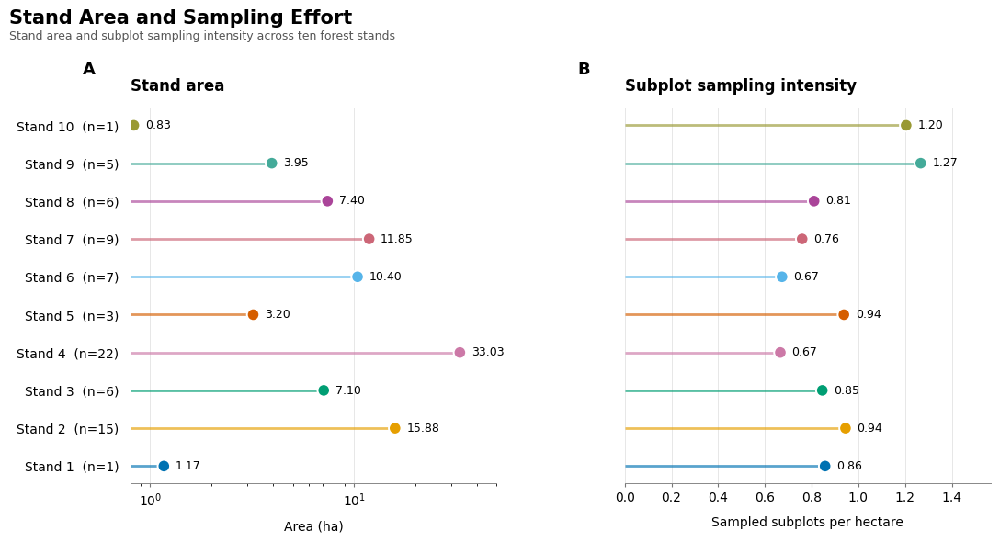

STAND AREA AND SAMPLING EFFORT — ALL TEN STANDS


,Stand ID,Area_hectares,Sampled Subplots,Subplots per hectare
0,1,1.166,1,0.857
1,2,15.875,15,0.945
2,3,7.096,6,0.846
3,4,33.035,22,0.666
4,5,3.198,3,0.938
5,6,10.399,7,0.673
6,7,11.853,9,0.759
7,8,7.404,6,0.810
8,9,3.947,5,1.267
9,10,0.830,1,1.204


In [47]:

# ============================================================
# STEP 42
# ============================================================
#
# Goal:
# Visualize stand area and subplot sampling intensity for all
# ten stands included in the primary analysis.
#
# Panel A: Stand area in hectares.
# Panel B: Number of sampled subplots per hectare.
#
# The same colors used in the woody richness figure identify
# each stand.

# ------------------------------------------------------------
# 1. DEFINE STANDS AND COLOR PALETTE
# ------------------------------------------------------------

stand_order = list(range(1, 11))

# Shared ten-stand color palette.
# Defined locally to prevent stand_colors NameErrors.

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

# ------------------------------------------------------------
# 2. PREPARE STAND AREA DATA
# ------------------------------------------------------------

effort_plot = (
    stand_areas[
        stand_areas['Stand ID'].isin(stand_order)
    ][['Stand ID', 'Area_hectares']]
    .copy()
)

# Standardize stand identifiers.
effort_plot['Stand ID'] = pd.to_numeric(
    effort_plot['Stand ID'],
    errors='coerce'
)

effort_plot = effort_plot.dropna(subset=['Stand ID'])
effort_plot['Stand ID'] = effort_plot['Stand ID'].astype(int)

# Verify that all ten stands have area records.
missing_area_stands = (
    set(stand_order) - set(effort_plot['Stand ID'])
)

if missing_area_stands:
    raise ValueError(
        f"Missing stand area records for: "
        f"{sorted(missing_area_stands)}"
    )

# Check for duplicate stand area records.
if effort_plot['Stand ID'].duplicated().any():
    raise ValueError(
        "Duplicate stand area records detected. "
        "Each stand must have one area value."
    )

# Ensure stand areas are numeric and positive.
effort_plot['Area_hectares'] = pd.to_numeric(
    effort_plot['Area_hectares'],
    errors='coerce'
)

if (
    effort_plot['Area_hectares'].isna().any()
    or (effort_plot['Area_hectares'] <= 0).any()
):
    raise ValueError(
        "Stand areas must be numeric and greater than zero."
    )

# ------------------------------------------------------------
# 3. COUNT UNIQUE SAMPLED SUBPLOTS
# ------------------------------------------------------------

# Standardize stand identifiers in subplot metadata.
subplot_source = subplot_metadata_analysis.copy()

subplot_source['Stand ID'] = pd.to_numeric(
    subplot_source['Stand ID'],
    errors='coerce'
)

# Restrict the dataset to the ten primary analysis stands.
subplot_source = subplot_source[
    subplot_source['Stand ID'].isin(stand_order)
].copy()

# Count unique Stand ID + Plot ID + Subplot ID combinations.
# This prevents repeated subplot numbers across different plots
# from being counted as the same sampling location.

subplot_counts = (
    subplot_source[
        ['Stand ID', 'Plot ID', 'Subplot ID']
    ]
    .dropna(subset=['Stand ID', 'Plot ID', 'Subplot ID'])
    .drop_duplicates()
    .groupby('Stand ID')
    .size()
    .reindex(stand_order, fill_value=0)
    .reset_index(name='Sampled Subplots')
)

subplot_counts['Stand ID'] = (
    subplot_counts['Stand ID'].astype(int)
)

# ------------------------------------------------------------
# 4. COMBINE AREA AND SAMPLING INFORMATION
# ------------------------------------------------------------

effort_plot = effort_plot.merge(
    subplot_counts,
    on='Stand ID',
    how='left',
    validate='one_to_one'
)

# Replace missing counts with zero.
effort_plot['Sampled Subplots'] = (
    effort_plot['Sampled Subplots']
    .fillna(0)
    .astype(int)
)

# Arrange all ten stands in numerical order.
effort_plot = (
    effort_plot
    .set_index('Stand ID')
    .reindex(stand_order)
    .rename_axis('Stand ID')
    .reset_index()
)

# ------------------------------------------------------------
# 5. CALCULATE SUBPLOT SAMPLING INTENSITY
# ------------------------------------------------------------

effort_plot['Subplots per hectare'] = (
    effort_plot['Sampled Subplots'] /
    effort_plot['Area_hectares']
)

# ------------------------------------------------------------
# 6. CREATE THE TWO-PANEL FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 6),
    sharey=True
)

y_positions = np.arange(len(effort_plot))

# Define measurements and panel formatting.
effort_panels = [
    {
        'column': 'Area_hectares',
        'title': 'Stand area',
        'xlabel': 'Area (ha)',
        'panel': 'A'
    },
    {
        'column': 'Subplots per hectare',
        'title': 'Subplot sampling intensity',
        'xlabel': 'Sampled subplots per hectare',
        'panel': 'B'
    }
]

# ------------------------------------------------------------
# 7. APPLY PUBLICATION-STYLE FORMATTING
# ------------------------------------------------------------

with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    for ax, panel in zip(axes, effort_panels):

        column = panel['column']

        values = effort_plot[column].to_numpy()

        # Draw horizontal stems for each stand.
        for y, value, stand in zip(
            y_positions,
            values,
            effort_plot['Stand ID']
        ):

            # The area panel uses a logarithmic axis.
            # Start stems at the lower displayed axis limit.
            stem_start = (
                0.8 if column == 'Area_hectares' else 0
            )

            ax.hlines(
                y=y,
                xmin=stem_start,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # Add circular markers.
        ax.scatter(
            values,
            y_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in effort_plot['Stand ID']
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # Label each observation.
        for y, value in zip(y_positions, values):

            ax.annotate(
                f'{value:.2f}',
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # Include actual subplot sample sizes.
        stand_labels = [
            f"Stand {int(row['Stand ID'])}  "
            f"(n={int(row['Sampled Subplots'])})"
            for _, row in effort_plot.iterrows()
        ]

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Place Stand 1 at the top.
        ax.invert_yaxis()

        # Panel title and axis label.
        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=14
        )

        ax.set_xlabel(
            panel['xlabel'],
            labelpad=9
        )

        # Logarithmic scale for stand area.
        if column == 'Area_hectares':

            ax.set_xscale('log')
            ax.set_xlim(0.8, 50)

        # Linear scale for subplot sampling intensity.
        else:

            max_value = effort_plot[column].max()

            ax.set_xlim(
                0,
                max_value + max(0.3, max_value * 0.10)
            )

        # Add subtle gridlines.
        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        ax.set_axisbelow(True)

        # Remove unnecessary borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # Refine remaining axis line.
        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)

        ax.tick_params(
            axis='y',
            length=0,
            pad=9
        )

        ax.tick_params(
            axis='x',
            length=3,
            color='#777777'
        )

        # Add panel identifiers.
        ax.text(
            -0.13,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

    # --------------------------------------------------------
    # 8. OVERALL TITLE AND SUBTITLE
    # --------------------------------------------------------

    fig.suptitle(
        'Stand Area and Sampling Effort',
        fontsize=15,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=1.02
    )

    fig.text(
        0.08,
        0.965,
        'Stand area and subplot sampling intensity across ten forest stands',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # --------------------------------------------------------
    # 9. FIGURE LAYOUT
    # --------------------------------------------------------

    fig.subplots_adjust(
        left=0.19,
        right=0.97,
        bottom=0.16,
        top=0.84,
        wspace=0.35
    )

    # --------------------------------------------------------
    # 10. EXPORT FIGURES
    # --------------------------------------------------------

    fig.savefig(
        export_dir / 'Stand_Area_Sampling_Effort.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    fig.savefig(
        export_dir / 'Stand_Area_Sampling_Effort.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the figure.
    plt.show()

# ------------------------------------------------------------
# 11. DISPLAY UNDERLYING DATA FOR VERIFICATION
# ------------------------------------------------------------

print(
    'STAND AREA AND SAMPLING EFFORT — ALL TEN STANDS'
)

display(
    effort_plot.round(3)
)



In [48]:
# ============================================================
# STEP 43
# ============================================================
#
# Goal:
# Calculate herbaceous species richness at two spatial scales:
# (1) Total observed richness across each stand.
# (2) Mean richness within individual subplots.
#
# We use herbaceous_analysis, which contains only Stands 1–10.

# Group herbaceous observations by stand, plot, and subplot.
# Count the number of unique herbaceous species in each subplot.
herbaceous_subplot_richness = (
    herbaceous_analysis
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])['Species Name']
    .nunique()
    .reset_index(name='Herbaceous Species Richness')
)

# Summarize subplot richness within each stand.
# Each row in this summary represents one stand.
herbaceous_richness_summary = (
    herbaceous_subplot_richness
    .groupby('Stand ID')['Herbaceous Species Richness']
    .agg(
        Mean='mean',
        Median='median',
        Minimum='min',
        Maximum='max',
        Subplots='count'
    )
    .reset_index()
)

# Calculate total unique herbaceous species observed in each stand.
# Repeated observations of the same species are counted only once.
herbaceous_total_richness = (
    herbaceous_analysis
    .groupby('Stand ID')['Species Name']
    .nunique()
    .reset_index(name='Total Stand Herbaceous Richness')
)

# Combine cumulative richness and subplot-level richness.
# Stand ID connects the two summaries.
herbaceous_richness_comparison = (
    herbaceous_total_richness
    .merge(
        herbaceous_richness_summary,
        on='Stand ID',
        how='left'
    )
)

# Display the combined results, rounded to two decimal places.
display(herbaceous_richness_comparison.round(2))

,Stand ID,Total Stand Herbaceous Richness,Mean,Median,Minimum,Maximum,Subplots
0,1,4,4.00,4.0,4,4,1
1,2,21,3.93,3.5,2,7,14
2,3,7,2.67,3.0,2,3,6
3,4,27,3.85,3.0,1,10,20
4,5,7,6.00,6.0,6,6,2
5,6,7,3.17,3.0,2,4,6
6,7,32,7.67,6.0,4,14,9
7,8,14,4.00,4.0,2,5,6
8,9,6,2.00,2.0,1,3,4
9,10,3,3.00,3.0,3,3,1


In [49]:
# ============================================================
# STEP 44
# ============================================================
#
# Goal:
# Calculate regeneration richness at two spatial scales:
# (1) Total unique regeneration species observed across each stand.
# (2) Mean unique regeneration species observed per subplot.
#
# Microplots are nested within subplots, so we combine their
# species observations at the subplot level.

# Group regeneration observations by stand, plot, and subplot.
# Count each species only once within each subplot, even if it
# occurs in multiple microplots.
regeneration_subplot_richness = (
    regeneration_analysis
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])['Species Name']
    .nunique()
    .reset_index(name='Regeneration Species Richness')
)

# Calculate descriptive statistics for subplot richness within each stand.
regeneration_richness_summary = (
    regeneration_subplot_richness
    .groupby('Stand ID')['Regeneration Species Richness']
    .agg(
        Mean='mean',
        Median='median',
        Minimum='min',
        Maximum='max',
        Subplots='count'
    )
    .reset_index()
)

# Calculate total unique regeneration species observed across each stand.
regeneration_total_richness = (
    regeneration_analysis
    .groupby('Stand ID')['Species Name']
    .nunique()
    .reset_index(name='Total Stand Regeneration Richness')
)

# Combine cumulative richness with subplot-level richness statistics.
regeneration_richness_comparison = (
    regeneration_total_richness
    .merge(
        regeneration_richness_summary,
        on='Stand ID',
        how='left'
    )
)

# Display the results.
display(regeneration_richness_comparison.round(2))

,Stand ID,Total Stand Regeneration Richness,Mean,Median,Minimum,Maximum,Subplots
0,1,3,3.00,3.0,3,3,1
1,2,11,2.36,2.0,1,4,14
2,3,4,1.83,2.0,1,3,6
3,4,10,2.41,2.0,1,5,22
4,5,4,2.33,2.0,1,4,3
5,6,7,2.50,2.5,1,5,6
6,7,10,2.67,2.0,2,4,9
7,8,7,2.20,2.0,2,3,5
8,9,5,2.00,2.0,1,3,5


Stands without regeneration observations: [10]


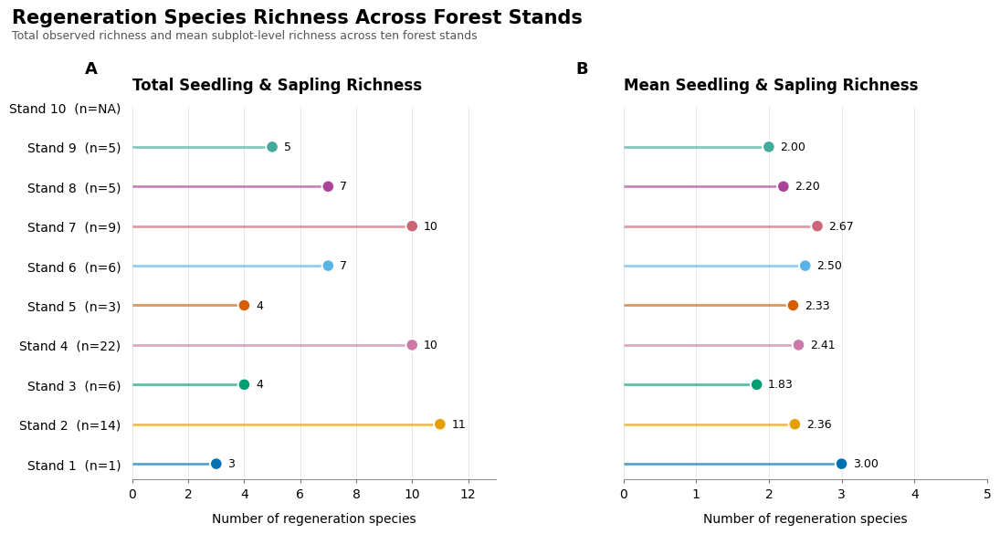

REGENERATION SPECIES RICHNESS — ALL TEN STANDS


,Stand ID,Total Stand Regeneration Richness,Mean,Median,Minimum,Maximum,Subplots
0,1,3.0,3.000,3.0,3.0,3.0,1.0
1,2,11.0,2.357,2.0,1.0,4.0,14.0
2,3,4.0,1.833,2.0,1.0,3.0,6.0
3,4,10.0,2.409,2.0,1.0,5.0,22.0
4,5,4.0,2.333,2.0,1.0,4.0,3.0
5,6,7.0,2.500,2.5,1.0,5.0,6.0
6,7,10.0,2.667,2.0,2.0,4.0,9.0
7,8,7.0,2.200,2.0,2.0,3.0,5.0
8,9,5.0,2.000,2.0,1.0,3.0,5.0
9,10,NaN,NaN,NaN,NaN,NaN,NaN


Stands without regeneration observations: [10]


In [52]:

# ============================================================
# STEP 45 — REGENERATION SPECIES RICHNESS (10 STANDS)
# ============================================================
#
# Panel A: Total observed regeneration species richness.
# Panel B: Mean regeneration species richness per subplot.
#
# Uses the actual column names generated in STEP 44.
# Retains all ten stands, including stands without observations.
# Missing observations are displayed as missing, NOT zero.

# ------------------------------------------------------------
# 1. DEFINE STANDS AND COLOR PALETTE
# ------------------------------------------------------------

stand_order = list(range(1, 11))

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

# ------------------------------------------------------------
# 2. PREPARE REGENERATION RICHNESS DATA
# ------------------------------------------------------------

# Use the actual summary generated in STEP 44.
regeneration_source = regeneration_richness_comparison.copy()

# Standardize stand identifiers.
regeneration_source['Stand ID'] = pd.to_numeric(
    regeneration_source['Stand ID'],
    errors='coerce'
)

regeneration_source = regeneration_source.dropna(
    subset=['Stand ID']
)

regeneration_source['Stand ID'] = (
    regeneration_source['Stand ID'].astype(int)
)

# Verify required columns from STEP 44.
required_columns = [
    'Stand ID',
    'Total Stand Regeneration Richness',
    'Mean',
    'Subplots'
]

missing_columns = [
    col for col in required_columns
    if col not in regeneration_source.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns in regeneration_richness_comparison: "
        f"{missing_columns}. "
        f"Available columns: {regeneration_source.columns.tolist()}"
    )

# Restrict to the ten primary analysis stands.
regeneration_source = regeneration_source[
    regeneration_source['Stand ID'].isin(stand_order)
].copy()

# Ensure richness measurements are numeric.
for col in [
    'Total Stand Regeneration Richness',
    'Mean',
    'Subplots'
]:
    regeneration_source[col] = pd.to_numeric(
        regeneration_source[col],
        errors='coerce'
    )

# Check for duplicate stand records.
if regeneration_source['Stand ID'].duplicated().any():
    raise ValueError(
        "Duplicate stand records detected in "
        "regeneration_richness_comparison."
    )

# ------------------------------------------------------------
# 3. RETAIN ALL TEN STANDS
# ------------------------------------------------------------

# Reindex to include all ten stands.
# Missing observations remain NaN rather than becoming zero.

regeneration_plot_data = (
    regeneration_source
    .set_index('Stand ID')
    .reindex(stand_order)
    .rename_axis('Stand ID')
    .reset_index()
)

# Identify stands without regeneration records.
missing_regeneration_stands = (
    regeneration_plot_data.loc[
        regeneration_plot_data[
            'Total Stand Regeneration Richness'
        ].isna(),
        'Stand ID'
    ].tolist()
)

if missing_regeneration_stands:
    print(
        "Stands without regeneration observations:",
        missing_regeneration_stands
    )

# ------------------------------------------------------------
# 4. CREATE THE TWO-PANEL FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 6),
    sharey=True
)

y_positions = np.arange(len(regeneration_plot_data))

# Define the two richness measurements.
regeneration_panels = [
    {
        'column': 'Total Stand Regeneration Richness',
        'title': 'Total Seedling & Sapling Richness',
        'panel': 'A'
    },
    {
        'column': 'Mean',
        'title': 'Mean Seedling & Sapling Richness',
        'panel': 'B'
    }
]

# ------------------------------------------------------------
# 5. APPLY PUBLICATION-STYLE FORMATTING
# ------------------------------------------------------------

with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    # Construct each panel.
    for ax, panel in zip(axes, regeneration_panels):

        column = panel['column']

        values = regeneration_plot_data[column].to_numpy(
            dtype=float
        )

        # Identify stands with actual observations.
        valid = np.isfinite(values)

        valid_positions = y_positions[valid]

        valid_values = values[valid]

        valid_stands = (
            regeneration_plot_data.loc[valid, 'Stand ID']
            .astype(int)
        )

        # ----------------------------------------------------
        # DRAW HORIZONTAL STEMS
        # ----------------------------------------------------

        for y, value, stand in zip(
            valid_positions,
            valid_values,
            valid_stands
        ):

            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

        # ----------------------------------------------------
        # ADD CIRCULAR MARKERS
        # ----------------------------------------------------

        ax.scatter(
            valid_values,
            valid_positions,
            s=95,
            c=[
                stand_colors[stand]
                for stand in valid_stands
            ],
            edgecolors='white',
            linewidths=1.4,
            zorder=3
        )

        # ----------------------------------------------------
        # ADD NUMERICAL LABELS
        # ----------------------------------------------------

        for y, value in zip(
            valid_positions,
            valid_values
        ):

            if column == 'Total Stand Regeneration Richness':
                label = f'{value:.0f}'
            else:
                label = f'{value:.2f}'

            ax.annotate(
                label,
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # ----------------------------------------------------
        # STAND LABELS AND SUBPLOT SAMPLE SIZES
        # ----------------------------------------------------

        stand_labels = []

        for _, row in regeneration_plot_data.iterrows():

            stand = int(row['Stand ID'])

            if pd.isna(row['Subplots']):
                n_label = 'n=NA'
            else:
                n_label = f"n={int(row['Subplots'])}"

            stand_labels.append(
                f"Stand {stand}  ({n_label})"
            )

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Place Stand 1 at the top.
        ax.invert_yaxis()

        # ----------------------------------------------------
        # PANEL TITLES AND AXIS LABELS
        # ----------------------------------------------------

        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=14
        )

        ax.set_xlabel(
            'Number of regeneration species',
            labelpad=9
        )

        # Set horizontal axis limits using available observations.
        if len(valid_values) > 0:

            max_value = valid_values.max()

            ax.set_xlim(
                0,
                max_value + max(2, max_value * 0.12)
            )

        else:
            ax.set_xlim(0, 1)

        # ----------------------------------------------------
        # GRIDLINES AND AXIS FORMATTING
        # ----------------------------------------------------

        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        ax.set_axisbelow(True)

        # Remove unnecessary borders.
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)

        ax.tick_params(
            axis='y',
            length=0,
            pad=9
        )

        ax.tick_params(
            axis='x',
            length=3,
            color='#777777'
        )

        # Panel identifiers.
        ax.text(
            -0.13,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )

    # --------------------------------------------------------
    # 6. OVERALL FIGURE TITLE
    # --------------------------------------------------------

    fig.suptitle(
        'Regeneration Species Richness Across Forest Stands',
        fontsize=15,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=1.02
    )

    fig.text(
        0.08,
        0.965,
        'Total observed richness and mean subplot-level richness '
        'across ten forest stands',
        fontsize=9,
        color='#555555',
        ha='left'
    )

    # --------------------------------------------------------
    # 7. FIGURE LAYOUT
    # --------------------------------------------------------

    fig.subplots_adjust(
        left=0.19,
        right=0.97,
        bottom=0.16,
        top=0.84,
        wspace=0.35
    )

    # --------------------------------------------------------
    # 8. EXPORT FIGURES
    # --------------------------------------------------------

    fig.savefig(
        export_dir / 'Regeneration_Richness_Publication.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    fig.savefig(
        export_dir / 'Regeneration_Richness_Publication.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    # Display the finished figure.
    plt.show()

# ------------------------------------------------------------
# 9. DISPLAY UNDERLYING DATA FOR VERIFICATION
# ------------------------------------------------------------

print(
    'REGENERATION SPECIES RICHNESS — ALL TEN STANDS'
)

display(
    regeneration_plot_data.round(3)
)

print(
    'Stands without regeneration observations:',
    missing_regeneration_stands
)


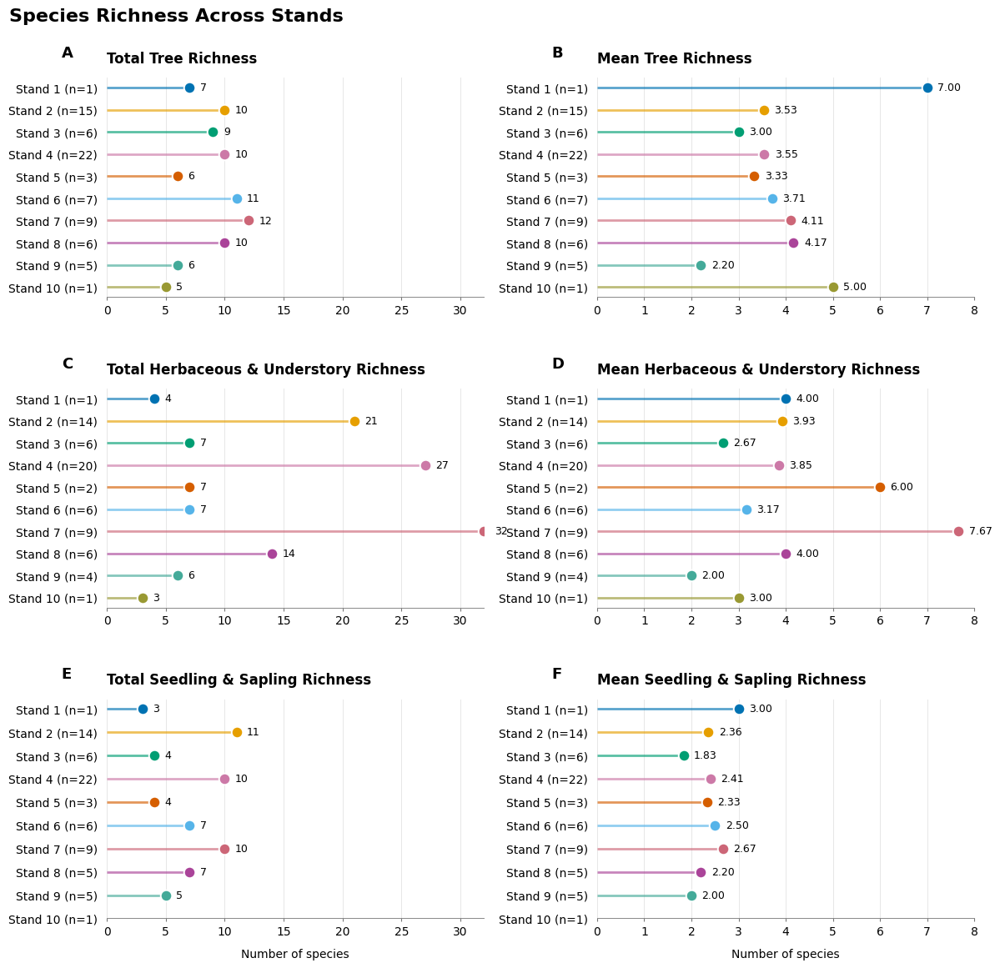

,Stand ID,Total Stand Tree Richness,Tree Subplots,Total Stand Herbaceous Richness,Herbaceous Subplots,Total Stand Regeneration Richness,Regeneration Subplots
0,1,7,1,4,1,3.0,1.0
1,2,10,15,21,14,11.0,14.0
2,3,9,6,7,6,4.0,6.0
3,4,10,22,27,20,10.0,22.0
4,5,6,3,7,2,4.0,3.0
5,6,11,7,7,6,7.0,6.0
6,7,12,9,32,9,10.0,9.0
7,8,10,6,14,6,7.0,5.0
8,9,6,5,6,4,5.0,5.0
9,10,5,1,3,1,NaN,1.0


In [56]:

# ============================================================
# STEP 46
# ============================================================
#
# Goal:
# Compare tree, herbaceous, and regeneration species richness
# across all ten forest stands.
#
# LEFT COLUMN: Total cumulative species richness.
# RIGHT COLUMN: Mean species richness per subplot.
#
# Rows:
# A-B: Tree vegetation.
# C-D: Herbaceous vegetation.
# E-F: Regeneration.
#
# Stand 10 is represented by n=1 in all three layers.
# No figure subtitle is included.

# ------------------------------------------------------------
# 1. DEFINE STAND ORDER AND COLORS
# ------------------------------------------------------------

stand_order = list(range(1, 11))

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

# ------------------------------------------------------------
# 2. PREPARE THE THREE RICHNESS DATAFRAMES
# ------------------------------------------------------------

def prepare_richness_data(df, required_columns, layer_name):

    data = df[required_columns].copy()

    data['Stand ID'] = pd.to_numeric(
        data['Stand ID'],
        errors='coerce'
    )

    data = data.dropna(subset=['Stand ID'])

    data['Stand ID'] = data['Stand ID'].astype(int)

    data = data[data['Stand ID'].isin(stand_order)]

    if data['Stand ID'].duplicated().any():
        raise ValueError(
            f'Duplicate Stand IDs found in {layer_name} richness data.'
        )

    return data


# Tree / woody richness
tree_data = prepare_richness_data(
    woody_richness_comparison,
    [
        'Stand ID',
        'Total Stand Woody Richness',
        'Mean',
        'Subplots'
    ],
    'Tree'
).rename(columns={
    'Total Stand Woody Richness': 'Total Stand Tree Richness',
    'Mean': 'Mean Tree Richness',
    'Subplots': 'Tree Subplots'
})


# Herbaceous richness
herbaceous_data = prepare_richness_data(
    herbaceous_richness_comparison,
    [
        'Stand ID',
        'Total Stand Herbaceous Richness',
        'Mean',
        'Subplots'
    ],
    'Herbaceous'
).rename(columns={
    'Mean': 'Mean Herbaceous Richness',
    'Subplots': 'Herbaceous Subplots'
})


# Regeneration richness
regeneration_data = prepare_richness_data(
    regeneration_richness_comparison,
    [
        'Stand ID',
        'Total Stand Regeneration Richness',
        'Mean',
        'Subplots'
    ],
    'Regeneration'
).rename(columns={
    'Mean': 'Mean Regeneration Richness',
    'Subplots': 'Regeneration Subplots'
})


# ------------------------------------------------------------
# 3. COMBINE THE THREE DATASETS
# ------------------------------------------------------------

vegetation_richness_comparison = (
    tree_data
    .merge(
        herbaceous_data,
        on='Stand ID',
        how='outer'
    )
    .merge(
        regeneration_data,
        on='Stand ID',
        how='outer'
    )
)

# Retain all ten stands, even if a layer has missing data.
vegetation_richness_comparison = (
    vegetation_richness_comparison
    .set_index('Stand ID')
    .reindex(stand_order)
    .rename_axis('Stand ID')
    .reset_index()
)

# ------------------------------------------------------------
# 4. SET STAND 10 SAMPLE COUNTS
# ------------------------------------------------------------

# Stand 10 has one contributing subplot in each vegetation layer.
stand_10_mask = (
    vegetation_richness_comparison['Stand ID'] == 10
)

for count_column in [
    'Tree Subplots',
    'Herbaceous Subplots',
    'Regeneration Subplots'
]:
    vegetation_richness_comparison.loc[
        stand_10_mask,
        count_column
    ] = 1


# ------------------------------------------------------------
# 5. CONVERT NUMERIC COLUMNS
# ------------------------------------------------------------

numeric_columns = [
    'Total Stand Tree Richness',
    'Mean Tree Richness',
    'Tree Subplots',
    'Total Stand Herbaceous Richness',
    'Mean Herbaceous Richness',
    'Herbaceous Subplots',
    'Total Stand Regeneration Richness',
    'Mean Regeneration Richness',
    'Regeneration Subplots'
]

for column in numeric_columns:
    vegetation_richness_comparison[column] = pd.to_numeric(
        vegetation_richness_comparison[column],
        errors='coerce'
    )


# ------------------------------------------------------------
# 6. DEFINE THE SIX FIGURE PANELS
# ------------------------------------------------------------

vegetation_panels = [
    {
        'column': 'Total Stand Tree Richness',
        'count_column': 'Tree Subplots',
        'title': 'Total Tree Richness',
        'panel': 'A',
        'row': 0,
        'col': 0,
        'total': True
    },
    {
        'column': 'Mean Tree Richness',
        'count_column': 'Tree Subplots',
        'title': 'Mean Tree Richness',
        'panel': 'B',
        'row': 0,
        'col': 1,
        'total': False
    },
    {
        'column': 'Total Stand Herbaceous Richness',
        'count_column': 'Herbaceous Subplots',
        'title': 'Total Herbaceous & Understory Richness',
        'panel': 'C',
        'row': 1,
        'col': 0,
        'total': True
    },
    {
        'column': 'Mean Herbaceous Richness',
        'count_column': 'Herbaceous Subplots',
        'title': 'Mean Herbaceous & Understory Richness',
        'panel': 'D',
        'row': 1,
        'col': 1,
        'total': False
    },
    {
        'column': 'Total Stand Regeneration Richness',
        'count_column': 'Regeneration Subplots',
        'title': 'Total Seedling & Sapling Richness',
        'panel': 'E',
        'row': 2,
        'col': 0,
        'total': True
    },
    {
        'column': 'Mean Regeneration Richness',
        'count_column': 'Regeneration Subplots',
        'title': 'Mean Seedling & Sapling Richness',
        'panel': 'F',
        'row': 2,
        'col': 1,
        'total': False
    }
]


# ------------------------------------------------------------
# 7. CREATE THE FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(13, 12)
)

y_positions = np.arange(len(stand_order))

with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
}):

    for panel in vegetation_panels:

        ax = axes[panel['row'], panel['col']]

        values = vegetation_richness_comparison[
            panel['column']
        ].to_numpy(dtype=float)

        sample_counts = vegetation_richness_comparison[
            panel['count_column']
        ].to_numpy(dtype=float)

        stands = vegetation_richness_comparison[
            'Stand ID'
        ].to_numpy(dtype=int)

        # ----------------------------------------------------
        # DRAW OBSERVATIONS
        # ----------------------------------------------------

        for y, value, stand in zip(
            y_positions,
            values,
            stands
        ):

            # Do not plot missing richness values.
            if not np.isfinite(value):
                continue

            ax.hlines(
                y=y,
                xmin=0,
                xmax=value,
                color=stand_colors[stand],
                linewidth=2,
                alpha=0.65,
                zorder=1
            )

            ax.scatter(
                value,
                y,
                s=95,
                color=stand_colors[stand],
                edgecolors='white',
                linewidths=1.4,
                zorder=3
            )

            # Richness value labels.
            if panel['total']:
                label = f'{value:.0f}'
            else:
                label = f'{value:.2f}'

            ax.annotate(
                label,
                xy=(value, y),
                xytext=(9, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9
            )

        # ----------------------------------------------------
        # STAND LABELS AND SAMPLE COUNTS
        # ----------------------------------------------------

        stand_labels = []

        for stand, count in zip(
            stands,
            sample_counts
        ):

            if np.isfinite(count):
                count_label = f'n={int(count)}'
            else:
                count_label = 'n=NA'

            stand_labels.append(
                f'Stand {stand} ({count_label})'
            )

        ax.set_yticks(y_positions)
        ax.set_yticklabels(stand_labels)

        # Stand 1 appears at the top.
        ax.invert_yaxis()

        # ----------------------------------------------------
        # PANEL FORMATTING
        # ----------------------------------------------------

        ax.set_title(
            panel['title'],
            loc='left',
            fontweight='semibold',
            pad=13
        )

        if panel['col'] == 0:
            ax.set_xlim(0, 32)
            ax.set_xticks(np.arange(0, 33, 5))
        else:
            ax.set_xlim(0, 8)
            ax.set_xticks(np.arange(0, 9, 1))

        ax.grid(
            axis='x',
            color='#D9D9D9',
            linewidth=0.7,
            alpha=0.65
        )

        ax.set_axisbelow(True)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

        ax.spines['bottom'].set_color('#888888')
        ax.spines['bottom'].set_linewidth(0.7)

        ax.tick_params(axis='y', length=0, pad=8)
        ax.tick_params(axis='x', length=3, color='#777777')

        # Panel identifier.
        ax.text(
            -0.12,
            1.08,
            panel['panel'],
            transform=ax.transAxes,
            fontsize=13,
            fontweight='bold',
            va='bottom'
        )


    # --------------------------------------------------------
    # 8. AXIS LABELS AND FIGURE TITLE
    # --------------------------------------------------------

    axes[2, 0].set_xlabel(
        'Number of species',
        labelpad=9
    )

    axes[2, 1].set_xlabel(
        'Number of species',
        labelpad=9
    )

    # Main title only — no subtitle.
    fig.suptitle(
        'Species Richness Across Stands',
        fontsize=16,
        fontweight='bold',
        x=0.08,
        ha='left',
        y=0.99
    )

    fig.subplots_adjust(
        left=0.17,
        right=0.97,
        bottom=0.08,
        top=0.92,
        hspace=0.42,
        wspace=0.30
    )


    # --------------------------------------------------------
    # 9. EXPORT FIGURE
    # --------------------------------------------------------

    fig.savefig(
        export_dir / 'Three_Layer_Vegetation_Richness.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

    fig.savefig(
        export_dir / 'Three_Layer_Vegetation_Richness.pdf',
        bbox_inches='tight',
        facecolor='white'
    )

    plt.show()


# ------------------------------------------------------------
# 10. DISPLAY THE COMBINED DATA FOR VERIFICATION
# ------------------------------------------------------------

display(
    vegetation_richness_comparison[
        [
            'Stand ID',
            'Total Stand Tree Richness',
            'Tree Subplots',
            'Total Stand Herbaceous Richness',
            'Herbaceous Subplots',
            'Total Stand Regeneration Richness',
            'Regeneration Subplots'
        ]
    ]
)


In [61]:

# ============================================================
# STEP 47
# ============================================================

# Ensure all ten stands are represented in every matrix.
stand_order = list(range(1, 11))

# ------------------------------------------------------------
# 1. TREE SPECIES PRESENCE/ABSENCE
# ------------------------------------------------------------

tree_composition_data = woody_analysis[
    woody_analysis['Species Name'] != 'Unknown Hardwood'
].copy()

tree_presence_matrix = pd.crosstab(
    tree_composition_data['Species Name'],
    tree_composition_data['Stand ID']
)

tree_presence_matrix = (
    (tree_presence_matrix > 0)
    .astype(int)
    .reindex(columns=stand_order, fill_value=0)
)

# ------------------------------------------------------------
# 2. HERBACEOUS SPECIES PRESENCE/ABSENCE
# ------------------------------------------------------------

herbaceous_presence_matrix = pd.crosstab(
    herbaceous_analysis['Species Name'],
    herbaceous_analysis['Stand ID']
)

herbaceous_presence_matrix = (
    (herbaceous_presence_matrix > 0)
    .astype(int)
    .reindex(columns=stand_order, fill_value=0)
)

# ------------------------------------------------------------
# 3. REGENERATION SPECIES PRESENCE/ABSENCE
# ------------------------------------------------------------

regeneration_presence_matrix = pd.crosstab(
    regeneration_analysis['Species Name'],
    regeneration_analysis['Stand ID']
)

regeneration_presence_matrix = (
    (regeneration_presence_matrix > 0)
    .astype(int)
    .reindex(columns=stand_order, fill_value=0)
)

# ------------------------------------------------------------
# 4. VERIFY ALL TEN STAND COLUMNS
# ------------------------------------------------------------

for name, matrix in {
    'Tree': tree_presence_matrix,
    'Herbaceous': herbaceous_presence_matrix,
    'Regeneration': regeneration_presence_matrix
}.items():

    print(f'\n{name} presence/absence matrix')
    print('Stand columns:', matrix.columns.tolist())
    print('Number of species:', len(matrix))

    assert matrix.columns.tolist() == stand_order, (
        f'{name} matrix is missing one or more stand columns.'
    )

    display(matrix)



Tree presence/absence matrix
Stand columns: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Number of species: 16


Stand ID,1,2,3,4,5,6,7,8,9,10
Species Name,,,,,,,,,,
American Beech,1,1,1,1,1,1,1,1,1,1
American Hop Hornbeam,0,0,0,0,0,0,0,1,0,0
American Hophornbeam,0,0,0,0,0,1,1,1,0,0
Balsam Fir,0,0,0,0,0,0,1,0,0,0
Eastern Hemlock,1,1,1,1,1,1,1,1,1,0
Eastern White Pine,0,1,0,1,1,1,1,0,0,0
Gray Birch,0,0,0,1,0,0,1,0,0,0
Northern Red Oak,0,1,1,1,1,1,1,1,1,1
Red Maple,1,1,1,1,0,1,1,1,1,0



Herbaceous presence/absence matrix
Stand columns: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Number of species: 75


Stand ID,1,2,3,4,5,6,7,8,9,10
Species Name,,,,,,,,,,
American Royal Fern,0,1,0,0,0,0,0,0,1,0
Beech Drops,0,0,0,1,0,1,1,0,0,0
Bluestem Goldenrod,0,0,0,0,0,0,1,0,0,0
Bracken Fern,0,0,0,0,0,1,0,0,0,0
Bunchberry,0,0,0,1,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
White Turtlehead,0,0,0,0,0,0,1,0,0,0
Whorled Wood Aster,0,0,0,1,0,0,0,0,0,0
Winterberry,0,0,0,1,0,0,0,0,0,0



Regeneration presence/absence matrix
Stand columns: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Number of species: 19


Stand ID,1,2,3,4,5,6,7,8,9,10
Species Name,,,,,,,,,,
American Beech,1,1,1,1,1,1,1,1,1,0
Balsam Fir,0,0,0,0,0,0,1,0,0,0
Bigtooth Aspen,0,1,0,1,0,0,0,0,0,0
Black Birch,0,0,0,0,0,1,0,1,0,0
Eastern Hemlock,1,1,1,1,1,1,1,1,1,0
Eastern White Pine,0,1,0,1,1,1,1,0,1,0
Hop Hornbeam,0,0,0,0,0,0,1,0,0,0
Northern Red Oak,0,1,0,0,0,1,1,1,1,0
Red Maple,0,1,0,1,0,0,1,0,0,0


In [62]:
# ============================================================
# STEP 48
# ============================================================
#
# Goal:
# Determine how many of the ten stands contain each species.
#
# A species recorded in all ten stands has an occurrence value of 6.
# A species recorded in only one stand has an occurrence value of 1.
#
# We calculate occurrence separately for tree, herbaceous,
# and regeneration vegetation.

# ---------------------------------------------------------
# 1. TREE SPECIES OCCURRENCE
# ---------------------------------------------------------

# Sum the presence/absence values across all ten stands.
# Each value represents the number of stands containing that species.
tree_occurrence = (
    tree_presence_matrix
    .sum(axis=1)
    .reset_index(name='Number of Stands')
)

# Calculate the percentage of stands containing each tree species.
tree_occurrence['Occurrence (%)'] = (
    tree_occurrence['Number of Stands'] / len(stand_order) * 100
)

# Sort species from most widespread to least widespread.
tree_occurrence = tree_occurrence.sort_values(
    'Number of Stands',
    ascending=False
)

# ---------------------------------------------------------
# 2. HERBACEOUS SPECIES OCCURRENCE
# ---------------------------------------------------------

# Count the number of stands containing each herbaceous species.
herbaceous_occurrence = (
    herbaceous_presence_matrix
    .sum(axis=1)
    .reset_index(name='Number of Stands')
)

# Calculate the percentage of stands containing each species.
herbaceous_occurrence['Occurrence (%)'] = (
    herbaceous_occurrence['Number of Stands'] / len(stand_order) * 100
)

# Sort from most widespread to least widespread.
herbaceous_occurrence = herbaceous_occurrence.sort_values(
    'Number of Stands',
    ascending=False
)

# ---------------------------------------------------------
# 3. REGENERATION SPECIES OCCURRENCE
# ---------------------------------------------------------

# Count the number of stands containing each regeneration species.
regeneration_occurrence = (
    regeneration_presence_matrix
    .sum(axis=1)
    .reset_index(name='Number of Stands')
)

# Calculate the percentage of stands containing each species.
regeneration_occurrence['Occurrence (%)'] = (
    regeneration_occurrence['Number of Stands'] / len(stand_order) * 100
)

# Sort from most widespread to least widespread.
regeneration_occurrence = regeneration_occurrence.sort_values(
    'Number of Stands',
    ascending=False
)

# ---------------------------------------------------------
# 4. DISPLAY THE RESULTS
# ---------------------------------------------------------

print("TREE SPECIES OCCURRENCE")
display(tree_occurrence.round(1))

print("HERBACEOUS SPECIES OCCURRENCE")
display(herbaceous_occurrence.round(1))

print("REGENERATION SPECIES OCCURRENCE")
display(regeneration_occurrence.round(1))

TREE SPECIES OCCURRENCE


,Species Name,Number of Stands,Occurrence (%)
0,American Beech,10,100.0
4,Eastern Hemlock,9,90.0
7,Northern Red Oak,9,90.0
14,White Oak,9,90.0
8,Red Maple,8,80.0
12,White Ash,8,80.0
13,White Birch,7,70.0
11,Sugar Maple,6,60.0
15,Yellow Birch,6,60.0
5,Eastern White Pine,5,50.0


HERBACEOUS SPECIES OCCURRENCE


,Species Name,Number of Stands,Occurrence (%)
7,Christmas Fern,9,90.0
32,Intermediate Wood Fern,8,80.0
26,Flat Branched Tree Clubmoss,6,60.0
47,Partridgeberry,6,60.0
14,Creeping Foam Flower,3,30.0
...,...,...,...
68,Wavy Leaf Aster,1,10.0
70,White Turtlehead,1,10.0
71,Whorled Wood Aster,1,10.0
72,Winterberry,1,10.0


REGENERATION SPECIES OCCURRENCE


,Species Name,Number of Stands,Occurrence (%)
0,American Beech,9,90.0
4,Eastern Hemlock,9,90.0
5,Eastern White Pine,6,60.0
18,Yellow Birch,5,50.0
17,Witch-hazel,5,50.0
7,Northern Red Oak,5,50.0
11,Striped Maple,4,40.0
8,Red Maple,3,30.0
2,Bigtooth Aspen,2,20.0
3,Black Birch,2,20.0


In [63]:
# ============================================================
# STEP 49
# ============================================================
#
# Goal:
# Identify species recorded in exactly one of the ten stands.
#
# These are species exclusive to one sampled stand in our dataset.
# This does not establish that they are absent from other stands
# in the broader landscape.

# ---------------------------------------------------------
# 1. CREATE A FUNCTION TO IDENTIFY EXCLUSIVE SPECIES
# ---------------------------------------------------------

# This function accepts a species-by-stand presence/absence matrix.
# It identifies species whose row sum equals exactly one.
def identify_exclusive_species(presence_matrix, vegetation_layer):

    # Count the number of stands in which each species was recorded.
    number_of_stands = presence_matrix.sum(axis=1)

    # Keep only species occurring in exactly one stand.
    exclusive_species = presence_matrix[number_of_stands == 1].copy()

    # Convert the matrix into a table with one row per species.
    exclusive_species = exclusive_species.reset_index()

    # Identify the stand in which each exclusive species was recorded.
    # The stand column containing 1 indicates its observed stand.
    exclusive_species['Exclusive Stand'] = (
        exclusive_species
        .drop(columns='Species Name')
        .idxmax(axis=1)
    )

    # Retain only the species name and its exclusive stand.
    exclusive_species = exclusive_species[
        ['Species Name', 'Exclusive Stand']
    ]

    # Add a column identifying the vegetation layer.
    exclusive_species['Vegetation Layer'] = vegetation_layer

    # Return the completed table.
    return exclusive_species


# ---------------------------------------------------------
# 2. IDENTIFY EXCLUSIVE TREE SPECIES
# ---------------------------------------------------------

tree_exclusive = identify_exclusive_species(
    tree_presence_matrix,
    'Tree'
)

# ---------------------------------------------------------
# 3. IDENTIFY EXCLUSIVE HERBACEOUS SPECIES
# ---------------------------------------------------------

herbaceous_exclusive = identify_exclusive_species(
    herbaceous_presence_matrix,
    'Herbaceous'
)

# ---------------------------------------------------------
# 4. IDENTIFY EXCLUSIVE REGENERATION SPECIES
# ---------------------------------------------------------

regeneration_exclusive = identify_exclusive_species(
    regeneration_presence_matrix,
    'Regeneration'
)

# ---------------------------------------------------------
# 5. COMBINE AND DISPLAY RESULTS
# ---------------------------------------------------------

# Combine all three vegetation layers into one table.
exclusive_species_summary = pd.concat(
    [
        tree_exclusive,
        herbaceous_exclusive,
        regeneration_exclusive
    ],
    ignore_index=True
)

# Sort the table by vegetation layer and stand.
exclusive_species_summary = exclusive_species_summary.sort_values(
    ['Vegetation Layer', 'Exclusive Stand', 'Species Name']
)

# Display all species exclusive to individual sampled stands.
display(exclusive_species_summary)

Stand ID,Species Name,Exclusive Stand,Vegetation Layer
7,Cinnamon Fern,2,Herbaceous
15,Dog Bane,2,Herbaceous
22,Evergreen Club Moss,2,Herbaceous
25,Long Down Wood Grass,2,Herbaceous
26,Long Stalked Sedge,2,Herbaceous
30,Meadow Rue,2,Herbaceous
34,Northern Wild Raisin,2,Herbaceous
38,Rattlesnake Plantain,2,Herbaceous
41,Small Flowered Buttercup,2,Herbaceous
48,White Bear Sedge,2,Herbaceous


In [64]:
# ============================================================
# STEP 50
# ============================================================
#
# Goal:
# Compare species composition between every possible pair of stands.
#
# For each vegetation layer, calculate:
# 1. Number of species shared between two stands.
# 2. Number of species recorded across either stand.
# 3. The names of the shared species.
#
# We will use these results to calculate Jaccard similarity.

# Import combinations so we can generate every unique pair of stands.
from itertools import combinations

# Define the three vegetation layers and their presence/absence matrices.
composition_matrices = {
    'Tree': tree_presence_matrix,
    'Herbaceous': herbaceous_presence_matrix,
    'Regeneration': regeneration_presence_matrix
}

# Create an empty list to store results for every stand pair.
shared_species_results = []

# Loop through each vegetation layer and its corresponding matrix.
for vegetation_layer, presence_matrix in composition_matrices.items():

    # Generate all unique pairs of stands.
    # Ten stands produce 45 unique stand pairs.
    for stand_a, stand_b in combinations(stand_order, 2):

        # Identify species recorded in the first stand.
        species_a = set(
            presence_matrix.index[
                presence_matrix[stand_a] == 1
            ]
        )

        # Identify species recorded in the second stand.
        species_b = set(
            presence_matrix.index[
                presence_matrix[stand_b] == 1
            ]
        )

        # Find species present in both stands.
        shared_species = species_a.intersection(species_b)

        # Find all species recorded in either stand.
        combined_species = species_a.union(species_b)

        # Calculate the number of shared species.
        shared_count = len(shared_species)

        # Calculate the number of species in the combined species pool.
        combined_count = len(combined_species)

        # Calculate Jaccard similarity.
        # This is the proportion of shared species relative to
        # the total number of species observed across the pair.
        jaccard_similarity = (
            shared_count / combined_count
            if combined_count > 0
            else np.nan
        )

        # Store the results for this vegetation layer and stand pair.
        shared_species_results.append({
            'Vegetation Layer': vegetation_layer,
            'Stand A': stand_a,
            'Stand B': stand_b,
            'Shared Species': shared_count,
            'Combined Species': combined_count,
            'Jaccard Similarity': jaccard_similarity,
            'Shared Species Names': ', '.join(sorted(shared_species))
        })

# Convert the results into a DataFrame.
shared_species_summary = pd.DataFrame(shared_species_results)

# Sort the results by vegetation layer and stand pair.
shared_species_summary = shared_species_summary.sort_values(
    ['Vegetation Layer', 'Stand A', 'Stand B']
).reset_index(drop=True)

# Display the results with Jaccard similarity rounded to three decimals.
display(
    shared_species_summary.round({
        'Jaccard Similarity': 3
    })
)

,Vegetation Layer,Stand A,Stand B,Shared Species,Combined Species,Jaccard Similarity,Shared Species Names
0,Herbaceous,1,2,2,23,0.087,"Christmas Fern, Princess Pine"
1,Herbaceous,1,3,2,9,0.222,"Christmas Fern, Interrupted Fern"
2,Herbaceous,1,4,2,29,0.069,"Christmas Fern, Starflower"
3,Herbaceous,1,5,0,11,0.000,
4,Herbaceous,1,6,1,10,0.100,Christmas Fern
...,...,...,...,...,...,...,...
130,Tree,7,9,6,12,0.500,"American Beech, Eastern Hemlock, Northern Red ..."
131,Tree,7,10,5,12,0.417,"American Beech, Northern Red Oak, White Ash, W..."
132,Tree,8,9,6,10,0.600,"American Beech, Eastern Hemlock, Northern Red ..."
133,Tree,8,10,4,11,0.364,"American Beech, Northern Red Oak, White Ash, W..."


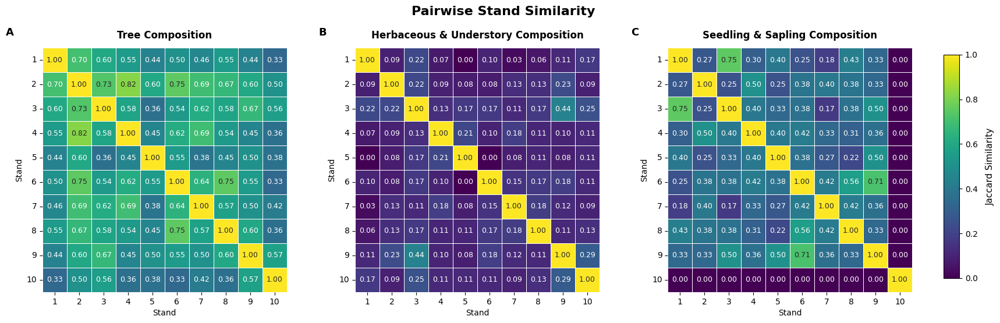


Tree Jaccard matrix
Dimensions: (10, 10)
Stand IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


,1,2,3,4,5,6,7,8,9,10
1,1.000000,0.700000,0.600000,0.545455,0.444444,0.500000,0.461538,0.545455,0.444444,0.333333
2,0.700000,1.000000,0.727273,0.818182,0.600000,0.750000,0.692308,0.666667,0.600000,0.500000
3,0.600000,0.727273,1.000000,0.583333,0.363636,0.538462,0.615385,0.583333,0.666667,0.555556
4,0.545455,0.818182,0.583333,1.000000,0.454545,0.615385,0.692308,0.538462,0.454545,0.363636
5,0.444444,0.600000,0.363636,0.454545,1.000000,0.545455,0.384615,0.454545,0.500000,0.375000
6,0.500000,0.750000,0.538462,0.615385,0.545455,1.000000,0.642857,0.750000,0.545455,0.333333
7,0.461538,0.692308,0.615385,0.692308,0.384615,0.642857,1.000000,0.571429,0.500000,0.416667
8,0.545455,0.666667,0.583333,0.538462,0.454545,0.750000,0.571429,1.000000,0.600000,0.363636
9,0.444444,0.600000,0.666667,0.454545,0.500000,0.545455,0.500000,0.600000,1.000000,0.571429
10,0.333333,0.500000,0.555556,0.363636,0.375000,0.333333,0.416667,0.363636,0.571429,1.000000



Herbaceous Jaccard matrix
Dimensions: (10, 10)
Stand IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


,1,2,3,4,5,6,7,8,9,10
1,1.000000,0.086957,0.222222,0.068966,0.000000,0.100000,0.028571,0.058824,0.111111,0.166667
2,0.086957,1.000000,0.217391,0.090909,0.076923,0.076923,0.127660,0.129032,0.227273,0.090909
3,0.222222,0.217391,1.000000,0.133333,0.166667,0.166667,0.114286,0.166667,0.444444,0.250000
4,0.068966,0.090909,0.133333,1.000000,0.214286,0.096774,0.180000,0.108108,0.100000,0.111111
5,0.000000,0.076923,0.166667,0.214286,1.000000,0.000000,0.083333,0.105263,0.083333,0.111111
6,0.100000,0.076923,0.166667,0.096774,0.000000,1.000000,0.147059,0.166667,0.181818,0.111111
7,0.028571,0.127660,0.114286,0.180000,0.083333,0.147059,1.000000,0.179487,0.117647,0.093750
8,0.058824,0.129032,0.166667,0.108108,0.105263,0.166667,0.179487,1.000000,0.111111,0.133333
9,0.111111,0.227273,0.444444,0.100000,0.083333,0.181818,0.117647,0.111111,1.000000,0.285714
10,0.166667,0.090909,0.250000,0.111111,0.111111,0.111111,0.093750,0.133333,0.285714,1.000000



Regeneration Jaccard matrix
Dimensions: (10, 10)
Stand IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


,1,2,3,4,5,6,7,8,9,10
1,1.000000,0.272727,0.750000,0.300000,0.400000,0.250000,0.181818,0.428571,0.333333,0.0
2,0.272727,1.000000,0.250000,0.500000,0.250000,0.384615,0.400000,0.384615,0.333333,0.0
3,0.750000,0.250000,1.000000,0.400000,0.333333,0.375000,0.166667,0.375000,0.500000,0.0
4,0.300000,0.500000,0.400000,1.000000,0.400000,0.416667,0.333333,0.307692,0.363636,0.0
5,0.400000,0.250000,0.333333,0.400000,1.000000,0.375000,0.272727,0.222222,0.500000,0.0
6,0.250000,0.384615,0.375000,0.416667,0.375000,1.000000,0.416667,0.555556,0.714286,0.0
7,0.181818,0.400000,0.166667,0.333333,0.272727,0.416667,1.000000,0.416667,0.363636,0.0
8,0.428571,0.384615,0.375000,0.307692,0.222222,0.555556,0.416667,1.000000,0.333333,0.0
9,0.333333,0.333333,0.500000,0.363636,0.500000,0.714286,0.363636,0.333333,1.000000,0.0
10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0


In [66]:

# ============================================================
# STEP 51: PAIRWISE STAND JACCARD SIMILARITY
# ============================================================
#
# Compare species composition similarity across all ten stands.
#
# Panels:
# A. Tree
# B. Herbaceous & Understory
# C. Seedling & Sapling
#
# Jaccard similarity ranges from 0 to 1:
# 0 = No shared species
# 1 = Identical species composition

# ------------------------------------------------------------
# 1. DEFINE STAND ORDER
# ------------------------------------------------------------

stand_order = list(range(1, 11))

# ------------------------------------------------------------
# 2. BUILD JACCARD MATRICES
# ------------------------------------------------------------

jaccard_matrices = {}

# These names must match the values in shared_species_summary.
vegetation_layers = [
    'Tree',
    'Herbaceous',
    'Regeneration'
]

for vegetation_layer in vegetation_layers:

    # Initialize a 10 x 10 matrix.
    similarity_matrix = pd.DataFrame(
        np.nan,
        index=stand_order,
        columns=stand_order
    )

    # Each stand has perfect similarity with itself.
    for stand in stand_order:
        similarity_matrix.loc[stand, stand] = 1.0

    # Retrieve pairwise comparisons for this vegetation layer.
    layer_results = shared_species_summary[
        shared_species_summary['Vegetation Layer']
        == vegetation_layer
    ].copy()

    # Populate the similarity matrix.
    for _, row in layer_results.iterrows():

        stand_a = int(row['Stand A'])
        stand_b = int(row['Stand B'])

        similarity = row['Jaccard Similarity']

        # Only populate comparisons involving the ten study stands.
        if stand_a in stand_order and stand_b in stand_order:

            similarity_matrix.loc[
                stand_a, stand_b
            ] = similarity

            similarity_matrix.loc[
                stand_b, stand_a
            ] = similarity

    # Store the completed matrix using its actual layer name.
    jaccard_matrices[vegetation_layer] = similarity_matrix


# ------------------------------------------------------------
# 3. DEFINE DISPLAY LABELS
# ------------------------------------------------------------

# The first value is the dictionary key.
# The second value is the title displayed above the heatmap.

heatmap_panels = [
    ('Tree', 'Tree Composition'),
    ('Herbaceous', 'Herbaceous & Understory Composition'),
    ('Regeneration', 'Seedling & Sapling Composition')
]


# ------------------------------------------------------------
# 4. CREATE THREE-PANEL FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 6)
)

# Store the first heatmap for the shared colorbar.
first_heatmap = None

for panel_index, (matrix_key, display_title) in enumerate(
    heatmap_panels
):

    ax = axes[panel_index]

    # Retrieve the matrix using the correct dictionary key.
    matrix = jaccard_matrices[matrix_key]

    # Draw the heatmap.
    heatmap = sns.heatmap(
        matrix,
        ax=ax,
        annot=True,
        fmt='.2f',
        cmap='viridis',
        vmin=0,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar=False,
        annot_kws={'size': 9}
    )

    if first_heatmap is None:
        first_heatmap = heatmap

    # Add panel title.
    ax.set_title(
        display_title,
        fontsize=12,
        fontweight='bold',
        pad=12
    )

    # Axis labels.
    ax.set_xlabel(
        'Stand',
        fontsize=10
    )

    ax.set_ylabel(
        'Stand',
        fontsize=10
    )

    # Ensure all ten stand labels appear.
    ax.set_xticklabels(
        stand_order,
        rotation=0
    )

    ax.set_yticklabels(
        stand_order,
        rotation=0
    )

    # Panel identifiers.
    ax.text(
        -0.15,
        1.04,
        chr(65 + panel_index),
        transform=ax.transAxes,
        fontsize=13,
        fontweight='bold',
        va='bottom'
    )


# ------------------------------------------------------------
# 5. ADD SHARED COLORBAR
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.06,
    right=0.89,
    bottom=0.14,
    top=0.84,
    wspace=0.28
)

colorbar_axis = fig.add_axes(
    [0.92, 0.18, 0.015, 0.64]
)

colorbar = fig.colorbar(
    first_heatmap.collections[0],
    cax=colorbar_axis
)

colorbar.set_label(
    'Jaccard Similarity',
    fontsize=11,
    labelpad=10
)


# ------------------------------------------------------------
# 6. FIGURE TITLE
# ------------------------------------------------------------

fig.suptitle(
    'Pairwise Stand Similarity',
    fontsize=16,
    fontweight='bold',
    y=0.96
)


# ------------------------------------------------------------
# 7. EXPORT FIGURE
# ------------------------------------------------------------

plt.savefig(
    export_dir / 'Jaccard_Similarity_Heatmaps.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

plt.savefig(
    export_dir / 'Jaccard_Similarity_Heatmaps.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()


# ------------------------------------------------------------
# 8. VERIFY ALL THREE MATRICES
# ------------------------------------------------------------

for layer, matrix in jaccard_matrices.items():

    print(f'\n{layer} Jaccard matrix')
    print('Dimensions:', matrix.shape)
    print('Stand IDs:', matrix.index.tolist())

    display(matrix)


In [67]:
# ============================================================
# STEP 52
# ============================================================
#
# Goal:
# Create one comprehensive species composition profile for each stand.
#
# Each stand profile will contain:
# 1. Tree species and tree richness.
# 2. Herbaceous species and herbaceous richness.
# 3. Regeneration species and regeneration richness.
#
# Species lists are based on observed presence in the corresponding
# presence/absence matrices.
#
# This step organizes existing results; it does not modify the
# original field datasets.

# Identify the vegetation layers and their corresponding matrices.
composition_matrices = {
    'Tree': tree_presence_matrix,
    'Herbaceous': herbaceous_presence_matrix,
    'Regeneration': regeneration_presence_matrix
}

# Create an empty list to store the profile for each stand.
stand_composition_profiles = []

# Loop through each stand.
for stand in stand_order:

    # Create a dictionary to store this stand's information.
    stand_profile = {
        'Stand ID': stand
    }

    # Examine each vegetation layer separately.
    for vegetation_layer, presence_matrix in composition_matrices.items():

        # Select species recorded in this stand.
        # A value of 1 indicates that the species was observed.
        observed_species = sorted(
            presence_matrix.index[
                presence_matrix[stand] == 1
            ].tolist()
        )

        # Calculate observed richness as the number of recorded species.
        observed_richness = len(observed_species)

        # Store the species list and richness value in the profile.
        stand_profile[f'{vegetation_layer} Richness'] = observed_richness

        stand_profile[f'{vegetation_layer} Species'] = observed_species

    # Add the completed stand profile to the overall list.
    stand_composition_profiles.append(stand_profile)

# Convert the profiles into a DataFrame.
stand_composition_profiles_df = pd.DataFrame(
    stand_composition_profiles
)

# Calculate total observed richness across all three vegetation layers.
# Note: A species occurring in multiple layers is counted once in each
# layer-specific richness value, so this is a sum of layer richness,
# not the number of unique species across the entire stand.
stand_composition_profiles_df['Combined Layer Richness'] = (
    stand_composition_profiles_df['Tree Richness']
    + stand_composition_profiles_df['Herbaceous Richness']
    + stand_composition_profiles_df['Regeneration Richness']
)

# Display the richness summary first.
display(
    stand_composition_profiles_df[
        [
            'Stand ID',
            'Tree Richness',
            'Herbaceous Richness',
            'Regeneration Richness',
            'Combined Layer Richness'
        ]
    ]
)

# Print the full species lists for each stand.
for _, profile in stand_composition_profiles_df.iterrows():

    print('\n' + '=' * 65)
    print(f"STAND {int(profile['Stand ID'])}")
    print('=' * 65)

    # Print the species and richness for each vegetation layer.
    for vegetation_layer in ['Tree', 'Herbaceous', 'Regeneration']:

        print(
            f"\n{vegetation_layer} "
            f"({profile[f'{vegetation_layer} Richness']} species):"
        )

        # Print each species on its own line.
        for species in profile[f'{vegetation_layer} Species']:
            print(f"  - {species}")

,Stand ID,Tree Richness,Herbaceous Richness,Regeneration Richness,Combined Layer Richness
0,1,7,4,3,14
1,2,10,21,11,42
2,3,9,7,4,20
3,4,10,27,10,47
4,5,6,7,4,17
5,6,11,7,7,25
6,7,12,32,10,54
7,8,10,14,7,31
8,9,6,6,5,17
9,10,5,3,0,8



STAND 1

Tree (7 species):
  - American Beech
  - Eastern Hemlock
  - Red Maple
  - Sugar Maple
  - White Birch
  - White Oak
  - Yellow Birch

Herbaceous (4 species):
  - Christmas Fern
  - Interrupted Fern
  - Princess Pine
  - Starflower

Regeneration (3 species):
  - American Beech
  - Eastern Hemlock
  - Yellow Birch

STAND 2

Tree (10 species):
  - American Beech
  - Eastern Hemlock
  - Eastern White Pine
  - Northern Red Oak
  - Red Maple
  - Sugar Maple
  - White Ash
  - White Birch
  - White Oak
  - Yellow Birch

Herbaceous (21 species):
  - American Royal Fern
  - Calico Aster
  - Christmas Fern
  - Cinnamon Fern
  - Dog Bane
  - Evergreen Club Moss
  - Fan Clubmoss
  - Flat Branched Tree Clubmoss
  - Intermediate Wood Fern
  - Long Down Wood Grass
  - Long Stalked Sedge
  - Long-Awned Wood Grass
  - Meadow Rue
  - Northern Wild Raisin
  - Partridgeberry
  - Princess Pine
  - Rattlesnake Plantain
  - Sensitive Fern
  - Small Flowered Buttercup
  - White Bear Sedge
  - Wrinkl

In [68]:
# ============================================================
# STEP 53
# ============================================================
#
# Goal:
# Determine how species are distributed across the tree, herbaceous,
# and regeneration layers within each stand.
#
# This analysis distinguishes:
# 1. Species recorded in one vegetation layer.
# 2. Species recorded in two vegetation layers.
# 3. Species recorded in all three vegetation layers.
#
# It also calculates the total number of unique species per stand.
# A species occurring in multiple layers is counted only once in
# the total unique species calculation.

# Create a list to store the cross-layer overlap results.
layer_overlap_results = []

# Loop through each stand.
for stand in stand_order:

    # Create an empty dictionary to store species sets for this stand.
    stand_species = {}

    # Retrieve the species recorded in each vegetation layer.
    for vegetation_layer, presence_matrix in composition_matrices.items():

        # Identify species with a presence value of 1 in this stand.
        stand_species[vegetation_layer] = set(
            presence_matrix.index[
                presence_matrix[stand] == 1
            ]
        )

    # Combine all three species sets.
    # A set automatically removes duplicate species names.
    all_species = (
        stand_species['Tree']
        | stand_species['Herbaceous']
        | stand_species['Regeneration']
    )

    # Count how many vegetation layers each species occurs in.
    species_layer_counts = {}

    for species in all_species:

        # Count the number of layers in which this species was recorded.
        species_layer_counts[species] = sum(
            species in stand_species[layer]
            for layer in vegetation_layers
        )

    # Calculate the number of species occurring in one, two, or three layers.
    one_layer = sum(
        count == 1 for count in species_layer_counts.values()
    )

    two_layers = sum(
        count == 2 for count in species_layer_counts.values()
    )

    three_layers = sum(
        count == 3 for count in species_layer_counts.values()
    )

    # Store the results for this stand.
    layer_overlap_results.append({
        'Stand ID': stand,
        'Unique Species': len(all_species),
        'One Layer Only': one_layer,
        'Two Layers': two_layers,
        'All Three Layers': three_layers
    })

# Convert the results into a DataFrame.
layer_overlap_summary = pd.DataFrame(layer_overlap_results)

# Display the cross-layer overlap summary.
display(layer_overlap_summary)

# Verify that the three overlap categories sum to total unique richness.
print(
    'Overlap totals correctly account for unique species:',
    (
        layer_overlap_summary['One Layer Only']
        + layer_overlap_summary['Two Layers']
        + layer_overlap_summary['All Three Layers']
        == layer_overlap_summary['Unique Species']
    ).all()
)

,Stand ID,Unique Species,One Layer Only,Two Layers,All Three Layers
0,1,11,8,3,0
1,2,34,26,8,0
2,3,17,14,3,0
3,4,41,35,6,0
4,5,14,11,3,0
5,6,21,17,4,0
6,7,47,40,7,0
7,8,27,23,4,0
8,9,14,11,3,0
9,10,8,8,0,0


Overlap totals correctly account for unique species: True


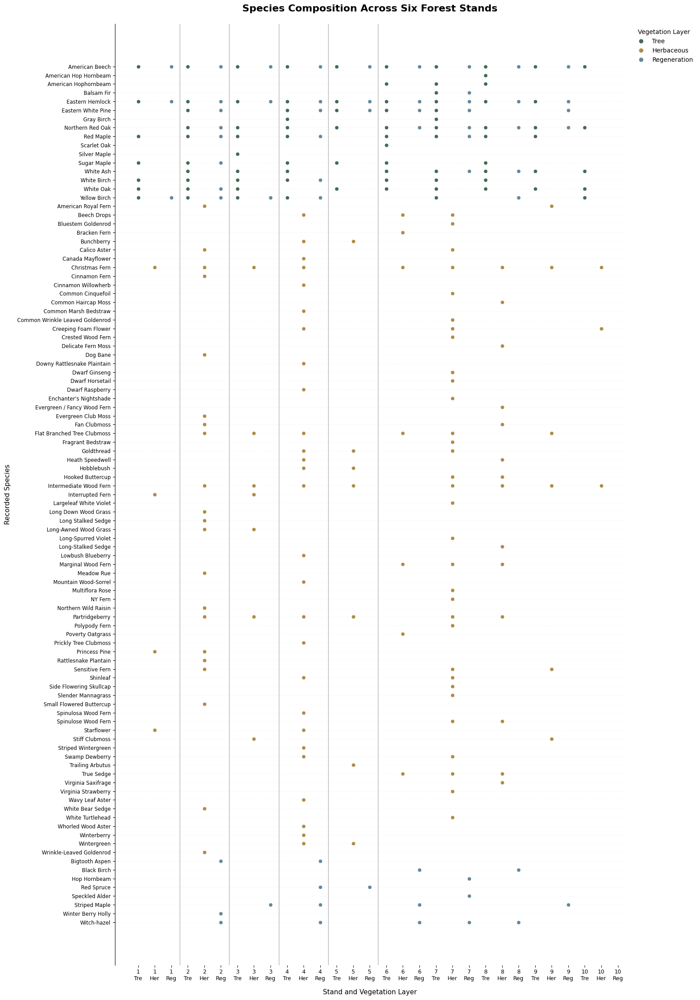

Total unique species represented: 99


In [69]:
# ============================================================
# STEP 54
# ============================================================

# Define the vegetation layers and their display colors.
layer_colors = {
    'Tree': '#416B52',
    'Herbaceous': '#B18A45',
    'Regeneration': '#66879B'
}

# Reuse the existing presence/absence matrices.
composition_matrices = {
    'Tree': tree_presence_matrix,
    'Herbaceous': herbaceous_presence_matrix,
    'Regeneration': regeneration_presence_matrix
}

# Create one master list containing every species recorded
# in at least one of the three vegetation layers.
all_species = set()

for matrix in composition_matrices.values():
    all_species.update(matrix.index.tolist())

# Establish a consistent species ordering.
# Species are grouped according to the first vegetation layer
# in which they appear: Tree, Herbaceous, then Regeneration.
species_order = []

for vegetation_layer in ['Tree', 'Herbaceous', 'Regeneration']:

    # Retrieve the species recorded in the current layer.
    layer_species = sorted(
        composition_matrices[vegetation_layer].index.tolist()
    )

    # Add species that have not already been included.
    for species in layer_species:
        if species not in species_order:
            species_order.append(species)

# Create the 18 column labels: ten stands multiplied by three layers.
column_labels = []

for stand in stand_order:
    for vegetation_layer in ['Tree', 'Herbaceous', 'Regeneration']:
        column_labels.append((stand, vegetation_layer))

# Create an empty presence/absence matrix.
# Rows represent species and columns represent stand-layer combinations.
master_composition_matrix = pd.DataFrame(
    0,
    index=species_order,
    columns=pd.MultiIndex.from_tuples(
        column_labels,
        names=['Stand', 'Vegetation Layer']
    )
)

# Populate the master matrix using the existing presence/absence data.
for vegetation_layer, matrix in composition_matrices.items():

    # Loop through each stand.
    for stand in stand_order:

        # Identify species present in this stand and layer.
        observed_species = matrix.index[matrix[stand] == 1]

        # Mark those species as present in the master matrix.
        master_composition_matrix.loc[
            observed_species,
            (stand, vegetation_layer)
        ] = 1

# ------------------------------------------------------------
# CREATE THE SPECIES-COMPOSITION VISUALIZATION
# ------------------------------------------------------------

# Set figure height according to the number of species.
# This prevents the species labels from becoming overcrowded.
figure_height = max(12, len(species_order) * 0.23)

fig, ax = plt.subplots(
    figsize=(16, figure_height)
)

# Define the horizontal positions for the 18 columns.
x_positions = np.arange(len(column_labels))

# Define the vertical positions for all species.
y_positions = np.arange(len(species_order))

# Draw one circle for every observed species occurrence.
for column_index, (stand, vegetation_layer) in enumerate(column_labels):

    # Identify species recorded in this stand-layer combination.
    present_species = master_composition_matrix.index[
        master_composition_matrix[(stand, vegetation_layer)] == 1
    ]

    # Convert species names to their vertical plotting positions.
    present_y_positions = [
        species_order.index(species)
        for species in present_species
    ]

    # Draw the observed species as colored circles.
    ax.scatter(
        [column_index] * len(present_y_positions),
        present_y_positions,
        s=38,
        color=layer_colors[vegetation_layer],
        edgecolors='white',
        linewidths=0.4,
        zorder=3
    )

# Add horizontal gridlines to help follow species across the matrix.
ax.set_yticks(y_positions)
ax.set_yticklabels(species_order, fontsize=8.5)

ax.set_xticks(x_positions)

# Label each column with its stand number and vegetation layer.
ax.set_xticklabels(
    [
        f'{stand}\n{layer[:3]}'
        for stand, layer in column_labels
    ],
    fontsize=9
)

# Place the first species at the top of the figure.
ax.invert_yaxis()

# Add vertical separators between stands.
for separator in [2.5, 5.5, 8.5, 11.5, 14.5]:
    ax.axvline(
        separator,
        color='gray',
        linewidth=0.9,
        alpha=0.65
    )

# Add subtle horizontal reference lines.
ax.set_axisbelow(True)
ax.grid(
    axis='y',
    linestyle=':',
    linewidth=0.4,
    alpha=0.35
)

# Label the axes.
ax.set_ylabel('Recorded Species', fontsize=11, labelpad=10)
ax.set_xlabel('Stand and Vegetation Layer', fontsize=11, labelpad=12)

# Add the figure title.
ax.set_title(
    'Species Composition Across Six Forest Stands',
    fontsize=16,
    fontweight='bold',
    pad=20
)

# Create a legend using the same colors as the matrix.
legend_handles = [
    plt.Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor=layer_colors[layer],
        markeredgecolor='white',
        markersize=8,
        label=layer
    )
    for layer in layer_colors
]

ax.legend(
    handles=legend_handles,
    title='Vegetation Layer',
    loc='upper left',
    bbox_to_anchor=(1.01, 1),
    frameon=False
)

# Remove unnecessary chart borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# Adjust spacing to accommodate species labels and legend.
plt.tight_layout()

# Export the figure at publication-quality resolution.
plt.savefig(
    export_dir / 'Master_Species_Composition_Matrix.png',
    dpi=600,
    bbox_inches='tight'
)

plt.savefig(
    export_dir / 'Master_Species_Composition_Matrix.pdf',
    bbox_inches='tight'
)

# Display the completed visualization.
plt.show()

# Report the number of unique species represented.
print(f'Total unique species represented: {len(species_order)}')

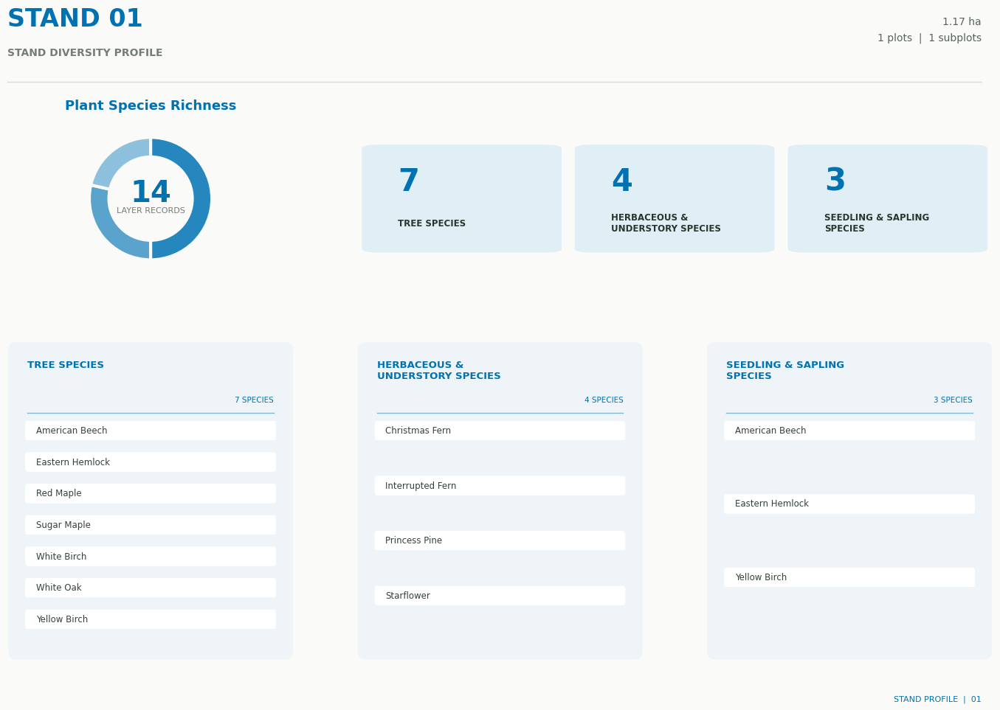

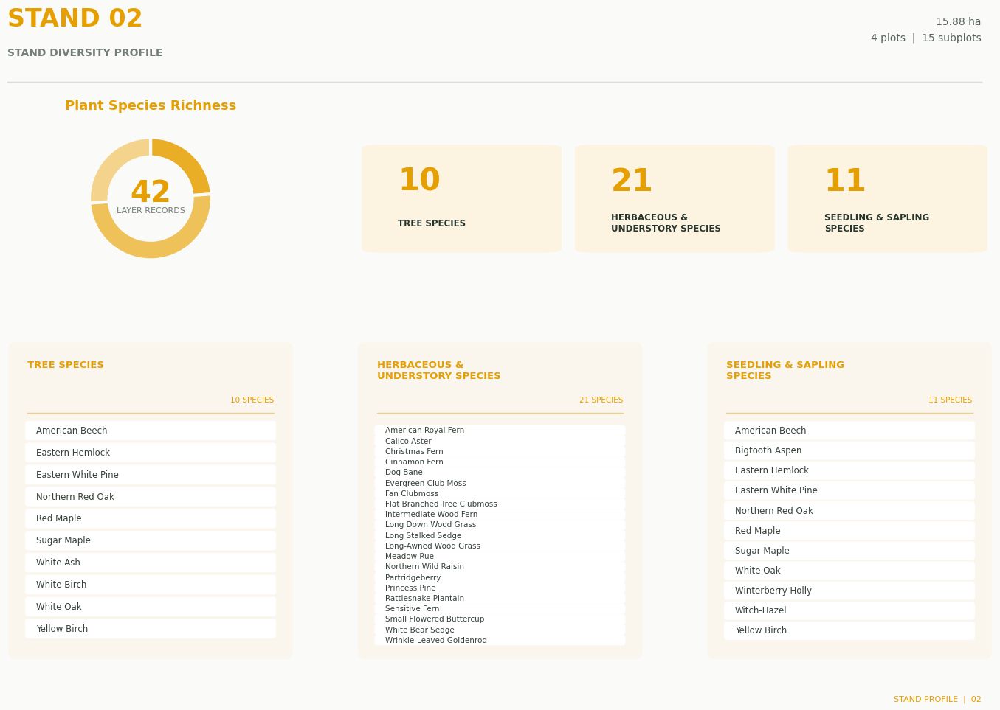

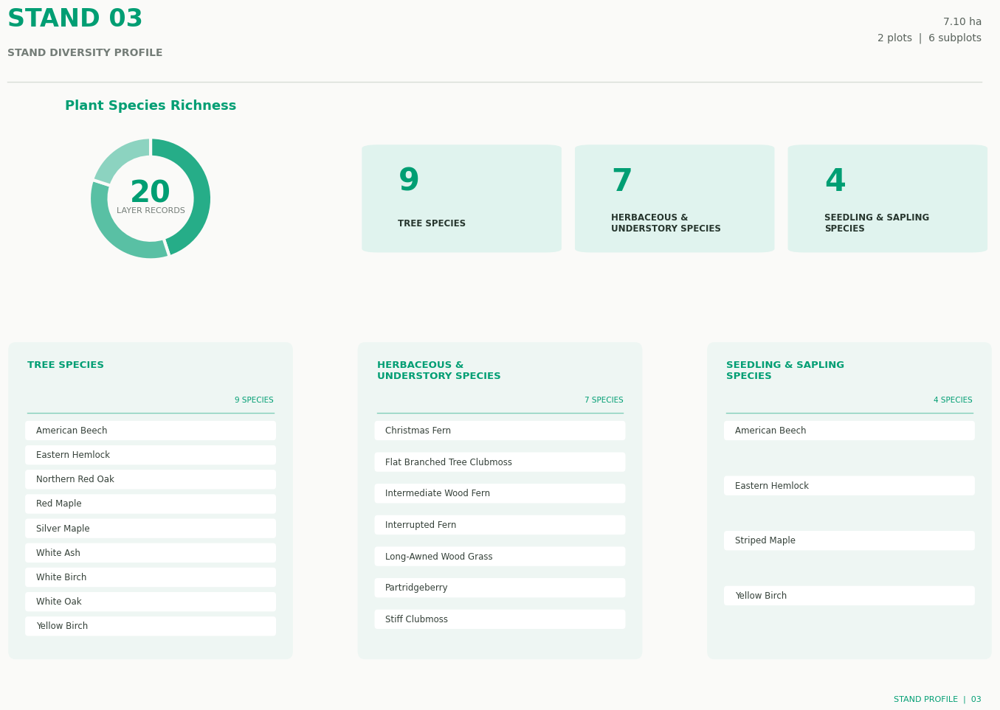

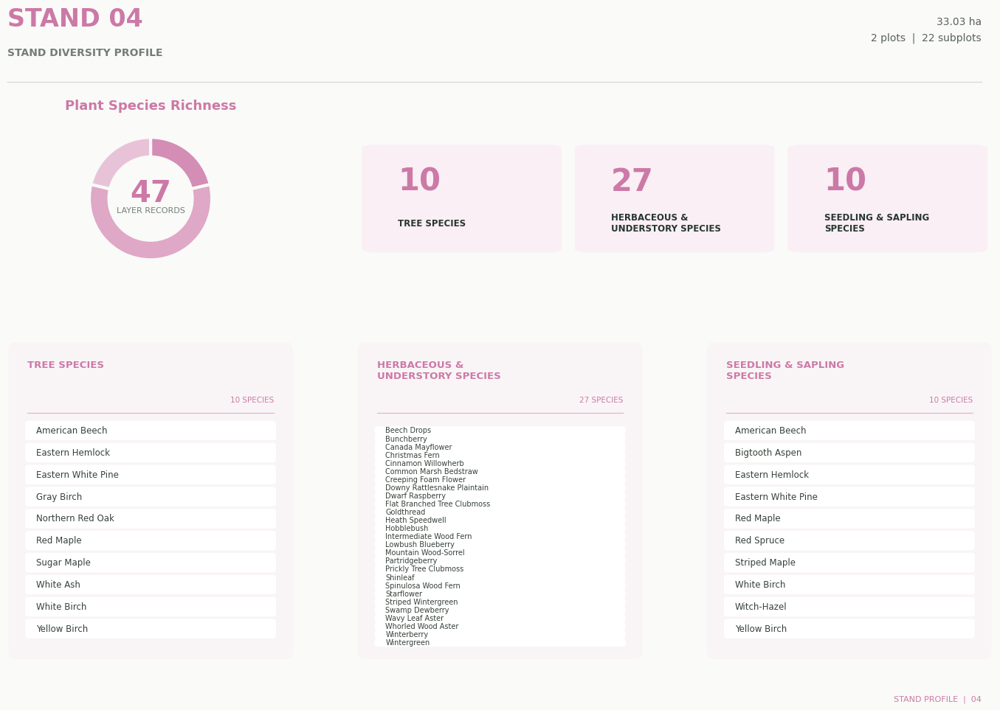

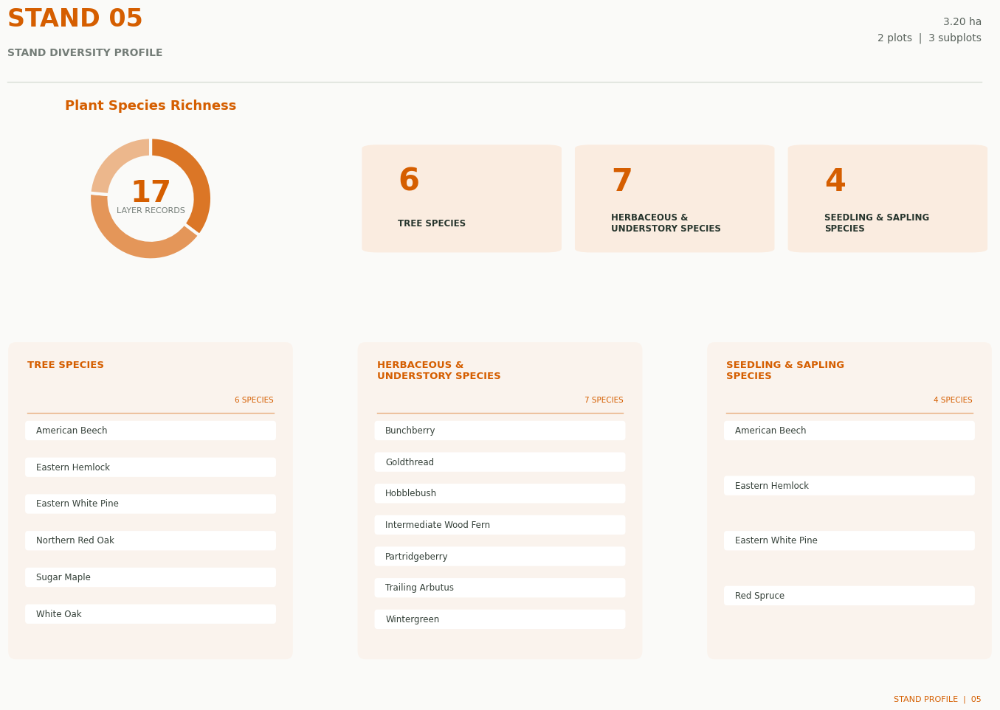

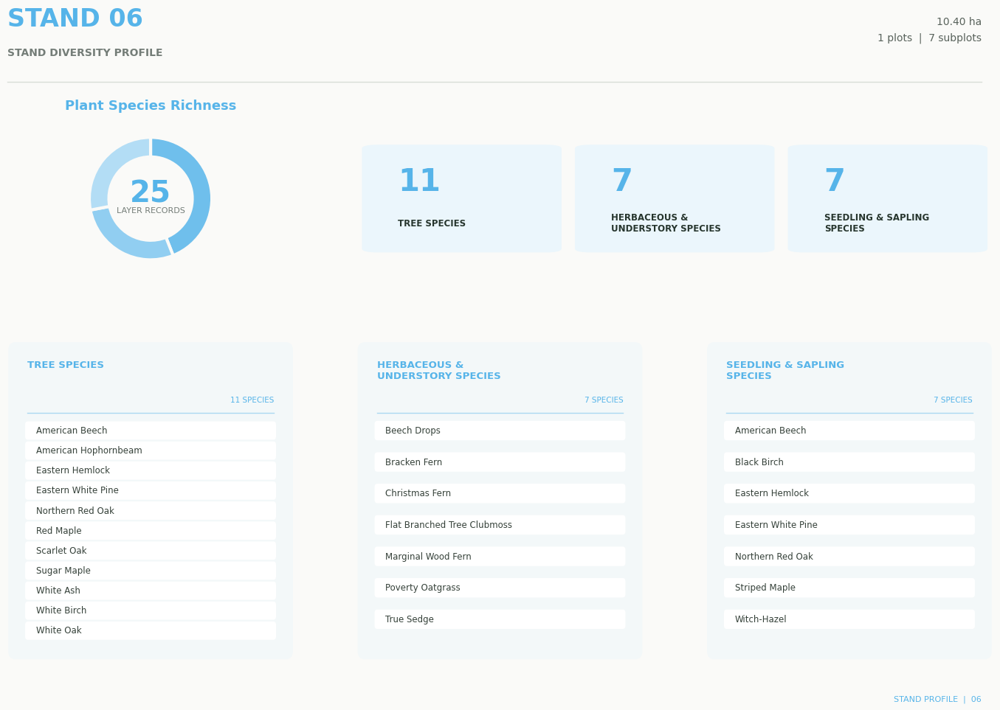

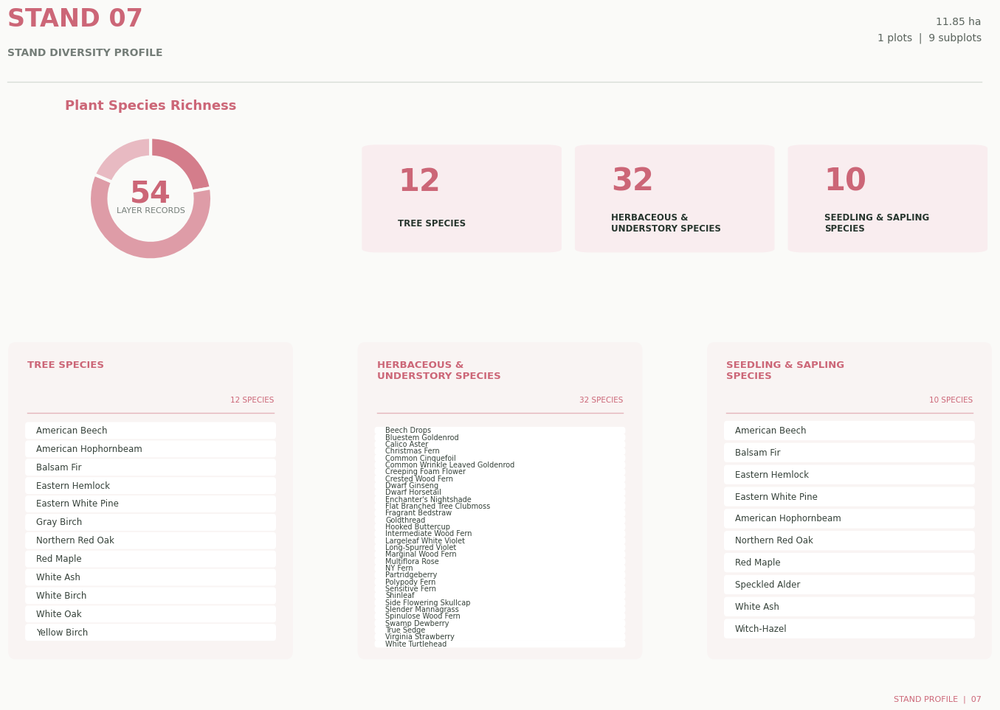

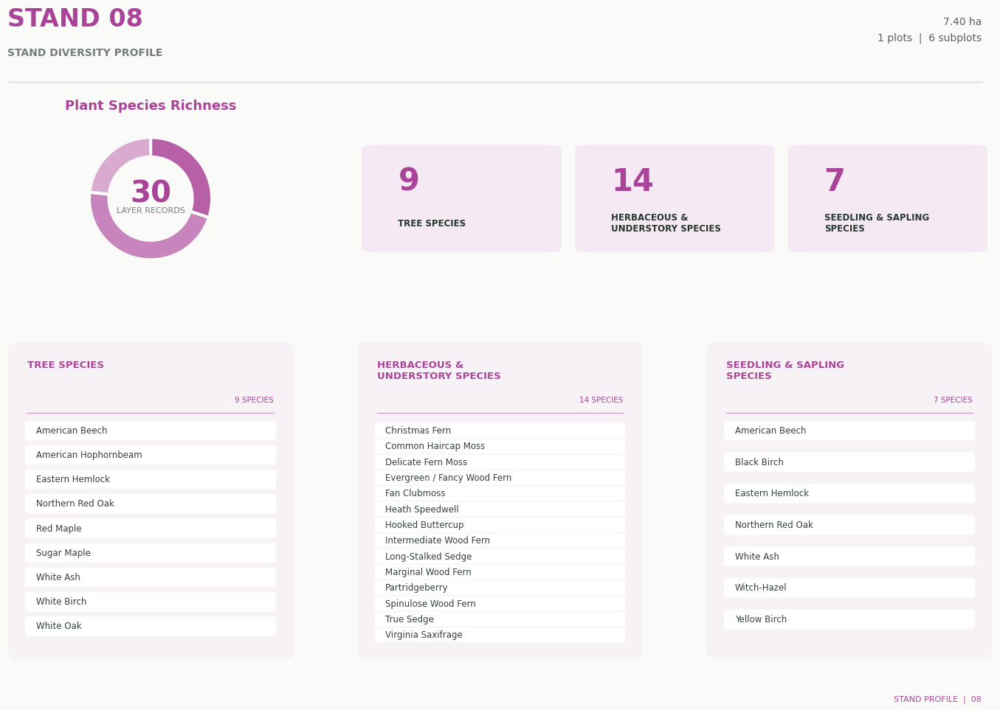

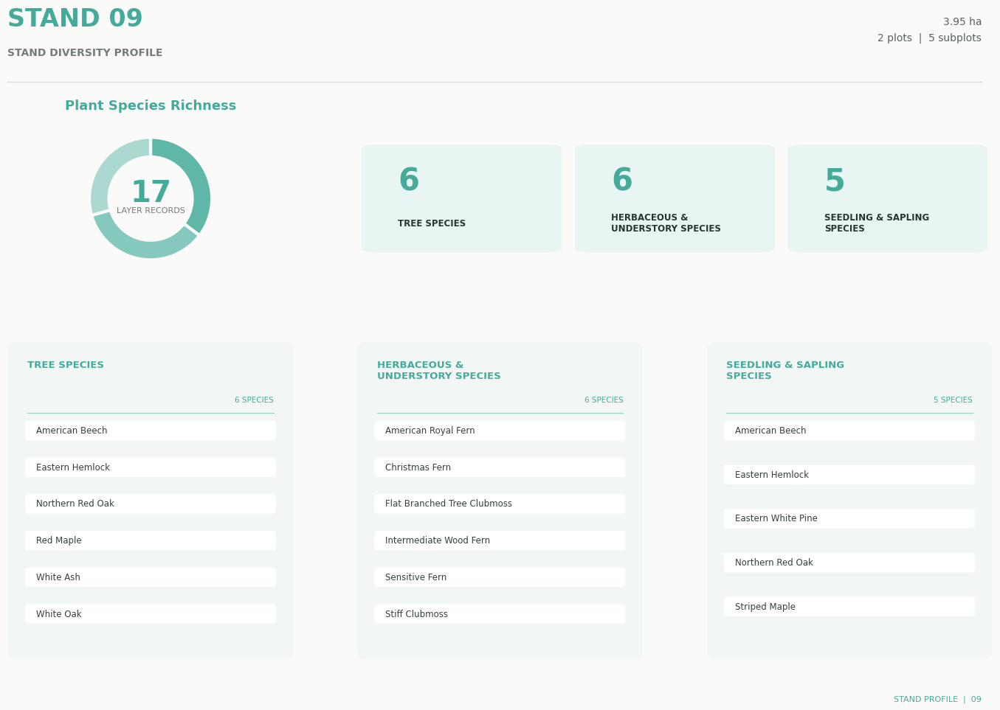

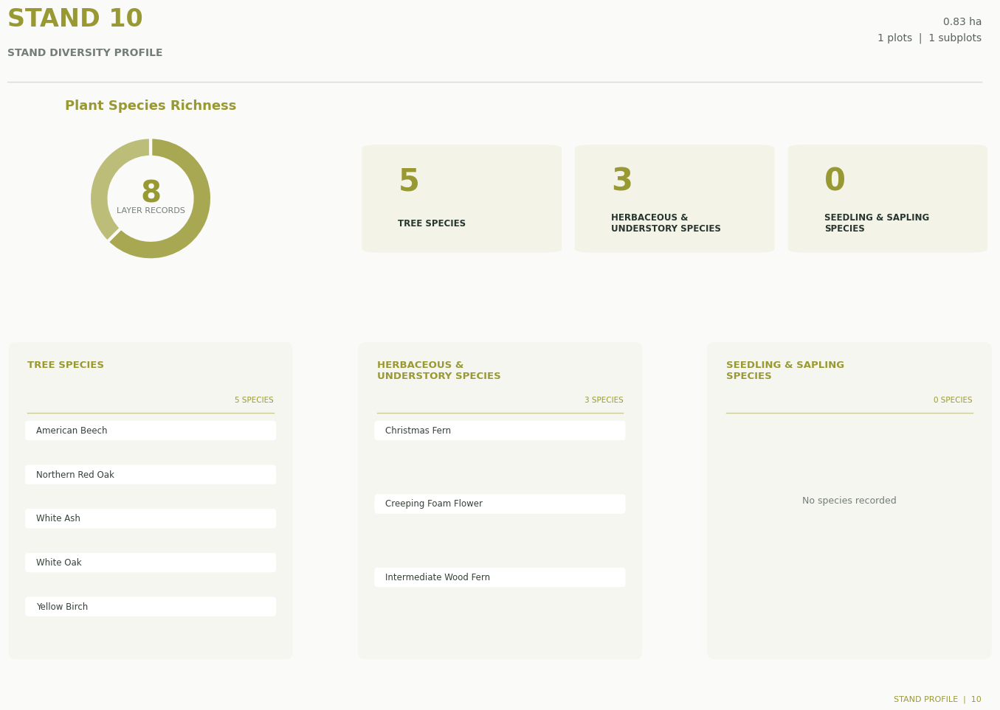

STAND DIVERSITY PROFILE EXPORT COMPLETE
-------------------------------------------------------
Number of stand profiles: 10
Stand IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Sampling information used in the profiles:


,Stand ID,Area_hectares,Number_of_Plots,Number_of_Subplots
0,1,1.17,1,1
1,2,15.88,4,15
2,3,7.10,2,6
3,4,33.03,2,22
4,5,3.20,2,3
5,6,10.40,1,7
6,7,11.85,1,9
7,8,7.40,1,6
8,9,3.95,2,5
9,10,0.83,1,1



Displayed species richness after name standardization:

Stand 1:
  Tree: 7 species
  Herbaceous: 4 species
  Regeneration: 3 species

Stand 2:
  Tree: 10 species
  Herbaceous: 21 species
  Regeneration: 11 species

Stand 3:
  Tree: 9 species
  Herbaceous: 7 species
  Regeneration: 4 species

Stand 4:
  Tree: 10 species
  Herbaceous: 27 species
  Regeneration: 10 species

Stand 5:
  Tree: 6 species
  Herbaceous: 7 species
  Regeneration: 4 species

Stand 6:
  Tree: 11 species
    American Hophornbeam: standardized
  Herbaceous: 7 species
  Regeneration: 7 species

Stand 7:
  Tree: 12 species
    American Hophornbeam: standardized
  Herbaceous: 32 species
  Regeneration: 10 species
    American Hophornbeam: standardized

Stand 8:
  Tree: 9 species
    American Hophornbeam: standardized
  Herbaceous: 14 species
  Regeneration: 7 species

Stand 9:
  Tree: 6 species
  Herbaceous: 6 species
  Regeneration: 5 species

Stand 10:
  Tree: 5 species
  Herbaceous: 3 species
  Regeneration: 0 spec

In [75]:

# ============================================================
# STEP 55: INDIVIDUAL STAND DIVERSITY PROFILES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import to_rgb
from matplotlib.patches import FancyBboxPatch


# ------------------------------------------------------------
# 1. STAND COLORS AND VEGETATION LAYERS
# ------------------------------------------------------------

stand_order = list(range(1, 11))

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

vegetation_layers = [
    'Tree',
    'Herbaceous',
    'Regeneration'
]

page_background = '#FAFAF8'

layer_headings = {
    'Tree': 'TREE SPECIES',
    'Herbaceous': 'HERBACEOUS &\nUNDERSTORY SPECIES',
    'Regeneration': 'SEEDLING & SAPLING\nSPECIES'
}

panel_headings = {
    'Tree': 'TREE SPECIES',
    'Herbaceous': 'HERBACEOUS &\nUNDERSTORY SPECIES',
    'Regeneration': 'SEEDLING & SAPLING\nSPECIES'
}


# ------------------------------------------------------------
# 2. VERIFY REQUIRED DATA
# ------------------------------------------------------------

required_profile_columns = [
    'Stand ID',
    'Tree Species',
    'Herbaceous Species',
    'Regeneration Species'
]

missing_profile_columns = [
    col for col in required_profile_columns
    if col not in stand_composition_profiles_df.columns
]

if missing_profile_columns:
    raise KeyError(
        f'Missing profile columns: {missing_profile_columns}'
    )

required_sampling_columns = [
    'Stand ID',
    'Area_hectares',
    'Number_of_Plots',
    'Number_of_Subplots'
]

missing_sampling_columns = [
    col for col in required_sampling_columns
    if col not in sampling_effort_summary.columns
]

if missing_sampling_columns:
    raise KeyError(
        f'Missing sampling columns: {missing_sampling_columns}'
    )


# ------------------------------------------------------------
# 3. CREATE SAMPLING LOOKUP FROM STEP 32
# ------------------------------------------------------------

sampling_lookup = (
    sampling_effort_summary
    .drop_duplicates(subset='Stand ID')
    .set_index('Stand ID')
)

area_lookup = sampling_lookup['Area_hectares'].to_dict()

plot_count_lookup = (
    sampling_lookup['Number_of_Plots'].to_dict()
)

subplot_count_lookup = (
    sampling_lookup['Number_of_Subplots'].to_dict()
)


# ------------------------------------------------------------
# 4. STANDARDIZE SPECIES NAMES
# ------------------------------------------------------------

def normalize_species_name(species):

    if pd.isna(species):
        return ''

    original_name = str(species).strip()

    # Remove spaces, hyphens, and underscores for matching.
    comparison_name = (
        original_name.casefold()
        .replace(' ', '')
        .replace('-', '')
        .replace('_', '')
    )

    # Standardize every Hophornbeam variation.
    if 'hophornbeam' in comparison_name:
        return 'American Hophornbeam'

    name_corrections = {
        'witchhazel': 'Witch-Hazel',
        'winterberryholly': 'Winterberry Holly'
    }

    return name_corrections.get(
        comparison_name,
        original_name
    )


# ------------------------------------------------------------
# 5. STANDARDIZE AND DEDUPLICATE SPECIES LISTS
# ------------------------------------------------------------

def clean_species_list(raw_species):

    if not isinstance(raw_species, (list, tuple, set)):
        return []

    standardized = []

    for species in raw_species:

        if pd.isna(species):
            continue

        corrected_name = normalize_species_name(species)

        if corrected_name:
            standardized.append(corrected_name)

    # Remove duplicates while preserving original order.
    return list(dict.fromkeys(standardized))


# ------------------------------------------------------------
# 6. HELPER FUNCTION: LIGHTER STAND COLORS
# ------------------------------------------------------------

def create_color_shades(base_color):

    rgb = to_rgb(base_color)

    shades = []

    for blend in [0.15, 0.35, 0.55]:

        lighter_shade = tuple(
            channel * (1 - blend) + blend
            for channel in rgb
        )

        shades.append(lighter_shade)

    return shades


# ------------------------------------------------------------
# 7. VERIFY ALL TEN STANDS
# ------------------------------------------------------------

profile_stands = set(
    stand_composition_profiles_df['Stand ID'].astype(int)
)

missing_stands = set(stand_order) - profile_stands

if missing_stands:
    raise ValueError(
        f'Missing stand profiles: {sorted(missing_stands)}'
    )


# ------------------------------------------------------------
# 8. GENERATE INDIVIDUAL STAND PROFILES
# ------------------------------------------------------------

for _, profile in stand_composition_profiles_df.iterrows():

    stand = int(profile['Stand ID'])

    stand_color = stand_colors[stand]

    layer_shades = create_color_shades(stand_color)


    # --------------------------------------------------------
    # A. STANDARDIZE SPECIES LISTS FIRST
    # --------------------------------------------------------

    species_by_layer = {}

    for layer in vegetation_layers:

        raw_species = profile[f'{layer} Species']

        species_by_layer[layer] = clean_species_list(
            raw_species
        )


    # --------------------------------------------------------
    # B. CALCULATE DISPLAY RICHNESS FROM CLEANED LISTS
    # --------------------------------------------------------

    richness_values = [
        len(species_by_layer['Tree']),
        len(species_by_layer['Herbaceous']),
        len(species_by_layer['Regeneration'])
    ]

    total_layer_richness = sum(richness_values)


    # --------------------------------------------------------
    # C. RETRIEVE STAND AREA AND SAMPLING INFORMATION
    # --------------------------------------------------------

    stand_area = area_lookup.get(stand, np.nan)

    plot_count = int(
        plot_count_lookup.get(stand, 0)
    )

    subplot_count = int(
        subplot_count_lookup.get(stand, 0)
    )

    area_text = (
        f'{stand_area:.2f} ha'
        if pd.notna(stand_area)
        else 'Area unavailable'
    )


    # --------------------------------------------------------
    # D. FIGURE AND PAGE LAYOUT
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(15, 10),
        facecolor=page_background
    )

    gs = fig.add_gridspec(
        nrows=2,
        ncols=3,
        height_ratios=[1.2, 2.5],
        hspace=0.28,
        wspace=0.22,
        left=0.06,
        right=0.95,
        top=0.82,
        bottom=0.09
    )


    # --------------------------------------------------------
    # E. HEADER
    # --------------------------------------------------------

    fig.text(
        0.06,
        0.95,
        f'STAND {stand:02d}',
        fontsize=24,
        fontweight='bold',
        color=stand_color
    )

    fig.text(
        0.06,
        0.91,
        'STAND DIVERSITY PROFILE',
        fontsize=10,
        fontweight='bold',
        color='#747D78'
    )

    fig.text(
        0.94,
        0.945,
        (
            f'{area_text}\n'
            f'{plot_count} plots  |  {subplot_count} subplots'
        ),
        ha='right',
        va='center',
        fontsize=10,
        color='#59635C',
        linespacing=1.7
    )

    fig.add_artist(
        plt.Line2D(
            [0.06, 0.94],
            [0.875, 0.875],
            transform=fig.transFigure,
            color='#D8DED7',
            linewidth=1
        )
    )


    # --------------------------------------------------------
    # F. VEGETATION RICHNESS DONUT CHART
    # --------------------------------------------------------

    ax_donut = fig.add_subplot(gs[0, 0])

    ax_donut.pie(
        richness_values,
        colors=layer_shades,
        startangle=90,
        counterclock=False,
        wedgeprops={
            'width': 0.32,
            'edgecolor': page_background,
            'linewidth': 3
        }
    )

    ax_donut.text(
        0,
        0.08,
        str(total_layer_richness),
        ha='center',
        va='center',
        fontsize=29,
        fontweight='bold',
        color=stand_color
    )

    ax_donut.text(
        0,
        -0.19,
        'LAYER RECORDS',
        ha='center',
        va='center',
        fontsize=8,
        color='#747D78'
    )

    ax_donut.set_title(
        'Plant Species Richness',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=12
    )

    ax_donut.set_aspect('equal')


    # --------------------------------------------------------
    # G. RICHNESS CARDS
    # --------------------------------------------------------

    ax_metrics = fig.add_subplot(gs[0, 1:])

    ax_metrics.axis('off')

    metric_positions = [0.02, 0.355, 0.69]

    metric_width = 0.29

    card_background = tuple(
        channel * 0.12 + 0.88
        for channel in to_rgb(stand_color)
    )

    metric_text_color = '#26352D'

    for index, layer in enumerate(vegetation_layers):

        x_position = metric_positions[index]

        card = FancyBboxPatch(
            (x_position, 0.16),
            metric_width,
            0.68,
            boxstyle='round,pad=0.012,rounding_size=0.025',
            transform=ax_metrics.transAxes,
            facecolor=card_background,
            edgecolor='none'
        )

        ax_metrics.add_patch(card)

        ax_metrics.text(
            x_position + 0.045,
            0.61,
            str(richness_values[index]),
            transform=ax_metrics.transAxes,
            fontsize=30,
            fontweight='bold',
            color=stand_color,
            va='center'
        )

        ax_metrics.text(
            x_position + 0.045,
            0.34,
            layer_headings[layer],
            transform=ax_metrics.transAxes,
            fontsize=8.5,
            fontweight='bold',
            color=metric_text_color,
            va='center',
            ha='left',
            linespacing=1.25
        )


    # --------------------------------------------------------
    # H. SPECIES COMPOSITION PANELS
    # --------------------------------------------------------

    for column, layer in enumerate(vegetation_layers):

        ax_species = fig.add_subplot(gs[1, column])

        ax_species.axis('off')

        species_list = species_by_layer[layer]

        panel = FancyBboxPatch(
            (0.015, 0.015),
            0.97,
            0.97,
            transform=ax_species.transAxes,
            boxstyle='round,pad=0.012,rounding_size=0.025',
            facecolor=card_background,
            edgecolor='none',
            alpha=0.45,
            zorder=0
        )

        ax_species.add_patch(panel)


        # ----------------------------------------------------
        # PANEL HEADING
        # ----------------------------------------------------

        ax_species.text(
            0.07,
            0.94,
            panel_headings[layer],
            transform=ax_species.transAxes,
            fontsize=9.5,
            fontweight='bold',
            color=stand_color,
            va='top',
            ha='left',
            linespacing=1.15
        )

        ax_species.text(
            0.93,
            0.815,
            f'{len(species_list)} SPECIES',
            transform=ax_species.transAxes,
            fontsize=7.5,
            color=stand_color,
            ha='right',
            va='center'
        )

        ax_species.plot(
            [0.07, 0.93],
            [0.775, 0.775],
            transform=ax_species.transAxes,
            color=stand_color,
            alpha=0.45,
            linewidth=1
        )


        # ----------------------------------------------------
        # SPECIES LABEL LAYOUT
        # ----------------------------------------------------

        available_height = 0.69

        species_count = len(species_list)

        if species_count > 0:

            vertical_spacing = (
                available_height / species_count
            )

            label_height = min(
                0.055,
                vertical_spacing * 0.82
            )

            if species_count >= 22:
                species_fontsize = 7.0
            elif species_count >= 15:
                species_fontsize = 7.5
            else:
                species_fontsize = 8.5

            for species_index, species in enumerate(species_list):

                y_position = (
                    0.72 - species_index * vertical_spacing
                )

                label = FancyBboxPatch(
                    (
                        0.065,
                        y_position - label_height / 2
                    ),
                    0.87,
                    label_height,
                    transform=ax_species.transAxes,
                    boxstyle='round,pad=0.003,rounding_size=0.010',
                    facecolor='#FFFFFF',
                    edgecolor='none',
                    zorder=1
                )

                ax_species.add_patch(label)

                ax_species.text(
                    0.10,
                    y_position,
                    species,
                    transform=ax_species.transAxes,
                    fontsize=species_fontsize,
                    color='#354139',
                    va='center',
                    ha='left',
                    zorder=2
                )

        else:

            ax_species.text(
                0.5,
                0.50,
                'No species recorded',
                transform=ax_species.transAxes,
                fontsize=9,
                color='#747D78',
                ha='center',
                va='center'
            )


    # --------------------------------------------------------
    # I. FOOTER
    # --------------------------------------------------------

    fig.text(
        0.94,
        0.035,
        f'STAND PROFILE  |  {stand:02d}',
        fontsize=8,
        color=stand_color,
        ha='right'
    )


    # --------------------------------------------------------
    # J. EXPORT PNG AND PDF
    # --------------------------------------------------------

    plt.savefig(
        export_dir / f'Stand_{stand}_Composition_Dashboard.png',
        dpi=600,
        bbox_inches='tight',
        facecolor=fig.get_facecolor()
    )

    plt.savefig(
        export_dir / f'Stand_{stand}_Composition_Dashboard.pdf',
        bbox_inches='tight',
        facecolor=fig.get_facecolor()
    )

    plt.show()

    plt.close(fig)


# ------------------------------------------------------------
# 9. VERIFY ALL TEN STAND PROFILES
# ------------------------------------------------------------

print('STAND DIVERSITY PROFILE EXPORT COMPLETE')
print('-' * 55)

print(
    'Number of stand profiles:',
    len(stand_composition_profiles_df)
)

print(
    'Stand IDs:',
    sorted(
        stand_composition_profiles_df['Stand ID'].astype(int).tolist()
    )
)

print('\nSampling information used in the profiles:')

display(
    sampling_effort_summary[
        [
            'Stand ID',
            'Area_hectares',
            'Number_of_Plots',
            'Number_of_Subplots'
        ]
    ].sort_values('Stand ID')
)

print('\nDisplayed species richness after name standardization:')

for _, row in stand_composition_profiles_df.iterrows():

    stand = int(row['Stand ID'])

    print(f'\nStand {stand}:')

    for layer in vegetation_layers:

        cleaned_species = clean_species_list(
            row[f'{layer} Species']
        )

        print(
            f'  {layer}: {len(cleaned_species)} species'
        )

        if 'American Hophornbeam' in cleaned_species:
            print('    American Hophornbeam: standardized')

print('\nAll ten stand profiles have been generated.')


In [77]:
# ============================================================
# STEP 55
# ============================================================

#Install pypdf, the Python library used to combine PDF documents.
!pip install pypdf

In [78]:
# ============================================================
# STEP 56
# ============================================================

# Import PdfWriter from pypdf.
# PdfWriter allows us to combine multiple PDF files into one document.
from pypdf import PdfWriter

# Create a new PDF writer object.
# This will hold all ten stand profiles in the order we add them.
report = PdfWriter()

# Loop through Stands 1–10 in numerical order.
for stand in range(1, 11):

    # Construct the expected filename for the current stand.
    # Example: Stand_1_Composition_Dashboard.pdf
    profile_file = export_dir / f"Stand_{stand}_Composition_Dashboard.pdf"

    # Check that the PDF exists before trying to add it.
    # If a file is missing, stop and identify which stand needs attention.
    if not profile_file.exists():
        raise FileNotFoundError(
            f"Missing PDF for Stand {stand}: {profile_file}"
        )

    # Append the current stand's PDF to the combined report.
    # Each stand profile will become one page in the final document.
    report.append(str(profile_file))

# Define the output path and filename for the combined report.
report_path = export_dir / "Forest_Stand_Vegetation_Composition_Report.pdf"

# Open the destination file in binary write mode.
# Write the combined PDF to this location.
with open(report_path, "wb") as output_file:
    report.write(output_file)

# Close the PDF writer after the report has been saved.
report.close()

# Reopen the completed PDF to verify that it contains ten pages.
from pypdf import PdfReader

# Read the saved report.
completed_report = PdfReader(str(report_path))

# Print the output location and page count.
print(f"Report saved to: {report_path}")
print(f"Number of pages: {len(completed_report.pages)}")

Report saved to: /content/exports/Forest_Stand_Vegetation_Composition_Report.pdf
Number of pages: 10


In [79]:
# ============================================================
# STEP 57
# ============================================================

# Import pandas for organizing and summarizing the stand-level data.
import pandas as pd

# Select the richness columns and stand identifiers from the existing profiles.
# Each row represents one stand.
report_richness_summary = stand_composition_profiles_df[
    [
        'Stand ID',
        'Tree Richness',
        'Herbaceous Richness',
        'Regeneration Richness',
        'Combined Layer Richness'
    ]
].copy()

# Rename the columns to make the table easier to read in the report.
report_richness_summary = report_richness_summary.rename(columns={
    'Stand ID': 'Stand',
    'Tree Richness': 'Tree Species Richness',
    'Herbaceous Richness': 'Herbaceous Species Richness',
    'Regeneration Richness': 'Regeneration Species Richness',
    'Combined Layer Richness': 'Combined Layer Richness'
})

# Sort the table by stand number to ensure consistent ordering.
report_richness_summary = report_richness_summary.sort_values(
    'Stand'
).reset_index(drop=True)

# Display the completed summary table.
display(report_richness_summary)

,Stand,Tree Species Richness,Herbaceous Species Richness,Regeneration Species Richness,Combined Layer Richness
0,1,7,4,3,14
1,2,10,21,11,42
2,3,9,7,4,20
3,4,10,27,10,47
4,5,6,7,4,17
5,6,11,7,7,25
6,7,12,32,10,54
7,8,10,14,7,31
8,9,6,6,5,17
9,10,5,3,0,8


In [80]:
# ============================================================
# STEP 58
# ============================================================

# Count how many records are currently labeled "Overtopped".
overtopped_before = (
    woody_analysis['Crown Class Code']
    .astype('string')
    .str.strip()
    .eq('Overtopped')
    .sum()
)

# Replace "Overtopped" with "Suppressed".
# This only changes the Crown Class Code column in woody_analysis.
woody_analysis['Crown Class Code'] = (
    woody_analysis['Crown Class Code']
    .replace('Overtopped', 'Suppressed')
)

# Display the number of replacements made.
print(f"Records changed: {overtopped_before}")

# Display the updated crown class categories and their counts.
print("\nUpdated crown class categories:")
display(
    woody_analysis['Crown Class Code']
    .value_counts(dropna=False)
    .rename_axis('Crown Class')
    .reset_index(name='Number of Observations')
)

Records changed: 1

Updated crown class categories:


,Crown Class,Number of Observations
0,Codominant,250
1,Intermediate,143
2,Dominant,86
3,Suppressed,80
4,Codominant,28
5,Dominant,14
6,NaN,10
7,Intermediate,7
8,Suppressed,3
9,Intermdediate,1


In [81]:
# ============================================================
# STEP 59
# ============================================================

# Convert the Crown Class Code column to pandas' string type.
# This preserves missing values rather than converting them to the text "nan".
woody_analysis['Crown Class Code'] = (
    woody_analysis['Crown Class Code'].astype('string')
)

# Remove leading and trailing spaces from every crown class entry.
woody_analysis['Crown Class Code'] = (
    woody_analysis['Crown Class Code'].str.strip()
)

# Replace any remaining "Overtopped" entries with "Suppressed".
woody_analysis['Crown Class Code'] = (
    woody_analysis['Crown Class Code'].replace(
        'Overtopped', 'Suppressed'
    )
)

# Display the cleaned crown class categories and their counts.
# Each category should now appear only once.
print("Cleaned crown class categories:")
display(
    woody_analysis['Crown Class Code']
    .value_counts(dropna=False)
    .rename_axis('Crown Class')
    .reset_index(name='Number of Observations')
)

# Confirm that no "Overtopped" entries remain.
print(
    "\nRemaining Overtopped entries:",
    woody_analysis['Crown Class Code'].eq('Overtopped').sum()
)

Cleaned crown class categories:


,Crown Class,Number of Observations
0,Codominant,278
1,Intermediate,150
2,Dominant,100
3,Suppressed,83
4,<NA>,10
5,Intermdediate,1



Remaining Overtopped entries: 0


In [82]:
# ============================================================
# STEP 60
# ============================================================

# Count the total number of woody vegetation observations.
print("Total woody vegetation observations:")
print(len(woody_analysis))

# Count observations with recorded DBH measurements.
print("\nRecords with DBH measurements:")
print(woody_analysis['DBH (in)'].notna().sum())

# Count observations without recorded DBH measurements.
print("\nRecords missing DBH measurements:")
print(woody_analysis['DBH (in)'].isna().sum())

# Summarize the tree status categories and their frequencies.
# This helps determine how many live and dead trees are represented.
print("\nTree status counts:")
display(
    woody_analysis['Tree Status']
    .value_counts(dropna=False)
    .rename_axis('Tree Status')
    .reset_index(name='Number of Observations')
)

# Calculate descriptive DBH statistics for each stand.
# These include sample size, mean, median, standard deviation,
# minimum, and maximum diameter in inches.
print("\nDBH summary by stand (inches):")
display(
    woody_analysis.groupby('Stand ID')['DBH (in)']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

Total woody vegetation observations:
622

Records with DBH measurements:
622

Records missing DBH measurements:
0

Tree status counts:


,Tree Status,Number of Observations
0,AL,480
1,DA,72
2,DE,57
3,DY,11
4,Al,2



DBH summary by stand (inches):


,count,mean,median,std,min,max
Stand ID,,,,,,
1,21,9.71,9.87,3.04,5.00,15.14
2,104,10.73,9.20,4.75,5.00,24.70
3,32,11.95,11.75,4.12,5.20,20.00
4,209,10.62,10.15,3.98,5.00,20.90
5,40,8.11,7.75,2.96,5.00,17.90
6,60,10.90,10.40,4.75,5.20,22.30
7,77,9.53,8.90,3.11,5.00,17.30
8,48,8.71,7.46,3.06,5.13,17.15
9,24,9.90,9.05,4.10,5.10,18.30


In [83]:
# ============================================================
# STEP 61
# ============================================================

# Convert tree status entries to pandas string format.
# This preserves missing values as missing.
woody_analysis['Tree Status'] = (
    woody_analysis['Tree Status'].astype('string')
)

# Remove leading and trailing whitespace from each entry.
woody_analysis['Tree Status'] = (
    woody_analysis['Tree Status'].str.strip()
)

# Convert all status codes to uppercase.
# This standardizes "Al" and "AL" into the same category.
woody_analysis['Tree Status'] = (
    woody_analysis['Tree Status'].str.upper()
)

# Display the standardized status codes and their counts.
print("Standardized tree status categories:")
display(
    woody_analysis['Tree Status']
    .value_counts(dropna=False)
    .rename_axis('Tree Status')
    .reset_index(name='Number of Observations')
)

# Display the number of unique non-missing status codes.
print(
    "\nNumber of unique tree status codes:",
    woody_analysis['Tree Status'].nunique()
)

Standardized tree status categories:


,Tree Status,Number of Observations
0,AL,482
1,DA,72
2,DE,57
3,DY,11



Number of unique tree status codes: 4


In [84]:
# ============================================================
# STEP 62
# ============================================================

# Load the Excel workbook to identify its available worksheets.
# This allows us to locate the field key or data dictionary.
excel_file = pd.ExcelFile(workbook)

# Display all worksheet names in the workbook.
print("Available workbook worksheets:")
for sheet in excel_file.sheet_names:
    print(sheet)

Available workbook worksheets:
Plot Metadata
Plot Metadata Abb. Key
Subplot Metadata
Subplot Metadata Abb. Key
Subplot Woody Species Data
Woody Species Data Abb. Key
Subplot Woody Cover Data
Subplot Woody Cover Abb. Key
Subplot Herbaceous Species Data
Herbaceous Species Abb. Key
Subplot Hydrology and Surface
Hydrology and Surface Abb. Key
Subplot CWD Data
Subplot CWD Abb. Key
Subplot FWD Data
Subplot FWD Data Abb. Key
Microplot Data
Microplot Key


In [85]:
# ============================================================
# STEP 63
# ============================================================

# Read the abbreviation key from the original Excel workbook.
# This worksheet should contain the definitions for the woody field codes.
tree_status_key = pd.read_excel(
    workbook,
    sheet_name='Woody Species Data Abb. Key'
)

# Display the complete abbreviation key.
# We want to identify the definitions of AL, DA, DE, and DY.
display(tree_status_key)

,Hardwood Species,Common Name,Standard FIA Code,Code,Unnamed: 4,Crown Class,Definition,Code
0,Acer saccharum,Sugar Maple,ACSA,SM,NaN,Open Grown,Trees with crowns that receive full light abov...,1
1,Acer rubrum,Red Maple,ACRU,RM,NaN,Dominant,Trees with crowns extending above the general ...,2
2,Betula alleghaniensis,Yellow Birch,BEAL,YB,NaN,Co-Dominant,Trees with crowns forming the general level of...,3
3,Betula papyrifera,White Birch,BEPA,WB,NaN,Intermediate,"Trees shorter than dominants and co-dominants,...",4
4,Betula lenta,Black Birch,BELE,BB,NaN,Overtopped / Suppressed,Trees with crowns entirely below the general l...,5
5,Fagus grandifolia,American Beech,FAGR,AB,NaN,NaN,NaN,NaN
6,Quercus alba,White Oak,QUAL,WO,NaN,Damage,Code,NaN
7,Quercus rubra,Northern Red Oak,QURU,RO,NaN,Insect,10,NaN
8,Fraxinus americana,White Ash,FRAM,WA,NaN,Fungal / Disease,20,NaN
9,Populus grandidentata,Bigtooth Aspen,POGR,BTA,NaN,Fire,30,NaN


In [86]:
# ============================================================
# STEP 64
# ============================================================

# The original Tree Status codes remain unchanged.

# Create a dictionary connecting each field code to its official definition.
tree_status_labels = {
    'AL': 'Alive',
    'DA': 'Damaged',
    'DY': 'Dying',
    'DE': 'Dead'
}

# Create a new column containing the readable status descriptions.
# The original Tree Status column is retained for traceability.
woody_analysis['Tree Status Label'] = (
    woody_analysis['Tree Status'].map(tree_status_labels)
)

# Summarize the readable status categories by observation count.
print("Tree status summary:")
display(
    woody_analysis['Tree Status Label']
    .value_counts(dropna=False)
    .rename_axis('Tree Status')
    .reset_index(name='Number of Observations')
)

Tree status summary:


,Tree Status,Number of Observations
0,Alive,482
1,Damaged,72
2,Dead,57
3,Dying,11


In [87]:
# ============================================================
# STEP 65
# ============================================================

# Filter the woody vegetation dataset to retain observations
# classified as Alive.
# Damaged, dying, and dead trees remain in woody_analysis.
live_trees_analysis = woody_analysis[
    woody_analysis['Tree Status Label'] == 'Alive'
].copy()

# Reset the row index after filtering.
live_trees_analysis = live_trees_analysis.reset_index(drop=True)

# Display the total number of living trees included in the analysis.
print("Total living tree observations:")
print(len(live_trees_analysis))

# Display the number of living trees recorded in each stand.
# This provides the sample size context for subsequent comparisons.
print("\nLiving tree observations by stand:")
display(
    live_trees_analysis.groupby('Stand ID')
    .size()
    .reset_index(name='Number of Living Trees')
)

# Display the first five records to verify the filtered dataset.
print("\nFirst five living tree observations:")
display(live_trees_analysis.head())

Total living tree observations:
482

Living tree observations by stand:


,Stand ID,Number of Living Trees
0,1,11
1,2,79
2,3,25
3,4,162
4,5,32
5,6,47
6,7,55
7,8,42
8,9,23
9,10,6



First five living tree observations:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name,Tree Status Label
0,1,1,1,2026-10-23,"EJ, TQ",1.0,YB,AL,8.30,25.0,82.020998,Dominant,NaN,NaN,NaN,Yellow Birch,Alive
1,1,1,1,2026-10-23,"EJ, TQ",2.0,EH,AL,8.25,10.0,32.808399,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive
2,1,1,1,2026-10-23,"JW, JR, HP",5.0,EH,AL,11.80,5.5,18.044619,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive
3,1,1,1,2026-10-23,"JW, JR, JM, HP",7.0,EH,AL,10.80,12.0,39.370079,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive
4,1,1,1,2026-10-23,"JW, JR, JM, HP, EC, AB, LA, LW",8.0,YB,AL,11.99,10.5,34.448819,Codominant,NaN,NaN,NaN,Yellow Birch,Alive


In [88]:
# ============================================================
# STEP 66
# ============================================================

# Group living-tree observations by stand and calculate
# descriptive statistics for DBH, measured in inches.
live_dbh_summary = (
    live_trees_analysis
    .groupby('Stand ID')['DBH (in)']
    .agg(
        Sample_Size='count',
        Mean_DBH='mean',
        Median_DBH='median',
        Standard_Deviation='std',
        Minimum='min',
        First_Quartile=lambda x: x.quantile(0.25),
        Third_Quartile=lambda x: x.quantile(0.75),
        Maximum='max'
    )
    .reset_index()
)

# Round the numerical results to two decimal places
# for easier interpretation and reporting.
live_dbh_summary = live_dbh_summary.round(2)

# Display the completed summary table.
display(live_dbh_summary)

,Stand ID,Sample_Size,Mean_DBH,Median_DBH,Standard_Deviation,Minimum,First_Quartile,Third_Quartile,Maximum
0,1,11,10.07,10.10,2.57,5.00,8.75,11.30,15.14
1,2,79,10.89,9.36,4.91,5.00,6.68,13.94,24.70
2,3,25,12.17,12.20,4.20,5.20,8.50,15.60,20.00
3,4,162,10.95,10.38,4.11,5.00,7.39,14.20,20.90
4,5,32,8.30,8.15,3.23,5.00,5.38,9.70,17.90
5,6,47,11.20,10.80,4.66,5.30,7.10,14.05,22.10
6,7,55,9.47,8.70,3.33,5.00,6.90,11.75,17.30
7,8,42,8.82,7.75,3.07,5.13,6.55,10.18,17.15
8,9,23,10.10,9.10,4.07,5.10,6.93,13.22,18.30
9,10,6,8.69,8.05,3.54,5.00,5.80,11.88,12.85


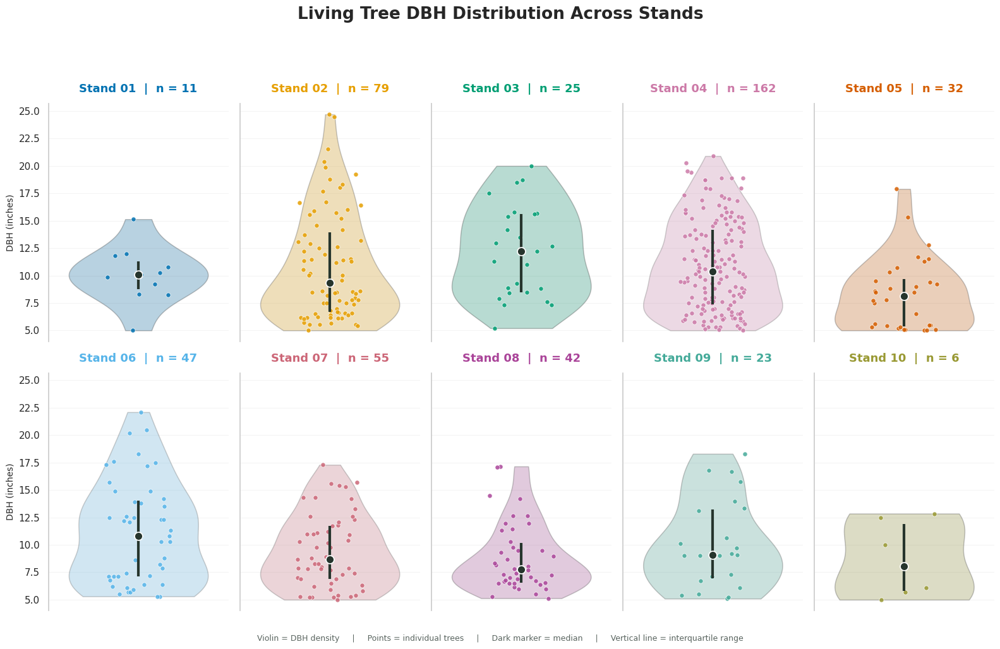

In [89]:
# ============================================================
# STEP 67
# ============================================================

# positioned inside their respective violin distributions.

# Import plotting and numerical libraries.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Retain the original ten-stand color palette.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',  # Additional stand color
    8: '#AA4499',  # Additional stand color
    9: '#44AA99',  # Additional stand color
    10: '#999933'  # Additional stand color
}

# Apply a clean plotting style.
sns.set_theme(style='whitegrid', context='notebook')

# Create ten panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 5,
    figsize=(16, 10),
    sharey=True
)

# Flatten the axes array for convenient iteration.
axes = axes.flatten()

# Loop through each stand.
for stand, ax in zip(range(1, 11), axes):

    # Extract the living-tree DBH observations for this stand.
    stand_data = live_trees_analysis.loc[
        live_trees_analysis['Stand ID'] == stand,
        'DBH (in)'
    ].dropna()

    # Convert the DBH observations into a numerical array.
    dbh_values = stand_data.to_numpy()

    # Retrieve the corresponding stand color.
    stand_color = stand_colors[stand]

    # Calculate the first quartile, median, and third quartile.
    q1 = np.percentile(dbh_values, 25)
    median = np.percentile(dbh_values, 50)
    q3 = np.percentile(dbh_values, 75)

    # Draw the violin distribution centered at horizontal position zero.
    sns.violinplot(
        y=dbh_values,
        x=np.zeros(len(dbh_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.1,
        width=0.85,
        ax=ax
    )

    # Make the violin slightly transparent so the individual
    # observations remain easy to distinguish.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Generate reproducible horizontal jitter.
    # The points will now be placed within the violin rather than outside it.
    rng = np.random.default_rng(seed=stand)

    jitter = rng.uniform(
        -0.20,
        0.20,
        size=len(dbh_values)
    )

    # Plot individual tree measurements inside the violin.
    ax.scatter(
        jitter,
        dbh_values,
        s=27,
        color=stand_color,
        edgecolor='white',
        linewidth=0.55,
        alpha=0.85,
        zorder=4
    )

    # Draw a vertical line representing the interquartile range.
    ax.vlines(
        0,
        q1,
        q3,
        color='#26352D',
        linewidth=3,
        zorder=5
    )

    # Mark the median DBH with a contrasting central point.
    ax.scatter(
        0,
        median,
        s=85,
        color='#26352D',
        edgecolor='white',
        linewidth=1.2,
        zorder=6
    )

    # Add the stand identifier and sample size.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(dbh_values)}',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=13
    )

    # Label the vertical axis with DBH units.
    ax.set_ylabel('DBH (inches)', fontsize=10)

    # Remove unnecessary horizontal axis ticks and labels.
    ax.set_xticks([])
    ax.set_xlim(-0.55, 0.55)

    # Add subtle horizontal gridlines.
    ax.grid(
        axis='y',
        alpha=0.20,
        linewidth=0.8
    )

    # Remove unnecessary plot borders.
    sns.despine(ax=ax, bottom=True)

# Add the overall figure title.
fig.suptitle(
    'Living Tree DBH Distribution Across Stands',
    fontsize=19,
    fontweight='bold',
    y=1.02
)


# Add a legend explaining the visual elements.
fig.text(
    0.5,
    0.015,
    'Violin = DBH density     |     '
    'Points = individual trees     |     '
    'Dark marker = median     |     '
    'Vertical line = interquartile range',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust spacing to prevent overlapping elements.
plt.tight_layout(rect=[0, 0.045, 1, 0.96])

# Export the updated figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.png',
    dpi=400,
    bbox_inches='tight'
)

# Export a PDF version for the final report.
fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.pdf',
    bbox_inches='tight'
)

# Display the updated figure.
plt.show()

In [91]:

# ============================================================
# STEP 68
# ============================================================

# Create a working copy of the living-tree dataset.
# This preserves the original live_trees_analysis dataframe.

crown_analysis = live_trees_analysis.copy()


# ------------------------------------------------------------
# 1. CHECK CROWN CLASS DATA COMPLETENESS
# ------------------------------------------------------------

print("Total living-tree observations:")
print(len(crown_analysis))

print("\nObservations with recorded crown class:")
print(crown_analysis['Crown Class Code'].notna().sum())

print("\nObservations missing crown class:")
print(crown_analysis['Crown Class Code'].isna().sum())


# ------------------------------------------------------------
# 2. REMOVE MISSING CROWN CLASS OBSERVATIONS
# ------------------------------------------------------------

# Missing crown classes are excluded rather than treated
# as an additional crown category.

crown_analysis = crown_analysis.dropna(
    subset=['Crown Class Code']
).copy()


# ------------------------------------------------------------
# 3. STANDARDIZE CROWN CLASS ORDER
# ------------------------------------------------------------

# Retain the crown class codes recorded in the dataset.
crown_order = sorted(
    crown_analysis['Crown Class Code'].unique()
)

print("\nCrown class categories:")
print(crown_order)


# ------------------------------------------------------------
# 4. CALCULATE CROWN CLASS COUNTS BY STAND
# ------------------------------------------------------------

# Generate a stand-by-crown-class frequency table.
crown_counts = pd.crosstab(
    crown_analysis['Stand ID'],
    crown_analysis['Crown Class Code']
)

# Ensure all ten stands are represented.
crown_counts = crown_counts.reindex(
    index=range(1, 11),
    fill_value=0
)

# Ensure all crown class columns are represented.
crown_counts = crown_counts.reindex(
    columns=crown_order,
    fill_value=0
)


# ------------------------------------------------------------
# 5. CALCULATE WITHIN-STAND CROWN CLASS PERCENTAGES
# ------------------------------------------------------------

# Calculate the percentage of living trees in each crown
# class relative to the total classified living trees in
# that stand.

crown_percentages = (
    crown_counts
    .div(
        crown_counts.sum(axis=1).replace(0, np.nan),
        axis=0
    )
    * 100
)


# ------------------------------------------------------------
# 6. DISPLAY CROWN CLASS COUNTS
# ------------------------------------------------------------

print("\nCROWN CLASS COUNTS BY STAND")

display(crown_counts)


# ------------------------------------------------------------
# 7. DISPLAY CROWN CLASS PERCENTAGES
# ------------------------------------------------------------

print("\nCROWN CLASS COMPOSITION BY STAND (%)")

display(
    crown_percentages.round(1)
)


# ------------------------------------------------------------
# 8. VERIFY SAMPLE SIZES
# ------------------------------------------------------------

crown_sample_sizes = crown_counts.sum(axis=1)

crown_sample_summary = pd.DataFrame({
    'Stand ID': range(1, 11),
    'Classified Living Trees': crown_sample_sizes.values
})

print("\nCLASSIFIED LIVING TREE SAMPLE SIZES")

display(crown_sample_summary)


Total living-tree observations:
482

Observations with recorded crown class:
478

Observations missing crown class:
4

Crown class categories:
['Codominant', 'Dominant', 'Intermdediate', 'Intermediate', 'Suppressed']

CROWN CLASS COUNTS BY STAND


Crown Class Code,Codominant,Dominant,Intermdediate,Intermediate,Suppressed
Stand ID,,,,,
1,3,3,0,1,4
2,45,17,0,10,7
3,15,3,0,3,0
4,84,22,0,38,18
5,13,4,0,7,8
6,18,7,0,21,1
7,24,10,0,13,8
8,14,11,1,16,0
9,6,6,0,10,1



CROWN CLASS COMPOSITION BY STAND (%)


Crown Class Code,Codominant,Dominant,Intermdediate,Intermediate,Suppressed
Stand ID,,,,,
1,27.3,27.3,0.0,9.1,36.4
2,57.0,21.5,0.0,12.7,8.9
3,71.4,14.3,0.0,14.3,0.0
4,51.9,13.6,0.0,23.5,11.1
5,40.6,12.5,0.0,21.9,25.0
6,38.3,14.9,0.0,44.7,2.1
7,43.6,18.2,0.0,23.6,14.5
8,33.3,26.2,2.4,38.1,0.0
9,26.1,26.1,0.0,43.5,4.3



CLASSIFIED LIVING TREE SAMPLE SIZES


,Stand ID,Classified Living Trees
0,1,11
1,2,79
2,3,21
3,4,162
4,5,32
5,6,47
6,7,55
7,8,42
8,9,23
9,10,6


Total living-tree observations:
482

Observations with recorded crown class:
478

Observations missing crown class:
4

Crown class categories:
['Codominant', 'Dominant', 'Intermdediate', 'Intermediate', 'Suppressed']

CROWN CLASS COUNTS BY STAND


Crown Class Code,Codominant,Dominant,Intermdediate,Intermediate,Suppressed
Stand ID,,,,,
1,3,3,0,1,4
2,45,17,0,10,7
3,15,3,0,3,0
4,84,22,0,38,18
5,13,4,0,7,8
6,18,7,0,21,1
7,24,10,0,13,8
8,14,11,1,16,0
9,6,6,0,10,1



CROWN CLASS COMPOSITION BY STAND (%)


Crown Class Code,Codominant,Dominant,Intermdediate,Intermediate,Suppressed
Stand ID,,,,,
1,27.3,27.3,0.0,9.1,36.4
2,57.0,21.5,0.0,12.7,8.9
3,71.4,14.3,0.0,14.3,0.0
4,51.9,13.6,0.0,23.5,11.1
5,40.6,12.5,0.0,21.9,25.0
6,38.3,14.9,0.0,44.7,2.1
7,43.6,18.2,0.0,23.6,14.5
8,33.3,26.2,2.4,38.1,0.0
9,26.1,26.1,0.0,43.5,4.3



CLASSIFIED LIVING TREE SAMPLE SIZES


,Stand ID,Classified Living Trees
0,1,11
1,2,79
2,3,21
3,4,162
4,5,32
5,6,47
6,7,55
7,8,42
8,9,23
9,10,6


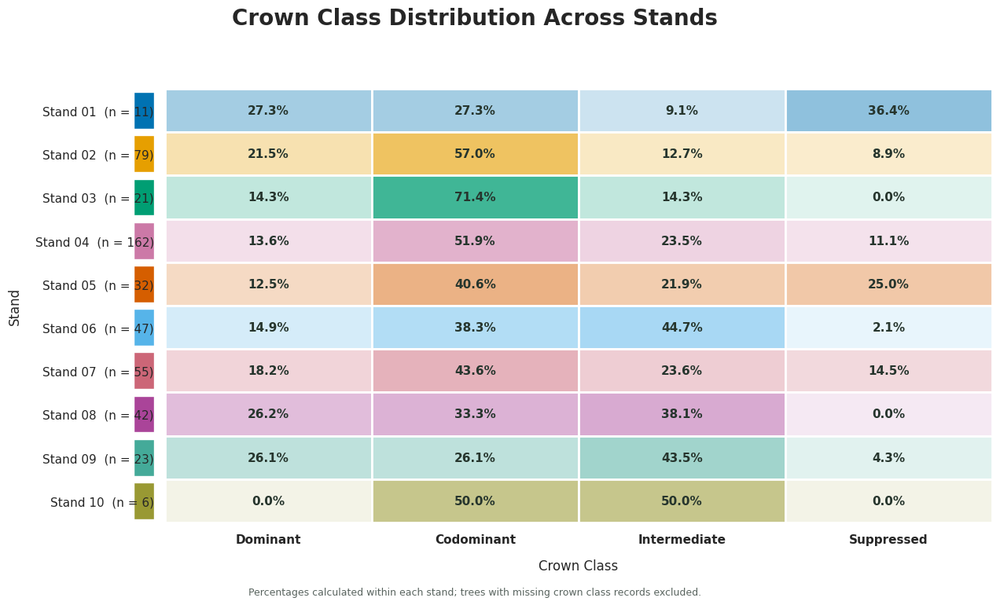

In [92]:

# ============================================================
# STEP 69
# ============================================================

# Create a working copy of the living-tree dataset.
# This preserves the original live_trees_analysis dataframe.

crown_analysis = live_trees_analysis.copy()


# ------------------------------------------------------------
# 1. CHECK CROWN CLASS DATA COMPLETENESS
# ------------------------------------------------------------

print("Total living-tree observations:")
print(len(crown_analysis))

print("\nObservations with recorded crown class:")
print(crown_analysis['Crown Class Code'].notna().sum())

print("\nObservations missing crown class:")
print(crown_analysis['Crown Class Code'].isna().sum())


# ------------------------------------------------------------
# 2. REMOVE MISSING CROWN CLASS OBSERVATIONS
# ------------------------------------------------------------

# Missing crown classes are excluded rather than treated
# as an additional crown category.

crown_analysis = crown_analysis.dropna(
    subset=['Crown Class Code']
).copy()


# ------------------------------------------------------------
# 3. STANDARDIZE CROWN CLASS ORDER
# ------------------------------------------------------------

# Retain the crown class codes recorded in the dataset.
crown_order = sorted(
    crown_analysis['Crown Class Code'].unique()
)

print("\nCrown class categories:")
print(crown_order)


# ------------------------------------------------------------
# 4. CALCULATE CROWN CLASS COUNTS BY STAND
# ------------------------------------------------------------

# Generate a stand-by-crown-class frequency table.
crown_counts = pd.crosstab(
    crown_analysis['Stand ID'],
    crown_analysis['Crown Class Code']
)

# Ensure all ten stands are represented.
crown_counts = crown_counts.reindex(
    index=range(1, 11),
    fill_value=0
)

# Ensure all crown class columns are represented.
crown_counts = crown_counts.reindex(
    columns=crown_order,
    fill_value=0
)


# ------------------------------------------------------------
# 5. CALCULATE WITHIN-STAND CROWN CLASS PERCENTAGES
# ------------------------------------------------------------

# Calculate the percentage of living trees in each crown
# class relative to the total classified living trees in
# that stand.

crown_percentages = (
    crown_counts
    .div(
        crown_counts.sum(axis=1).replace(0, np.nan),
        axis=0
    )
    * 100
)


# ------------------------------------------------------------
# 6. DISPLAY CROWN CLASS COUNTS
# ------------------------------------------------------------

print("\nCROWN CLASS COUNTS BY STAND")

display(crown_counts)


# ------------------------------------------------------------
# 7. DISPLAY CROWN CLASS PERCENTAGES
# ------------------------------------------------------------

print("\nCROWN CLASS COMPOSITION BY STAND (%)")

display(
    crown_percentages.round(1)
)


# ------------------------------------------------------------
# 8. VERIFY SAMPLE SIZES
# ------------------------------------------------------------

crown_sample_sizes = crown_counts.sum(axis=1)

crown_sample_summary = pd.DataFrame({
    'Stand ID': range(1, 11),
    'Classified Living Trees': crown_sample_sizes.values
})

print("\nCLASSIFIED LIVING TREE SAMPLE SIZES")

display(crown_sample_summary)


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

# Import matplotlib for figure construction.
import matplotlib.pyplot as plt

# Import color utilities for creating stand-specific gradients.
import matplotlib.colors as mcolors

# Import numpy for positioning heatmap cells.
import numpy as np


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLOR PALETTE
# ------------------------------------------------------------

# Preserve the colors established in the earlier project figures.
stand_colors = {
    1: '#0072B2',  # Stand 1: Blue
    2: '#E69F00',  # Stand 2: Orange
    3: '#009E73',  # Stand 3: Bluish green
    4: '#CC79A7',  # Stand 4: Reddish purple
    5: '#D55E00',  # Stand 5: Vermillion
    6: '#56B4E9',   # Stand 6: Sky blue,
    7: '#CC6677',  # Additional stand color
    8: '#AA4499',  # Additional stand color
    9: '#44AA99',  # Additional stand color
    10: '#999933'  # Additional stand color
}


# ------------------------------------------------------------
# 3. ORGANIZE THE CROWN CLASS DATA
# ------------------------------------------------------------

# Establish a consistent order for the four crown classes.
crown_order = [
    'Dominant',
    'Codominant',
    'Intermediate',
    'Suppressed'
]

# Arrange the percentage data by stand and crown class.
heatmap_data = crown_percentages.loc[
    [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    crown_order
].copy()

# Retrieve the number of observations used in each stand's
# crown class percentage calculations.
crown_sample_sizes = crown_counts.sum(axis=1)


# ------------------------------------------------------------
# 4. CREATE THE FIGURE LAYOUT
# ------------------------------------------------------------

# Create the overall figure.
fig = plt.figure(figsize=(14, 8))

# Divide the figure into two sections:
# a narrow stand-color strip and the main heatmap.
gs = fig.add_gridspec(
    1,
    2,
    width_ratios=[0.025, 1],
    wspace=0.025
)

# Create the stand-color identification axis.
color_ax = fig.add_subplot(gs[0])

# Create the main heatmap axis.
heat_ax = fig.add_subplot(gs[1])


# ------------------------------------------------------------
# 5. DRAW THE STAND COLOR IDENTIFICATION STRIP
# ------------------------------------------------------------

# Draw one colored rectangle for each stand.
for position, stand in enumerate(heatmap_data.index):

    color_ax.barh(
        position,
        1,
        color=stand_colors[stand],
        height=0.85
    )

# Align the color strip with the six heatmap rows.
color_ax.set_ylim(
    len(heatmap_data) - 0.5,
    -0.5
)

# Set the horizontal boundaries of the color strip.
color_ax.set_xlim(0, 1)

# Remove unnecessary axis elements.
color_ax.axis('off')


# ------------------------------------------------------------
# 6. CREATE THE STAND-SPECIFIC HEATMAP CELLS
# ------------------------------------------------------------

# Loop through each stand to create its individual color gradient.
for position, stand in enumerate(heatmap_data.index):

    # Convert the original stand color into RGB values.
    base_color = mcolors.to_rgb(stand_colors[stand])

    # Create a pale background shade of the stand color.
    pale_color = tuple(
        channel * 0.12 + 0.88
        for channel in base_color
    )

    # Create a gradient from the pale shade to the original color.
    stand_cmap = mcolors.LinearSegmentedColormap.from_list(
        f'stand_{stand}_gradient',
        [pale_color, stand_colors[stand]]
    )

    # Loop through the four crown classes.
    for column_position, crown_class in enumerate(crown_order):

        # Retrieve the percentage for the current stand and crown class.
        value = heatmap_data.loc[stand, crown_class]

        # Normalize the percentage to determine color intensity.
        intensity = value / 100

        # Retrieve the corresponding shade from the stand gradient.
        cell_color = stand_cmap(intensity)

        # Draw the heatmap cell.
        heat_ax.add_patch(
            plt.Rectangle(
                (column_position, position),
                1,
                1,
                facecolor=cell_color,
                edgecolor='white',
                linewidth=2
            )
        )

        # Calculate cell brightness to determine text contrast.
        luminance = (
            0.2126 * cell_color[0]
            + 0.7152 * cell_color[1]
            + 0.0722 * cell_color[2]
        )

        # Use white text on darker cells and dark text on lighter cells.
        text_color = (
            'white'
            if luminance < 0.58
            else '#26352D'
        )

        # Display the exact percentage in the center of the cell.
        heat_ax.text(
            column_position + 0.5,
            position + 0.5,
            f'{value:.1f}%',
            ha='center',
            va='center',
            fontsize=11,
            fontweight='bold',
            color=text_color
        )


# ------------------------------------------------------------
# 7. FORMAT THE HEATMAP AXES
# ------------------------------------------------------------

# Set the horizontal boundaries to include all four crown classes.
heat_ax.set_xlim(0, len(crown_order))

# Set the vertical boundaries to include all ten stands.
heat_ax.set_ylim(len(heatmap_data), 0)

# Position crown class labels at the center of each column.
heat_ax.set_xticks(
    np.arange(len(crown_order)) + 0.5
)

# Apply crown class names to the horizontal axis.
heat_ax.set_xticklabels(
    crown_order,
    fontsize=11,
    fontweight='bold'
)

# Create stand labels with their corresponding sample sizes.
stand_labels = [
    f'Stand {stand:02d}  (n = {crown_sample_sizes.loc[stand]})'
    for stand in heatmap_data.index
]

# Position stand labels at the center of each row.
heat_ax.set_yticks(
    np.arange(len(stand_labels)) + 0.5
)

# Apply the stand labels to the vertical axis.
heat_ax.set_yticklabels(
    stand_labels,
    fontsize=11
)

# Label the horizontal axis.
heat_ax.set_xlabel(
    'Crown Class',
    fontsize=12,
    labelpad=12
)

# Use the simplified vertical axis label.
heat_ax.set_ylabel(
    'Stand',
    fontsize=12,
    labelpad=12
)

# Remove unnecessary tick marks and adjust label spacing.
heat_ax.tick_params(
    axis='both',
    length=0,
    pad=10
)

# Remove surrounding plot borders.
for spine in heat_ax.spines.values():
    spine.set_visible(False)


# ------------------------------------------------------------
# 8. ADD THE FIGURE TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the simplified main figure title.
fig.suptitle(
    'Crown Class Distribution Across Stands',
    fontsize=20,
    fontweight='bold',
    y=0.97
)


# ------------------------------------------------------------
# 9. ADD THE METHODOLOGICAL FOOTNOTE
# ------------------------------------------------------------

# Explain how percentages were calculated and how missing
# crown class observations were handled.
fig.text(
    0.5,
    0.035,
    'Percentages calculated within each stand; trees with missing crown class records excluded.',
    ha='center',
    fontsize=9,
    color='#59645F'
)


# ------------------------------------------------------------
# 10. FINALIZE THE FIGURE LAYOUT
# ------------------------------------------------------------

# Adjust margins to accommodate the title, subtitle,
# axis labels, and methodological footnote.
fig.subplots_adjust(
    left=0.19,
    right=0.97,
    top=0.84,
    bottom=0.15
)


# ------------------------------------------------------------
# 11. EXPORT THE FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
fig.savefig(
    export_dir / 'Crown_Class_Composition_Heatmap.png',
    dpi=400,
    bbox_inches='tight'
)

# Save a PDF version for the final ecological report.
fig.savefig(
    export_dir / 'Crown_Class_Composition_Heatmap.pdf',
    bbox_inches='tight'
)


# ------------------------------------------------------------
# 12. DISPLAY THE COMPLETED FIGURE
# ------------------------------------------------------------

# Display the final heatmap in the notebook.
plt.show()

In [93]:
# ============================================================
# STEP 70
# ============================================================


# ------------------------------------------------------------
# 1. CHECK HEIGHT DATA COMPLETENESS
# ------------------------------------------------------------

# Count the total number of living-tree observations.
print("Total living-tree observations:", len(live_trees_analysis))

# Count observations with recorded height in feet.
print(
    "Records with height measurements:",
    live_trees_analysis['Estimated Tree Height (ft)'].notna().sum()
)

# Count observations missing height measurements.
print(
    "Records missing height measurements:",
    live_trees_analysis['Estimated Tree Height (ft)'].isna().sum()
)

# Display the first five height observations for verification.
display(
    live_trees_analysis[
        ['Stand ID', 'Species Name', 'DBH (in)', 'Estimated Tree Height (ft)']
    ].head()
)


# ------------------------------------------------------------
# 2. CALCULATE HEIGHT SUMMARY STATISTICS BY STAND
# ------------------------------------------------------------

# Group living-tree observations by stand and calculate
# descriptive statistics for estimated tree height in feet.
live_height_summary = (
    live_trees_analysis
    .groupby('Stand ID')['Estimated Tree Height (ft)']
    .agg(
        Sample_Size='count',
        Mean_Height='mean',
        Median_Height='median',
        Standard_Deviation='std',
        Minimum='min',
        First_Quartile=lambda x: x.quantile(0.25),
        Third_Quartile=lambda x: x.quantile(0.75),
        Maximum='max'
    )
    .reset_index()
)

# Round the results to two decimal places for readability.
live_height_summary = live_height_summary.round(2)

# Display the height summary table.
print("\nLiving-tree height statistics by stand (feet):")
display(live_height_summary)

Total living-tree observations: 482
Records with height measurements: 482
Records missing height measurements: 0


,Stand ID,Species Name,DBH (in),Estimated Tree Height (ft)
0,1,Yellow Birch,8.30,82.020998
1,1,Eastern Hemlock,8.25,32.808399
2,1,Eastern Hemlock,11.80,18.044619
3,1,Eastern Hemlock,10.80,39.370079
4,1,Yellow Birch,11.99,34.448819



Living-tree height statistics by stand (feet):


,Stand ID,Sample_Size,Mean_Height,Median_Height,Standard_Deviation,Minimum,First_Quartile,Third_Quartile,Maximum
0,1,11,60.13,45.93,40.37,18.04,36.42,71.03,157.84
1,2,79,60.69,48.39,31.00,22.47,40.80,74.48,182.28
2,3,25,47.24,43.18,13.39,28.71,34.78,56.10,73.49
3,4,162,44.56,37.89,19.94,12.14,30.65,58.97,126.48
4,5,32,34.82,32.32,14.36,11.48,24.61,44.82,69.55
5,6,47,42.80,42.65,16.18,18.54,30.18,54.13,76.61
6,7,55,40.68,39.37,12.22,20.01,30.68,50.69,75.07
7,8,42,40.21,41.60,11.34,19.36,31.17,48.65,67.26
8,9,23,35.56,31.17,15.96,18.04,25.34,39.37,75.13
9,10,6,36.01,34.02,12.16,24.08,26.10,43.13,54.30


In [94]:
# ============================================================
# STEP 71
# ============================================================


# ------------------------------------------------------------
# 1. CHECK CONVERSION CONSISTENCY
# ------------------------------------------------------------

# Calculate the expected height in feet from the recorded
# height in meters using the standard conversion factor.
live_trees_analysis['Calculated Height (ft)'] = (
    live_trees_analysis['Estimated Tree Height (m)'] * 3.28084
)

# Calculate the difference between the recorded and calculated
# height in feet.
live_trees_analysis['Height Difference (ft)'] = (
    live_trees_analysis['Estimated Tree Height (ft)']
    - live_trees_analysis['Calculated Height (ft)']
)

# Display the largest absolute conversion difference.
print("Largest difference between recorded and calculated feet:")
print(
    live_trees_analysis['Height Difference (ft)']
    .abs()
    .max()
)


# ------------------------------------------------------------
# 2. IDENTIFY THE 15 TALLEST LIVING TREES
# ------------------------------------------------------------

# Sort living trees from tallest to shortest using the recorded
# height in feet.
tallest_trees = (
    live_trees_analysis
    .sort_values(
        by='Estimated Tree Height (ft)',
        ascending=False
    )
    .head(15)
)

# Select the fields needed to investigate the tallest observations.
tallest_trees_review = tallest_trees[
    [
        'Stand ID',
        'Plot ID',
        'Subplot ID',
        'Species Name',
        'DBH (in)',
        'Estimated Tree Height (m)',
        'Estimated Tree Height (ft)',
        'Height Difference (ft)'
    ]
].round(2)

# Display the 15 tallest trees.
print("\nFifteen tallest living trees:")
display(tallest_trees_review)


# ------------------------------------------------------------
# 3. SUMMARIZE HEIGHT EXTREMES BY STAND
# ------------------------------------------------------------

# Calculate the maximum recorded height for each stand.
height_maximums = (
    live_trees_analysis
    .groupby('Stand ID')['Estimated Tree Height (ft)']
    .max()
    .reset_index(name='Maximum Height (ft)')
)

# Display the maximum height recorded in each stand.
print("\nMaximum living-tree height by stand:")
display(height_maximums.round(2))

Largest difference between recorded and calculated feet:
0.003150800000000231

Fifteen tallest living trees:


,Stand ID,Plot ID,Subplot ID,Species Name,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Height Difference (ft)
14,2,1,3,White Oak,10.52,55.56,182.28,-0.0
5,1,1,1,Red Maple,15.14,48.11,157.84,-0.0
35,2,2,2,White Oak,6.21,42.45,139.27,-0.0
69,2,3,5,Eastern Hemlock,20.38,40.80,133.86,-0.0
27,2,2,2,White Ash,13.21,40.65,133.37,-0.0
23,2,2,1,White Oak,19.89,39.85,130.74,-0.0
70,2,3,5,White Birch,12.90,38.75,127.13,-0.0
158,4,1,6,Northern Red Oak,17.90,38.55,126.48,-0.0
155,4,1,6,Northern Red Oak,13.25,33.70,110.56,-0.0
8,1,1,1,Sugar Maple,10.10,31.50,103.35,-0.0



Maximum living-tree height by stand:


,Stand ID,Maximum Height (ft)
0,1,157.84
1,2,182.28
2,3,73.49
3,4,126.48
4,5,69.55
5,6,76.61
6,7,75.07
7,8,67.26
8,9,75.13
9,10,54.30


In [95]:
# ============================================================
# STEP 72
# ============================================================

# ------------------------------------------------------------
# 1. IDENTIFY THE ORIGINAL WORKSHEET
# ------------------------------------------------------------

# Read the original woody species worksheet from the workbook.
# We use header=None initially so that we can inspect the original
# worksheet labels and instructions without assuming their row positions.
original_woody_sheet = pd.read_excel(
    workbook,
    sheet_name='Subplot Woody Species Data',
    header=None
)

# ------------------------------------------------------------
# 2. SEARCH FOR HEIGHT-RELATED LABELS
# ------------------------------------------------------------

# Search every cell in the worksheet for labels containing "height".
# This may identify measurement units, instructions, or column headings.
height_references = []

for row_index in range(len(original_woody_sheet)):

    # Examine every column in the current row.
    for column_index in range(original_woody_sheet.shape[1]):

        # Retrieve the cell value.
        cell_value = original_woody_sheet.iloc[row_index, column_index]

        # Check whether the cell contains the word "height".
        if pd.notna(cell_value) and 'height' in str(cell_value).lower():

            # Record the row, column, and original cell value.
            height_references.append({
                'Row': row_index,
                'Column': column_index,
                'Cell Value': cell_value
            })

# Convert the search results into a DataFrame.
height_reference_df = pd.DataFrame(height_references)

# Display all height-related labels and instructions.
print("Original workbook height references:")
display(height_reference_df)


# ------------------------------------------------------------
# 3. DISPLAY THE ORIGINAL WORKSHEET HEADER AREA
# ------------------------------------------------------------

# Display the first 12 rows of the original worksheet.
# This helps us see whether the workbook specifies feet or meters
# in its column headings or measurement instructions.
print("\nOriginal worksheet header and instruction area:")
display(original_woody_sheet.head(12))

Original workbook height references:


,Row,Column,Cell Value
0,0,9,Estimated Tree Height (m)
1,0,10,Estimated Tree Height (ft)
2,245,14,Protrusion at breast height
3,367,14,Height is off



Original worksheet header and instruction area:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes
1,1,1,1,2026-10-23 00:00:00,"EJ, TQ",1,YB,AL,8.3,25,82.020998,Dominant,NaN,NaN,NaN
2,1,1,1,2026-10-23 00:00:00,"EJ, TQ",2,EH,AL,8.25,10,32.808399,Suppressed,NaN,NaN,NaN
3,1,1,1,2026-10-23 00:00:00,"LW, AB, HB",3,AB,DA,13.52,13.5,44.291339,Dominant,20,NaN,Base of trunk split
4,1,1,1,2026-10-23 00:00:00,"EC, HP, AB, LW",4,AB,DA,5.98,10,32.808399,Codominant,20,NaN,Bark split
5,1,1,1,2026-10-23 00:00:00,"JW, JR, HP",5,EH,AL,11.8,5.5,18.044619,Overtopped,NaN,NaN,NaN
6,1,1,1,2026-10-23 00:00:00,"JW, JR, JM, HP",6,AB,DA,5.73,25.5,83.661417,Codominant,20,NaN,Bark split
7,1,1,1,2026-10-23 00:00:00,"JW, JR, JM, HP",7,EH,AL,10.8,12,39.370079,Suppressed,NaN,NaN,NaN
8,1,1,1,2026-10-23 00:00:00,"JW, JR, JM, HP, EC, AB, LA, LW",8,YB,AL,11.99,10.5,34.448819,Codominant,NaN,NaN,NaN
9,1,1,1,2026-10-23 00:00:00,"JW, JR, JM, HP, EC, AB, LA, LW",9,AB,DA,9.2,8.3,27.230971,Suppressed,20,NaN,Beech bark disease


In [96]:
# ============================================================
# STEP 73
# ============================================================


# Create a separate DataFrame containing living trees taller than 100 feet.
# The original height measurements remain unchanged.
unusual_height_records = live_trees_analysis[
    live_trees_analysis['Estimated Tree Height (ft)'] > 100
].copy()

# Sort the flagged observations from tallest to shortest.
unusual_height_records = unusual_height_records.sort_values(
    'Estimated Tree Height (ft)',
    ascending=False
)

# Select the fields needed to investigate each observation.
height_review = unusual_height_records[
    [
        'Stand ID',
        'Plot ID',
        'Subplot ID',
        'Tree ID',
        'Species Name',
        'DBH (in)',
        'Estimated Tree Height (m)',
        'Estimated Tree Height (ft)'
    ]
].copy()

# Round measurements for easier inspection.
height_review = height_review.round(2)

# Display the flagged observations.
print("Living trees taller than 100 feet:")
display(height_review)

# Count how many observations exceeded the screening threshold.
print("\nNumber of flagged observations:", len(height_review))

# Display the number of flagged observations in each stand.
print("\nFlagged observations by stand:")
display(
    unusual_height_records.groupby('Stand ID')
    .size()
    .reset_index(name='Number of Trees')
)

Living trees taller than 100 feet:


,Stand ID,Plot ID,Subplot ID,Tree ID,Species Name,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft)
14,2,1,3,26.0,White Oak,10.52,55.56,182.28
5,1,1,1,10.0,Red Maple,15.14,48.11,157.84
35,2,2,2,9.0,White Oak,6.21,42.45,139.27
69,2,3,5,2.0,Eastern Hemlock,20.38,40.80,133.86
27,2,2,2,1.0,White Ash,13.21,40.65,133.37
23,2,2,1,4.0,White Oak,19.89,39.85,130.74
70,2,3,5,3.0,White Birch,12.90,38.75,127.13
158,4,1,6,11.0,Northern Red Oak,17.90,38.55,126.48
155,4,1,6,8.0,Northern Red Oak,13.25,33.70,110.56
8,1,1,1,13.0,Sugar Maple,10.10,31.50,103.35



Number of flagged observations: 12

Flagged observations by stand:


,Stand ID,Number of Trees
0,1,2
1,2,6
2,4,4


In [97]:
# ============================================================
# STEP 74
# ============================================================

# the living-tree height visualization.
#
# IMPORTANT:
# - The original woody_analysis DataFrame remains unchanged.
# - The live_trees_analysis DataFrame remains unchanged.
# - Only the new height_visualization_df excludes the 12 flagged records.
# - These observations are not deleted from the project dataset.

# ------------------------------------------------------------
# 1. CREATE A WORKING DATAFRAME WITHOUT THE FLAGGED RECORDS
# ------------------------------------------------------------

# Identify the unique tree records that exceeded the 100-foot
# screening threshold using their stand, plot, subplot, and tree IDs.
flagged_tree_keys = unusual_height_records[
    ['Stand ID', 'Plot ID', 'Subplot ID', 'Tree ID']
].drop_duplicates()

# Create a copy of the living-tree dataset for height visualization.
height_visualization_df = live_trees_analysis.copy()

# Exclude records matching all four identifiers in flagged_tree_keys.
# The original living-tree dataset is not modified.
height_visualization_df = height_visualization_df.merge(
    flagged_tree_keys.assign(Exclude=True),
    on=['Stand ID', 'Plot ID', 'Subplot ID', 'Tree ID'],
    how='left'
)

# Retain only observations that were not flagged.
height_visualization_df = height_visualization_df[
    height_visualization_df['Exclude'].isna()
].drop(columns='Exclude').copy()

# ------------------------------------------------------------
# 2. VERIFY THE FILTERED DATASET
# ------------------------------------------------------------

# Display the number of living trees before and after exclusion.
print("Living trees before exclusion:", len(live_trees_analysis))
print("Living trees excluded:", len(flagged_tree_keys))
print("Living trees remaining:", len(height_visualization_df))

# Confirm that no observations above 100 feet remain.
print(
    "\nRemaining observations above 100 feet:",
    (height_visualization_df['Estimated Tree Height (ft)'] > 100).sum()
)

# Summarize the remaining height observations by stand.
height_visualization_summary = (
    height_visualization_df
    .groupby('Stand ID')['Estimated Tree Height (ft)']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
    .reset_index()
)

display(height_visualization_summary)

Living trees before exclusion: 482
Living trees excluded: 12
Living trees remaining: 470

Remaining observations above 100 feet: 0


,Stand ID,count,mean,median,min,max
0,1,9,44.47,39.37,18.04,82.02
1,2,73,54.08,47.83,22.47,96.78
2,3,25,47.24,43.18,28.71,73.49
3,4,158,42.89,37.57,12.14,91.21
4,5,32,34.82,32.32,11.48,69.55
5,6,47,42.80,42.65,18.54,76.61
6,7,55,40.68,39.37,20.01,75.07
7,8,42,40.21,41.60,19.36,67.26
8,9,23,35.56,31.17,18.04,75.13
9,10,6,36.01,34.02,24.08,54.30


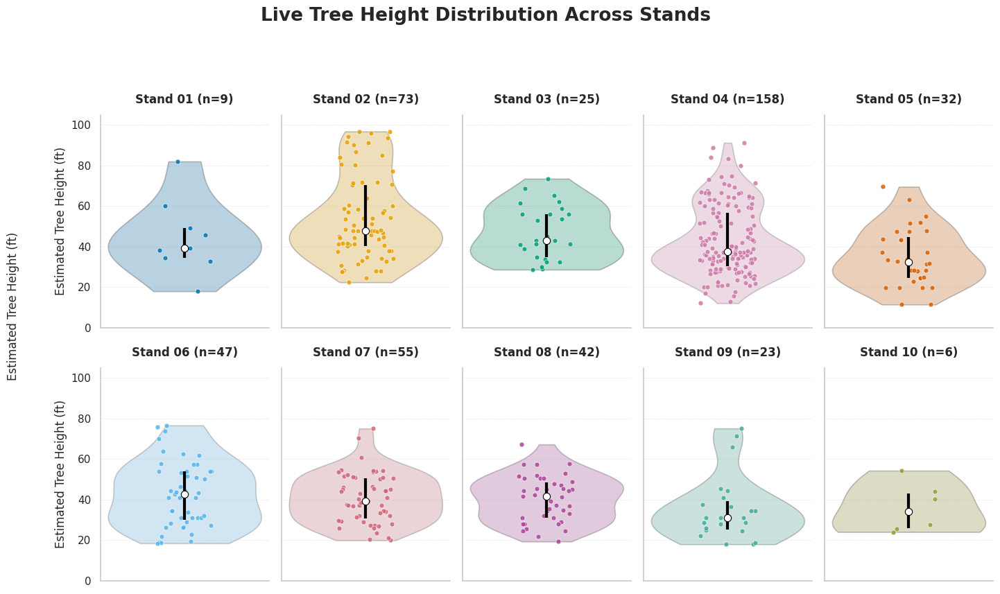

In [98]:
# ============================================================
# STEP 75
# ============================================================

# distribution figure with semi-transparent violin plots.
#
# This figure uses the filtered height_visualization_df dataset,
# which excludes the 12 unusually tall observations temporarily.
#
# Visual elements:
# - Violin distributions: 30% opacity
# - Individual tree observations: 85% opacity
# - White median marker
# - Black interquartile range (IQR) line
# - Original ten-stand color palette

# ------------------------------------------------------------
# 1. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a figure with ten panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    nrows=2,
    ncols=5,
    figsize=(15, 9),
    sharey=True
)

# Flatten the axes array so each stand can be assigned to one panel.
axes = axes.flatten()

# Set a consistent random seed so horizontal point jitter is reproducible.
np.random.seed(42)


# ------------------------------------------------------------
# 2. CREATE THE HEIGHT DISTRIBUTION PANELS
# ------------------------------------------------------------

# Loop through the ten stands and their corresponding plotting panels.
for stand, ax in zip(included_stands, axes):

    # Select living-tree observations belonging to the current stand.
    stand_data = height_visualization_df[
        height_visualization_df['Stand ID'] == stand
    ]

    # Extract estimated tree heights in feet and remove missing values.
    heights = stand_data['Estimated Tree Height (ft)'].dropna()

    # Retrieve the established color assigned to this stand.
    stand_color = stand_colors[stand]

    # Draw the violin plot to represent the distribution of tree heights.
    # cut=0 keeps the violin within the observed measurement range.
    # inner=None removes the default internal summary statistics.
    sns.violinplot(
        y=heights,
        ax=ax,
        color=stand_color,
        inner=None,
        cut=0,
        width=0.65,
        linewidth=1.2
    )

    # Apply 30% opacity to the violin distribution.
    # This matches the transparency used in the approved DBH figure.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Generate small horizontal offsets to prevent individual points
    # from overlapping exactly.
    jitter = np.random.uniform(
        -0.12,
        0.12,
        size=len(heights)
    )

    # Plot individual tree height measurements inside the violin.
    ax.scatter(
        jitter,
        heights,
        color=stand_color,
        edgecolor='white',
        linewidth=0.5,
        alpha=0.85,
        s=25,
        zorder=3
    )

    # Calculate the first quartile, median, and third quartile.
    q1 = heights.quantile(0.25)
    median = heights.median()
    q3 = heights.quantile(0.75)

    # Draw a black vertical line representing the interquartile range.
    ax.vlines(
        x=0,
        ymin=q1,
        ymax=q3,
        color='black',
        linewidth=3,
        zorder=4
    )

    # Add a white marker representing the median tree height.
    ax.scatter(
        0,
        median,
        color='white',
        edgecolor='black',
        linewidth=0.8,
        s=55,
        zorder=5
    )

    # Add the stand number and sample size to the panel heading.
    ax.set_title(
        f'Stand {stand:02d} (n={len(heights)})',
        fontsize=12,
        fontweight='bold',
        pad=12
    )

    # Remove unnecessary horizontal-axis ticks and labels.
    ax.set_xticks([])
    ax.set_xlabel('')

    # Add subtle horizontal gridlines to support height comparisons.
    ax.grid(
        axis='y',
        linestyle='--',
        linewidth=0.6,
        alpha=0.35
    )

    # Keep gridlines behind the plotted observations.
    ax.set_axisbelow(True)

    # Remove the top and right borders for a cleaner appearance.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


# ------------------------------------------------------------
# 3. ADD FIGURE TITLES AND AXIS LABELS
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Live Tree Height Distribution Across Stands',
    fontsize=19,
    fontweight='bold',
    y=0.98
)


# Add a shared vertical-axis label.
fig.supylabel(
    'Estimated Tree Height (ft)',
    fontsize=12,
    x=0.04
)

# Apply the same vertical-axis limits to every panel.
axes[0].set_ylim(0, 105)

# Adjust spacing to prevent titles and labels from overlapping.
plt.tight_layout(
    rect=[0.05, 0.03, 1, 0.91]
)


# ------------------------------------------------------------
# 4. SAVE AND DISPLAY THE FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG for reports and presentations.
plt.savefig(
    export_dir / 'Living_Tree_Height_Raincloud.png',
    dpi=300,
    bbox_inches='tight'
)

# Save a PDF version for publication-quality output.
plt.savefig(
    export_dir / 'Living_Tree_Height_Raincloud.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


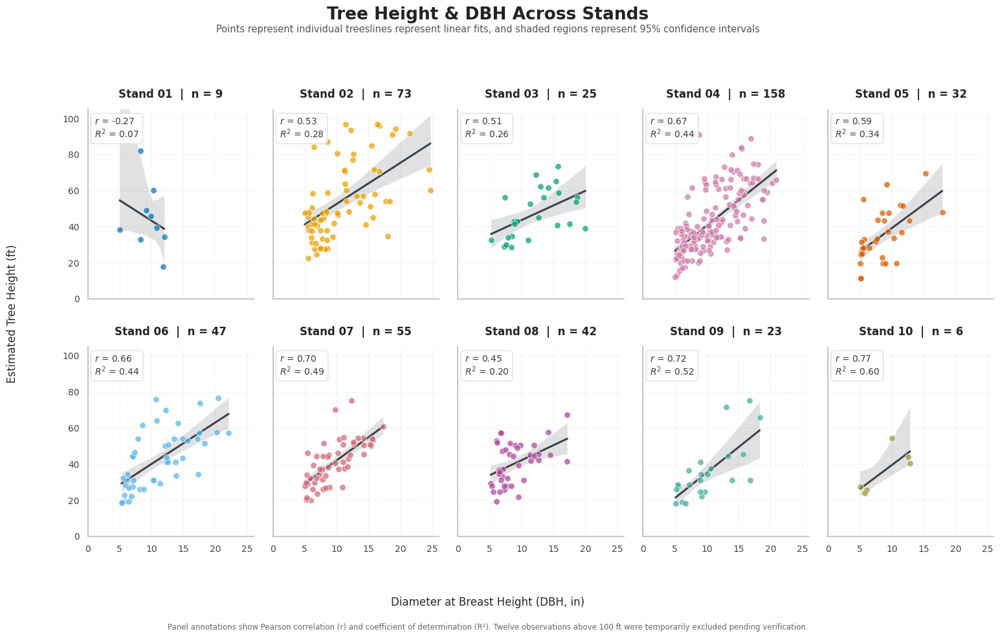

In [99]:
# ============================================================
# STEP 76
# ============================================================

#
# Improvements:
# - One shared x-axis label across the entire figure.
# - One shared y-axis label across the entire figure.
# - No repeated axis labels within individual panels.
# - Original stand-specific colors.
# - Semi-transparent individual observations.
# - Linear regression lines with 95% confidence intervals.
# - Pearson correlation and R-squared annotations.
# - Consistent axes and publication-style formatting.

# ------------------------------------------------------------
# 1. IMPORT STATISTICAL FUNCTIONS
# ------------------------------------------------------------

# Import Pearson correlation to quantify the linear association
# between DBH and estimated tree height within each stand.
from scipy.stats import pearsonr


# ------------------------------------------------------------
# 2. SET UP THE FIGURE
# ------------------------------------------------------------

# Create ten panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 5,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

# Flatten the axes array to simplify iteration.
axes = axes.flatten()

# Set a reproducible random seed.
np.random.seed(42)

# Define a dark neutral color for regression lines.
regression_color = '#343A40'


# ------------------------------------------------------------
# 3. CREATE THE SIX STAND PANELS
# ------------------------------------------------------------

# Loop through the ten stands and their corresponding panels.
for stand, ax in zip(included_stands, axes):

    # Select observations belonging to the current stand.
    stand_data = height_visualization_df[
        height_visualization_df['Stand ID'] == stand
    ].copy()

    # Remove observations missing either DBH or estimated height.
    stand_data = stand_data.dropna(
        subset=[
            'DBH (in)',
            'Estimated Tree Height (ft)'
        ]
    )

    # Extract DBH measurements.
    dbh = stand_data['DBH (in)']

    # Extract estimated tree heights.
    height = stand_data['Estimated Tree Height (ft)']

    # Retrieve the established color for the current stand.
    stand_color = stand_colors[stand]

    # --------------------------------------------------------
    # 3A. PLOT INDIVIDUAL TREE OBSERVATIONS
    # --------------------------------------------------------

    # Plot individual trees using their stand-specific color.
    # Transparency helps reveal overlapping observations.
    ax.scatter(
        dbh,
        height,
        color=stand_color,
        alpha=0.72,
        edgecolor='white',
        linewidth=0.75,
        s=48,
        zorder=3
    )

    # --------------------------------------------------------
    # 3B. ADD LINEAR REGRESSION AND 95% CONFIDENCE INTERVAL
    # --------------------------------------------------------

    # Fit a linear regression line and display its 95% confidence
    # interval around the estimated mean relationship.
    sns.regplot(
        data=stand_data,
        x='DBH (in)',
        y='Estimated Tree Height (ft)',
        scatter=False,
        ci=95,
        n_boot=1000,
        color=regression_color,
        line_kws={
            'linewidth': 2.2,
            'alpha': 0.95
        },
        ax=ax
    )

    # --------------------------------------------------------
    # 3C. CALCULATE AND ANNOTATE CORRELATION STATISTICS
    # --------------------------------------------------------

    # Calculate Pearson's correlation when there are enough
    # observations and variation in both variables.
    if (
        len(stand_data) >= 3
        and dbh.nunique() > 1
        and height.nunique() > 1
    ):

        # Calculate Pearson's correlation coefficient and p-value.
        r_value, p_value = pearsonr(dbh, height)

        # Calculate the coefficient of determination.
        r_squared = r_value ** 2

        # Format the statistical annotation.
        annotation = (
            f'$r$ = {r_value:.2f}\n'
            f'$R^2$ = {r_squared:.2f}'
        )

    else:

        # Report insufficient variation if the relationship
        # cannot be calculated reliably.
        annotation = 'Insufficient variation'

    # Position the statistical annotation in the upper-left corner.
    ax.text(
        0.04,
        0.96,
        annotation,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=10,
        color='#343A40',
        bbox={
            'boxstyle': 'round,pad=0.4',
            'facecolor': 'white',
            'edgecolor': '#D9DDE1',
            'alpha': 0.90
        }
    )

    # --------------------------------------------------------
    # 3D. FORMAT EACH PANEL
    # --------------------------------------------------------

    # Add the stand identifier and sample size.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(stand_data)}',
        fontsize=12,
        fontweight='bold',
        pad=13,
        color='#252525'
    )

    # Remove individual axis labels because shared labels
    # will be added to the overall figure.
    ax.set_xlabel('')
    ax.set_ylabel('')

    # Add subtle gridlines.
    ax.grid(
        True,
        linestyle=':',
        linewidth=0.65,
        color='#BFC5CA',
        alpha=0.55
    )

    # Keep gridlines behind the observations.
    ax.set_axisbelow(True)

    # Remove the top and right borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Soften the remaining axis borders.
    ax.spines['left'].set_color('#B8BEC4')
    ax.spines['bottom'].set_color('#B8BEC4')

    # Standardize tick label appearance.
    ax.tick_params(
        axis='both',
        labelsize=10,
        colors='#444444'
    )


# ------------------------------------------------------------
# 4. APPLY CONSISTENT AXIS LIMITS AND TICKS
# ------------------------------------------------------------

# Use identical DBH limits across all ten panels.
axes[0].set_xlim(0, 26)

# Use identical tree-height limits across all ten panels.
axes[0].set_ylim(0, 105)

# Apply consistent DBH tick intervals.
for ax in axes:
    ax.set_xticks(np.arange(0, 27, 5))

# Apply consistent height tick intervals.
for ax in axes:
    ax.set_yticks(np.arange(0, 101, 20))


# ------------------------------------------------------------
# 5. ADD FIGURE TITLE AND SHARED AXIS LABELS
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Tree Height & DBH Across Stands',
    fontsize=19,
    fontweight='bold',
    color='#222222',
    y=0.975
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.935,
    'Points represent individual trees'
    'lines represent linear fits, and shaded regions represent 95% confidence intervals',
    ha='center',
    fontsize=10.5,
    color='#555555'
)

# Add one shared horizontal-axis label.
fig.supxlabel(
    'Diameter at Breast Height (DBH, in)',
    fontsize=12,
    fontweight='medium',
    y=0.045
)

# Add one shared vertical-axis label.
fig.supylabel(
    'Estimated Tree Height (ft)',
    fontsize=12,
    fontweight='medium',
    x=0.035
)


# ------------------------------------------------------------
# 6. ADD THE FIGURE FOOTNOTE
# ------------------------------------------------------------

# Explain the statistical annotations and temporary exclusions.
fig.text(
    0.5,
    0.012,
    'Panel annotations show Pearson correlation (r) and coefficient of determination (R²). '
    'Twelve observations above 100 ft were temporarily excluded pending verification.',
    ha='center',
    fontsize=8.5,
    color='#666666'
)


# ------------------------------------------------------------
# 7. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust spacing to accommodate the shared labels and footnote.
plt.tight_layout(
    rect=[0.055, 0.075, 1, 0.91],
    h_pad=2.0,
    w_pad=1.5
)

# Save the high-resolution PNG.
plt.savefig(
    export_dir / 'Tree_Height_DBH_Relationship_Refined.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

# Save the publication-quality PDF.
plt.savefig(
    export_dir / 'Tree_Height_DBH_Relationship_Refined.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()


In [100]:
# ============================================================
# STEP 77
# ============================================================
#
# Basal area represents the cross-sectional area of a tree stem
# at breast height (4.5 feet above the ground).
#
# DBH is recorded in inches.
# Basal area will be calculated in square feet per tree.
#
# This step creates a separate working DataFrame and does not
# modify the original woody species dataset.

# ------------------------------------------------------------
# 1. CREATE A WORKING COPY
# ------------------------------------------------------------

# Copy the living-tree dataset so the original analysis data
# remains unchanged.
basal_area_analysis = live_trees_analysis.copy()

# ------------------------------------------------------------
# 2. CALCULATE INDIVIDUAL TREE BASAL AREA
# ------------------------------------------------------------

# Calculate basal area using DBH in inches.
# Dividing by 576 converts the squared-inch measurement
# into square feet.
basal_area_analysis['Basal Area (sq ft)'] = (
    np.pi * basal_area_analysis['DBH (in)']**2 / 576
)

# ------------------------------------------------------------
# 3. SUMMARIZE BASAL AREA BY STAND
# ------------------------------------------------------------

# Group individual tree measurements by stand.
# Calculate the number of trees, mean basal area, median
# basal area, and total sampled basal area.
basal_area_summary = (
    basal_area_analysis
    .groupby('Stand ID')['Basal Area (sq ft)']
    .agg(
        Tree_Count='count',
        Mean_Basal_Area='mean',
        Median_Basal_Area='median',
        Total_Basal_Area='sum'
    )
    .round(3)
    .reset_index()
)

# ------------------------------------------------------------
# 4. DISPLAY THE RESULTS
# ------------------------------------------------------------

# Display the stand-level basal area summary.
display(basal_area_summary)


,Stand ID,Tree_Count,Mean_Basal_Area,Median_Basal_Area,Total_Basal_Area
0,1,11,0.585,0.556,6.438
1,2,79,0.776,0.478,61.302
2,3,25,0.900,0.812,22.506
3,4,162,0.746,0.587,120.847
4,5,32,0.431,0.363,13.787
5,6,47,0.800,0.636,37.579
6,7,55,0.549,0.413,30.187
7,8,42,0.475,0.328,19.944
8,9,23,0.642,0.452,14.772
9,10,6,0.469,0.374,2.815


In [101]:
# ============================================================
# STEP 78
# ============================================================
# sampling dimensions needed for basal area per acre.
#
# We need to establish the area sampled for each subplot
# before converting sampled basal area into a per-acre estimate.

# ------------------------------------------------------------
# 1. INSPECT SUBPLOT METADATA COLUMNS
# ------------------------------------------------------------

# Display the available fields in the subplot metadata.
print("Subplot metadata columns:")
print(subplot_metadata_analysis.columns.tolist())

# ------------------------------------------------------------
# 2. DISPLAY SUBPLOT METADATA RECORDS
# ------------------------------------------------------------

# Display the first 15 records to inspect the sampling design.
display(subplot_metadata_analysis.head(15))

# ------------------------------------------------------------
# 3. INSPECT PLOT METADATA
# ------------------------------------------------------------

# Display the available fields in the plot metadata.
print("Plot metadata columns:")
print(plot_metadata_analysis.columns.tolist())

# Display the first 10 plot metadata records.
display(plot_metadata_analysis.head(10))


Subplot metadata columns:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Elevation (ft)', 'Slope (%)', 'Aspect', 'Dominant Cover Code', 'Notes']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Elevation (ft),Slope (%),Aspect,Dominant Cover Code,Notes
0,1,1,1,2026-10-23,"EC, AB, TQ, EJ, JW, LA, HP, JR, LW, JM",715,-8.3,344.0,Tree,NaN
1,2,1,1,2026-10-23,"AB, HP, EC, JR",760,-9.5,26.0,Tree,NaN
2,2,1,2,2026-10-23,"LW, JM, JW",748,-1.0,11.0,Tree,NaN
3,2,1,3,2026-10-23,"EC, AB, HP, JR",730,-6.7,235.0,Tree,NaN
4,2,2,1,2026-10-28,"EC, HP, AB, LA",781,-4.2,18.0,Tree,NaN
5,2,2,2,2026-10-28,"EC, HP, AB",768,-3.5,3.0,Tree,NaN
6,2,2,3,2026-10-28,"EC, HP, AB",789,-1.2,12.0,Tree,NaN
7,2,2,4,2026-10-30,"LA, AB",736,-7.5,202.0,Tree,NaN
8,2,3,1,2026-10-30,"AB, EC, LA",738,-13.5,195.0,Tree,NaN
9,2,3,2,2026-10-30,EC,739,-10.2,175.0,Tree,Stream present


Plot metadata columns:
['Stand', 'Plot ID', 'Date', 'Team Member(s)', 'Natural Community Code', 'Stand Age Code', 'Topography Code', 'Water (Absent/Present)', 'Water Type (If Applicable)', 'Disturbance Code', 'Notes']


,Stand,Plot ID,Date,Team Member(s),Natural Community Code,Stand Age Code,Topography Code,Water (Absent/Present),Water Type (If Applicable),Disturbance Code,Notes
0,1,1,2026-10-23,"JW, LA, JR, EJ, TQ, LW, AB, JM, EC, HP",HNH,T,P,Absent,NaN,"7, 11, 13",NaN
1,2,1,2026-10-23,"JW, LA, JR, LW, AB, JM, EC, HP",NH,T,P,Present,Permanent Stream,"7, 11, 13, 17","Beech bark disease, stumps found (advanced dec..."
2,2,2,2026-10-30,"AB, EC, LA, TQ, JM",HNH,T,P,Present,Ephemeral Stream,"5, 13","Beech bark disease, wind"
3,2,3,2026-10-30,"AB, EC, LA, TQ, JM",HNH,T,"CE, CX",Present,Ephemeral and Permanent Streams,4,Beech bark disease
4,2,4,2026-11-05,"TQ, EC, JW, KC, LW",HNH,T,CE,Present,Wetland,"4,11,7,13",NaN
5,3,1,2026-11-06,AB,HNH,T,P,Absent,NaN,"7, 13, 17",Beech bark disease
6,3,2,2026-11-06,AB,HNH,T,P,Absent,NaN,"7, 13, 17",NaN
7,4,1,2026-11-04,AB,HNH,T,"CX, CE, P",Present,"Ephemeral and Permanent Streams, Wetlands","7, 11, 13, 17",Beech bark disease
8,4,2,2026-11-06,"TQ, AB",HNH,T,"P, CE, CX",Present,Emphemeral Stream,"6, 11, 13, 17","BBD, browse, bumper trees"
9,4,2,2026-11-06,"TQ, AB",HNH,T,"P, CE, CX",Present,Ephemeral Stream,"6, 11, 17, 13","BBD, deer browse, bumper trees"


In [102]:
# ============================================================
# STEP 79
# ============================================================
#
# Sampling design:
# - Circular tree-sampling areas
# - Radius = 48 feet
# - Basal area calculated from living trees
#
# Basal area per acre will be calculated using the actual
# number of sampled subplots in each stand.

# ------------------------------------------------------------
# 1. CALCULATE THE AREA OF ONE CIRCULAR SAMPLING SUBPLOT
# ------------------------------------------------------------

# Define the radius of each tree-sampling area in feet.
subplot_radius_ft = 48

# Calculate the area of one circular subplot in square feet.
subplot_area_sq_ft = np.pi * subplot_radius_ft**2

# Convert the subplot area from square feet to acres.
subplot_area_acres = subplot_area_sq_ft / 43560

# Display the sampling area.
print("Area per subplot (sq ft):", round(subplot_area_sq_ft, 2))
print("Area per subplot (acres):", round(subplot_area_acres, 4))


# ------------------------------------------------------------
# 2. SUM BASAL AREA WITHIN EACH SUBPLOT
# ------------------------------------------------------------

# Group living-tree basal area measurements by their unique
# stand, plot, and subplot identifiers.
subplot_basal_area = (
    basal_area_analysis
    .groupby(
        ['Stand ID', 'Plot ID', 'Subplot ID']
    )['Basal Area (sq ft)']
    .sum()
    .reset_index()
)

# Rename the summed basal area column for clarity.
subplot_basal_area = subplot_basal_area.rename(
    columns={
        'Basal Area (sq ft)': 'Total Basal Area (sq ft)'
    }
)

# Calculate basal area per acre for each sampled subplot.
subplot_basal_area['Basal Area (sq ft/acre)'] = (
    subplot_basal_area['Total Basal Area (sq ft)']
    / subplot_area_acres
)

# Round the calculated values for easier inspection.
subplot_basal_area = subplot_basal_area.round(3)


# ------------------------------------------------------------
# 3. COUNT THE SAMPLED SUBPLOTS IN EACH STAND
# ------------------------------------------------------------

# Count the unique subplots represented in the tree dataset.
subplot_counts = (
    subplot_basal_area
    .groupby('Stand ID')['Subplot ID']
    .count()
    .reset_index(name='Subplots with Living Trees')
)

# Display the subplot counts.
display(subplot_counts)


# ------------------------------------------------------------
# 4. DISPLAY SUBPLOT-LEVEL BASAL AREA
# ------------------------------------------------------------

# Sort the results by stand, plot, and subplot.
subplot_basal_area = subplot_basal_area.sort_values(
    ['Stand ID', 'Plot ID', 'Subplot ID']
)

# Display the subplot-level basal area calculations.
display(subplot_basal_area)


Area per subplot (sq ft): 7238.23
Area per subplot (acres): 0.1662


,Stand ID,Subplots with Living Trees
0,1,1
1,2,15
2,3,6
3,4,22
4,5,3
5,6,7
6,7,9
7,8,6
8,9,5
9,10,1


,Stand ID,Plot ID,Subplot ID,Total Basal Area (sq ft),Basal Area (sq ft/acre)
0,1,1,1,6.438,38.743
1,2,1,1,1.382,8.319
2,2,1,2,1.882,11.328
3,2,1,3,1.710,10.290
4,2,2,1,9.699,58.369
...,...,...,...,...,...
70,9,1,2,2.260,13.601
71,9,1,3,2.597,15.632
72,9,1,4,1.767,10.633
73,9,2,1,4.431,26.667


In [103]:
# ============================================================
# STEP 80
# ============================================================
#
# Each subplot has the same sampling area (48-ft radius).
# We calculate the mean, median, standard deviation, and range
# of subplot-level basal area per acre within each stand.
#
# This allows comparisons among stands while accounting
# for differences in the number of sampled subplots.

# ------------------------------------------------------------
# 1. CALCULATE TOTAL SAMPLED AREA BY STAND
# ------------------------------------------------------------

# Count the number of sampled subplots in each stand.
stand_subplot_counts = (
    subplot_basal_area
    .groupby('Stand ID')
    .size()
    .reset_index(name='Number of Subplots')
)

# Calculate the total sampled area in acres for each stand.
stand_subplot_counts['Sampled Area (acres)'] = (
    stand_subplot_counts['Number of Subplots']
    * subplot_area_acres
)

# ------------------------------------------------------------
# 2. SUMMARIZE SUBPLOT BASAL AREA PER ACRE
# ------------------------------------------------------------

# Calculate descriptive statistics for subplot-level
# basal area per acre within each stand.
stand_basal_area_summary = (
    subplot_basal_area
    .groupby('Stand ID')['Basal Area (sq ft/acre)']
    .agg(
        Mean_BA_per_Acre='mean',
        Median_BA_per_Acre='median',
        SD_BA_per_Acre='std',
        Minimum_BA_per_Acre='min',
        Maximum_BA_per_Acre='max'
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. COMBINE SAMPLING EFFORT AND BASAL AREA SUMMARIES
# ------------------------------------------------------------

# Merge the sampling effort information with the basal area
# statistics using Stand ID.
stand_basal_area_summary = stand_basal_area_summary.merge(
    stand_subplot_counts,
    on='Stand ID',
    how='left'
)

# Round numerical values for easier interpretation.
stand_basal_area_summary = stand_basal_area_summary.round(2)

# Arrange columns in a logical reporting order.
stand_basal_area_summary = stand_basal_area_summary[
    [
        'Stand ID',
        'Number of Subplots',
        'Sampled Area (acres)',
        'Mean_BA_per_Acre',
        'Median_BA_per_Acre',
        'SD_BA_per_Acre',
        'Minimum_BA_per_Acre',
        'Maximum_BA_per_Acre'
    ]
]

# ------------------------------------------------------------
# 4. DISPLAY THE RESULTS
# ------------------------------------------------------------

# Display the stand-level basal area summary.
display(stand_basal_area_summary)


,Stand ID,Number of Subplots,Sampled Area (acres),Mean_BA_per_Acre,Median_BA_per_Acre,SD_BA_per_Acre,Minimum_BA_per_Acre,Maximum_BA_per_Acre
0,1,1,0.17,38.74,38.74,NaN,38.74,38.74
1,2,15,2.49,24.59,16.17,16.74,8.32,58.37
2,3,6,1.00,22.57,22.71,9.15,11.54,37.27
3,4,22,3.66,33.06,33.64,14.05,6.06,62.69
4,5,3,0.50,27.66,23.36,15.15,15.12,44.49
5,6,7,1.16,32.31,28.79,15.14,18.07,62.69
6,7,9,1.50,20.19,20.04,10.52,7.62,38.58
7,8,6,1.00,20.00,22.28,10.17,6.51,35.35
8,9,5,0.83,17.78,15.63,6.58,10.63,26.67
9,10,1,0.17,16.94,16.94,NaN,16.94,16.94


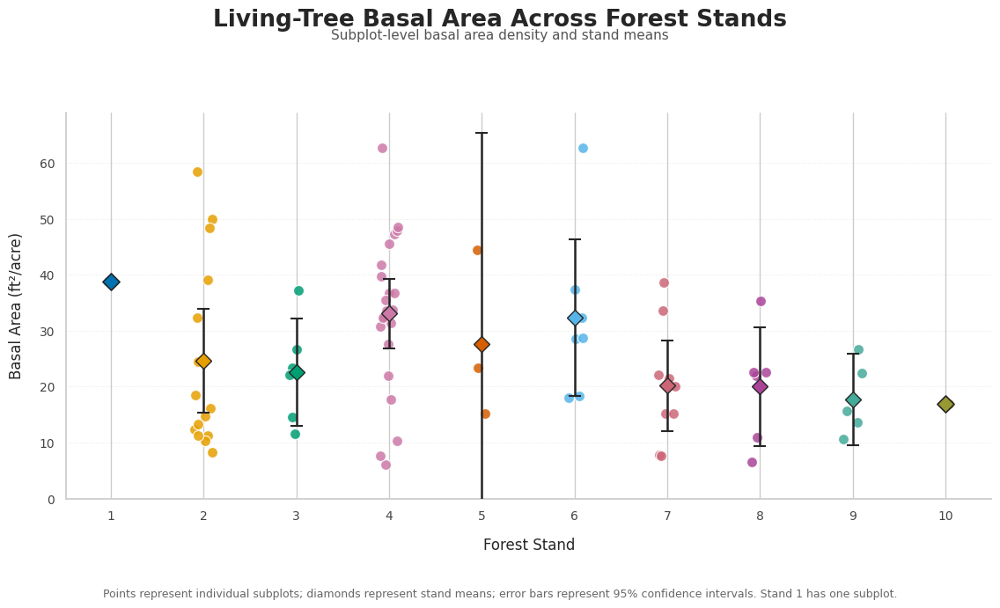

In [104]:
# ============================================================
# STEP 81
# ============================================================

# subplot-level basal area per acre across ten forest stands.
#
# Individual points represent sampled subplots.
# Large markers represent stand means.
# Error bars represent 95% confidence intervals around
# the mean, calculated using the t distribution.
#
# Stand 1 has only one subplot, so no confidence interval
# can be calculated for that stand.

# ------------------------------------------------------------
# 1. IMPORT STATISTICAL FUNCTIONS
# ------------------------------------------------------------

# Import the t distribution to calculate confidence intervals
# that account for the sample size within each stand.
from scipy.stats import t


# ------------------------------------------------------------
# 2. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a wide figure for a clear comparison among stands.
fig, ax = plt.subplots(
    figsize=(12, 7)
)

# Set a consistent random seed for reproducible point jitter.
np.random.seed(42)


# ------------------------------------------------------------
# 3. PLOT INDIVIDUAL SUBPLOT OBSERVATIONS
# ------------------------------------------------------------

# Loop through each stand.
for stand in included_stands:

    # Select basal area measurements for the current stand.
    stand_data = subplot_basal_area[
        subplot_basal_area['Stand ID'] == stand
    ]

    # Extract the subplot-level basal area values.
    values = stand_data['Basal Area (sq ft/acre)'].dropna()

    # Calculate the mean basal area for this stand.
    mean_value = values.mean()

    # Retrieve the established color for this stand.
    stand_color = stand_colors[stand]

    # Generate small horizontal offsets to separate points visually.
    jitter = np.random.uniform(
        -0.10,
        0.10,
        size=len(values)
    )

    # Plot each subplot as an individual observation.
    ax.scatter(
        stand + jitter,
        values,
        color=stand_color,
        edgecolor='white',
        linewidth=0.9,
        alpha=0.85,
        s=75,
        zorder=3
    )

    # --------------------------------------------------------
    # 3A. CALCULATE THE 95% CONFIDENCE INTERVAL
    # --------------------------------------------------------

    # Calculate a confidence interval only when at least
    # two subplot observations are available.
    if len(values) >= 2:

        # Calculate the sample standard deviation.
        standard_deviation = values.std(ddof=1)

        # Calculate the standard error of the mean.
        standard_error = standard_deviation / np.sqrt(len(values))

        # Calculate the critical t value for a 95% interval.
        critical_t = t.ppf(
            0.975,
            df=len(values) - 1
        )

        # Calculate the lower and upper confidence limits.
        lower_ci = mean_value - critical_t * standard_error
        upper_ci = mean_value + critical_t * standard_error

        # Calculate the lower and upper error distances.
        lower_error = mean_value - lower_ci
        upper_error = upper_ci - mean_value

        # Plot the mean and confidence interval.
        ax.errorbar(
            stand,
            mean_value,
            yerr=[[lower_error], [upper_error]],
            fmt='D',
            color='#252525',
            markerfacecolor=stand_color,
            markeredgecolor='#252525',
            markersize=9,
            capsize=5,
            capthick=1.5,
            linewidth=1.8,
            zorder=5
        )

    else:

        # For a single subplot, show the mean without a confidence interval.
        ax.scatter(
            stand,
            mean_value,
            marker='D',
            color=stand_color,
            edgecolor='#252525',
            linewidth=1.2,
            s=95,
            zorder=5
        )


# ------------------------------------------------------------
# 4. FORMAT THE AXES
# ------------------------------------------------------------

# Set stand numbers as the horizontal-axis positions.
ax.set_xticks(included_stands)

# Label the horizontal axis.
ax.set_xlabel(
    'Forest Stand',
    fontsize=12,
    labelpad=12
)

# Label the vertical axis.
ax.set_ylabel(
    'Basal Area (ft²/acre)',
    fontsize=12,
    labelpad=12
)

# Set the vertical-axis range to accommodate the confidence intervals.
ax.set_ylim(bottom=0)

# Add subtle horizontal gridlines.
ax.grid(
    axis='y',
    linestyle=':',
    linewidth=0.7,
    alpha=0.45
)

# Keep gridlines behind the observations.
ax.set_axisbelow(True)

# Remove the top and right borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Standardize tick label appearance.
ax.tick_params(
    axis='both',
    labelsize=10,
    colors='#444444'
)


# ------------------------------------------------------------
# 5. ADD TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Living-Tree Basal Area Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=0.97
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.92,
    'Subplot-level basal area density and stand means',
    ha='center',
    fontsize=11,
    color='#555555'
)

# Add a footnote explaining the points and confidence intervals.
fig.text(
    0.5,
    0.015,
    'Points represent individual subplots; diamonds represent stand means; '
    'error bars represent 95% confidence intervals. Stand 1 has one subplot.',
    ha='center',
    fontsize=9,
    color='#666666'
)


# ------------------------------------------------------------
# 6. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust the layout to accommodate the title and footnote.
plt.tight_layout(
    rect=[0.02, 0.06, 0.98, 0.89]
)

# Save a high-resolution PNG.
plt.savefig(
    export_dir / 'Living_Tree_Basal_Area_by_Stand.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

# Save a publication-quality PDF.
plt.savefig(
    export_dir / 'Living_Tree_Basal_Area_by_Stand.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()


In [106]:
# ============================================================
# STEP 82
# ============================================================
#
# This analysis identifies which species contribute most
# to the structural composition of each forest stand.
#
# All 356 living trees are included.
# The 12 temporarily excluded height observations remain included
# because their DBH measurements are still being retained.

# ------------------------------------------------------------
# 1. SUMMARIZE TREE BASAL AREA BY SPECIES AND STAND
# ------------------------------------------------------------

# Group individual tree basal area measurements by stand and species.
species_basal_area_summary = (
    basal_area_analysis
    .groupby(['Stand ID', 'Species Name'])
    .agg(
        Tree_Count=('Basal Area (sq ft)', 'count'),
        Total_Basal_Area=('Basal Area (sq ft)', 'sum'),
        Mean_Tree_Basal_Area=('Basal Area (sq ft)', 'mean'),
        Median_Tree_Basal_Area=('Basal Area (sq ft)', 'median')
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. CALCULATE EACH STAND'S TOTAL BASAL AREA
# ------------------------------------------------------------

# Calculate the total basal area contributed by all species
# within each stand.
species_basal_area_summary['Stand_Total_Basal_Area'] = (
    species_basal_area_summary
    .groupby('Stand ID')['Total_Basal_Area']
    .transform('sum')
)

# ------------------------------------------------------------
# 3. CALCULATE PERCENT CONTRIBUTION
# ------------------------------------------------------------

# Calculate the percentage of stand basal area represented
# by each species.
species_basal_area_summary['Basal_Area_Percent'] = (
    species_basal_area_summary['Total_Basal_Area']
    / species_basal_area_summary['Stand_Total_Basal_Area']
    * 100
)

# ------------------------------------------------------------
# 4. CALCULATE SPECIES-SPECIFIC BASAL AREA PER ACRE
# ------------------------------------------------------------

# Attach the number of sampled subplots to each stand-species record.
species_basal_area_summary = species_basal_area_summary.merge(
    stand_subplot_counts,
    on='Stand ID',
    how='left'
)

# Calculate the total sampled area for each stand.
species_basal_area_summary['Sampled_Area_Acres'] = (
    species_basal_area_summary['Number of Subplots']
    * subplot_area_acres
)

# Calculate species-specific basal area per acre.
species_basal_area_summary['Species_BA_per_Acre'] = (
    species_basal_area_summary['Total_Basal_Area']
    / species_basal_area_summary['Sampled_Area_Acres']
)

# ------------------------------------------------------------
# 5. SORT SPECIES WITHIN EACH STAND
# ------------------------------------------------------------

# Sort species from greatest to smallest basal area contribution
# within each stand.
species_basal_area_summary = species_basal_area_summary.sort_values(
    ['Stand ID', 'Basal_Area_Percent'],
    ascending=[True, False]
).reset_index(drop=True)

# Round numerical values for easier interpretation.
species_basal_area_summary = species_basal_area_summary.round(2)

# ------------------------------------------------------------
# 6. DISPLAY SPECIES-LEVEL RESULTS
# ------------------------------------------------------------

# Display the species-level basal area contribution table.
display(
    species_basal_area_summary[
        [
            'Stand ID',
            'Species Name',
            'Tree_Count',
            'Total_Basal_Area',
            'Species_BA_per_Acre',
            'Basal_Area_Percent'
        ]
    ]
)


,Stand ID,Species Name,Tree_Count,Total_Basal_Area,Species_BA_per_Acre,Basal_Area_Percent
0,1,Eastern Hemlock,4,2.30,13.83,35.70
1,1,Red Maple,2,1.71,10.30,26.59
2,1,Yellow Birch,3,1.30,7.80,20.13
3,1,White Oak,1,0.58,3.46,8.94
4,1,Sugar Maple,1,0.56,3.35,8.64
...,...,...,...,...,...,...
66,9,Eastern Hemlock,1,0.15,0.18,1.00
67,10,Yellow Birch,3,1.62,9.77,57.67
68,10,White Oak,1,0.85,5.13,30.28
69,10,American Beech,1,0.20,1.22,7.21


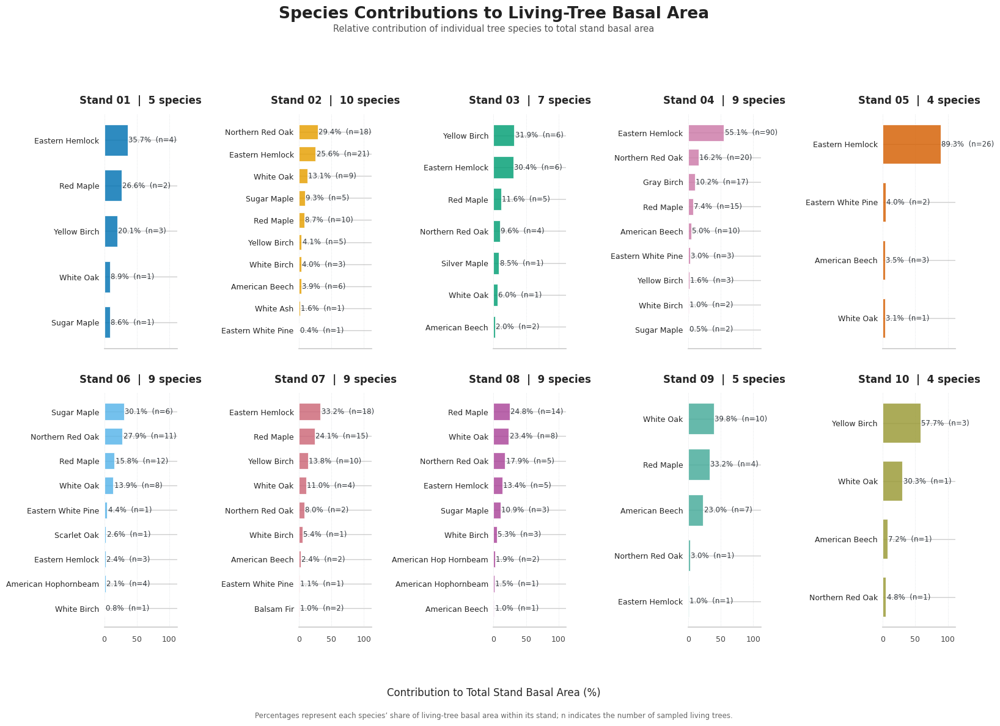

In [107]:

# ============================================================
# STEP 83
# ============================================================
#
# Figure design:
# - Six panels, one per forest stand.
# - Horizontal bars represent species contributions (%).
# - Species are ranked from lowest to highest within each panel.
# - Original stand-specific colors are preserved.
# - Each bar is annotated with its percentage and tree count.
#
# All 356 living trees are included.
# Percentages describe each species' contribution to the
# total living-tree basal area within its stand.

# ------------------------------------------------------------
# 1. SET UP THE FIGURE
# ------------------------------------------------------------

# Create a two-row by three-column figure.
fig, axes = plt.subplots(
    2, 5,
    figsize=(17, 12),
    sharex=True
)

# Flatten the axes array for easier iteration.
axes = axes.flatten()


# ------------------------------------------------------------
# 2. CREATE ONE SPECIES CONTRIBUTION PANEL PER STAND
# ------------------------------------------------------------

# Loop through each stand and its corresponding panel.
for stand, ax in zip(included_stands, axes):

    # Select species-level basal area results for the current stand.
    stand_data = species_basal_area_summary[
        species_basal_area_summary['Stand ID'] == stand
    ].copy()

    # Sort species from lowest to highest contribution.
    # This places the most important contributors at the top.
    stand_data = stand_data.sort_values(
        'Basal_Area_Percent',
        ascending=True
    )

    # Retrieve the established color for this stand.
    stand_color = stand_colors[stand]

    # Create horizontal positions for the species labels.
    y_positions = np.arange(len(stand_data))

    # --------------------------------------------------------
    # 2A. DRAW SPECIES CONTRIBUTION BARS
    # --------------------------------------------------------

    # Draw one horizontal bar for each species.
    bars = ax.barh(
        y_positions,
        stand_data['Basal_Area_Percent'],
        color=stand_color,
        alpha=0.82,
        edgecolor='white',
        linewidth=0.8,
        height=0.68,
        zorder=3
    )

    # --------------------------------------------------------
    # 2B. ANNOTATE PERCENTAGE AND TREE COUNT
    # --------------------------------------------------------

    # Add the percentage and number of trees beside each bar.
    for bar, (_, row) in zip(bars, stand_data.iterrows()):

        # Retrieve the bar's horizontal endpoint.
        bar_width = bar.get_width()

        # Position the annotation just beyond the bar.
        ax.text(
            bar_width + 1.2,
            bar.get_y() + bar.get_height() / 2,
            f"{row['Basal_Area_Percent']:.1f}%  (n={int(row['Tree_Count'])})",
            va='center',
            ha='left',
            fontsize=8.5,
            color='#343A40'
        )

    # --------------------------------------------------------
    # 2C. FORMAT SPECIES LABELS
    # --------------------------------------------------------

    # Use species names as the vertical-axis labels.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        stand_data['Species Name'],
        fontsize=9
    )

    # Add the stand identifier and number of species.
    ax.set_title(
        f"Stand {stand:02d}  |  {len(stand_data)} species",
        fontsize=12,
        fontweight='bold',
        pad=12,
        color='#252525'
    )

    # Set a consistent horizontal scale across all panels.
    ax.set_xlim(0, 112)

    # Add subtle vertical gridlines.
    ax.grid(
        axis='x',
        linestyle=':',
        linewidth=0.65,
        color='#BFC5CA',
        alpha=0.55
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # Remove tick marks beside species labels.
    ax.tick_params(
        axis='y',
        length=0,
        pad=6
    )

    # Standardize horizontal-axis tick labels.
    ax.tick_params(
        axis='x',
        labelsize=9,
        colors='#444444'
    )


# ------------------------------------------------------------
# 3. ADD FIGURE TITLE AND SHARED AXIS LABEL
# ------------------------------------------------------------

# Add the main figure title.
fig.suptitle(
    'Species Contributions to Living-Tree Basal Area',
    fontsize=19,
    fontweight='bold',
    color='#222222',
    y=0.98
)

# Add a descriptive subtitle.
fig.text(
    0.5,
    0.945,
    'Relative contribution of individual tree species to total stand basal area',
    ha='center',
    fontsize=10.5,
    color='#555555'
)

# Add one shared horizontal-axis label.
fig.supxlabel(
    'Contribution to Total Stand Basal Area (%)',
    fontsize=12,
    fontweight='medium',
    y=0.035
)


# ------------------------------------------------------------
# 4. ADD A FIGURE FOOTNOTE
# ------------------------------------------------------------

# Clarify the meaning of percentages and sample sizes.
fig.text(
    0.5,
    0.008,
    'Percentages represent each species’ share of living-tree basal area within its stand; '
    'n indicates the number of sampled living trees.',
    ha='center',
    fontsize=8.5,
    color='#666666'
)


# ------------------------------------------------------------
# 5. FINAL LAYOUT AND EXPORT
# ------------------------------------------------------------

# Adjust spacing to accommodate species names and annotations.
plt.tight_layout(
    rect=[0.02, 0.065, 0.98, 0.91],
    h_pad=2.5,
    w_pad=2.0
)

# Save the high-resolution PNG.
plt.savefig(
    export_dir / 'Species_Basal_Area_Contributions.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

# Save the publication-quality PDF.
plt.savefig(
    export_dir / 'Species_Basal_Area_Contributions.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display the completed figure.
plt.show()


In [108]:

# ============================================================
# STEP 84
# ============================================================
# species composition in the three vegetation layers.
#
# We will examine:
# 1. Living tree observations
# 2. Herbaceous vegetation observations
# 3. Regeneration observations
#
# The purpose is to identify whether each layer contains
# individual counts, cover measurements, or other variables
# that should determine how relative composition is calculated.

# ------------------------------------------------------------
# 1. INSPECT TREE SPECIES DATA
# ------------------------------------------------------------

# Display the available tree dataset columns.
print("TREE DATA COLUMNS:")
print(live_trees_analysis.columns.tolist())

# Display representative living-tree records.
display(live_trees_analysis.head(5))


# ------------------------------------------------------------
# 2. INSPECT HERBACEOUS SPECIES DATA
# ------------------------------------------------------------

# Display the available herbaceous dataset columns.
print("\nHERBACEOUS DATA COLUMNS:")
print(herbaceous_analysis.columns.tolist())

# Display representative herbaceous records.
display(herbaceous_analysis.head(5))


# ------------------------------------------------------------
# 3. INSPECT REGENERATION SPECIES DATA
# ------------------------------------------------------------

# Display the available regeneration dataset columns.
print("\nREGENERATION DATA COLUMNS:")
print(regeneration_analysis.columns.tolist())

# Display representative regeneration records.
display(regeneration_analysis.head(5))


TREE DATA COLUMNS:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Tree ID', 'Species Code', 'Tree Status', 'DBH (in)', 'Estimated Tree Height (m)', 'Estimated Tree Height (ft)', 'Crown Class Code', 'Damage Type Code', 'Snag Decay Class (If Applicable)', 'Notes', 'Species Name', 'Tree Status Label', 'Calculated Height (ft)', 'Height Difference (ft)']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name,Tree Status Label,Calculated Height (ft),Height Difference (ft)
0,1,1,1,2026-10-23,"EJ, TQ",1.0,YB,AL,8.30,25.0,82.020998,Dominant,NaN,NaN,NaN,Yellow Birch,Alive,82.02100,-2.500000e-06
1,1,1,1,2026-10-23,"EJ, TQ",2.0,EH,AL,8.25,10.0,32.808399,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive,32.80840,-1.000000e-06
2,1,1,1,2026-10-23,"JW, JR, HP",5.0,EH,AL,11.80,5.5,18.044619,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive,18.04462,-5.500000e-07
3,1,1,1,2026-10-23,"JW, JR, JM, HP",7.0,EH,AL,10.80,12.0,39.370079,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive,39.37008,-1.200000e-06
4,1,1,1,2026-10-23,"JW, JR, JM, HP, EC, AB, LA, LW",8.0,YB,AL,11.99,10.5,34.448819,Codominant,NaN,NaN,NaN,Yellow Birch,Alive,34.44882,-1.050000e-06



HERBACEOUS DATA COLUMNS:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Species ID', 'Invasive (Y/N)', 'General Phenological State', 'Damage Type Code', 'Percent Cover (%)', 'Notes', 'Species Name', 'Identification Status']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Invasive (Y/N),General Phenological State,Damage Type Code,Percent Cover (%),Notes,Species Name,Identification Status
0,1,1,1,2026-10-23,"EC, HP, JM, LW, AB, JW, JR, LA",PRP,N,1,NaN,1,NaN,Princess Pine,Identified
1,1,1,1,2026-10-23,"EC, HP, JM, LW, AB, JW, JR, LA",SF,N,1,NaN,1,NaN,Starflower,Identified
2,1,1,1,2026-10-23,"EC, HP, JM, LW, AB, JW, JR, LA",XMF,N,1,NaN,1,NaN,Christmas Fern,Identified
3,1,1,1,2026-10-23,"EC, HP, JM, LW, AB, JW, JR, LA",INT,N,1,NaN,1,NaN,Interrupted Fern,Identified
4,2,1,1,2026-10-23,"AB, JR, EC, HP",PRP,N,1,NaN,1,NaN,Princess Pine,Identified



REGENERATION DATA COLUMNS:
['Stand ID', 'Plot ID', 'Subplot ID', 'Microplot ID', 'Date', 'Team Member(s)', 'Species ID', 'Seedling/Sapling?', 'Count', 'Damage Type Code', 'Notes', 'Species Name']


,Stand ID,Plot ID,Subplot ID,Microplot ID,Date,Team Member(s),Species ID,Seedling/Sapling?,Count,Damage Type Code,Notes,Species Name
0,1,1,1,1,2026-10-23,"LW, JW, AB",AB,Seedling,2,40.0,NaN,American Beech
1,1,1,1,1,2026-10-23,"LW, JW, AB",AB,Sapling,1,40.0,NaN,American Beech
2,1,1,1,1,2026-10-23,"LW, JW, AB",YB,Sapling,1,NaN,NaN,Yellow Birch
3,1,1,1,1,2026-10-23,"LW, JW, AB",EH,Seedling,1,NaN,NaN,Eastern Hemlock
4,2,1,1,1,2026-10-23,"JM, LW, JW",WO,Sapling,3,NaN,NaN,White Oak


In [109]:


# ============================================================
# STEP 85
# ============================================================
#
# This step checks the measurement fields that will determine
# relative species composition in the herbaceous and regeneration layers.
#
# We will not modify or exclude any observations.

# ------------------------------------------------------------
# 1. INSPECT HERBACEOUS PERCENT COVER
# ------------------------------------------------------------

# Display the frequency of recorded herbaceous percent-cover values.
print("Herbaceous percent-cover values:")
display(
    herbaceous_analysis['Percent Cover (%)']
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis('Percent Cover (%)')
    .reset_index(name='Number of Records')
)

# Count missing herbaceous cover measurements.
print(
    "\nMissing herbaceous cover measurements:",
    herbaceous_analysis['Percent Cover (%)'].isna().sum()
)

# Count total herbaceous records.
print(
    "Total herbaceous records:",
    len(herbaceous_analysis)
)


# ------------------------------------------------------------
# 2. INSPECT REGENERATION COUNTS
# ------------------------------------------------------------

# Display the frequency of recorded regeneration counts.
print("\nRegeneration count values:")
display(
    regeneration_analysis['Count']
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis('Count')
    .reset_index(name='Number of Records')
)

# Count missing regeneration measurements.
print(
    "\nMissing regeneration counts:",
    regeneration_analysis['Count'].isna().sum()
)

# Count total regeneration records.
print(
    "Total regeneration records:",
    len(regeneration_analysis)
)


# ------------------------------------------------------------
# 3. INSPECT REGENERATION LIFE STAGES
# ------------------------------------------------------------

# Determine how regeneration observations are distributed
# between seedlings and saplings.
print("\nRegeneration life-stage records:")
display(
    regeneration_analysis['Seedling/Sapling?']
    .value_counts(dropna=False)
    .rename_axis('Life Stage')
    .reset_index(name='Number of Records')
)


# ------------------------------------------------------------
# 4. CHECK FOR MISSING SPECIES IDENTIFICATIONS
# ------------------------------------------------------------

# Check whether herbaceous species names are missing.
print(
    "\nHerbaceous records missing species names:",
    herbaceous_analysis['Species Name'].isna().sum()
)

# Check whether regeneration species names are missing.
print(
    "Regeneration records missing species names:",
    regeneration_analysis['Species Name'].isna().sum()
)


Herbaceous percent-cover values:


,Percent Cover (%),Number of Records
0,1,271
1,2,14
2,3,2



Missing herbaceous cover measurements: 0
Total herbaceous records: 287

Regeneration count values:


,Count,Number of Records
0,1,69
1,2,36
2,3,28
3,4,11
4,5,12
5,6,11
6,7,4
7,8,6
8,9,4
9,10,2



Missing regeneration counts: 0
Total regeneration records: 201

Regeneration life-stage records:


,Life Stage,Number of Records
0,Seedling,86
1,Sapling,65
2,Sapling,28
3,Seedling,21
4,Seedling,1



Herbaceous records missing species names: 0
Regeneration records missing species names: 0


In [110]:


# ============================================================
# STEP 86
# ============================================================
#
# This step identifies:
# - Available woody-cover variables
# - Species recorded in the dataset
# - Overstory and understory categories
# - Cover-class frequencies
# - Missing cover classifications
#
# No observations are modified or removed.

# ------------------------------------------------------------
# 1. INSPECT DATASET STRUCTURE
# ------------------------------------------------------------

# Display all available woody-cover columns.
print("WOODY COVER DATA COLUMNS:")
print(woody_cover_analysis.columns.tolist())

# Display the first ten woody-cover records.
display(woody_cover_analysis.head(10))


# ------------------------------------------------------------
# 2. IDENTIFY COVER CLASSIFICATION COLUMNS
# ------------------------------------------------------------

# Display the unique values in each column that may contain
# a vegetation layer or cover classification.
for column in woody_cover_analysis.columns:

    # Print unique values for columns with a manageable
    # number of distinct categories.
    if woody_cover_analysis[column].nunique(dropna=False) <= 20:

        print(f"\n{column}:")
        print(
            woody_cover_analysis[column]
            .value_counts(dropna=False)
        )


# ------------------------------------------------------------
# 3. INSPECT SPECIES REPRESENTATION
# ------------------------------------------------------------

# Count woody-cover records by species.
woody_cover_species = (
    woody_cover_analysis
    .groupby('Species Name')
    .size()
    .reset_index(name='Number of Records')
    .sort_values(
        'Number of Records',
        ascending=False
    )
)

# Display the species represented in the woody-cover dataset.
print("\nWoody-cover records by species:")
display(woody_cover_species)


# ------------------------------------------------------------
# 4. INSPECT COVER RECORDS BY STAND
# ------------------------------------------------------------

# Display the number of woody-cover records in each stand.
print("\nWoody-cover records by stand:")
display(
    woody_cover_analysis
    .groupby('Stand ID')
    .size()
    .reset_index(name='Number of Records')
)


# ------------------------------------------------------------
# 5. CHECK FOR MISSING SPECIES IDENTIFICATIONS
# ------------------------------------------------------------

# Count records without an identified species name.
print(
    "\nRecords missing species names:",
    woody_cover_analysis['Species Name'].isna().sum()
)


WOODY COVER DATA COLUMNS:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Species ID', 'Overstory Cover (%) Code', 'Understory Cover (%) Code', 'Notes', 'Species Name']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Overstory Cover (%) Code,Understory Cover (%) Code,Notes,Species Name
0,1,1,1,2026-10-23,"EC, AB, JM, JW, JR, HP, LA, LW",EH,2,1,NaN,Eastern Hemlock
1,1,1,1,2026-10-23,"EC, AB, JM, JW, JR, HP, LA, LW",RM,1,1,NaN,Red Maple
2,1,1,1,2026-10-23,"EC, AB, JM, JW, JR, HP, LA, LW",AB,2,3,NaN,American Beech
3,1,1,1,2026-10-23,"EC, AB, JM, JW, JR, HP, LA, LW",YB,1,1,NaN,Yellow Birch
4,1,1,1,2026-10-23,"EC, AB, JM, JW, JR, HP, LA, LW",GB,1,2,NaN,Gray Birch
5,1,1,1,2026-10-23,"EC, AB, JM, JW, JR, HP, LA, LW",AB,2,2,NaN,American Beech
6,2,1,1,2026-10-23,"LW, JM, LA, JW",RO,1,1,NaN,Northern Red Oak
7,2,1,1,2026-10-23,"LW, JM, LA, JW",WO,1,1,NaN,White Oak
8,2,1,1,2026-10-23,"LW, JM, LA, JW",EH,1,1,NaN,Eastern Hemlock
9,2,1,2,2026-10-23,"JW, JM, LW",WA,1,1,NaN,White Ash



Stand ID:
Stand ID
4     81
2     63
7     54
8     36
6     34
3     24
9     19
5      9
1      6
10     6
Name: count, dtype: int64

Plot ID:
Plot ID
1    238
2     68
3     13
4     13
Name: count, dtype: int64

Subplot ID:
Subplot ID
1     77
2     58
3     52
4     39
5     25
6     25
7     14
9     14
8     13
10     4
11     4
12     4
13     3
Name: count, dtype: int64

Date:
Date
2026-11-13    88
2026-11-11    56
2026-11-06    51
2026-10-30    47
2026-11-04    34
2026-10-23    20
2026-11-05    18
2026-10-28    18
Name: count, dtype: int64

Overstory Cover (%) Code:
Overstory Cover (%) Code
1    218
2     84
3     22
4      8
Name: count, dtype: int64

Understory Cover (%) Code:
Understory Cover (%) Code
1    229
2     68
3     27
4      8
Name: count, dtype: int64

Notes:
Notes
NaN                  322
Striped Maple          8
None in overstory      1
Living                 1
Name: count, dtype: int64

Woody-cover records by species:


,Species Name,Number of Records
1,American Beech,72
5,Eastern Hemlock,61
9,Northern Red Oak,31
11,Red Maple,27
20,White Oak,23
22,Yellow Birch,23
18,White Ash,17
6,Eastern White Pine,14
15,Striped Maple,13
7,Gray Birch,11



Woody-cover records by stand:


,Stand ID,Number of Records
0,1,6
1,2,63
2,3,24
3,4,81
4,5,9
5,6,34
6,7,54
7,8,36
8,9,19
9,10,6



Records missing species names: 0


In [111]:

# ============================================================
# STEP 87
# ============================================================

# We will calculate the distribution of the four cover classes
# separately for overstory and understory vegetation.
#
# Percentages represent the proportion of recorded woody-cover
# observations in each classification category within each stand.
#
# Cover codes are treated as ordinal categories, not continuous
# percentage measurements.

# ------------------------------------------------------------
# 1. DEFINE THE COVER CLASSIFICATION CATEGORIES
# ------------------------------------------------------------

# Define the four recorded cover classes in their proper order.
cover_classes = [1, 2, 3, 4]

# Define the two woody vegetation layers and their corresponding columns.
cover_columns = {
    'Overstory': 'Overstory Cover (%) Code',
    'Understory': 'Understory Cover (%) Code'
}


# ------------------------------------------------------------
# 2. CALCULATE COVER-CLASS FREQUENCIES BY STAND
# ------------------------------------------------------------

# Create an empty dictionary to store the frequency tables.
woody_cover_distributions = {}

# Loop through overstory and understory cover classifications.
for layer, column in cover_columns.items():

    # Count the number of records in each cover class within
    # each stand.
    class_counts = pd.crosstab(
        woody_cover_analysis['Stand ID'],
        woody_cover_analysis[column]
    )

    # Ensure all four cover classes appear in the table,
    # even if a stand has no records in a particular class.
    class_counts = class_counts.reindex(
        columns=cover_classes,
        fill_value=0
    )

    # Rename the columns to identify the cover class.
    class_counts.columns = [
        f'Class {category}'
        for category in cover_classes
    ]

    # Calculate the percentage of observations in each class
    # within each stand.
    class_percentages = (
        class_counts
        .div(class_counts.sum(axis=1), axis=0)
        * 100
    )

    # Store both counts and percentages for later use.
    woody_cover_distributions[layer] = {
        'counts': class_counts,
        'percentages': class_percentages
    }

    # --------------------------------------------------------
    # 2A. DISPLAY FREQUENCY TABLES
    # --------------------------------------------------------

    print(f"\n{layer.upper()} COVER CLASS COUNTS:")
    display(class_counts)

    print(f"\n{layer.upper()} COVER CLASS DISTRIBUTION (%):")
    display(class_percentages.round(1))


# ------------------------------------------------------------
# 3. INSPECT THE RECORD WITH THE OVERSTORY NOTE
# ------------------------------------------------------------

# Find woody-cover observations with a note indicating
# that no overstory was present.
overstory_note_records = woody_cover_analysis[
    woody_cover_analysis['Notes']
    .astype(str)
    .str.contains('None in overstory', case=False, na=False)
]

# Display the complete records for review.
print("\nRecords noting no overstory:")
display(overstory_note_records)


# ------------------------------------------------------------
# 4. CHECK FOR UNRESOLVED SPECIES LABELS
# ------------------------------------------------------------

# Display species names that occur in the woody-cover dataset.
print("\nSpecies names requiring identification review:")
display(
    woody_cover_analysis['Species Name']
    .value_counts()
    .loc[lambda counts: counts.index.isin(['PB'])]
)



OVERSTORY COVER CLASS COUNTS:


,Class 1,Class 2,Class 3,Class 4
Stand ID,,,,
1,3,3,0,0
2,46,15,1,1
3,15,8,0,1
4,38,24,16,3
5,5,2,0,2
6,24,10,0,0
7,42,10,1,1
8,27,8,1,0
9,13,4,2,0



OVERSTORY COVER CLASS DISTRIBUTION (%):


,Class 1,Class 2,Class 3,Class 4
Stand ID,,,,
1,50.0,50.0,0.0,0.0
2,73.0,23.8,1.6,1.6
3,62.5,33.3,0.0,4.2
4,46.9,29.6,19.8,3.7
5,55.6,22.2,0.0,22.2
6,70.6,29.4,0.0,0.0
7,77.8,18.5,1.9,1.9
8,75.0,22.2,2.8,0.0
9,68.4,21.1,10.5,0.0



UNDERSTORY COVER CLASS COUNTS:


,Class 1,Class 2,Class 3,Class 4
Stand ID,,,,
1,3,2,1,0
2,40,20,2,1
3,18,3,3,0
4,56,11,9,5
5,4,2,2,1
6,27,4,3,0
7,40,10,4,0
8,26,8,1,1
9,10,7,2,0


... (2 outputs left out)


Records noting no overstory:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Overstory Cover (%) Code,Understory Cover (%) Code,Notes,Species Name
34,2,2,3,2026-10-28,AB,EH,1,2,None in overstory,Eastern Hemlock



Species names requiring identification review:


,count
Species Name,
PB,3


In [112]:

# ============================================================
# STEP 88
# ============================================================
#
# The original numeric cover codes are preserved.
# New categorical columns are created for visualization.
#
# These are classification ranges, not exact measured
# percentage-cover values.

# ------------------------------------------------------------
# 1. DEFINE THE COVER CLASSIFICATION KEY
# ------------------------------------------------------------

# Map each original cover code to its corresponding percentage range.
cover_range_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# Define the desired order of the percentage-range categories.
cover_range_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]


# ------------------------------------------------------------
# 2. CREATE READABLE OVERSTORY COVER LABELS
# ------------------------------------------------------------

# Convert overstory cover codes into percentage-range labels.
woody_cover_analysis['Overstory Cover Range'] = (
    woody_cover_analysis['Overstory Cover (%) Code']
    .map(cover_range_labels)
)

# Set the labels as an ordered categorical variable.
woody_cover_analysis['Overstory Cover Range'] = pd.Categorical(
    woody_cover_analysis['Overstory Cover Range'],
    categories=cover_range_order,
    ordered=True
)


# ------------------------------------------------------------
# 3. CREATE READABLE UNDERSTORY COVER LABELS
# ------------------------------------------------------------

# Convert understory cover codes into percentage-range labels.
woody_cover_analysis['Understory Cover Range'] = (
    woody_cover_analysis['Understory Cover (%) Code']
    .map(cover_range_labels)
)

# Set the labels as an ordered categorical variable.
woody_cover_analysis['Understory Cover Range'] = pd.Categorical(
    woody_cover_analysis['Understory Cover Range'],
    categories=cover_range_order,
    ordered=True
)


# ------------------------------------------------------------
# 4. VERIFY THE CONVERSION
# ------------------------------------------------------------

# Display original codes alongside their new percentage ranges.
display(
    woody_cover_analysis[
        [
            'Stand ID',
            'Species Name',
            'Overstory Cover (%) Code',
            'Overstory Cover Range',
            'Understory Cover (%) Code',
            'Understory Cover Range'
        ]
    ].head(15)
)

# Confirm that all records received a valid classification label.
print(
    "\nMissing overstory range labels:",
    woody_cover_analysis['Overstory Cover Range'].isna().sum()
)

print(
    "Missing understory range labels:",
    woody_cover_analysis['Understory Cover Range'].isna().sum()
)


,Stand ID,Species Name,Overstory Cover (%) Code,Overstory Cover Range,Understory Cover (%) Code,Understory Cover Range
0,1,Eastern Hemlock,2,25–50%,1,0–25%
1,1,Red Maple,1,0–25%,1,0–25%
2,1,American Beech,2,25–50%,3,50–75%
3,1,Yellow Birch,1,0–25%,1,0–25%
4,1,Gray Birch,1,0–25%,2,25–50%
5,1,American Beech,2,25–50%,2,25–50%
6,2,Northern Red Oak,1,0–25%,1,0–25%
7,2,White Oak,1,0–25%,1,0–25%
8,2,Eastern Hemlock,1,0–25%,1,0–25%
9,2,White Ash,1,0–25%,1,0–25%



Missing overstory range labels: 0
Missing understory range labels: 0


In [113]:

# ============================================================
# STEP 89
# ============================================================

#
# Based on your identification, PB represents White Birch.
# This updates the working analysis dataset without changing
# the original woody_cover source DataFrame.

# Replace PB with White Birch in the analysis dataset.
woody_cover_analysis['Species Name'] = (
    woody_cover_analysis['Species Name']
    .replace({'PB': 'White Birch'})
)

# Verify the correction.
print("Updated species counts:")
display(woody_cover_analysis['Species Name'].value_counts())

# Confirm that no PB records remain.
print(
    "\nRemaining PB records:",
    (woody_cover_analysis['Species Name'] == 'PB').sum()
)

# Display the corrected White Birch records.
display(
    woody_cover_analysis[
        woody_cover_analysis['Species Name'] == 'White Birch'
    ]
)


Updated species counts:


,count
Species Name,
American Beech,72
Eastern Hemlock,61
Northern Red Oak,31
Red Maple,27
Yellow Birch,23
White Oak,23
White Ash,17
Eastern White Pine,14
Striped Maple,13



Remaining PB records: 0


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Overstory Cover (%) Code,Understory Cover (%) Code,Notes,Species Name,Overstory Cover Range,Understory Cover Range
13,2,1,3,2026-10-23,"JW, JM, LW",PB,1,1,NaN,White Birch,0–25%,0–25%
25,2,2,2,2026-10-28,AB,WB,1,1,NaN,White Birch,0–25%,0–25%
59,2,4,1,2026-11-05,"KC, LW, JW",PB,1,1,NaN,White Birch,0–25%,0–25%
87,3,2,1,2026-11-06,"JW, JM",WB,1,1,NaN,White Birch,0–25%,0–25%
99,4,1,2,2026-10-30,"JW, LW, LA",WB,2,2,NaN,White Birch,25–50%,25–50%
212,6,1,6,2026-11-11,"JM, LW, JW",WB,1,1,NaN,White Birch,0–25%,0–25%
261,7,1,7,2026-11-13,"JW,LW",WB,1,1,NaN,White Birch,0–25%,0–25%
269,7,1,9,2026-11-13,"JW,KC,LW",PB,1,1,NaN,White Birch,0–25%,0–25%
276,8,1,1,2026-11-13,"JW,LW",WB,1,1,NaN,White Birch,0–25%,0–25%
300,8,1,6,2026-11-13,"EJ, JM",WB,2,1,NaN,White Birch,25–50%,0–25%


In [116]:

# ============================================================
# STEP 90
# ============================================================
#
# Overstory and understory are not separated because the available
# records do not provide a sufficiently reliable basis for
# distinguishing the two vegetation layers.
#
# Both original cover-code columns are retained.
# Each valid classification is counted as one observation.
# No averages, interpolated percentages, or new classes are created.

# ------------------------------------------------------------
# 1. COMBINE THE TWO COVER CLASSIFICATION COLUMNS
# ------------------------------------------------------------

# Copy the working woody-cover dataset so the original data
# and its two separate cover columns remain unchanged.
combined_woody_cover = woody_cover_analysis.copy()

# Convert the overstory codes into a common analysis column.
overstory_records = combined_woody_cover[
    ['Stand ID', 'Species Name', 'Overstory Cover (%) Code']
].copy()

overstory_records = overstory_records.rename(
    columns={'Overstory Cover (%) Code': 'Cover Code'}
)

# Identify the source of each original observation.
overstory_records['Source Column'] = 'Overstory field'

# Convert the understory codes into the same common structure.
understory_records = combined_woody_cover[
    ['Stand ID', 'Species Name', 'Understory Cover (%) Code']
].copy()

understory_records = understory_records.rename(
    columns={'Understory Cover (%) Code': 'Cover Code'}
)

understory_records['Source Column'] = 'Understory field'

# Combine the two sets of observations.
combined_woody_cover_records = pd.concat(
    [overstory_records, understory_records],
    ignore_index=True
)

# Retain only records with a valid species and cover code.
combined_woody_cover_records = (
    combined_woody_cover_records
    .dropna(subset=['Stand ID', 'Species Name', 'Cover Code'])
    .copy()
)

# Convert the cover codes to integers for consistent counting.
combined_woody_cover_records['Cover Code'] = (
    combined_woody_cover_records['Cover Code'].astype(int)
)

# ------------------------------------------------------------
# 2. ASSIGN THE ORIGINAL FOUR CLASSIFICATION LABELS
# ------------------------------------------------------------

# Map the original numeric codes to their classification ranges.
cover_class_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# Add readable classification labels without changing the codes.
combined_woody_cover_records['Cover Classification'] = (
    combined_woody_cover_records['Cover Code']
    .map(cover_class_labels)
)

# Define the classification order.
cover_range_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]

# ------------------------------------------------------------
# 3. COUNT CLASSIFICATIONS BY SPECIES AND STAND
# ------------------------------------------------------------

# Count the number of observations in each cover class
# for each species within each stand.
species_cover_counts = pd.crosstab(
    [
        combined_woody_cover_records['Stand ID'],
        combined_woody_cover_records['Species Name']
    ],
    combined_woody_cover_records['Cover Classification']
)

# Ensure that all four original classifications are present.
species_cover_counts = species_cover_counts.reindex(
    columns=cover_range_order,
    fill_value=0
)

# Remove species with no observations.
species_cover_counts = species_cover_counts.loc[
    species_cover_counts.sum(axis=1) > 0
]

# ------------------------------------------------------------
# 4. DISPLAY THE SPECIES-RESOLVED RESULTS
# ------------------------------------------------------------

print('COMBINED WOODY COVER CLASSIFICATION COUNTS')

display(species_cover_counts)

# Display the total number of records contributing to
# each species-level distribution.
species_cover_sample_sizes = species_cover_counts.sum(axis=1)

print('\nTOTAL OBSERVATIONS BY SPECIES AND STAND')

display(species_cover_sample_sizes.rename('Number of Records').to_frame())

# Verify the total number of observations included.
print(
    '\nTotal combined cover observations:',
    len(combined_woody_cover_records)
)


COMBINED WOODY COVER CLASSIFICATION COUNTS


Cover Classification       0–25%  25–50%  50–75%  75–100%
Stand ID Species Name                                    
1        American Beech        0       3       1        0
         Eastern Hemlock       1       1       0        0
         Gray Birch            1       1       0        0
         Red Maple             2       0       0        0
         Yellow Birch          2       0       0        0
...                          ...     ...     ...      ...
10       Eastern Hemlock       2       0       0        0
         Northern Red Oak      2       0       0        0
         White Ash             2       0       0        0
         White Oak             1       1       0        0
         Yellow Birch          1       0       1        0

[100 rows x 4 columns]


TOTAL OBSERVATIONS BY SPECIES AND STAND


Number of Records
Stand ID Species Name                       
1        American Beech                    4
         Eastern Hemlock                   2
         Gray Birch                        2
         Red Maple                         2
         Yellow Birch                      2
...                                      ...
10       Eastern Hemlock                   2
         Northern Red Oak                  2
         White Ash                         2
         White Oak                         2
         Yellow Birch                      2

[100 rows x 1 columns]


Total combined cover observations: 664


In [118]:

# ============================================================
# STEP 91
# ============================================================
#
# Combine the two cover fields into one species-level dataset.
# Preserve each original observation and its assigned classification.
# Do not calculate averages or new percentage values.

# ------------------------------------------------------------
# 1. DEFINE THE ORIGINAL CLASSIFICATION KEY
# ------------------------------------------------------------

cover_class_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# ------------------------------------------------------------
# 2. CONVERT OVERSTORY RECORDS
# ------------------------------------------------------------

# Select the stand, species, and original overstory code.
overstory_records = woody_cover_analysis[
    ['Stand ID', 'Species Name', 'Overstory Cover (%) Code']
].copy()

# Rename the cover field so it can be combined with understory.
overstory_records = overstory_records.rename(
    columns={'Overstory Cover (%) Code': 'Cover Code'}
)

# Convert numeric codes into their actual percentage ranges.
overstory_records['Cover Classification'] = (
    overstory_records['Cover Code'].map(cover_class_labels)
)

# ------------------------------------------------------------
# 3. CONVERT UNDERSTORY RECORDS
# ------------------------------------------------------------

# Select the stand, species, and original understory code.
understory_records = woody_cover_analysis[
    ['Stand ID', 'Species Name', 'Understory Cover (%) Code']
].copy()

# Use the same column name as the overstory records.
understory_records = understory_records.rename(
    columns={'Understory Cover (%) Code': 'Cover Code'}
)

# Convert numeric codes into their actual percentage ranges.
understory_records['Cover Classification'] = (
    understory_records['Cover Code'].map(cover_class_labels)
)

# ------------------------------------------------------------
# 4. COMBINE THE TWO SETS OF CLASSIFICATIONS
# ------------------------------------------------------------

# Retain one row per original cover-field observation.
combined_woody_cover = pd.concat(
    [
        overstory_records,
        understory_records
    ],
    ignore_index=True
)

# Remove records without a species or valid classification.
combined_woody_cover = combined_woody_cover.dropna(
    subset=['Stand ID', 'Species Name', 'Cover Classification']
).copy()

# Define the classification order from lowest to highest cover.
cover_range_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]

# Make the classifications ordered categories.
combined_woody_cover['Cover Classification'] = pd.Categorical(
    combined_woody_cover['Cover Classification'],
    categories=cover_range_order,
    ordered=True
)

# ------------------------------------------------------------
# 5. SUMMARIZE CLASSIFICATIONS BY SPECIES AND STAND
# ------------------------------------------------------------

# Count observations within each original percentage range.
species_cover_summary = pd.crosstab(
    [
        combined_woody_cover['Stand ID'],
        combined_woody_cover['Species Name']
    ],
    combined_woody_cover['Cover Classification']
)

# Ensure all four classification ranges are displayed.
species_cover_summary = species_cover_summary.reindex(
    columns=cover_range_order,
    fill_value=0
)

# Display the species-resolved classification counts.
display(species_cover_summary)

# ------------------------------------------------------------
# 6. VERIFY THE CONVERSION
# ------------------------------------------------------------

print('\nCLASSIFICATION LABELS:')
print(combined_woody_cover['Cover Classification'].value_counts(
    sort=False
))

print('\nTOTAL COMBINED OBSERVATIONS:')
print(len(combined_woody_cover))

print('\nSAMPLE CONVERTED RECORDS:')
display(combined_woody_cover.head(15))


Cover Classification       0–25%  25–50%  50–75%  75–100%
Stand ID Species Name                                    
1        American Beech        0       3       1        0
         Eastern Hemlock       1       1       0        0
         Gray Birch            1       1       0        0
         Red Maple             2       0       0        0
         Yellow Birch          2       0       0        0
...                          ...     ...     ...      ...
10       Eastern Hemlock       2       0       0        0
         Northern Red Oak      2       0       0        0
         White Ash             2       0       0        0
         White Oak             1       1       0        0
         Yellow Birch          1       0       1        0

[100 rows x 4 columns]


CLASSIFICATION LABELS:
Cover Classification
0–25%      447
25–50%     152
50–75%      49
75–100%     16
Name: count, dtype: int64

TOTAL COMBINED OBSERVATIONS:
664

SAMPLE CONVERTED RECORDS:


,Stand ID,Species Name,Cover Code,Cover Classification
0,1,Eastern Hemlock,2,25–50%
1,1,Red Maple,1,0–25%
2,1,American Beech,2,25–50%
3,1,Yellow Birch,1,0–25%
4,1,Gray Birch,1,0–25%
5,1,American Beech,2,25–50%
6,2,Northern Red Oak,1,0–25%
7,2,White Oak,1,0–25%
8,2,Eastern Hemlock,1,0–25%
9,2,White Ash,1,0–25%


QA/QC CHECK
--------------------------------------------------
Total observations: 664
Species-stand combinations: 100
Number of stands: 10

Cover-class totals:
Cover Classification
0–25%      447
25–50%     152
50–75%      49
75–100%     16
dtype: int64

Species combinations by stand:
Stand 1: 5 species
Stand 2: 13 species
Stand 3: 10 species
Stand 4: 11 species
Stand 5: 6 species
Stand 6: 13 species
Stand 7: 17 species
Stand 8: 11 species
Stand 9: 8 species
Stand 10: 6 species


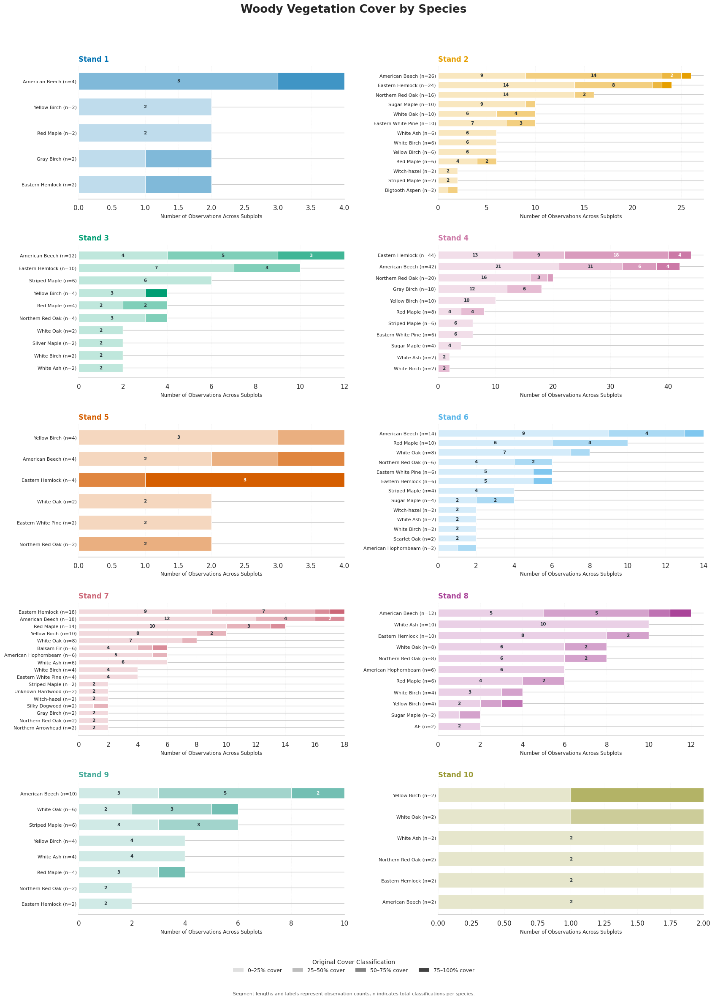


Successfully generated all ten stand panels.


In [123]:

# ============================================================
# STEP 92:
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.patches import Patch
from matplotlib.colors import to_rgb


# ------------------------------------------------------------
# 1. DEFINE COVER CLASSES AND STAND COLORS
# ------------------------------------------------------------

cover_class_order = [
    '0–25%',
    '25–50%',
    '50–75%',
    '75–100%'
]

stand_order = list(range(1, 11))

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}


# ------------------------------------------------------------
# 2. DEFINE COVER-CLASS SHADE STRENGTH
# ------------------------------------------------------------

shade_strength = {
    '0–25%': 0.25,
    '25–50%': 0.50,
    '50–75%': 0.75,
    '75–100%': 1.00
}


# ------------------------------------------------------------
# 3. CREATE STAND-SPECIFIC COVER SHADES
# ------------------------------------------------------------

def create_stand_shade(base_color, strength):

    base_rgb = np.array(to_rgb(base_color))

    shaded_rgb = (
        (1 - strength) * np.ones(3)
        + strength * base_rgb
    )

    return shaded_rgb


stand_cover_colors = {
    stand: {
        cover_class: create_stand_shade(
            stand_color,
            shade_strength[cover_class]
        )
        for cover_class in cover_class_order
    }
    for stand, stand_color in stand_colors.items()
}


# ------------------------------------------------------------
# 4. PREPARE SPECIES-LEVEL DATA
# ------------------------------------------------------------

plot_data = species_cover_summary.copy()

# Confirm that the summary uses Stand ID as an index level.
if 'Stand ID' not in plot_data.index.names:
    raise ValueError(
        "The species_cover_summary index must contain "
        "'Stand ID'."
    )

# Ensure all cover-class columns are available.
plot_data = plot_data.reindex(
    columns=cover_class_order,
    fill_value=0
)

# Convert counts to numeric values.
plot_data[cover_class_order] = (
    plot_data[cover_class_order]
    .apply(
        lambda column: pd.to_numeric(
            column,
            errors='coerce'
        ).fillna(0)
    )
)

# Calculate total observations per species and stand.
plot_data['n'] = plot_data[cover_class_order].sum(axis=1)


# ------------------------------------------------------------
# 5. QA/QC CHECKS
# ------------------------------------------------------------

# Confirm nonnegative counts.
assert (
    plot_data[cover_class_order] >= 0
).all().all(), "Negative counts detected."

# Confirm whole-number counts.
assert np.allclose(
    plot_data[cover_class_order].to_numpy(),
    np.round(plot_data[cover_class_order].to_numpy())
), "Non-integer counts detected."

# Confirm that all ten stands are represented.
observed_stands = sorted(
    plot_data.index.get_level_values('Stand ID')
    .unique()
    .astype(int)
)

assert observed_stands == stand_order, (
    f"Expected stands {stand_order}, "
    f"but found {observed_stands}"
)

# Confirm that every stand has species observations.
for stand in stand_order:

    stand_data = plot_data.xs(
        stand,
        level='Stand ID'
    )

    assert len(stand_data) > 0, (
        f"No species observations found for Stand {stand}."
    )


# ------------------------------------------------------------
# 6. PRINT QA/QC SUMMARY
# ------------------------------------------------------------

print("QA/QC CHECK")
print("-" * 50)

print(
    f"Total observations: "
    f"{int(plot_data['n'].sum())}"
)

print(
    f"Species-stand combinations: {len(plot_data)}"
)

print(
    f"Number of stands: {len(observed_stands)}"
)

print("\nCover-class totals:")

print(
    plot_data[cover_class_order]
    .sum()
    .astype(int)
)

print("\nSpecies combinations by stand:")

for stand in stand_order:

    stand_data = plot_data.xs(
        stand,
        level='Stand ID'
    )

    print(
        f"Stand {stand}: {len(stand_data)} species"
    )


# ------------------------------------------------------------
# 7. CREATE TEN-PANEL FIGURE
# ------------------------------------------------------------

# CORRECTED: Five rows and two columns = ten panels.
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(18, 24),
    sharex=False
)

axes = axes.flatten()


# ------------------------------------------------------------
# 8. PLOT EACH STAND
# ------------------------------------------------------------

for stand, ax in zip(stand_order, axes):

    # Retrieve species-level observations for this stand.
    stand_data = plot_data.xs(
        stand,
        level='Stand ID'
    ).copy()

    # Sort species by total observations.
    stand_data = stand_data.sort_values(
        'n',
        ascending=True
    )

    # Establish species positions.
    y_positions = np.arange(len(stand_data))

    # Initialize stacked bar positions.
    left_positions = np.zeros(
        len(stand_data)
    )

    # Draw each cover-class segment.
    for cover_class in cover_class_order:

        values = stand_data[
            cover_class
        ].to_numpy()

        ax.barh(
            y_positions,
            values,
            left=left_positions,
            height=0.68,
            color=stand_cover_colors[stand][cover_class],
            edgecolor='white',
            linewidth=0.8
        )

        # Add count labels to sufficiently large segments.
        for position, value, left in zip(
            y_positions,
            values,
            left_positions
        ):

            if value >= 2:

                label_color = (
                    '#263238'
                    if shade_strength[cover_class] <= 0.50
                    else 'white'
                )

                ax.text(
                    left + value / 2,
                    position,
                    f'{int(value)}',
                    ha='center',
                    va='center',
                    fontsize=7.5,
                    color=label_color,
                    fontweight='bold'
                )

        # Advance the next stacked segment.
        left_positions += values


    # --------------------------------------------------------
    # SPECIES LABELS
    # --------------------------------------------------------

    species_labels = [
        f'{species} (n={int(total)})'
        for species, total in zip(
            stand_data.index,
            stand_data['n']
        )
    ]

    ax.set_yticks(y_positions)

    ax.set_yticklabels(
        species_labels,
        fontsize=8
    )


    # --------------------------------------------------------
    # PANEL FORMATTING
    # --------------------------------------------------------

    ax.set_xlabel(
        'Number of Observations Across Subplots',
        fontsize=8.5
    )

    ax.set_title(
        f'Stand {stand}',
        loc='left',
        fontsize=12,
        fontweight='bold',
        color=stand_colors[stand],
        pad=8
    )

    ax.set_xlim(left=0)

    ax.xaxis.grid(
        True,
        linestyle=':',
        linewidth=0.6,
        alpha=0.35
    )

    ax.set_axisbelow(True)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    ax.spines['bottom'].set_color('#CCCCCC')

    ax.tick_params(
        axis='y',
        length=0
    )


# ------------------------------------------------------------
# 9. SHARED COVER-CLASS LEGEND
# ------------------------------------------------------------

legend_shades = {
    '0–25%': '#E0E0E0',
    '25–50%': '#BDBDBD',
    '50–75%': '#858585',
    '75–100%': '#424242'
}

legend_handles = [
    Patch(
        facecolor=legend_shades[cover_class],
        edgecolor='none',
        label=f'{cover_class} cover'
    )
    for cover_class in cover_class_order
]


fig.legend(
    handles=legend_handles,
    title='Original Cover Classification',
    loc='lower center',
    ncol=4,
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    bbox_to_anchor=(0.5, 0.025)
)


# ------------------------------------------------------------
# 10. FIGURE TITLE AND EXPLANATORY TEXT
# ------------------------------------------------------------

fig.suptitle(
    'Woody Vegetation Cover by Species',
    fontsize=19,
    fontweight='bold',
    y=0.985
)


fig.text(
    0.5,
    0.008,
    'Segment lengths and labels represent observation counts; '
    'n indicates total classifications per species.',
    ha='center',
    fontsize=8,
    color='#555555'
)


# ------------------------------------------------------------
# 11. FINAL LAYOUT
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0.03, 0.06, 0.98, 0.96],
    h_pad=2.2,
    w_pad=2.0
)


# ------------------------------------------------------------
# 12. EXPORT FIGURE
# ------------------------------------------------------------

plt.savefig(
    export_dir / 'Woody_Cover_Species_Classification_Original_Colors.png',
    dpi=400,
    bbox_inches='tight',
    facecolor='white'
)

plt.savefig(
    export_dir / 'Woody_Cover_Species_Classification_Original_Colors.pdf',
    bbox_inches='tight',
    facecolor='white'
)


# ------------------------------------------------------------
# 13. DISPLAY FIGURE
# ------------------------------------------------------------

plt.show()

plt.close(fig)

print("\nSuccessfully generated all ten stand panels.")


In [124]:
# ============================================================
# STEP 93:
# ============================================================

# Print every column name in the woody analysis dataset.
print("WOODY ANALYSIS COLUMN NAMES")
print("-" * 45)

for column in woody_analysis.columns:
    print(repr(column))

# Identify columns whose names may refer to tree condition or status.
print("\nPOSSIBLE TREE STATUS OR CONDITION FIELDS")
print("-" * 45)

for column in woody_analysis.columns:
    if any(
        term in column.lower()
        for term in ['status', 'condition', 'live', 'dead', 'alive']
    ):
        print(repr(column))

WOODY ANALYSIS COLUMN NAMES
---------------------------------------------
'Stand ID'
'Plot ID'
'Subplot ID'
'Date'
'Team Member(s)'
'Tree ID'
'Species Code'
'Tree Status'
'DBH (in)'
'Estimated Tree Height (m)'
'Estimated Tree Height (ft)'
'Crown Class Code'
'Damage Type Code'
'Snag Decay Class (If Applicable)'
'Notes'
'Species Name'
'Tree Status Label'

POSSIBLE TREE STATUS OR CONDITION FIELDS
---------------------------------------------
'Tree Status'
'Tree Status Label'


In [125]:
# ============================================================
# STEP 94
# ============================================================

# Select only records identified as alive in the descriptive status field.
live_trees_analysis = woody_analysis[
    woody_analysis['Tree Status Label']
    .astype(str)
    .str.strip()
    .str.lower()
    .eq('alive')
].copy()

# Remove records without a usable species name.
live_trees_analysis = live_trees_analysis.dropna(
    subset=['Species Name']
).copy()

# Remove accidental whitespace from species names.
live_trees_analysis['Species Name'] = (
    live_trees_analysis['Species Name'].astype(str).str.strip()
)

# Display the number of living trees recorded in each stand.
print("LIVING TREE RECORDS BY STAND")
print("-" * 45)

print(
    live_trees_analysis.groupby('Stand ID')
    .size()
    .reindex(included_stands, fill_value=0)
)

# Count individual living trees by species within each stand.
tree_species_counts = (
    live_trees_analysis
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .rename('Tree Count')
    .reset_index()
)

# Display species-level counts separately for each stand.
print("\nSPECIES COUNTS WITHIN EACH STAND")
print("-" * 45)

for stand in included_stands:

    # Select the species counts for the current stand.
    stand_counts = tree_species_counts[
        tree_species_counts['Stand ID'] == stand
    ].sort_values('Tree Count', ascending=False)

    # Print the species counts.
    print(f"\nStand {stand}")
    print(
        stand_counts[['Species Name', 'Tree Count']]
        .to_string(index=False)
    )

# Display the total number of living trees.
print("\nTOTAL LIVING TREES:", len(live_trees_analysis))

# Display the number of unique species across the ten stands.
print(
    "TOTAL UNIQUE TREE SPECIES:",
    live_trees_analysis['Species Name'].nunique()
)

LIVING TREE RECORDS BY STAND
---------------------------------------------
Stand ID
1      11
2      79
3      25
4     162
5      32
6      47
7      55
8      42
9      23
10      6
dtype: int64

SPECIES COUNTS WITHIN EACH STAND
---------------------------------------------

Stand 1
   Species Name  Tree Count
Eastern Hemlock           4
   Yellow Birch           3
      Red Maple           2
    Sugar Maple           1
      White Oak           1

Stand 2
      Species Name  Tree Count
   Eastern Hemlock          21
  Northern Red Oak          18
         Red Maple          10
         White Oak           9
    American Beech           6
       Sugar Maple           5
      Yellow Birch           5
       White Birch           3
Eastern White Pine           1
         White Ash           1

Stand 3
    Species Name  Tree Count
 Eastern Hemlock           6
    Yellow Birch           6
       Red Maple           5
Northern Red Oak           4
  American Beech           2
    Silver Ma

In [126]:
# ============================================================
# STEP 95
# ============================================================

# Start with the species-level tree counts calculated in Step 126.
tree_relative_abundance = tree_species_counts.copy()

# Calculate the total number of living trees recorded in each stand.
tree_relative_abundance['Stand Total'] = (
    tree_relative_abundance
    .groupby('Stand ID')['Tree Count']
    .transform('sum')
)

# Calculate each species' percentage of the living trees in its stand.
tree_relative_abundance['Relative Abundance (%)'] = (
    tree_relative_abundance['Tree Count'] /
    tree_relative_abundance['Stand Total']
) * 100

# Sort the results by stand and descending relative abundance.
tree_relative_abundance = tree_relative_abundance.sort_values(
    ['Stand ID', 'Relative Abundance (%)'],
    ascending=[True, False]
).reset_index(drop=True)

# Display the relative abundance results separately for each stand.
print("TREE SPECIES RELATIVE ABUNDANCE")
print("-" * 60)

for stand in included_stands:

    # Select the relative abundance results for the current stand.
    stand_data = tree_relative_abundance[
        tree_relative_abundance['Stand ID'] == stand
    ]

    # Display species, individual counts, and relative abundance.
    print(f"\nStand {stand}")
    print(
        stand_data[
            ['Species Name', 'Tree Count', 'Relative Abundance (%)']
        ].round(2).to_string(index=False)
    )

# Verify that relative abundances sum to approximately 100% in every stand.
stand_abundance_totals = (
    tree_relative_abundance
    .groupby('Stand ID')['Relative Abundance (%)']
    .sum()
)

print("\nQA/QC: RELATIVE ABUNDANCE TOTALS")
print("-" * 45)
print(stand_abundance_totals.round(4))

# Confirm that all ten stands sum to 100%, allowing for rounding precision.
assert np.allclose(
    stand_abundance_totals.values,
    100
), "QA/QC failed: relative abundance does not sum to 100% in every stand."

print("\nQA/QC PASSED: Relative abundance sums to 100% in all ten stands.")

TREE SPECIES RELATIVE ABUNDANCE
------------------------------------------------------------

Stand 1
   Species Name  Tree Count  Relative Abundance (%)
Eastern Hemlock           4                   36.36
   Yellow Birch           3                   27.27
      Red Maple           2                   18.18
    Sugar Maple           1                    9.09
      White Oak           1                    9.09

Stand 2
      Species Name  Tree Count  Relative Abundance (%)
   Eastern Hemlock          21                   26.58
  Northern Red Oak          18                   22.78
         Red Maple          10                   12.66
         White Oak           9                   11.39
    American Beech           6                    7.59
       Sugar Maple           5                    6.33
      Yellow Birch           5                    6.33
       White Birch           3                    3.80
Eastern White Pine           1                    1.27
         White Ash         

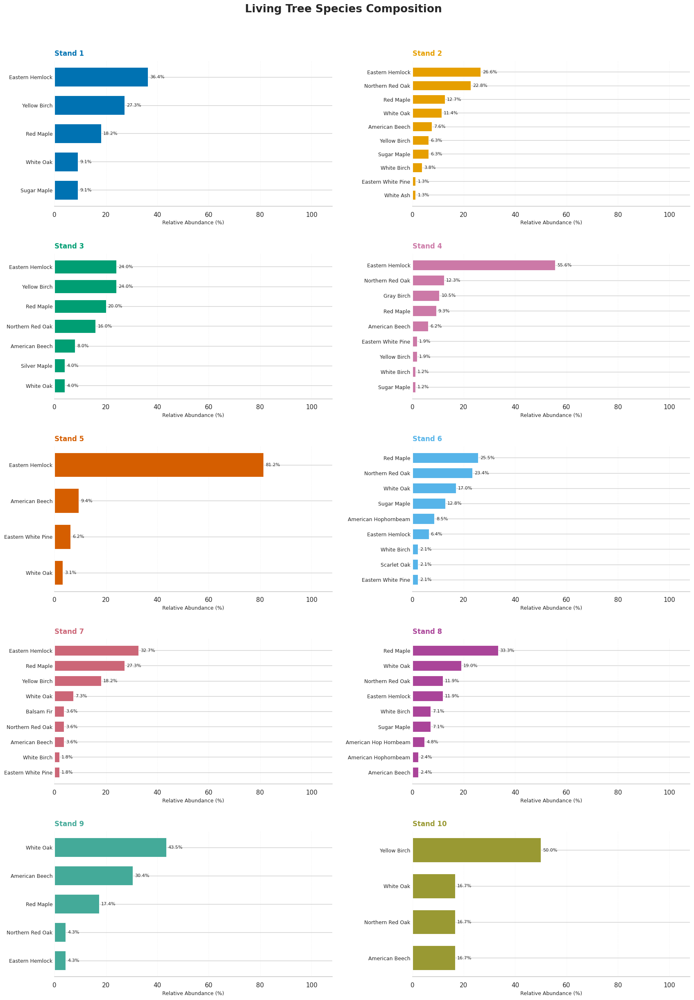

Number of stand panels created: 10
Stands displayed: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [128]:

# ============================================================
# STEP 96
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Preserve the original ten-stand color palette.
stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

# Explicitly include all ten stands.
stand_order = list(range(1, 11))

# Create TEN panels: 5 rows × 2 columns.
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(18, 25)
)

# Flatten axes for iteration.
axes = axes.flatten()

# Loop through all ten stands.
for stand, ax in zip(stand_order, axes):

    # Extract relative abundance data for this stand.
    stand_data = tree_relative_abundance[
        tree_relative_abundance['Stand ID'] == stand
    ].copy()

    # Handle stands with no available records.
    if stand_data.empty:
        ax.set_title(
            f'Stand {stand}',
            loc='left',
            fontsize=12,
            fontweight='bold',
            color=stand_colors[stand],
            pad=9
        )

        ax.text(
            0.5,
            0.5,
            'No data available',
            transform=ax.transAxes,
            ha='center',
            va='center',
            fontsize=10,
            color='#777777'
        )

        ax.set_xlim(0, 108)
        ax.set_xlabel('Relative Abundance (%)', fontsize=9)
        ax.set_yticks([])
        ax.grid(axis='x', linestyle=':', alpha=0.35)
        ax.set_axisbelow(True)

        continue

    # Sort species from lowest to highest relative abundance.
    stand_data = stand_data.sort_values(
        'Relative Abundance (%)',
        ascending=True
    )

    # Generate vertical positions for species.
    y_positions = np.arange(len(stand_data))

    # Draw horizontal bars.
    bars = ax.barh(
        y_positions,
        stand_data['Relative Abundance (%)'],
        color=stand_colors[stand],
        height=0.68,
        edgecolor='white',
        linewidth=0.8
    )

    # Add species names.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        stand_data['Species Name'],
        fontsize=9
    )

    # Add percentage labels.
    for bar, percentage in zip(
        bars,
        stand_data['Relative Abundance (%)']
    ):

        ax.text(
            bar.get_width() + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f'{percentage:.1f}%',
            va='center',
            ha='left',
            fontsize=8
        )

    # Stand-specific title.
    ax.set_title(
        f'Stand {stand}',
        loc='left',
        fontsize=12,
        fontweight='bold',
        color=stand_colors[stand],
        pad=9
    )

    # Use a consistent horizontal scale.
    ax.set_xlim(0, 108)

    # Add subtle vertical gridlines.
    ax.xaxis.grid(
        True,
        linestyle=':',
        linewidth=0.7,
        alpha=0.35
    )

    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color('#CCCCCC')

    # Remove y-axis tick marks.
    ax.tick_params(axis='y', length=0)

    # Axis label.
    ax.set_xlabel(
        'Relative Abundance (%)',
        fontsize=9
    )

# Main figure title.
fig.suptitle(
    'Living Tree Species Composition',
    fontsize=19,
    fontweight='bold',
    y=0.995
)

# Adjust spacing for all ten panels.
plt.tight_layout(
    rect=[0.03, 0.02, 0.98, 0.975],
    h_pad=2.5,
    w_pad=2.0
)

# Save high-resolution PNG.
plt.savefig(
    export_dir / 'Living_Tree_Species_Relative_Abundance.png',
    dpi=400,
    bbox_inches='tight'
)

# Save vector PDF.
plt.savefig(
    export_dir / 'Living_Tree_Species_Relative_Abundance.pdf',
    bbox_inches='tight'
)

# Display figure.
plt.show()

# Confirm that all ten stand panels were created.
print(f'Number of stand panels created: {len(axes)}')
print(f'Stands displayed: {stand_order}')


In [129]:
# ===========================================================
# STEP 97
# ============================================================

# Define the tree-status categories that will be treated as living.
included_tree_statuses = ['alive', 'damaged', 'dying']

# Select all trees belonging to the three included status categories.
live_trees_analysis = woody_analysis[
    woody_analysis['Tree Status Label']
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(included_tree_statuses)
].copy()

# Remove records without an identified species.
live_trees_analysis = live_trees_analysis.dropna(
    subset=['Species Name']
).copy()

# Standardize whitespace in species names.
live_trees_analysis['Species Name'] = (
    live_trees_analysis['Species Name'].astype(str).str.strip()
)

# Display the number of included trees by status and stand.
print("INCLUDED TREE STATUS COUNTS BY STAND")
print("-" * 55)

print(
    pd.crosstab(
        live_trees_analysis['Stand ID'],
        live_trees_analysis['Tree Status Label']
    ).reindex(included_stands, fill_value=0)
)

# Count trees by species within each stand.
tree_species_counts = (
    live_trees_analysis
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .rename('Tree Count')
    .reset_index()
)

# Calculate the total number of included trees within each stand.
tree_species_counts['Stand Total'] = (
    tree_species_counts
    .groupby('Stand ID')['Tree Count']
    .transform('sum')
)

# Calculate relative abundance within each stand.
tree_species_counts['Relative Abundance (%)'] = (
    tree_species_counts['Tree Count'] /
    tree_species_counts['Stand Total']
) * 100

# Display the revised species composition for each stand.
print("\nREVISED TREE SPECIES COMPOSITION")
print("-" * 55)

for stand in included_stands:

    # Select the species counts for the current stand.
    stand_data = tree_species_counts[
        tree_species_counts['Stand ID'] == stand
    ].sort_values('Relative Abundance (%)', ascending=False)

    # Print the revised species counts and relative abundances.
    print(f"\nStand {stand}")
    print(
        stand_data[
            ['Species Name', 'Tree Count', 'Relative Abundance (%)']
        ].round(2).to_string(index=False)
    )

# Print the updated total number of included trees.
print("\nTOTAL INCLUDED TREES:", len(live_trees_analysis))

# Print the updated number of unique species.
print(
    "TOTAL UNIQUE SPECIES:",
    live_trees_analysis['Species Name'].nunique()
)

# Verify that relative abundance sums to 100% in each stand.
abundance_check = (
    tree_species_counts
    .groupby('Stand ID')['Relative Abundance (%)']
    .sum()
)

assert np.allclose(abundance_check.values, 100), \
    "QA/QC failed: relative abundance does not sum to 100%."

print("\nQA/QC PASSED: Relative abundance sums to 100% in every stand.")

INCLUDED TREE STATUS COUNTS BY STAND
-------------------------------------------------------
Tree Status Label  Alive  Damaged  Dying
Stand ID                                
1                     11        6      1
2                     79       11      2
3                     25        3      1
4                    162       36      2
5                     32        2      1
6                     47        7      1
7                     55        6      1
8                     42        1      2
9                     23        0      0
10                     6        0      0

REVISED TREE SPECIES COMPOSITION
-------------------------------------------------------

Stand 1
   Species Name  Tree Count  Relative Abundance (%)
 American Beech           6                   33.33
Eastern Hemlock           4                   22.22
      Red Maple           3                   16.67
   Yellow Birch           3                   16.67
    Sugar Maple           1                    5.56
    

In [130]:
# ============================================================
# STEP 98
# ============================================================

# Count the unique species recorded in each stand using the revised dataset.
tree_richness_updated = (
    live_trees_analysis
    .groupby('Stand ID')['Species Name']
    .nunique()
    .reindex(included_stands, fill_value=0)
    .rename('Tree Species Richness')
)

# Display the revised species richness values.
print("UPDATED TREE SPECIES RICHNESS")
print("-" * 45)
print(tree_richness_updated)

# Display the total number of unique species across all ten stands.
print(
    "\nTotal unique tree species:",
    live_trees_analysis['Species Name'].nunique()
)

# Identify the species recorded in each stand.
print("\nSPECIES RICHNESS VALIDATION")
print("-" * 45)

for stand in included_stands:

    # Retrieve the unique species recorded in the current stand.
    species = sorted(
        live_trees_analysis.loc[
            live_trees_analysis['Stand ID'] == stand,
            'Species Name'
        ].unique()
    )

    # Display the stand-specific species list.
    print(f"\nStand {stand}: {len(species)} species")
    print(", ".join(species))

UPDATED TREE SPECIES RICHNESS
---------------------------------------------
Stand ID
1      6
2     10
3      7
4      9
5      5
6     10
7     11
8     10
9      5
10     4
Name: Tree Species Richness, dtype: int64

Total unique tree species: 16

SPECIES RICHNESS VALIDATION
---------------------------------------------

Stand 1: 6 species
American Beech, Eastern Hemlock, Red Maple, Sugar Maple, White Oak, Yellow Birch

Stand 2: 10 species
American Beech, Eastern Hemlock, Eastern White Pine, Northern Red Oak, Red Maple, Sugar Maple, White Ash, White Birch, White Oak, Yellow Birch

Stand 3: 7 species
American Beech, Eastern Hemlock, Northern Red Oak, Red Maple, Silver Maple, White Oak, Yellow Birch

Stand 4: 9 species
American Beech, Eastern Hemlock, Eastern White Pine, Gray Birch, Northern Red Oak, Red Maple, Sugar Maple, White Birch, Yellow Birch

Stand 5: 5 species
American Beech, Eastern Hemlock, Eastern White Pine, Sugar Maple, White Oak

Stand 6: 10 species
American Beech, Americ

LIVING-TREE DBH SAMPLE SIZE VALIDATION


,Observed,Expected,Match
1,18,18,True
2,92,92,True
3,29,29,True
4,200,200,True
5,35,35,True
6,55,55,True
7,62,62,True
8,45,45,True
9,23,23,True
10,6,6,True



Total living-tree DBH observations: 565

All ten stands passed validation.
Total validated observations: 565


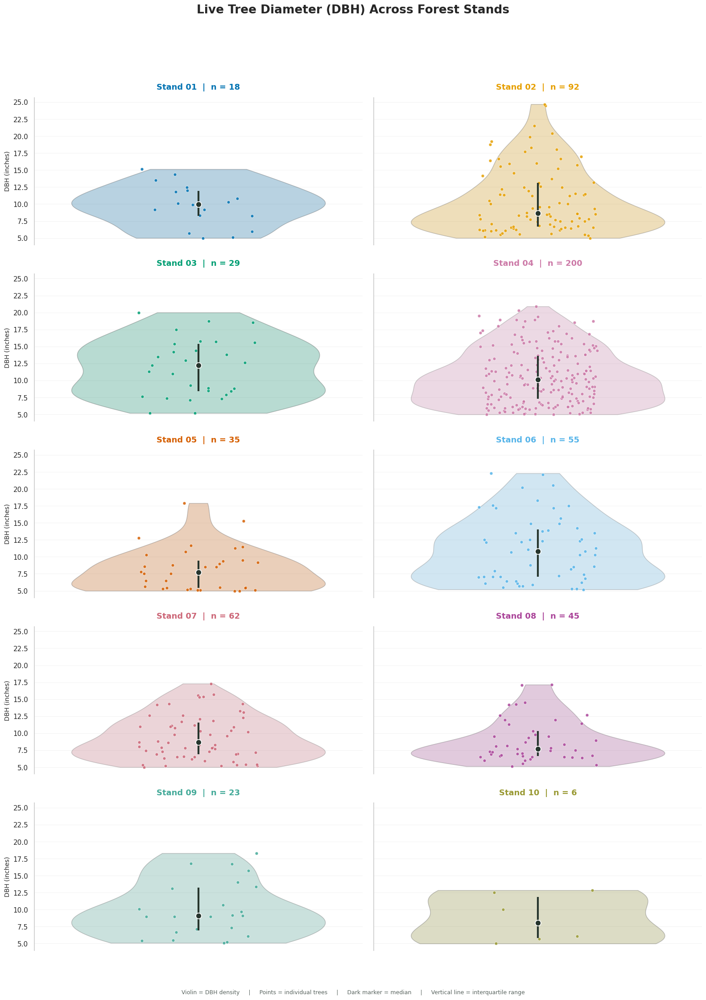


FIGURE SUMMARY
Stands represented: 10
Stand IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Total DBH observations: 565
PNG and PDF exports completed.


In [133]:

# ============================================================
# STEP 99
# ============================================================

# This figure includes:
# - Alive (AL), Damaged (DA), and Dying (DY) trees.
# - Individual DBH observations.
# - Violin distributions showing DBH density.
# - Median DBH markers.
# - Interquartile range (IQR) indicators.
#
# Dead trees and records without DBH measurements are excluded.


# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL TEN-STAND COLOR PALETTE
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

stand_order = list(range(1, 11))


# ------------------------------------------------------------
# 3. PREPARE AND VALIDATE THE DBH DATASET
# ------------------------------------------------------------

# Include all ten stands.
dbh_analysis_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(stand_order)
].copy()

# Remove records without DBH measurements.
dbh_analysis_df = dbh_analysis_df.dropna(
    subset=['DBH (in)']
).copy()

# Ensure DBH values are numeric.
dbh_analysis_df['DBH (in)'] = pd.to_numeric(
    dbh_analysis_df['DBH (in)'],
    errors='coerce'
)

# Remove any records that could not be converted.
dbh_analysis_df = dbh_analysis_df.dropna(
    subset=['DBH (in)']
).copy()

# Expected sample sizes from the current dataset.
expected_sample_sizes = {
    1: 18,
    2: 92,
    3: 29,
    4: 200,
    5: 35,
    6: 55,
    7: 62,
    8: 45,
    9: 23,
    10: 6
}

# Calculate actual observations by stand.
observed_sample_sizes = (
    dbh_analysis_df
    .groupby('Stand ID')['DBH (in)']
    .count()
    .reindex(stand_order, fill_value=0)
)

# Display validation results.
sample_size_comparison = pd.DataFrame({
    'Observed': observed_sample_sizes,
    'Expected': pd.Series(expected_sample_sizes)
})

sample_size_comparison['Match'] = (
    sample_size_comparison['Observed']
    == sample_size_comparison['Expected']
)

print("LIVING-TREE DBH SAMPLE SIZE VALIDATION")
display(sample_size_comparison)

print(
    "\nTotal living-tree DBH observations:",
    len(dbh_analysis_df)
)

# Validate all ten stands.
assert sample_size_comparison['Match'].all(), (
    "DBH sample sizes do not match the expected values. "
    "Review the living-tree dataset."
)

# Validate the total number of observations.
assert len(dbh_analysis_df) == 565, (
    f"Expected 565 DBH observations, "
    f"but found {len(dbh_analysis_df)}."
)

print("\nAll ten stands passed validation.")
print("Total validated observations: 565")


# ------------------------------------------------------------
# 4. ESTABLISH FIGURE STYLE AND LAYOUT
# ------------------------------------------------------------

sns.set_theme(
    style='whitegrid',
    context='notebook'
)

# Create TEN panels arranged in five rows and two columns.
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(16, 23),
    sharey=True
)

axes = axes.flatten()


# ------------------------------------------------------------
# 5. CREATE THE TEN STAND-SPECIFIC DBH DISTRIBUTIONS
# ------------------------------------------------------------

for stand, ax in zip(stand_order, axes):

    # Extract DBH measurements for this stand.
    stand_data = dbh_analysis_df.loc[
        dbh_analysis_df['Stand ID'] == stand,
        'DBH (in)'
    ].dropna()

    dbh_values = stand_data.to_numpy()

    # Retrieve stand color.
    stand_color = stand_colors[stand]

    # Calculate quartiles and median.
    q1 = np.percentile(dbh_values, 25)
    median = np.percentile(dbh_values, 50)
    q3 = np.percentile(dbh_values, 75)

    # Draw violin distribution.
    sns.violinplot(
        y=dbh_values,
        x=np.zeros(len(dbh_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.1,
        width=0.85,
        ax=ax
    )

    # Make violin partially transparent.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Generate reproducible horizontal jitter.
    rng = np.random.default_rng(seed=stand)

    jitter = rng.uniform(
        -0.20,
        0.20,
        size=len(dbh_values)
    )

    # Plot individual tree measurements.
    ax.scatter(
        jitter,
        dbh_values,
        s=25,
        color=stand_color,
        edgecolor='white',
        linewidth=0.55,
        alpha=0.85,
        zorder=4
    )

    # Draw interquartile range.
    ax.vlines(
        x=0,
        ymin=q1,
        ymax=q3,
        color='#26352D',
        linewidth=3,
        zorder=5
    )

    # Add median marker.
    ax.scatter(
        0,
        median,
        s=85,
        color='#26352D',
        edgecolor='white',
        linewidth=1.2,
        zorder=6
    )

    # Stand title and sample size.
    ax.set_title(
        f'Stand {stand:02d}  |  n = {len(dbh_values)}',
        fontsize=13,
        fontweight='bold',
        color=stand_color,
        pad=13
    )

    # DBH axis label.
    ax.set_ylabel(
        'DBH (inches)',
        fontsize=10
    )

    # Remove unnecessary horizontal-axis ticks.
    ax.set_xticks([])
    ax.set_xlabel('')

    # Consistent violin width.
    ax.set_xlim(-0.55, 0.55)

    # Subtle horizontal gridlines.
    ax.grid(
        axis='y',
        alpha=0.25,
        linewidth=0.7
    )

    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    sns.despine(
        ax=ax,
        bottom=True
    )


# ------------------------------------------------------------
# 6. ADD FIGURE TITLE AND EXPLANATORY TEXT
# ------------------------------------------------------------

fig.suptitle(
    'Live Tree Diameter (DBH) Across Forest Stands',
    fontsize=19,
    fontweight='bold',
    y=0.99
)


# Figure legend.
fig.text(
    0.5,
    0.025,
    'Violin = DBH density     |     '
    'Points = individual trees     |     '
    'Dark marker = median     |     '
    'Vertical line = interquartile range',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust spacing for all ten panels.
plt.tight_layout(
    rect=[0, 0.06, 1, 0.94],
    h_pad=2.0,
    w_pad=1.5
)


# ------------------------------------------------------------
# 7. EXPORT AND DISPLAY THE FIGURE
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.png',
    dpi=600,
    bbox_inches='tight'
)

fig.savefig(
    export_dir / 'Living_Tree_DBH_Raincloud.pdf',
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# 8. FINAL CONFIRMATION
# ------------------------------------------------------------

print("\nFIGURE SUMMARY")
print("Stands represented:", len(stand_order))
print("Stand IDs:", stand_order)
print("Total DBH observations:", len(dbh_analysis_df))
print("PNG and PDF exports completed.")


In [136]:
# ============================================================
# STEP 100
# ============================================================

# Group the updated DBH dataset by Stand ID and calculate the statistics.
dbh_summary = (
    dbh_analysis_df
    .groupby('Stand ID')['DBH (in)']
    .agg(
        n='count',                       # Number of trees measured
        Mean='mean',                     # Average DBH
        Median='median',                 # Middle DBH value
        SD='std',                        # Standard deviation
        Minimum='min',                   # Smallest DBH
        Q1=lambda x: x.quantile(0.25),    # 25th percentile
        Q3=lambda x: x.quantile(0.75),    # 75th percentile
        Maximum='max'                    # Largest DBH
    )
    .reindex(range(1, 11))                # Keep stands in numerical order
)

# Rename the index so the table clearly identifies each stand.
dbh_summary.index.name = 'Stand'

# Round DBH measurements to two decimal places.
dbh_summary = dbh_summary.round(2)

# Display the completed descriptive-statistics table.
display(dbh_summary)

# Display the total number of trees represented in the table.
print("Total living-tree DBH observations:", int(dbh_summary['n'].sum()))


,n,Mean,Median,SD,Minimum,Q1,Q3,Maximum
Stand,,,,,,,,
1,18,9.84,9.98,3.09,5.00,8.26,11.94,15.14
2,92,10.60,8.68,4.74,5.00,6.69,13.13,24.70
3,29,11.89,12.20,4.23,5.20,8.40,15.40,20.00
4,200,10.64,10.15,4.01,5.00,7.28,13.61,20.90
5,35,8.14,7.70,3.13,5.00,5.40,9.45,17.90
6,55,11.22,10.80,4.81,5.20,7.05,14.05,22.30
7,62,9.39,8.65,3.24,5.00,6.90,11.58,17.30
8,45,8.87,7.70,3.10,5.13,6.65,10.30,17.15
9,23,10.10,9.10,4.07,5.10,6.93,13.22,18.30


Total living-tree DBH observations: 565


Updated crown-class sample sizes by stand:
Stand ID
1      18
2      92
3      25
4     200
5      35
6      55
7      62
8      44
9      23
10      6
dtype: int64

Updated crown-class composition (%):


Crown Class Code,Dominant,Codominant,Intermediate,Suppressed
Stand ID,,,,
1,27.8,33.3,11.1,27.8
2,22.8,53.3,15.2,8.7
3,16.0,64.0,20.0,0.0
4,14.5,50.0,23.5,12.0
5,11.4,42.9,20.0,25.7
6,12.7,41.8,40.0,5.5
7,19.4,43.5,24.2,12.9
8,27.3,36.4,36.4,0.0
9,26.1,26.1,43.5,4.3



Total crown-class observations: 560

All ten stands passed crown-class sample-size validation.


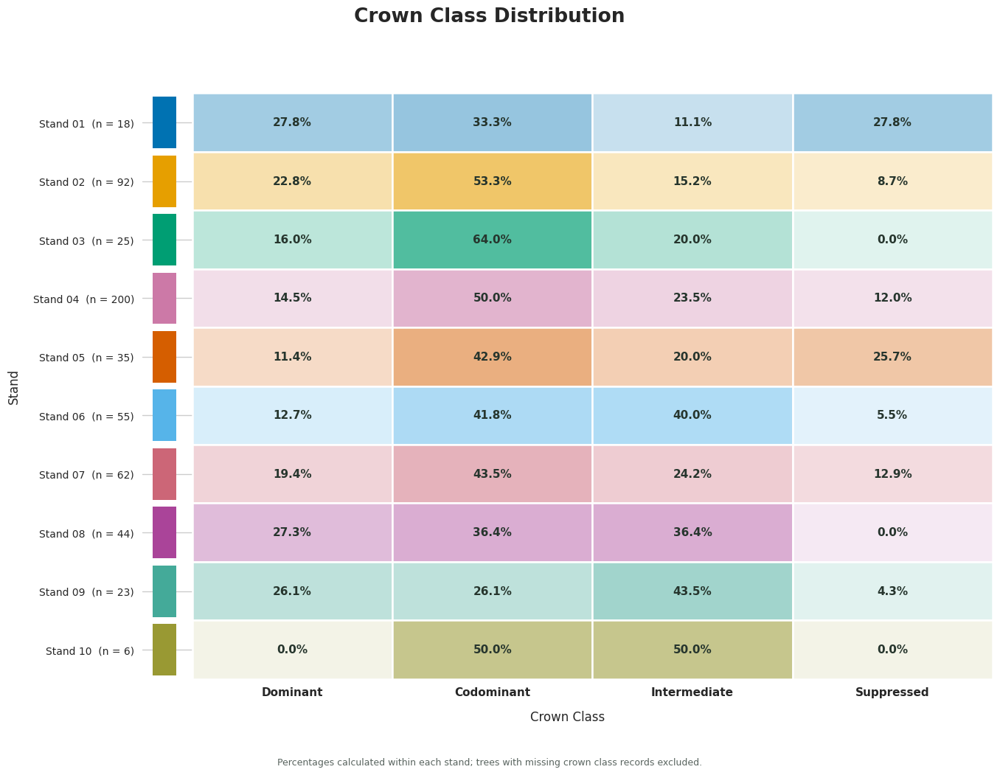


FINAL FIGURE QUALITY CONTROL
Number of stands represented: 10
Stand IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Total crown-class observations: 560
Number of crown classes: 4
PNG and PDF exports completed.


In [140]:

# ============================================================
# STEP 101
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as patches
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL TEN-STAND COLOR PALETTE
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9',  # Sky blue
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

# Explicitly include all ten stands.
stand_order = list(range(1, 11))


# ------------------------------------------------------------
# 3. PREPARE THE UPDATED LIVING-TREE DATA
# ------------------------------------------------------------

# Use the updated living-tree dataset containing AL, DA, and DY.
# Include all ten stands.
crown_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(stand_order)
].copy()

# Remove records without a recorded crown class.
crown_df = crown_df.dropna(
    subset=['Crown Class Code']
).copy()

# Standardize crown-class labels.
crown_df['Crown Class Code'] = (
    crown_df['Crown Class Code']
    .astype(str)
    .str.strip()
    .replace({
        'Co-Dominant': 'Codominant',
        'Co-dominant': 'Codominant',
        'Co-dominant ': 'Codominant',
        'Overtopped': 'Suppressed',
        'Overtopped / Suppressed': 'Suppressed'
    })
)

# Define the four crown classes in the original order.
crown_classes = [
    'Dominant',
    'Codominant',
    'Intermediate',
    'Suppressed'
]

# Keep only the four crown classes displayed in the figure.
crown_df = crown_df[
    crown_df['Crown Class Code'].isin(crown_classes)
].copy()


# ------------------------------------------------------------
# 4. CALCULATE CROWN CLASS COUNTS AND PERCENTAGES
# ------------------------------------------------------------

# Count trees in each crown class within each stand.
crown_counts = pd.crosstab(
    crown_df['Stand ID'],
    crown_df['Crown Class Code']
)

# Explicitly include all ten stands and all four crown classes.
crown_counts = crown_counts.reindex(
    index=stand_order,
    columns=crown_classes,
    fill_value=0
)

# Calculate the number of crown-class observations per stand.
crown_sample_sizes = crown_counts.sum(axis=1)

# Calculate percentages within each stand.
# Each stand's four crown-class percentages should sum to 100%.
crown_percentages = (
    crown_counts
    .div(crown_sample_sizes.replace(0, np.nan), axis=0)
    * 100
).fillna(0)

# Display updated sample sizes.
print("Updated crown-class sample sizes by stand:")
print(crown_sample_sizes)

# Display updated percentage composition.
print("\nUpdated crown-class composition (%):")
display(crown_percentages.round(1))

# Display total observations.
total_crown_observations = int(crown_sample_sizes.sum())

print(
    "\nTotal crown-class observations:",
    total_crown_observations
)

# Validate the expected sample sizes.
expected_crown_sample_sizes = pd.Series(
    {
        1: 18,
        2: 92,
        3: 25,
        4: 200,
        5: 35,
        6: 55,
        7: 62,
        8: 44,
        9: 23,
        10: 6
    }
)

assert crown_sample_sizes.equals(
    expected_crown_sample_sizes.reindex(stand_order)
), "Crown-class sample sizes do not match the updated expected values."

assert total_crown_observations == 560, (
    f"Expected 560 crown-class observations, "
    f"but found {total_crown_observations}."
)

print("\nAll ten stands passed crown-class sample-size validation.")


# ------------------------------------------------------------
# 5. CREATE A HELPER FUNCTION FOR STAND-SPECIFIC COLORS
# ------------------------------------------------------------

def blend_with_white(color, proportion):

    # Convert hexadecimal color into RGB values.
    rgb = np.array(mcolors.to_rgb(color))

    # Scale color intensity according to percentage.
    # A small baseline keeps zero-value cells visible.
    intensity = 0.12 + 0.88 * (proportion / 100)

    # Blend the stand color with white.
    blended = 1 - intensity * (1 - rgb)

    return blended


# ------------------------------------------------------------
# 6. SET UP THE FIGURE
# ------------------------------------------------------------

# Create the figure with space for all ten stands.
fig, ax = plt.subplots(
    figsize=(14, 11)
)

# Set figure and axis backgrounds to white.
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Define the number of rows and columns.
n_stands = len(stand_order)
n_classes = len(crown_classes)

# Define heatmap cell dimensions.
cell_width = 1.0
cell_height = 1.0


# ------------------------------------------------------------
# 7. DRAW THE HEATMAP CELLS
# ------------------------------------------------------------

# Draw one row for each of the ten stands.
for row_index, stand in enumerate(stand_order):

    # Retrieve the stand's original color.
    stand_color = stand_colors[stand]

    # Draw the narrow stand-color identification strip.
    ax.add_patch(
        patches.Rectangle(
            (-0.20, row_index + 0.06),
            0.12,
            0.88,
            facecolor=stand_color,
            edgecolor='none'
        )
    )

    # Draw each crown-class cell.
    for col_index, crown_class in enumerate(crown_classes):

        # Retrieve the percentage for this stand and crown class.
        percentage = crown_percentages.loc[
            stand,
            crown_class
        ]

        # Calculate the cell color using the stand-specific palette.
        cell_color = blend_with_white(
            stand_color,
            percentage
        )

        # Draw the heatmap cell.
        ax.add_patch(
            patches.Rectangle(
                (col_index, row_index),
                cell_width,
                cell_height,
                facecolor=cell_color,
                edgecolor='white',
                linewidth=1.8
            )
        )

        # Add the percentage label in the center of the cell.
        ax.text(
            col_index + 0.5,
            row_index + 0.5,
            f'{percentage:.1f}%',
            ha='center',
            va='center',
            fontsize=11,
            fontweight='bold',
            color='#26352D'
        )


# ------------------------------------------------------------
# 8. FORMAT THE AXES AND ALL TEN STAND LABELS
# ------------------------------------------------------------

# Position crown-class labels along the horizontal axis.
ax.set_xticks(
    np.arange(n_classes) + 0.5
)

ax.set_xticklabels(
    crown_classes,
    fontsize=11,
    fontweight='bold'
)

# Create ten y-axis positions.
stand_positions = np.arange(n_stands) + 0.5

# Explicitly set all ten y-axis tick positions.
ax.set_yticks(stand_positions)

# Include updated sample sizes beside each stand.
stand_labels = [
    f'Stand {stand:02d}  (n = {int(crown_sample_sizes.loc[stand])})'
    for stand in stand_order
]

# Apply all ten stand labels.
ax.set_yticklabels(
    stand_labels,
    fontsize=10
)

# Reverse the vertical axis so Stand 1 appears at the top.
ax.invert_yaxis()

# Set boundaries to include all ten rows and four columns.
ax.set_xlim(-0.25, n_classes)
ax.set_ylim(n_stands, 0)

# Label the axes.
ax.set_xlabel(
    'Crown Class',
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    'Stand',
    fontsize=12,
    labelpad=12
)

# Remove unnecessary borders and tick marks.
for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis='both',
    length=0,
    pad=8
)


# ------------------------------------------------------------
# 9. ADD THE TITLE AND FIGURE FOOTNOTE
# ------------------------------------------------------------

fig.suptitle(
    'Crown Class Distribution',
    fontsize=19,
    fontweight='bold',
    y=0.97
)

# Explanatory footnote.
fig.text(
    0.5,
    0.035,
    'Percentages calculated within each stand; trees with missing crown class records excluded.',
    ha='center',
    fontsize=9,
    color='#59645F'
)

# Adjust spacing for ten rows.
plt.tight_layout(
    rect=[0.02, 0.07, 1, 0.92]
)


# ------------------------------------------------------------
# 10. SAVE AND DISPLAY THE UPDATED FIGURE
# ------------------------------------------------------------

# Save a high-resolution PNG.
fig.savefig(
    export_dir / 'Crown_Class_Composition.png',
    dpi=600,
    bbox_inches='tight'
)

# Save a vector PDF.
fig.savefig(
    export_dir / 'Crown_Class_Composition.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


# ------------------------------------------------------------
# 11. FINAL QUALITY-CONTROL SUMMARY
# ------------------------------------------------------------

print("\nFINAL FIGURE QUALITY CONTROL")
print("Number of stands represented:", n_stands)
print("Stand IDs:", stand_order)
print("Total crown-class observations:", total_crown_observations)
print("Number of crown classes:", n_classes)
print("PNG and PDF exports completed.")


Height observations excluded above 100 ft:
Stand ID
1     2
2     6
3     0
4     6
5     0
6     0
7     0
8     0
9     0
10    0
dtype: int64

Updated height sample sizes by stand:
Stand ID
1      16
2      86
3      29
4     194
5      35
6      55
7      62
8      45
9      23
10      6
dtype: int64

Total observations excluded: 14
Total observations included: 551


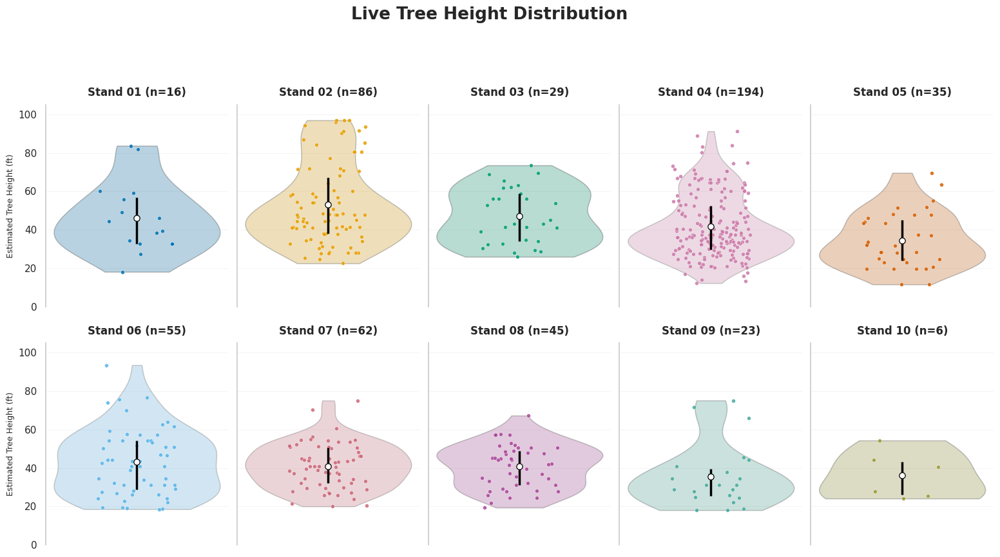

In [142]:

# ============================================================
# STEP 102
# ============================================================
# Included tree statuses:
# AL = Alive
# DA = Damaged
# DY = Dying
#
# Height-specific exclusion:
# Measurements above 100 ft are excluded from this visualization.
# These exclusions do not affect the DBH or species-richness analyses.


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLOR PALETTE
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',  # Blue
    2: '#E69F00',  # Orange
    3: '#009E73',  # Bluish green
    4: '#CC79A7',  # Reddish purple
    5: '#D55E00',  # Vermillion
    6: '#56B4E9',   # Sky blue,
    7: '#CC6677',  # Additional stand color
    8: '#AA4499',  # Additional stand color
    9: '#44AA99',  # Additional stand color
    10: '#999933'  # Additional stand color
}


# ------------------------------------------------------------
# 3. PREPARE THE UPDATED LIVING-TREE HEIGHT DATA
# ------------------------------------------------------------

# Start with the updated living-tree dataset.
# This includes Alive, Damaged, and Dying trees.
height_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 11))
].copy()

# Remove records without a recorded estimated tree height.
height_df = height_df.dropna(
    subset=['Estimated Tree Height (ft)']
)

# Count the number of height observations above 100 ft
# before applying the visualization-specific exclusion.
excluded_height_df = height_df[
    height_df['Estimated Tree Height (ft)'] > 100
].copy()

# Count excluded observations by stand.
excluded_by_stand = (
    excluded_height_df.groupby('Stand ID')
    .size()
    .reindex(range(1, 11), fill_value=0)
)

# Exclude observations above 100 ft from this figure.
height_df = height_df[
    height_df['Estimated Tree Height (ft)'] <= 100
].copy()

# Remove any remaining invalid or nonpositive height measurements.
height_df = height_df[
    height_df['Estimated Tree Height (ft)'] > 0
].copy()


# ------------------------------------------------------------
# 4. VALIDATE THE UPDATED HEIGHT DATA
# ------------------------------------------------------------

# Calculate the number of observations remaining in each stand.
height_sample_sizes = (
    height_df.groupby('Stand ID')
    .size()
    .reindex(range(1, 11), fill_value=0)
)

# Print the number of observations excluded above 100 ft.
print("Height observations excluded above 100 ft:")
print(excluded_by_stand)

# Print the updated sample sizes used in the figure.
print("\nUpdated height sample sizes by stand:")
print(height_sample_sizes)

# Print the total number of excluded observations.
print(
    "\nTotal observations excluded:",
    int(excluded_by_stand.sum())
)

# Print the total number of observations used in the figure.
print(
    "Total observations included:",
    len(height_df)
)


# ------------------------------------------------------------
# 5. SET THE FIGURE STYLE AND CREATE SIX PANELS
# ------------------------------------------------------------

# Apply the clean white-grid plotting theme.
sns.set_theme(
    style='whitegrid',
    context='notebook'
)

# Create a two-row, three-column figure.
fig, axes = plt.subplots(
    nrows=2,
    ncols=5,
    figsize=(16, 9),
    sharey=True
)

# Flatten the axes array for easier iteration.
axes = axes.flatten()


# ------------------------------------------------------------
# 6. PLOT THE HEIGHT DISTRIBUTION FOR EACH STAND
# ------------------------------------------------------------

# Loop through all ten stands.
for stand, ax in zip(range(1, 11), axes):

    # Extract height measurements for the current stand.
    stand_data = height_df.loc[
        height_df['Stand ID'] == stand,
        'Estimated Tree Height (ft)'
    ].dropna()

    # Convert measurements into a NumPy array.
    height_values = stand_data.to_numpy()

    # Retrieve the original color for this stand.
    stand_color = stand_colors[stand]

    # Calculate the median height.
    median_height = np.median(height_values)

    # Calculate the first and third quartiles.
    q1 = np.percentile(height_values, 25)
    q3 = np.percentile(height_values, 75)

    # Calculate the mean height.
    mean_height = np.mean(height_values)

    # Draw the violin distribution.
    sns.violinplot(
        y=height_values,
        x=np.zeros(len(height_values)),
        color=stand_color,
        inner=None,
        cut=0,
        linewidth=1.1,
        width=0.85,
        ax=ax
    )

    # Make the violin transparent enough to show individual points.
    for collection in ax.collections:
        collection.set_alpha(0.30)

    # Generate reproducible horizontal jitter for individual trees.
    rng = np.random.default_rng(seed=stand)

    # Slightly spread points horizontally to reduce overlap.
    jitter = rng.uniform(
        -0.20,
        0.20,
        size=len(height_values)
    )

    # Plot individual tree-height observations.
    ax.scatter(
        jitter,
        height_values,
        s=18,
        color=stand_color,
        edgecolor='white',
        linewidth=0.35,
        alpha=0.85,
        zorder=4
    )

    # Draw the interquartile range as a black vertical line.
    ax.vlines(
        x=0,
        ymin=q1,
        ymax=q3,
        color='black',
        linewidth=2.5,
        zorder=5
    )

    # Add a white circular marker for the mean height.
    ax.scatter(
        0,
        mean_height,
        s=45,
        facecolor='white',
        edgecolor='black',
        linewidth=0.9,
        zorder=6
    )

    # Add the stand number and updated sample size.
    ax.set_title(
        f'Stand {stand:02d} (n={len(height_values)})',
        fontsize=12,
        fontweight='bold',
        pad=10
    )

    # Label the vertical axis.
    ax.set_ylabel(
        'Estimated Tree Height (ft)',
        fontsize=9
    )

    # Remove horizontal-axis ticks and labels.
    ax.set_xticks([])
    ax.set_xlabel('')

    # Keep the same height scale across all ten panels.
    ax.set_ylim(0, 105)

    # Add subtle horizontal gridlines.
    ax.grid(
        axis='y',
        alpha=0.25,
        linewidth=0.6
    )

    # Keep gridlines behind the plotted data.
    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    sns.despine(
        ax=ax,
        bottom=True
    )


# ------------------------------------------------------------
# 7. ADD THE FIGURE TITLE AND SUBTITLE
# ------------------------------------------------------------

# Add the main title.
fig.suptitle(
    'Live Tree Height Distribution',
    fontsize=19,
    fontweight='bold',
    y=0.98
)


# ------------------------------------------------------------
# 8. ADJUST SPACING
# ------------------------------------------------------------

# Adjust spacing to prevent titles and axes from overlapping.
plt.tight_layout(
    rect=[0.02, 0.02, 1, 0.91],
    h_pad=1.2,
    w_pad=0.8
)


# ------------------------------------------------------------
# 9. SAVE AND DISPLAY THE FIGURE
# ------------------------------------------------------------

# Save the updated figure as a high-resolution PNG.
fig.savefig(
    export_dir / 'Living_Tree_Height_Distribution.png',
    dpi=600,
    bbox_inches='tight'
)

# Save a vector PDF version.
fig.savefig(
    export_dir / 'Living_Tree_Height_Distribution.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()


In [143]:

# ============================================================
# STEP 103
# ============================================================

# Group the filtered height dataset by Stand ID.
height_summary = (
    height_df
    .groupby('Stand ID')['Estimated Tree Height (ft)']
    .agg(
        n='count',                                      # Number of trees measured
        Mean='mean',                                    # Average tree height
        Median='median',                                # Middle tree height
        SD='std',                                       # Standard deviation
        Minimum='min',                                  # Shortest tree
        Q1=lambda x: x.quantile(0.25),                   # 25th percentile
        Q3=lambda x: x.quantile(0.75),                   # 75th percentile
        Maximum='max'                                   # Tallest tree
    )
    .reindex(range(1, 11))                               # Order stands 1–6
)

# Label the index as Stand.
height_summary.index.name = 'Stand'

# Round measurements to two decimal places.
height_summary = height_summary.round(2)

# Display the summary statistics table.
display(height_summary)

# Print the total number of observations included.
print(
    "Total height observations included:",
    int(height_summary['n'].sum())
)

# Print the total number of observations excluded above 100 ft.
print(
    "Total observations excluded above 100 ft:",
    len(excluded_height_df)
)


,n,Mean,Median,SD,Minimum,Q1,Q3,Maximum
Stand,,,,,,,,
1,16,45.99,41.83,18.41,18.04,32.81,56.59,83.66
2,86,53.09,47.70,20.86,22.47,37.90,67.05,96.95
3,29,47.15,43.18,14.50,25.89,33.96,58.92,73.49
4,194,41.67,37.40,16.41,12.14,29.68,52.35,91.21
5,35,34.39,31.82,14.19,11.48,23.79,44.91,69.55
6,55,43.06,42.65,17.34,18.54,28.71,54.13,93.50
7,62,41.01,40.68,11.75,20.01,32.10,50.44,75.07
8,45,40.94,42.32,11.34,19.36,31.17,48.88,67.26
9,23,35.56,31.17,15.96,18.04,25.34,39.37,75.13


Total height observations included: 551
Total observations excluded above 100 ft: 14


HEIGHT–DBH DATA PREPARATION
----------------------------------------
Observations available for plotting: 551
Observations above 100 ft excluded: 14
Total observations before height exclusion: 565

Observations by stand:
Stand ID
1      16
2      86
3      29
4     194
5      35
6      55
7      62
8      45
9      23
10      6
dtype: int64


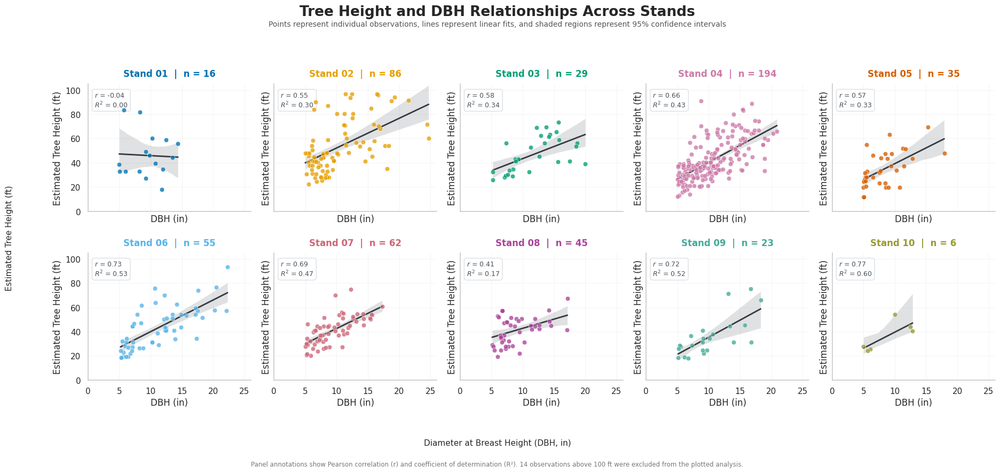


FINAL FIGURE SUMMARY
----------------------------------------
Stands represented: 10
Stand IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Observations included: 551
Observations excluded (>100 ft): 14
Total observations evaluated: 565
PNG and PDF exports completed.


In [147]:

# ============================================================
# STEP 104
# ============================================================

# This cell prepares the data, validates the observations,
# creates all ten panels, and exports the finished figure.


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from scipy.stats import pearsonr


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL TEN-STAND COLORS
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

stand_order = list(range(1, 11))


# ------------------------------------------------------------
# 3. PREPARE THE HEIGHT–DBH DATASET
# ------------------------------------------------------------

# Start with the living-tree analysis dataset.
height_dbh_df = live_trees_analysis.copy()

# Confirm that the required columns exist.
required_columns = [
    'Stand ID',
    'DBH (in)',
    'Estimated Tree Height (ft)'
]

missing_columns = [
    column for column in required_columns
    if column not in height_dbh_df.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}\n"
        f"Available columns: {height_dbh_df.columns.tolist()}"
    )

# Restrict analysis to the ten stands.
height_dbh_df = height_dbh_df[
    height_dbh_df['Stand ID'].isin(stand_order)
].copy()

# Convert DBH and estimated height to numeric values.
height_dbh_df['DBH (in)'] = pd.to_numeric(
    height_dbh_df['DBH (in)'],
    errors='coerce'
)

height_dbh_df['Estimated Tree Height (ft)'] = pd.to_numeric(
    height_dbh_df['Estimated Tree Height (ft)'],
    errors='coerce'
)

# Remove observations without either measurement.
height_dbh_df = height_dbh_df.dropna(
    subset=[
        'DBH (in)',
        'Estimated Tree Height (ft)'
    ]
).copy()

# Remove non-positive measurements.
height_dbh_df = height_dbh_df[
    (height_dbh_df['DBH (in)'] > 0) &
    (height_dbh_df['Estimated Tree Height (ft)'] > 0)
].copy()


# ------------------------------------------------------------
# 4. IDENTIFY AND EXCLUDE HEIGHTS ABOVE 100 FEET
# ------------------------------------------------------------

# Preserve observations exceeding 100 feet separately.
height_dbh_excluded = height_dbh_df[
    height_dbh_df['Estimated Tree Height (ft)'] > 100
].copy()

# Retain observations at or below 100 feet for plotting.
height_dbh_df = height_dbh_df[
    height_dbh_df['Estimated Tree Height (ft)'] <= 100
].copy()

# Confirm that the prepared dataset contains observations.
print("HEIGHT–DBH DATA PREPARATION")
print("----------------------------------------")

print(
    "Observations available for plotting:",
    len(height_dbh_df)
)

print(
    "Observations above 100 ft excluded:",
    len(height_dbh_excluded)
)

print(
    "Total observations before height exclusion:",
    len(height_dbh_df) + len(height_dbh_excluded)
)

print("\nObservations by stand:")

print(
    height_dbh_df
    .groupby('Stand ID')
    .size()
    .reindex(stand_order, fill_value=0)
)

# Ensure that the dataset is not empty.
if height_dbh_df.empty:
    raise ValueError(
        "No valid height–DBH observations remain after filtering."
    )


# ------------------------------------------------------------
# 5. SET THE PLOTTING THEME
# ------------------------------------------------------------

sns.set_theme(
    style='whitegrid',
    context='notebook'
)


# ------------------------------------------------------------
# 6. CREATE TEN PANELS — TWO ROWS BY FIVE COLUMNS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=2,
    ncols=5,
    figsize=(19, 9),
    sharex=True,
    sharey=True
)

axes = axes.flatten()


# ------------------------------------------------------------
# 7. PLOT EACH STAND
# ------------------------------------------------------------

for stand, ax in zip(stand_order, axes):

    # Extract the current stand's observations.
    stand_data = height_dbh_df[
        height_dbh_df['Stand ID'] == stand
    ].copy()

    # Extract DBH and estimated height.
    x = stand_data['DBH (in)']
    y = stand_data['Estimated Tree Height (ft)']

    # Retrieve stand-specific color.
    stand_color = stand_colors[stand]

    # Determine sample size.
    n = len(stand_data)

    # --------------------------------------------------------
    # HANDLE STANDS WITHOUT AVAILABLE OBSERVATIONS
    # --------------------------------------------------------

    if n == 0:

        ax.set_title(
            f'Stand {stand:02d}  |  n = 0',
            fontsize=12,
            fontweight='bold',
            color=stand_color,
            pad=10
        )

        ax.text(
            0.5,
            0.5,
            'No observations available',
            transform=ax.transAxes,
            ha='center',
            va='center',
            fontsize=9,
            color='#777777'
        )

        ax.set_xlim(0, 26)
        ax.set_ylim(0, 105)

        ax.set_xticks(np.arange(0, 26, 5))
        ax.set_yticks(np.arange(0, 101, 20))

        sns.despine(ax=ax)

        continue

    # --------------------------------------------------------
    # DRAW REGRESSION LINE AND 95% CONFIDENCE INTERVAL
    # --------------------------------------------------------

    if n >= 2 and x.nunique() > 1:

        sns.regplot(
            data=stand_data,
            x='DBH (in)',
            y='Estimated Tree Height (ft)',
            scatter=False,
            ci=95,
            color=stand_color,
            line_kws={
                'color': '#343A40',
                'linewidth': 2
            },
            ax=ax
        )

    # --------------------------------------------------------
    # ADD INDIVIDUAL OBSERVATIONS
    # --------------------------------------------------------

    ax.scatter(
        x,
        y,
        s=38,
        color=stand_color,
        alpha=0.78,
        edgecolors='white',
        linewidths=0.5,
        zorder=4
    )

    # --------------------------------------------------------
    # CALCULATE PEARSON CORRELATION AND R-SQUARED
    # --------------------------------------------------------

    if n >= 2 and x.nunique() > 1 and y.nunique() > 1:

        r_value, p_value = pearsonr(x, y)

        r_squared = r_value ** 2

        annotation = (
            f'$r$ = {r_value:.2f}\n'
            f'$R^2$ = {r_squared:.2f}'
        )

    else:

        annotation = 'Insufficient variation'

    # --------------------------------------------------------
    # ADD STATISTICAL ANNOTATION
    # --------------------------------------------------------

    ax.text(
        0.04,
        0.94,
        annotation,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=9,
        color='#495057',
        bbox={
            'boxstyle': 'round,pad=0.35',
            'facecolor': 'white',
            'edgecolor': '#D9DEE3',
            'alpha': 0.95
        }
    )

    # --------------------------------------------------------
    # ADD STAND TITLE AND SAMPLE SIZE
    # --------------------------------------------------------

    ax.set_title(
        f'Stand {stand:02d}  |  n = {n}',
        fontsize=12,
        fontweight='bold',
        color=stand_color,
        pad=10
    )

    # --------------------------------------------------------
    # APPLY CONSISTENT AXIS LIMITS AND TICKS
    # --------------------------------------------------------

    ax.set_xlim(0, 26)
    ax.set_ylim(0, 105)

    ax.set_xticks(
        np.arange(0, 26, 5)
    )

    ax.set_yticks(
        np.arange(0, 101, 20)
    )

    # --------------------------------------------------------
    # ADD SUBTLE GRIDLINES
    # --------------------------------------------------------

    ax.grid(
        True,
        alpha=0.25,
        linewidth=0.6
    )

    ax.set_axisbelow(True)

    # Remove unnecessary borders.
    sns.despine(ax=ax)


# ------------------------------------------------------------
# 8. ADD FIGURE TITLE AND SUBTITLE
# ------------------------------------------------------------

fig.suptitle(
    'Tree Height and DBH Relationships Across Stands',
    fontsize=19,
    fontweight='bold',
    y=0.985
)

# Corrected subtitle: comma added after 0.94.
fig.text(
    0.5,
    0.94,
    'Points represent individual observations, '
    'lines represent linear fits, and shaded regions represent '
    '95% confidence intervals',
    ha='center',
    fontsize=10,
    color='#555555'
)


# ------------------------------------------------------------
# 9. ADD SHARED AXIS LABELS
# ------------------------------------------------------------

fig.supxlabel(
    'Diameter at Breast Height (DBH, in)',
    fontsize=11,
    y=0.065
)

fig.supylabel(
    'Estimated Tree Height (ft)',
    fontsize=11,
    x=0.015
)


# ------------------------------------------------------------
# 10. ADD FOOTNOTE
# ------------------------------------------------------------

fig.text(
    0.5,
    0.025,
    f'Panel annotations show Pearson correlation (r) and '
    f'coefficient of determination (R²). '
    f'{len(height_dbh_excluded)} observations above 100 ft '
    f'were excluded from the plotted analysis.',
    ha='center',
    fontsize=8.5,
    color='#777777'
)


# ------------------------------------------------------------
# 11. FINALIZE FIGURE LAYOUT
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0.035, 0.09, 1, 0.92],
    h_pad=1.6,
    w_pad=1.2
)


# ------------------------------------------------------------
# 12. EXPORT FIGURE
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'Tree_Height_DBH_Relationships.png',
    dpi=600,
    bbox_inches='tight'
)

fig.savefig(
    export_dir / 'Tree_Height_DBH_Relationships.pdf',
    bbox_inches='tight'
)


# ------------------------------------------------------------
# 13. DISPLAY FIGURE
# ------------------------------------------------------------

plt.show()


# ------------------------------------------------------------
# 14. FINAL QUALITY-CONTROL SUMMARY
# ------------------------------------------------------------

print("\nFINAL FIGURE SUMMARY")
print("----------------------------------------")

print("Stands represented:", len(stand_order))
print("Stand IDs:", stand_order)

print(
    "Observations included:",
    len(height_dbh_df)
)

print(
    "Observations excluded (>100 ft):",
    len(height_dbh_excluded)
)

print(
    "Total observations evaluated:",
    len(height_dbh_df) + len(height_dbh_excluded)
)

print("PNG and PDF exports completed.")


Updated species contributions to stand basal area:


,Stand ID,Species Name,Total_Basal_Area,Tree_Count,Contribution (%)
2,1,Red Maple,2.84,3,27.34
0,1,American Beech,2.82,6,27.16
1,1,Eastern Hemlock,2.30,4,22.13
5,1,Yellow Birch,1.30,3,12.48
4,1,White Oak,0.58,1,5.54
...,...,...,...,...,...
69,9,Eastern Hemlock,0.15,1,1.00
76,10,Yellow Birch,1.62,3,57.67
75,10,White Oak,0.85,1,30.28
73,10,American Beech,0.20,1,7.21


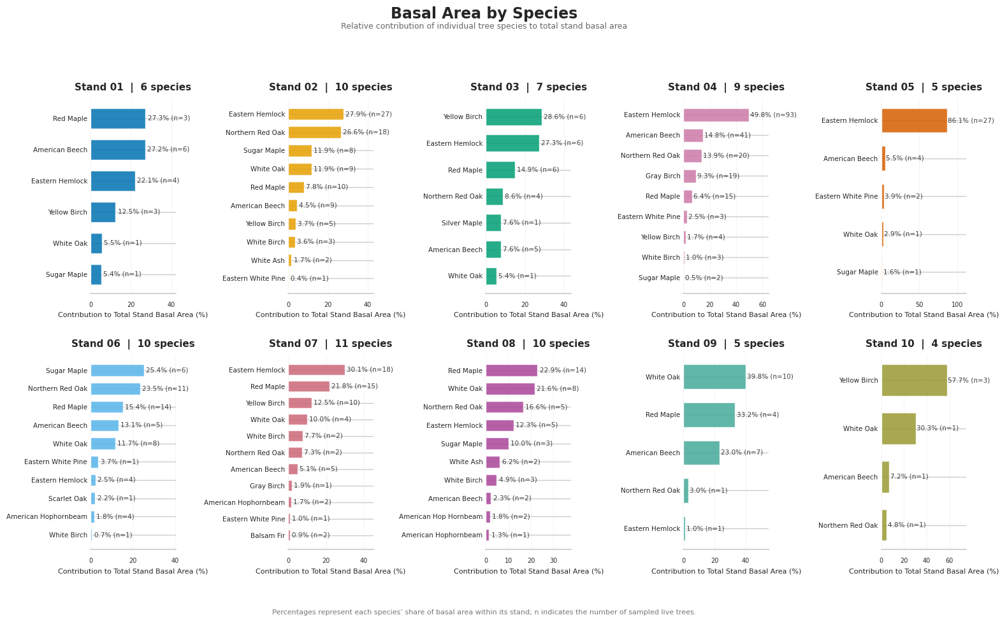

In [148]:

# ============================================================
# STEP 105
# ============================================================
#
# Includes Alive (AL), Damaged (DA), and Dying (DY) trees.
# Excludes dead trees and records without DBH measurements.
#
# Basal area per tree is calculated from DBH in inches:
# BA (sq ft) = pi * (DBH / 24)^2


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL STAND COLORS
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',  # Additional stand color
    8: '#AA4499',  # Additional stand color
    9: '#44AA99',  # Additional stand color
    10: '#999933'  # Additional stand color
}


# ------------------------------------------------------------
# 3. PREPARE THE UPDATED LIVING-TREE DATA
# ------------------------------------------------------------

# Start with the updated living-tree population.
basal_species_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 11))
].copy()

# Remove trees without DBH or species identification.
basal_species_df = basal_species_df.dropna(
    subset=['DBH (in)', 'Species Name']
)

# Retain positive DBH measurements.
basal_species_df = basal_species_df[
    basal_species_df['DBH (in)'] > 0
].copy()

# Calculate basal area for each individual tree.
# DBH is divided by 24 to convert diameter in inches
# to radius in feet.
basal_species_df['Basal Area (sq ft)'] = (
    np.pi * (basal_species_df['DBH (in)'] / 24) ** 2
)


# ------------------------------------------------------------
# 4. SUM BASAL AREA BY STAND AND SPECIES
# ------------------------------------------------------------

# Sum individual tree basal area for each species in each stand.
species_basal_area = (
    basal_species_df
    .groupby(['Stand ID', 'Species Name'])
    .agg(
        Total_Basal_Area=('Basal Area (sq ft)', 'sum'),
        Tree_Count=('DBH (in)', 'count')
    )
    .reset_index()
)

# Calculate total basal area within each stand.
stand_basal_totals = (
    species_basal_area
    .groupby('Stand ID')['Total_Basal_Area']
    .transform('sum')
)

# Calculate each species' percentage contribution to its stand.
species_basal_area['Contribution (%)'] = (
    species_basal_area['Total_Basal_Area']
    / stand_basal_totals * 100
)

# Print the updated species contribution table.
print("Updated species contributions to stand basal area:")
display(
    species_basal_area.sort_values(
        ['Stand ID', 'Contribution (%)'],
        ascending=[True, False]
    ).round(2)
)


# ------------------------------------------------------------
# 5. CREATE THE SIX-PANEL FIGURE
# ------------------------------------------------------------

# Create a two-row, three-column layout.
fig, axes = plt.subplots(
    2, 5,
    figsize=(16, 10)
)

# Flatten the axes for easier iteration.
axes = axes.flatten()


# ------------------------------------------------------------
# 6. DRAW SPECIES CONTRIBUTION BARS
# ------------------------------------------------------------

# Plot each stand separately.
for stand, ax in zip(range(1, 11), axes):

    # Select species data for the current stand.
    stand_data = species_basal_area[
        species_basal_area['Stand ID'] == stand
    ].copy()

    # Sort species from greatest to smallest contribution.
    stand_data = stand_data.sort_values(
        'Contribution (%)',
        ascending=True
    )

    # Retrieve the original stand color.
    stand_color = stand_colors[stand]

    # Draw horizontal bars.
    bars = ax.barh(
        stand_data['Species Name'],
        stand_data['Contribution (%)'],
        color=stand_color,
        height=0.65,
        alpha=0.85
    )

    # Add percentage and tree-count labels to each bar.
    for bar, (_, record) in zip(bars, stand_data.iterrows()):

        # Retrieve the bar's endpoint.
        bar_width = bar.get_width()

        # Add the percentage and tree count.
        ax.text(
            bar_width + 1.0,
            bar.get_y() + bar.get_height() / 2,
            f"{record['Contribution (%)']:.1f}% (n={int(record['Tree_Count'])})",
            va='center',
            fontsize=7.5,
            color='#404040'
        )

    # Calculate the number of species in the stand.
    species_count = len(stand_data)

    # Add the stand title.
    ax.set_title(
        f'Stand {stand:02d}  |  {species_count} species',
        fontsize=11,
        fontweight='bold',
        pad=10
    )

    # Label the horizontal axis.
    ax.set_xlabel(
        'Contribution to Total Stand Basal Area (%)',
        fontsize=8
    )

    # Remove the vertical-axis label.
    ax.set_ylabel('')

    # Set the horizontal limit based on the largest contribution.
    max_contribution = stand_data['Contribution (%)'].max()

    ax.set_xlim(
        0,
        max_contribution + max(15, max_contribution * 0.30)
    )

    # Format gridlines.
    ax.grid(
        axis='x',
        alpha=0.25,
        linewidth=0.6
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Format species labels.
    ax.tick_params(
        axis='y',
        labelsize=7.5,
        length=0
    )

    ax.tick_params(
        axis='x',
        labelsize=7
    )

    # Remove unnecessary borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)


# ------------------------------------------------------------
# 7. ADD FIGURE TITLE AND FOOTNOTE
# ------------------------------------------------------------

fig.suptitle(
    'Basal Area by Species',
    fontsize=17,
    fontweight='bold',
    y=0.98
)

fig.text(
    0.5,
    0.945,
    'Relative contribution of individual tree species to total stand basal area',
    ha='center',
    fontsize=9,
    color='#666666'
)

fig.text(
    0.5,
    0.025,
    'Percentages represent each species’ share of basal area within its stand; '
    'n indicates the number of sampled live trees.',
    ha='center',
    fontsize=8,
    color='#777777'
)

# Adjust spacing.
plt.tight_layout(
    rect=[0.02, 0.07, 1, 0.92],
    h_pad=2.0,
    w_pad=2.0
)


# ------------------------------------------------------------
# 8. SAVE AND DISPLAY
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'Species_Contributions_Living_Tree_Basal_Area.png',
    dpi=600,
    bbox_inches='tight'
)

fig.savefig(
    export_dir / 'Species_Contributions_Living_Tree_Basal_Area.pdf',
    bbox_inches='tight'
)

plt.show()


Subplot area: 7238.23 sq ft
Basal area expansion factor: 6.018

Individual living trees included: 565


,Stand ID,Plot ID,Subplot ID,DBH (in),Basal Area (sq ft)
0,1,1,1,8.30,0.375737
1,1,1,1,8.25,0.371223
2,1,1,1,13.52,0.996967
3,1,1,1,5.98,0.195043
4,1,1,1,11.80,0.759436



Sampled subplots by stand:
Stand ID
1      1
2     15
3      6
4     22
5      3
6      7
7      9
8      6
9      5
10     1
dtype: int64

Total sampled subplots: 75

Subplot-level basal area density summary:


,n,Mean,Median,SD,Minimum,Q1,Q3,Maximum
Stand,,,,,,,,
1,1,62.51,62.51,NaN,62.51,62.51,62.51,62.51
2,15,27.11,24.27,15.98,8.32,13.61,35.65,58.37
3,6,25.17,23.15,8.57,14.60,20.33,30.89,37.27
4,22,38.52,36.41,13.58,13.57,29.55,46.78,78.41
5,3,29.05,24.32,16.81,15.12,19.72,36.02,47.72
6,7,38.33,37.38,15.26,18.07,29.14,45.94,62.69
7,9,22.27,22.10,10.16,7.62,21.48,23.88,38.58
8,6,21.66,22.62,9.27,6.51,19.96,23.51,35.35
9,5,17.78,15.63,6.58,10.63,13.60,22.37,26.67


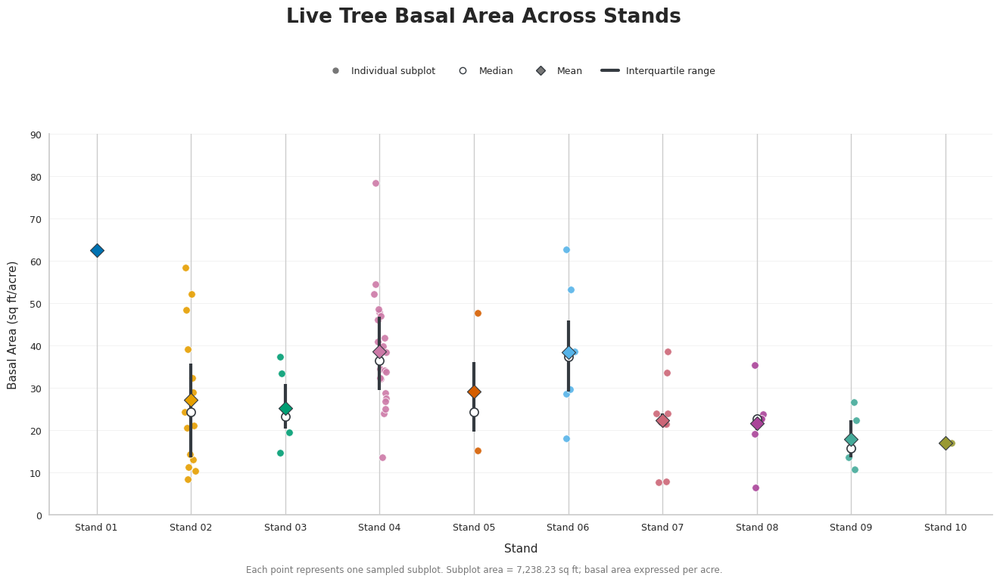


FINAL FIGURE SUMMARY
----------------------------------------
Stands represented: 10
Stand IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Individual living trees included: 565
Total sampled subplots: 75
Subplots by stand:
Stand ID
1      1
2     15
3      6
4     22
5      3
6      7
7      9
8      6
9      5
10     1
dtype: int64
PNG and PDF exports completed.


In [152]:

# ============================================================
# STEP 106
# ============================================================

# PURPOSE:
# Visualize the distribution of living-tree basal area density
# among sampled subplots across ten forest stands.
#
# INCLUDED TREE STATUS CATEGORIES:
# AL = Alive
# DA = Damaged
# DY = Dying
#
# CALCULATIONS:
# Individual tree basal area (sq ft) = pi * (DBH / 24)^2
# Subplot basal area = sum of individual tree basal areas
# Basal area density (sq ft/acre) =
#     subplot basal area * 43,560 / subplot area
#
# Each point represents one sampled subplot.
# Diamond = mean
# Hollow circle = median
# Vertical line = interquartile range


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.lines import Line2D


# ------------------------------------------------------------
# 2. DEFINE THE ORIGINAL TEN-STAND COLOR PALETTE
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

stand_order = list(range(1, 11))


# ------------------------------------------------------------
# 3. DEFINE THE SUBPLOT SAMPLING AREA
# ------------------------------------------------------------

# Set the sampled subplot area in square feet.
subplot_area_sqft = 7238.23

# Define the number of square feet in one acre.
sqft_per_acre = 43560

# Calculate the expansion factor.
expansion_factor = sqft_per_acre / subplot_area_sqft

print("Subplot area:", subplot_area_sqft, "sq ft")
print("Basal area expansion factor:", round(expansion_factor, 4))


# ------------------------------------------------------------
# 4. PREPARE THE UPDATED LIVING-TREE DATASET
# ------------------------------------------------------------

# Start with the updated living-tree inventory.
# This dataset should already include AL, DA, and DY trees.

basal_area_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(stand_order)
].copy()

# Confirm required columns exist.
required_columns = [
    'Stand ID',
    'Plot ID',
    'Subplot ID',
    'DBH (in)'
]

missing_columns = [
    column for column in required_columns
    if column not in basal_area_df.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}\n"
        f"Available columns: {basal_area_df.columns.tolist()}"
    )

# Convert DBH to numeric.
basal_area_df['DBH (in)'] = pd.to_numeric(
    basal_area_df['DBH (in)'],
    errors='coerce'
)

# Remove records without DBH measurements.
basal_area_df = basal_area_df.dropna(
    subset=['DBH (in)']
).copy()

# Remove records without plot or subplot identifiers.
basal_area_df = basal_area_df.dropna(
    subset=['Plot ID', 'Subplot ID']
).copy()

# Retain positive DBH measurements.
basal_area_df = basal_area_df[
    basal_area_df['DBH (in)'] > 0
].copy()

# Print the number of individual trees included.
print(
    "\nIndividual living trees included:",
    len(basal_area_df)
)


# ------------------------------------------------------------
# 5. CALCULATE INDIVIDUAL TREE BASAL AREA
# ------------------------------------------------------------

# DBH is measured in inches.
# Dividing by 24 converts diameter into radius in feet.

basal_area_df['Basal Area (sq ft)'] = (
    np.pi * (basal_area_df['DBH (in)'] / 24) ** 2
)

# Display the first few calculated records.
display(
    basal_area_df[
        [
            'Stand ID',
            'Plot ID',
            'Subplot ID',
            'DBH (in)',
            'Basal Area (sq ft)'
        ]
    ].head()
)


# ------------------------------------------------------------
# 6. CALCULATE TOTAL BASAL AREA WITHIN EACH SUBPLOT
# ------------------------------------------------------------

# Group individual trees by stand, plot, and subplot.
# Sum their basal areas to obtain total subplot basal area.

subplot_basal_summary = (
    basal_area_df
    .groupby(
        ['Stand ID', 'Plot ID', 'Subplot ID']
    )
    .agg(
        Total_Basal_Area=('Basal Area (sq ft)', 'sum'),
        Tree_Count=('DBH (in)', 'count')
    )
    .reset_index()
)

# Convert subplot basal area into basal area per acre.
subplot_basal_summary['Basal Area (sq ft/acre)'] = (
    subplot_basal_summary['Total_Basal_Area']
    * expansion_factor
)

# Print sampled subplots in each stand.
subplot_counts = (
    subplot_basal_summary
    .groupby('Stand ID')
    .size()
    .reindex(stand_order, fill_value=0)
)

print("\nSampled subplots by stand:")
print(subplot_counts)

print(
    "\nTotal sampled subplots:",
    len(subplot_basal_summary)
)


# ------------------------------------------------------------
# 7. CALCULATE STAND-LEVEL SUMMARY STATISTICS
# ------------------------------------------------------------

subplot_basal_stats = (
    subplot_basal_summary
    .groupby('Stand ID')['Basal Area (sq ft/acre)']
    .agg(
        n='count',
        Mean='mean',
        Median='median',
        SD='std',
        Minimum='min',
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        Maximum='max'
    )
    .reindex(stand_order)
)

subplot_basal_stats.index.name = 'Stand'

# Round numerical values to two decimal places.
subplot_basal_stats = subplot_basal_stats.round(2)

print("\nSubplot-level basal area density summary:")
display(subplot_basal_stats)


# ------------------------------------------------------------
# 8. SET UP THE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 8)
)

fig.patch.set_facecolor('white')
ax.set_facecolor('white')


# ------------------------------------------------------------
# 9. PLOT INDIVIDUAL SUBPLOT OBSERVATIONS
# ------------------------------------------------------------

for stand in stand_order:

    # Extract subplot basal area density for the current stand.
    stand_values = subplot_basal_summary.loc[
        subplot_basal_summary['Stand ID'] == stand,
        'Basal Area (sq ft/acre)'
    ].dropna().to_numpy()

    # Retrieve the original color for this stand.
    stand_color = stand_colors[stand]

    # Handle stands without sampled subplot observations.
    if len(stand_values) == 0:

        ax.text(
            stand,
            0,
            'No data',
            ha='center',
            va='bottom',
            fontsize=8,
            color=stand_color
        )

        continue

    # Calculate mean, median, and quartiles.
    mean_value = np.mean(stand_values)
    median_value = np.median(stand_values)
    q1 = np.percentile(stand_values, 25)
    q3 = np.percentile(stand_values, 75)

    # Generate reproducible horizontal jitter.
    rng = np.random.default_rng(seed=stand)

    jitter = rng.uniform(
        -0.07,
        0.07,
        size=len(stand_values)
    )

    # Plot individual subplot observations.
    ax.scatter(
        np.full(len(stand_values), stand) + jitter,
        stand_values,
        s=48,
        color=stand_color,
        alpha=0.90,
        edgecolors='white',
        linewidths=0.6,
        zorder=3
    )

    # Draw the interquartile range.
    ax.vlines(
        stand,
        q1,
        q3,
        color='#343A40',
        linewidth=3,
        zorder=4
    )

    # Add a hollow circle representing the median.
    ax.scatter(
        stand,
        median_value,
        s=65,
        marker='o',
        facecolor='white',
        edgecolor='#343A40',
        linewidth=1.2,
        zorder=5
    )

    # Add a colored diamond representing the mean.
    ax.scatter(
        stand,
        mean_value,
        s=85,
        marker='D',
        color=stand_color,
        edgecolor='#343A40',
        linewidth=0.8,
        zorder=6
    )


# ------------------------------------------------------------
# 10. FORMAT THE HORIZONTAL AXIS
# ------------------------------------------------------------

# Position all ten stands at equally spaced locations.
ax.set_xticks(range(1, 11))

# Label all ten stands.
ax.set_xticklabels(
    [f'Stand {i:02d}' for i in stand_order],
    fontsize=10
)

# IMPORTANT: Display all ten stands.
ax.set_xlim(0.5, 10.5)

ax.set_xlabel(
    'Stand',
    fontsize=11,
    labelpad=10
)


# ------------------------------------------------------------
# 11. FORMAT THE VERTICAL AXIS
# ------------------------------------------------------------

# Find the largest subplot basal area density.
maximum_value = subplot_basal_summary[
    'Basal Area (sq ft/acre)'
].max()

if pd.isna(maximum_value):
    raise ValueError(
        "No subplot basal area values are available."
    )

# Round the upper limit upward to the next 10-unit interval,
# then add an additional 10 units of visual space.
upper_limit = (
    np.ceil(maximum_value / 10) * 10 + 10
)

# Start the vertical axis at zero.
ax.set_ylim(0, upper_limit)

# Set vertical-axis ticks at 10-unit intervals.
ax.set_yticks(
    np.arange(0, upper_limit + 1, 10)
)

ax.set_ylabel(
    'Basal Area (sq ft/acre)',
    fontsize=11,
    labelpad=10
)


# ------------------------------------------------------------
# 12. FORMAT GRIDLINES AND AXIS BORDERS
# ------------------------------------------------------------

ax.grid(
    axis='y',
    alpha=0.25,
    linewidth=0.7
)

ax.set_axisbelow(True)

# Remove upper and right borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Keep remaining axis borders subtle.
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

ax.tick_params(
    axis='both',
    labelsize=9,
    length=4,
    color='#999999'
)


# ------------------------------------------------------------
# 13. CREATE THE LEGEND
# ------------------------------------------------------------

individual_handle = Line2D(
    [0], [0],
    marker='o',
    linestyle='none',
    markerfacecolor='#777777',
    markeredgecolor='#777777',
    markersize=5,
    label='Individual subplot'
)

median_handle = Line2D(
    [0], [0],
    marker='o',
    linestyle='none',
    markerfacecolor='white',
    markeredgecolor='#343A40',
    markersize=6,
    label='Median'
)

mean_handle = Line2D(
    [0], [0],
    marker='D',
    linestyle='none',
    markerfacecolor='#777777',
    markeredgecolor='#343A40',
    markersize=6,
    label='Mean'
)

iqr_handle = Line2D(
    [0], [0],
    color='#343A40',
    linewidth=3,
    label='Interquartile range'
)

# Add the legend above the plotting area.
ax.legend(
    handles=[
        individual_handle,
        median_handle,
        mean_handle,
        iqr_handle
    ],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.20),
    ncol=4,
    frameon=False,
    fontsize=9,
    handlelength=1.8,
    columnspacing=2.0
)


# ------------------------------------------------------------
# 14. ADD THE FIGURE TITLE
# ------------------------------------------------------------

fig.suptitle(
    'Live Tree Basal Area Across Stands',
    fontsize=19,
    fontweight='bold',
    y=0.97
)


# ------------------------------------------------------------
# 15. ADD THE FIGURE FOOTNOTE
# ------------------------------------------------------------

fig.text(
    0.5,
    0.035,
    (
        'Each point represents one sampled subplot. '
        f'Subplot area = {subplot_area_sqft:,.2f} sq ft; '
        'basal area expressed per acre.'
    ),
    ha='center',
    fontsize=8.5,
    color='#777777'
)


# ------------------------------------------------------------
# 16. FINALIZE THE FIGURE LAYOUT
# ------------------------------------------------------------

fig.subplots_adjust(
    top=0.76,
    bottom=0.13,
    left=0.09,
    right=0.98
)


# ------------------------------------------------------------
# 17. SAVE THE FIGURE
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'Living_Tree_Basal_Area_Across_Stands.png',
    dpi=600,
    bbox_inches='tight'
)

fig.savefig(
    export_dir / 'Living_Tree_Basal_Area_Across_Stands.pdf',
    bbox_inches='tight'
)


# ------------------------------------------------------------
# 18. DISPLAY THE COMPLETED FIGURE
# ------------------------------------------------------------

plt.show()


# ------------------------------------------------------------
# 19. FINAL QUALITY-CONTROL SUMMARY
# ------------------------------------------------------------

print("\nFINAL FIGURE SUMMARY")
print("----------------------------------------")

print("Stands represented:", len(stand_order))
print("Stand IDs:", stand_order)

print(
    "Individual living trees included:",
    len(basal_area_df)
)

print(
    "Total sampled subplots:",
    len(subplot_basal_summary)
)

print(
    "Subplots by stand:"
)

print(subplot_counts)

print("PNG and PDF exports completed.")


In [153]:

# ============================================================
# STEP 107
# ============================================================


# ------------------------------------------------------------
# 1. TREE-LEVEL BASAL AREA SUMMARY BY STAND
# ------------------------------------------------------------

# Group individual living trees by stand.
# Calculate the number of trees, mean basal area per tree,
# and total sampled basal area for each stand.
tree_basal_area_stats = (
    basal_area_df
    .groupby('Stand ID')
    .agg(
        Trees=('Basal Area (sq ft)', 'count'),
        Mean_Basal_Area=('Basal Area (sq ft)', 'mean'),
        Total_Sampled_Basal_Area=('Basal Area (sq ft)', 'sum')
    )
    .reindex(range(1, 11))
)

# Rename the stand index.
tree_basal_area_stats.index.name = 'Stand'

# Rename columns for presentation.
tree_basal_area_stats = tree_basal_area_stats.rename(
    columns={
        'Mean_Basal_Area': 'Mean basal area (ft²/tree)',
        'Total_Sampled_Basal_Area': 'Total sampled basal area (ft²)'
    }
)

# Round basal-area measurements to three decimal places.
tree_basal_area_stats = tree_basal_area_stats.round(3)

# Display the tree-level summary table.
print("TREE-LEVEL BASAL AREA SUMMARY")
display(tree_basal_area_stats)

# Print the total number of individual trees.
print(
    "Total living trees:",
    int(tree_basal_area_stats['Trees'].sum())
)


# ------------------------------------------------------------
# 2. SUBPLOT-LEVEL BASAL AREA DENSITY SUMMARY BY STAND
# ------------------------------------------------------------

# Group subplot-level basal area density by stand.
# Calculate the mean basal area per acre and subplot count.
subplot_basal_area_stats = (
    subplot_basal_summary
    .groupby('Stand ID')
    .agg(
        Mean_Basal_Area_per_Acre=(
            'Basal Area (sq ft/acre)',
            'mean'
        ),
        Subplots=('Basal Area (sq ft/acre)', 'count')
    )
    .reindex(range(1, 11))
)

# Rename the stand index.
subplot_basal_area_stats.index.name = 'Stand'

# Rename the mean basal-area column.
subplot_basal_area_stats = subplot_basal_area_stats.rename(
    columns={
        'Mean_Basal_Area_per_Acre': 'Mean basal area (ft²/acre)'
    }
)

# Round basal-area density to two decimal places.
subplot_basal_area_stats = subplot_basal_area_stats.round(2)

# Display the subplot-level summary table.
print("\nSUBPLOT-LEVEL BASAL AREA DENSITY SUMMARY")
display(subplot_basal_area_stats)

# Print the total number of sampled subplots.
print(
    "Total sampled subplots:",
    int(subplot_basal_area_stats['Subplots'].sum())
)


# ------------------------------------------------------------
# 3. EXPORT BOTH TABLES
# ------------------------------------------------------------

# Export the tree-level summary as a CSV file.
tree_basal_area_stats.to_csv(
    export_dir / 'Living_Tree_Basal_Area_Summary.csv'
)

# Export the subplot-level summary as a CSV file.
subplot_basal_area_stats.to_csv(
    export_dir / 'Living_Tree_Subplot_Basal_Area_Summary.csv'
)

print("\nBoth summary tables have been exported.")


TREE-LEVEL BASAL AREA SUMMARY


,Trees,Mean basal area (ft²/tree),Total sampled basal area (ft²)
Stand,,,
1,18,0.577,10.387
2,92,0.735,67.579
3,29,0.865,25.098
4,200,0.704,140.831
5,35,0.414,14.484
6,55,0.811,44.582
7,62,0.537,33.303
8,45,0.480,21.600
9,23,0.642,14.772


Total living trees: 565

SUBPLOT-LEVEL BASAL AREA DENSITY SUMMARY


,Mean basal area (ft²/acre),Subplots
Stand,,
1,62.51,1
2,27.11,15
3,25.17,6
4,38.52,22
5,29.05,3
6,38.33,7
7,22.27,9
8,21.66,6
9,17.78,5


Total sampled subplots: 75

Both summary tables have been exported.


In [154]:

# ============================================================
# STEP 108
# ============================================================
#
# Includes:
# AL = Alive
# DA = Damaged
# DY = Dying
#
# Relative abundance (%) =
# (Number of individuals of a species / Total living trees in stand) * 100


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

# Import Pandas for grouping and summarizing the tree inventory.
import pandas as pd

# Import NumPy for numerical validation.
import numpy as np


# ------------------------------------------------------------
# 2. PREPARE THE UPDATED LIVING-TREE DATA
# ------------------------------------------------------------

# Use the updated living-tree dataset containing AL, DA, and DY.
# Restrict the analysis to the six study stands.
tree_composition_df = live_trees_analysis[
    live_trees_analysis['Stand ID'].isin(range(1, 11))
].copy()

# Remove records without a species identification.
# Unidentified trees cannot be assigned to a species category.
tree_composition_df = tree_composition_df.dropna(
    subset=['Species Name']
)

# Remove any accidental whitespace from species names.
tree_composition_df['Species Name'] = (
    tree_composition_df['Species Name']
    .astype(str)
    .str.strip()
)

# Remove blank species-name records.
tree_composition_df = tree_composition_df[
    tree_composition_df['Species Name'] != ''
].copy()


# ------------------------------------------------------------
# 3. COUNT INDIVIDUAL TREES BY SPECIES AND STAND
# ------------------------------------------------------------

# Count the number of individual trees belonging to each species
# within each stand.
tree_species_counts = (
    tree_composition_df
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .reset_index(name='Tree Count')
)

# Calculate the total number of living trees in each stand.
stand_tree_totals = (
    tree_species_counts
    .groupby('Stand ID')['Tree Count']
    .sum()
    .rename('Stand Total')
)

# Attach each stand's total tree count to the species table.
tree_species_counts = tree_species_counts.merge(
    stand_tree_totals,
    on='Stand ID',
    how='left'
)


# ------------------------------------------------------------
# 4. CALCULATE RELATIVE ABUNDANCE
# ------------------------------------------------------------

# Calculate each species' percentage contribution to the
# total number of living trees within its stand.
tree_species_counts['Relative Abundance (%)'] = (
    tree_species_counts['Tree Count']
    / tree_species_counts['Stand Total']
    * 100
)

# Round relative abundance to two decimal places.
tree_species_counts['Relative Abundance (%)'] = (
    tree_species_counts['Relative Abundance (%)'].round(2)
)


# ------------------------------------------------------------
# 5. SORT THE RESULTS
# ------------------------------------------------------------

# Sort species within each stand from greatest to lowest
# relative abundance.
tree_species_counts = tree_species_counts.sort_values(
    ['Stand ID', 'Relative Abundance (%)'],
    ascending=[True, False]
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. DISPLAY THE RELATIVE ABUNDANCE TABLE
# ------------------------------------------------------------

# Display the complete species-level results.
print("TREE SPECIES RELATIVE ABUNDANCE BY STAND")

display(tree_species_counts)


# ------------------------------------------------------------
# 7. VALIDATE THE RESULTS
# ------------------------------------------------------------

# Sum relative abundance within each stand.
# Each stand should total approximately 100%.
relative_abundance_check = (
    tree_species_counts
    .groupby('Stand ID')['Relative Abundance (%)']
    .sum()
)

print("\nRelative abundance totals by stand:")
display(relative_abundance_check.round(2))

# Print the number of individual trees represented.
print(
    "\nTotal trees represented:",
    int(tree_species_counts['Tree Count'].sum())
)

# Print the total number of unique tree species.
print(
    "Total unique tree species:",
    tree_species_counts['Species Name'].nunique()
)

# Check whether relative abundance sums to approximately 100%.
assert np.allclose(
    relative_abundance_check.values,
    100,
    atol=0.1
), "Relative abundance does not sum to approximately 100% in every stand."

print("\nValidation passed: relative abundance sums to approximately 100% per stand.")


TREE SPECIES RELATIVE ABUNDANCE BY STAND


,Stand ID,Species Name,Tree Count,Stand Total,Relative Abundance (%)
0,1,American Beech,6,18,33.33
1,1,Eastern Hemlock,4,18,22.22
2,1,Red Maple,3,18,16.67
3,1,Yellow Birch,3,18,16.67
4,1,Sugar Maple,1,18,5.56
...,...,...,...,...,...
72,9,Northern Red Oak,1,23,4.35
73,10,Yellow Birch,3,6,50.00
74,10,American Beech,1,6,16.67
75,10,Northern Red Oak,1,6,16.67



Relative abundance totals by stand:


,Relative Abundance (%)
Stand ID,
1,100.01
2,100.00
3,100.00
4,100.00
5,100.00
6,100.00
7,100.00
8,99.99
9,100.00



Total trees represented: 565
Total unique tree species: 16

Validation passed: relative abundance sums to approximately 100% per stand.


In [155]:

# ============================================================
# STEP 109
# ============================================================

# Display the frequency of every recorded percent-cover value.
print("Herbaceous percent-cover values:")
print(
    herbaceous['Percent Cover (%)']
    .value_counts(dropna=False)
    .sort_index()
)

# Display the unique values without their frequencies.
print("\nUnique percent-cover values:")
print(sorted(herbaceous['Percent Cover (%)'].dropna().unique()))

# Count herbaceous records in each stand.
print("\nHerbaceous records by stand:")
print(
    herbaceous['Stand ID']
    .value_counts()
    .sort_index()
)

# Count unique identified species in each stand.
print("\nUnique herbaceous species by stand:")
print(
    herbaceous.dropna(subset=['Species Name'])
    .groupby('Stand ID')['Species Name']
    .nunique()
    .sort_index()
)

# Check for missing species identifications.
print("\nMissing species names:")
print(herbaceous['Species Name'].isna().sum())

Herbaceous percent-cover values:
Percent Cover (%)
1    271
2     14
3      2
Name: count, dtype: int64

Unique percent-cover values:
[np.int64(1), np.int64(2), np.int64(3)]

Herbaceous records by stand:
Stand ID
1      4
2     55
3     16
4     77
5     12
6     19
7     69
8     24
9      8
10     3
Name: count, dtype: int64

Unique herbaceous species by stand:
Stand ID
1      4
2     21
3      7
4     27
5      7
6      7
7     32
8     14
9      6
10     3
Name: Species Name, dtype: int64

Missing species names:
0


In [156]:

# ============================================================
# STEP 110
# ============================================================

# Keep only the ten stands included in the main analysis.
herbaceous_analysis = herbaceous[
    herbaceous['Stand ID'].isin(range(1, 11))
].copy()

# Remove any accidental whitespace from species names.
herbaceous_analysis['Species Name'] = (
    herbaceous_analysis['Species Name']
    .astype(str)
    .str.strip()
)

# Count the number of records for each species within each stand.
herbaceous_species_counts = (
    herbaceous_analysis
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .reset_index(name='Species Records')
)

# Calculate the total number of herbaceous records in each stand.
stand_herbaceous_totals = (
    herbaceous_species_counts
    .groupby('Stand ID')['Species Records']
    .sum()
    .rename('Stand Total')
)

# Add each stand's total record count to the species table.
herbaceous_species_counts = herbaceous_species_counts.merge(
    stand_herbaceous_totals,
    on='Stand ID',
    how='left'
)

# Calculate each species' relative frequency within its stand.
herbaceous_species_counts['Relative Frequency (%)'] = (
    herbaceous_species_counts['Species Records']
    / herbaceous_species_counts['Stand Total']
    * 100
)

# Round the relative frequencies to two decimal places.
herbaceous_species_counts['Relative Frequency (%)'] = (
    herbaceous_species_counts['Relative Frequency (%)'].round(2)
)

# Sort species from most to least frequent within each stand.
herbaceous_species_counts = (
    herbaceous_species_counts
    .sort_values(
        ['Stand ID', 'Relative Frequency (%)'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Display the resulting species composition table.
display(herbaceous_species_counts)

,Stand ID,Species Name,Species Records,Stand Total,Relative Frequency (%)
0,1,Christmas Fern,1,4,25.00
1,1,Interrupted Fern,1,4,25.00
2,1,Princess Pine,1,4,25.00
3,1,Starflower,1,4,25.00
4,2,Christmas Fern,9,55,16.36
...,...,...,...,...,...
123,9,Sensitive Fern,1,8,12.50
124,9,Stiff Clubmoss,1,8,12.50
125,10,Christmas Fern,1,3,33.33
126,10,Creeping Foam Flower,1,3,33.33


In [157]:

# ============================================================
# STEP 111
# ============================================================

# Keep only observations from Stands 1–10.
herbaceous_cover_analysis = herbaceous[
    herbaceous['Stand ID'].isin(range(1, 11))
].copy()

# Define descriptive labels for the recorded cover-class codes.
# These labels follow the cover-class key in the datasheet.
cover_class_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# Create a readable cover-class label column.
herbaceous_cover_analysis['Cover Class'] = (
    herbaceous_cover_analysis['Percent Cover (%)']
    .map(cover_class_labels)
)

# Count observations in each cover class within each stand.
herbaceous_cover_counts = (
    herbaceous_cover_analysis
    .groupby(['Stand ID', 'Cover Class'])
    .size()
    .reset_index(name='Observation Count')
)

# Calculate the total number of herbaceous observations in each stand.
herbaceous_stand_totals = (
    herbaceous_cover_analysis
    .groupby('Stand ID')
    .size()
    .rename('Stand Total')
)

# Add the stand totals to the cover-class summary.
herbaceous_cover_counts = herbaceous_cover_counts.merge(
    herbaceous_stand_totals,
    on='Stand ID',
    how='left'
)

# Calculate the percentage of observations in each cover class.
herbaceous_cover_counts['Observation Frequency (%)'] = (
    herbaceous_cover_counts['Observation Count']
    / herbaceous_cover_counts['Stand Total']
    * 100
)

# Round percentages to two decimal places.
herbaceous_cover_counts['Observation Frequency (%)'] = (
    herbaceous_cover_counts['Observation Frequency (%)'].round(2)
)

# Sort the results by stand and cover class.
herbaceous_cover_counts = (
    herbaceous_cover_counts
    .sort_values(['Stand ID', 'Cover Class'])
    .reset_index(drop=True)
)

# Display the cover-class distribution.
display(herbaceous_cover_counts)

,Stand ID,Cover Class,Observation Count,Stand Total,Observation Frequency (%)
0,1,0–25%,4,4,100.00
1,2,0–25%,54,55,98.18
2,2,25–50%,1,55,1.82
3,3,0–25%,12,16,75.00
4,3,25–50%,3,16,18.75
5,3,50–75%,1,16,6.25
6,4,0–25%,76,77,98.70
7,4,25–50%,1,77,1.30
8,5,0–25%,8,12,66.67
9,5,25–50%,4,12,33.33


In [158]:

# ============================================================
# STEP 112
# ============================================================
# within each stand.

# Keep only the ten stands included in the main analysis.
herbaceous_species_cover = herbaceous[
    herbaceous['Stand ID'].isin(range(1, 11))
].copy()

# Define readable labels for the four cover-class codes.
cover_class_labels = {
    1: '0–25%',
    2: '25–50%',
    3: '50–75%',
    4: '75–100%'
}

# Convert the numeric cover codes into descriptive categories.
herbaceous_species_cover['Cover Class'] = (
    herbaceous_species_cover['Percent Cover (%)']
    .map(cover_class_labels)
)

# Count observations for each species, stand, and cover class.
species_cover_counts = (
    herbaceous_species_cover
    .groupby(['Stand ID', 'Species Name', 'Cover Class'])
    .size()
    .reset_index(name='Observation Count')
)

# Calculate the total number of observations for each species in each stand.
species_stand_totals = (
    herbaceous_species_cover
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .reset_index(name='Species Total')
)

# Attach each species' total observations to its cover-class counts.
species_cover_counts = species_cover_counts.merge(
    species_stand_totals,
    on=['Stand ID', 'Species Name'],
    how='left'
)

# Calculate the percentage of each species' observations in each cover class.
species_cover_counts['Cover Class Frequency (%)'] = (
    species_cover_counts['Observation Count']
    / species_cover_counts['Species Total']
    * 100
)

# Round the calculated frequencies to two decimal places.
species_cover_counts['Cover Class Frequency (%)'] = (
    species_cover_counts['Cover Class Frequency (%)'].round(2)
)

# Sort by stand, species, and cover class.
species_cover_counts = (
    species_cover_counts
    .sort_values(['Stand ID', 'Species Name', 'Cover Class'])
    .reset_index(drop=True)
)

# Display the species-level cover-class results.
display(species_cover_counts)

,Stand ID,Species Name,Cover Class,Observation Count,Species Total,Cover Class Frequency (%)
0,1,Christmas Fern,0–25%,1,1,100.0
1,1,Interrupted Fern,0–25%,1,1,100.0
2,1,Princess Pine,0–25%,1,1,100.0
3,1,Starflower,0–25%,1,1,100.0
4,2,American Royal Fern,0–25%,7,7,100.0
...,...,...,...,...,...,...
134,9,Sensitive Fern,0–25%,1,1,100.0
135,9,Stiff Clubmoss,0–25%,1,1,100.0
136,10,Christmas Fern,0–25%,1,1,100.0
137,10,Creeping Foam Flower,0–25%,1,1,100.0


In [159]:

# ============================================================
# STEP 113
# ============================================================

# Count how many different cover classes were recorded for each species
# within each stand.
species_cover_class_counts = (
    species_cover_counts
    .groupby(['Stand ID', 'Species Name'])['Cover Class']
    .nunique()
    .reset_index(name='Number of Cover Classes')
)

# Keep species that were recorded in more than one cover class.
multiple_class_species = species_cover_class_counts[
    species_cover_class_counts['Number of Cover Classes'] > 1
].copy()

# Display the species with multiple recorded cover classes.
print("Species recorded in multiple cover classes:")
display(multiple_class_species)

# Report how many species have one versus multiple cover classes.
print("\nNumber of species by number of recorded cover classes:")
print(
    species_cover_class_counts['Number of Cover Classes']
    .value_counts()
    .sort_index()
)

Species recorded in multiple cover classes:


,Stand ID,Species Name,Number of Cover Classes
6,2,Christmas Fern,2
25,3,Christmas Fern,2
31,3,Stiff Clubmoss,2
45,4,Intermediate Wood Fern,2
63,5,Partridgeberry,2
79,7,Creeping Foam Flower,2
88,7,Intermediate Wood Fern,3
102,7,True Sedge,2
103,7,Virginia Strawberry,2
105,8,Christmas Fern,2



Number of species by number of recorded cover classes:
Number of Cover Classes
1    118
2      9
3      1
Name: count, dtype: int64


In [160]:

# ============================================================
# STEP 114
# ============================================================

# Convert the cover-class table into a format with one row per species
# and separate columns for each cover class.
herbaceous_cover_plot_df = (
    species_cover_counts
    .pivot_table(
        index=['Stand ID', 'Species Name'],
        columns='Cover Class',
        values='Cover Class Frequency (%)',
        fill_value=0
    )
    .reset_index()
)

# Remove the column index name created by the pivot operation.
herbaceous_cover_plot_df.columns.name = None

# Ensure all four cover classes are represented in the plotting data,
# including classes with no observations.
for cover_class in ['0–25%', '25–50%', '50–75%', '75–100%']:
    if cover_class not in herbaceous_cover_plot_df.columns:
        herbaceous_cover_plot_df[cover_class] = 0

# Arrange the columns in a consistent order.
herbaceous_cover_plot_df = herbaceous_cover_plot_df[
    [
        'Stand ID',
        'Species Name',
        '0–25%',
        '25–50%',
        '50–75%',
        '75–100%'
    ]
]

# Sort species alphabetically within each stand.
herbaceous_cover_plot_df = (
    herbaceous_cover_plot_df
    .sort_values(['Stand ID', 'Species Name'])
    .reset_index(drop=True)
)

# Display the prepared plotting dataset.
display(herbaceous_cover_plot_df)

,Stand ID,Species Name,0–25%,25–50%,50–75%,75–100%
0,1,Christmas Fern,100.0,0.0,0.0,0
1,1,Interrupted Fern,100.0,0.0,0.0,0
2,1,Princess Pine,100.0,0.0,0.0,0
3,1,Starflower,100.0,0.0,0.0,0
4,2,American Royal Fern,100.0,0.0,0.0,0
...,...,...,...,...,...,...
123,9,Sensitive Fern,100.0,0.0,0.0,0
124,9,Stiff Clubmoss,100.0,0.0,0.0,0
125,10,Christmas Fern,100.0,0.0,0.0,0
126,10,Creeping Foam Flower,100.0,0.0,0.0,0


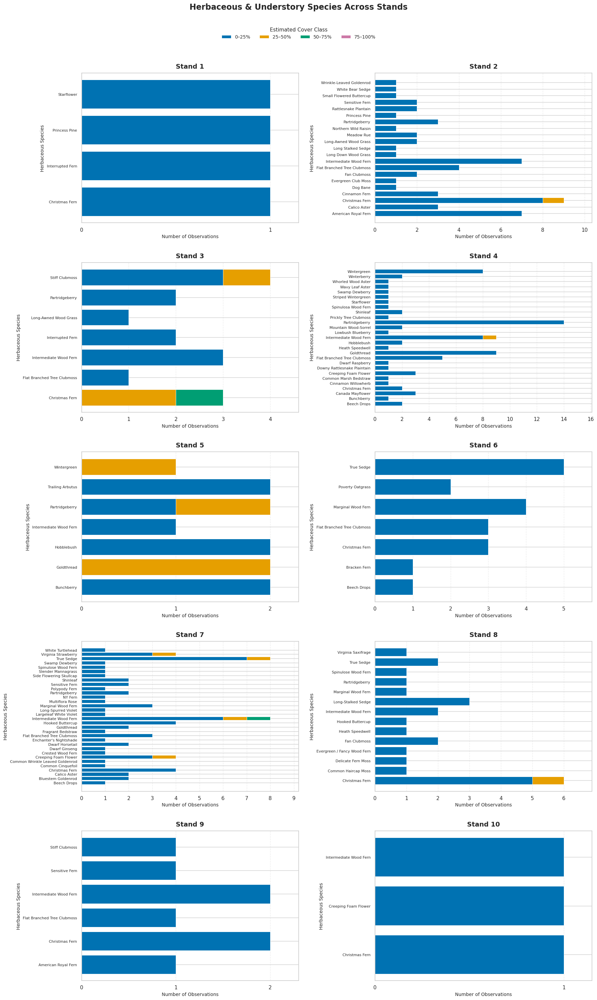

In [164]:
# ============================================================
# STEP 115
# ============================================================
# Observation counts by cover class across all ten stands.

import matplotlib.pyplot as plt
import pandas as pd

# Define the four cover classes in their natural order.
cover_classes = ['0–25%', '25–50%', '50–75%', '75–100%']

# Retain the cover-class colors used in the previous figure.
cover_colors = {
    '0–25%': '#0072B2',
    '25–50%': '#E69F00',
    '50–75%': '#009E73',
    '75–100%': '#CC79A7'
}

# Pivot the species-level count data so each cover class has its own column.
herbaceous_count_plot_df = (
    species_cover_counts
    .pivot_table(
        index=['Stand ID', 'Species Name'],
        columns='Cover Class',
        values='Observation Count',
        aggfunc='sum',
        fill_value=0
    )
    .reset_index()
)

# Remove the column index name created by the pivot operation.
herbaceous_count_plot_df.columns.name = None

# Add any missing cover-class columns.
for cover_class in cover_classes:
    if cover_class not in herbaceous_count_plot_df.columns:
        herbaceous_count_plot_df[cover_class] = 0

# Arrange columns in the intended plotting order.
herbaceous_count_plot_df = herbaceous_count_plot_df[
    ['Stand ID', 'Species Name'] + cover_classes
]

# Sort species alphabetically within each stand.
herbaceous_count_plot_df = (
    herbaceous_count_plot_df
    .sort_values(['Stand ID', 'Species Name'])
    .reset_index(drop=True)
)

# Create a 5-row by 2-column layout for all ten stands.
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(18, 30)
)

# Flatten axes for stand assignment.
axes = axes.flatten()

# Loop through Stands 1–10.
for stand_id, ax in zip(range(1, 11), axes):

    # Select observations for the current stand.
    stand_data = herbaceous_count_plot_df[
        herbaceous_count_plot_df['Stand ID'] == stand_id
    ].copy()

    stand_data = stand_data.sort_values('Species Name')

    if stand_data.empty:
        ax.text(
            0.5, 0.5,
            f'No data for Stand {stand_id}',
            ha='center',
            va='center',
            transform=ax.transAxes,
            fontsize=12
        )
        ax.set_title(
            f'Stand {stand_id}',
            fontsize=14,
            fontweight='bold',
            pad=10
        )
        ax.set_axis_off()
        continue

    species_names = stand_data['Species Name']

    # Initialize stacked-bar starting positions.
    left_positions = [0] * len(stand_data)

    # Draw one segment for each cover class.
    for cover_class in cover_classes:

        values = stand_data[cover_class]

        ax.barh(
            species_names,
            values,
            left=left_positions,
            color=cover_colors[cover_class],
            edgecolor='white',
            linewidth=0.6,
            label=cover_class
        )

        # Update starting positions for the next segment.
        left_positions = [
            left + value
            for left, value in zip(left_positions, values)
        ]

    # Set x-axis limits.
    max_count = max(left_positions) if left_positions else 1
    ax.set_xlim(0, max_count * 1.15 if max_count > 0 else 1)

    # Panel title.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=14,
        fontweight='bold',
        pad=10
    )

    # Axis labels.
    ax.set_xlabel(
        'Number of Observations',
        fontsize=10
    )
    ax.set_ylabel(
        'Herbaceous Species',
        fontsize=10
    )

    # Integer tick marks.
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Subtle vertical gridlines.
    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.35
    )
    ax.set_axisbelow(True)

    # Species-label readability.
    ax.tick_params(
        axis='y',
        labelsize=8
    )

# Create one shared legend.
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Estimated Cover Class',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.975),
    ncol=4,
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

# Overall figure title.
fig.suptitle(
    'Herbaceous & Understory Species Across Stands',
    fontsize=17,
    fontweight='bold',
    y=0.995
)

# Adjust spacing for ten panels.
plt.tight_layout(
    rect=[0, 0, 1, 0.955],
    h_pad=2.5,
    w_pad=2
)

# Export high-resolution PNG and PDF.
plt.savefig(
    export_dir / 'Herbaceous_Species_Cover_Counts.png',
    dpi=400,
    bbox_inches='tight'
)

plt.savefig(
    export_dir / 'Herbaceous_Species_Cover_Counts.pdf',
    bbox_inches='tight'
)

plt.show()

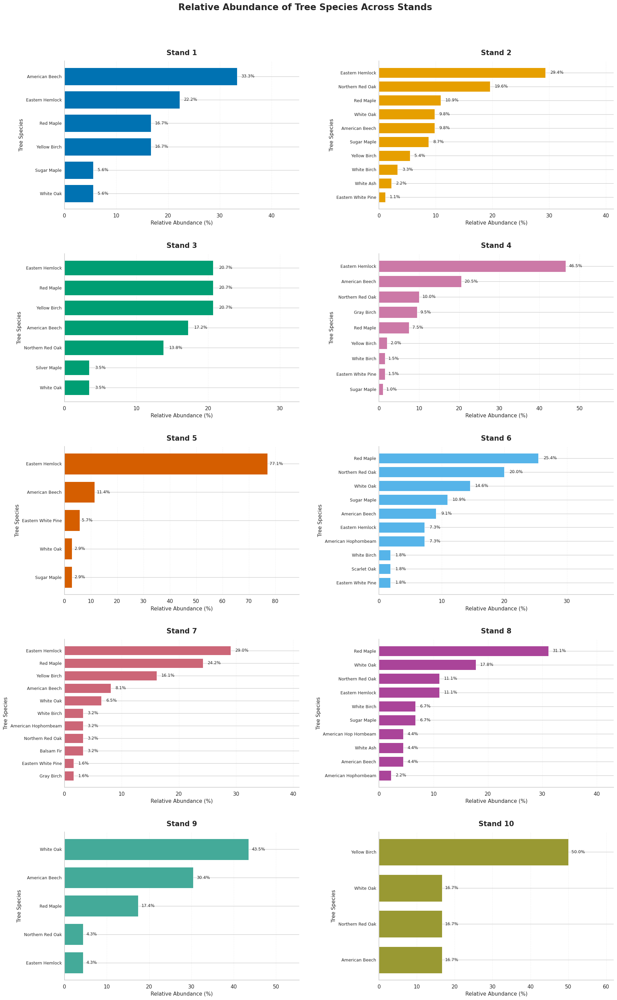

In [165]:
# ============================================================
# STEP 116
# ============================================================
# Relative abundance of tree species across all ten stands.

# Import plotting tools.
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# Create a 5-row by 2-column layout for all ten stands.
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(19, 30)
)

# Flatten the axes array for easier panel selection.
axes = axes.flatten()

# Loop through Stands 1–10.
for stand_id, ax in zip(range(1, 11), axes):

    # Select relative abundance data for the current stand.
    stand_data = tree_species_counts[
        tree_species_counts['Stand ID'] == stand_id
    ].copy()

    # Add a message if no data are available for this stand.
    if stand_data.empty:
        ax.text(
            0.5, 0.5,
            f'No tree species data for Stand {stand_id}',
            ha='center',
            va='center',
            transform=ax.transAxes,
            fontsize=12
        )
        ax.set_title(
            f'Stand {stand_id}',
            fontsize=15,
            fontweight='bold',
            pad=12
        )
        ax.set_axis_off()
        continue

    # Sort species from lowest to highest relative abundance.
    stand_data = stand_data.sort_values(
        'Relative Abundance (%)',
        ascending=True
    )

    # Draw horizontal bars using the original stand color.
    bars = ax.barh(
        stand_data['Species Name'],
        stand_data['Relative Abundance (%)'],
        color=stand_colors[stand_id],
        edgecolor='white',
        linewidth=0.7,
        height=0.75
    )

    # Add relative abundance percentages at the end of each bar.
    for bar in bars:

        abundance = bar.get_width()

        ax.text(
            abundance + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f'{abundance:.1f}%',
            va='center',
            ha='left',
            fontsize=9
        )

    # Set the x-axis limit to accommodate percentage labels.
    max_abundance = stand_data['Relative Abundance (%)'].max()

    ax.set_xlim(
        0,
        max_abundance + 12 if max_abundance > 0 else 12
    )

    # Add the stand title.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the axes.
    ax.set_xlabel(
        'Relative Abundance (%)',
        fontsize=11
    )
    ax.set_ylabel(
        'Tree Species',
        fontsize=11
    )

    # Use consistent percentage tick intervals.
    ax.xaxis.set_major_locator(MultipleLocator(10))

    # Improve species-label readability.
    ax.tick_params(
        axis='y',
        labelsize=9,
        length=0,
        pad=6
    )

    # Add subtle vertical gridlines.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.3
    )

    # Keep gridlines behind the bars.
    ax.set_axisbelow(True)

    # Remove unnecessary top and right borders.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Add an overall figure title.
fig.suptitle(
    'Relative Abundance of Tree Species Across Stands',
    fontsize=19,
    fontweight='bold',
    y=0.995
)

# Adjust panel spacing and margins.
plt.tight_layout(
    rect=[0.02, 0.01, 0.99, 0.97],
    h_pad=3,
    w_pad=3
)

# Export the figure at high resolution.
plt.savefig(
    export_dir / 'Tree_Species_Relative_Abundance.png',
    dpi=400,
    bbox_inches='tight'
)

# Also export a PDF version.
plt.savefig(
    export_dir / 'Tree_Species_Relative_Abundance.pdf',
    bbox_inches='tight'
)

# Display the completed figure.
plt.show()

In [166]:
# ============================================================
# STEP 117
# ============================================================

# Display the available column names.
print("Regeneration dataset columns:")
print(microplot.columns.tolist())

# Display the first 15 records.
print("\nFirst 15 regeneration records:")
display(microplot.head(15))

# Check how many records occur in each stand.
print("\nRecords by stand:")
print(
    microplot['Stand ID']
    .value_counts()
    .sort_index()
)

# Check the unique species recorded.
print("\nUnique regeneration species:")
print(microplot['Species Name'].nunique())

# Inspect the available regeneration count values.
print("\nRegeneration count summary:")
print(microplot['Count'].describe())

Regeneration dataset columns:
['Stand ID', 'Plot ID', 'Subplot ID', 'Microplot ID', 'Date', 'Team Member(s)', 'Species ID', 'Seedling/Sapling?', 'Count', 'Damage Type Code', 'Notes', 'Species Name']

First 15 regeneration records:


,Stand ID,Plot ID,Subplot ID,Microplot ID,Date,Team Member(s),Species ID,Seedling/Sapling?,Count,Damage Type Code,Notes,Species Name
0,1,1,1,1,2026-10-23,"LW, JW, AB",AB,Seedling,2,40.0,NaN,American Beech
1,1,1,1,1,2026-10-23,"LW, JW, AB",AB,Sapling,1,40.0,NaN,American Beech
2,1,1,1,1,2026-10-23,"LW, JW, AB",YB,Sapling,1,NaN,NaN,Yellow Birch
3,1,1,1,1,2026-10-23,"LW, JW, AB",EH,Seedling,1,NaN,NaN,Eastern Hemlock
4,2,1,1,1,2026-10-23,"JM, LW, JW",WO,Sapling,3,NaN,NaN,White Oak
5,2,1,1,1,2026-10-23,"JM, LW, JW",AB,Sapling,4,20.0,Beech bark disease,American Beech
6,2,1,1,1,2026-10-23,"JM, LW, JW",WP,Sapling,1,NaN,NaN,Eastern White Pine
7,2,1,1,1,2026-10-23,"JM, LW, JW",SM,Sapling,5,NaN,NaN,Sugar Maple
8,2,1,1,1,2026-10-23,"JM, LW, JW",AB,Seedling,1,NaN,NaN,American Beech
9,2,1,2,2,2026-10-23,"JW, JM, LA, LW",AB,Sapling,10,NaN,NaN,American Beech



Records by stand:
Stand ID
1     4
2    40
3    17
4    65
5     7
6    16
7    31
8    11
9    10
Name: count, dtype: int64

Unique regeneration species:
19

Regeneration count summary:
count    201.000000
mean       4.034826
std        4.647987
min        1.000000
25%        1.000000
50%        2.000000
75%        5.000000
max       37.000000
Name: Count, dtype: float64


In [167]:
# ============================================================
# STEP 118
# ============================================================

# Keep only observations from Stands 1–10.
regeneration_analysis = microplot[
    microplot['Stand ID'].isin(range(1, 11))
].copy()

# Remove records without a species identification.
regeneration_analysis = regeneration_analysis.dropna(
    subset=['Species Name', 'Count']
)

# Remove accidental whitespace from species names.
regeneration_analysis['Species Name'] = (
    regeneration_analysis['Species Name']
    .astype(str)
    .str.strip()
)

# Ensure regeneration counts are numeric.
regeneration_analysis['Count'] = pd.to_numeric(
    regeneration_analysis['Count'],
    errors='coerce'
)

# Remove records with missing or nonpositive counts.
regeneration_analysis = regeneration_analysis[
    regeneration_analysis['Count'].notna()
    & (regeneration_analysis['Count'] > 0)
].copy()

# Sum the actual number of seedlings and saplings for each species
# within each stand.
regeneration_species_counts = (
    regeneration_analysis
    .groupby(['Stand ID', 'Species Name'])['Count']
    .sum()
    .reset_index(name='Regeneration Count')
)

# Calculate the total number of regeneration individuals in each stand.
stand_regeneration_totals = (
    regeneration_species_counts
    .groupby('Stand ID')['Regeneration Count']
    .sum()
    .rename('Stand Total')
)

# Attach the stand totals to the species-level table.
regeneration_species_counts = regeneration_species_counts.merge(
    stand_regeneration_totals,
    on='Stand ID',
    how='left'
)

# Calculate each species' relative abundance within its stand.
regeneration_species_counts['Relative Abundance (%)'] = (
    regeneration_species_counts['Regeneration Count']
    / regeneration_species_counts['Stand Total']
    * 100
)

# Round relative abundance to two decimal places.
regeneration_species_counts['Relative Abundance (%)'] = (
    regeneration_species_counts['Relative Abundance (%)'].round(2)
)

# Sort species from most to least abundant within each stand.
regeneration_species_counts = (
    regeneration_species_counts
    .sort_values(
        ['Stand ID', 'Relative Abundance (%)'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Display the regeneration species relative abundance table.
display(regeneration_species_counts)

,Stand ID,Species Name,Regeneration Count,Stand Total,Relative Abundance (%)
0,1,American Beech,3,5,60.00
1,1,Eastern Hemlock,1,5,20.00
2,1,Yellow Birch,1,5,20.00
3,2,American Beech,52,112,46.43
4,2,Eastern White Pine,22,112,19.64
...,...,...,...,...,...
56,9,Striped Maple,14,24,58.33
57,9,American Beech,5,24,20.83
58,9,Eastern Hemlock,3,24,12.50
59,9,Eastern White Pine,1,24,4.17


,Stand ID,Seedling/Sapling?,Species Name,Individual Count,Stage Total,Relative Abundance (%)
0,1,Sapling,American Beech,1,2,50.00
1,1,Sapling,Yellow Birch,1,2,50.00
2,1,Seedling,American Beech,2,3,66.67
3,1,Seedling,Eastern Hemlock,1,3,33.33
4,2,Sapling,American Beech,25,63,39.68
...,...,...,...,...,...,...
68,9,Sapling,American Beech,5,18,27.78
69,9,Sapling,Eastern Hemlock,3,18,16.67
70,9,Sapling,Northern Red Oak,1,18,5.56
71,9,Seedling,Striped Maple,5,6,83.33


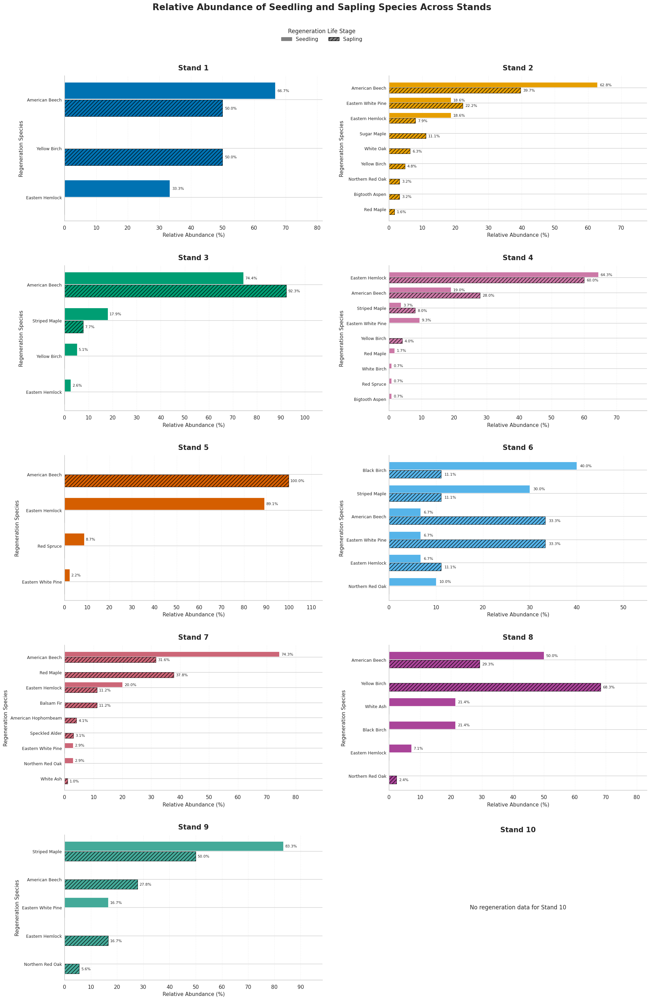

In [174]:
# ============================================================
# STEP 119
# ============================================================
# Relative abundance of seedling and sapling species across
# all ten stands, with standardized species names.

# Import plotting tools.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. PREPARE REGENERATION DATA
# ------------------------------------------------------------

regeneration_separate = microplot.copy()

# Keep only observations from Stands 1–10.
regeneration_separate = regeneration_separate[
    regeneration_separate['Stand ID'].isin(range(1, 11))
].copy()

# Remove records without a species, life-stage classification, or count.
regeneration_separate = regeneration_separate.dropna(
    subset=['Species Name', 'Seedling/Sapling?', 'Count']
)

# Standardize species names and life-stage labels.
regeneration_separate['Species Name'] = (
    regeneration_separate['Species Name']
    .astype(str)
    .str.strip()
)

regeneration_separate['Seedling/Sapling?'] = (
    regeneration_separate['Seedling/Sapling?']
    .astype(str)
    .str.strip()
    .str.title()
)

# ------------------------------------------------------------
# 2. STANDARDIZE AND REMOVE SPECIES
# ------------------------------------------------------------

def normalize_regeneration_species(species):

    if pd.isna(species):
        return ''

    original_name = str(species).strip()

    comparison_name = (
        original_name.casefold()
        .replace(' ', '')
        .replace('-', '')
        .replace('_', '')
    )

    # Standardize all Hop Hornbeam variations.
    if 'hophornbeam' in comparison_name:
        return 'American Hophornbeam'

    return original_name


regeneration_separate['Species Name'] = (
    regeneration_separate['Species Name']
    .apply(normalize_regeneration_species)
)

# Remove Witch-Hazel and Winterberry Holly, including spelling variations.
excluded_species = {
    'witchhazel',
    'winterberryholly',
    'winterberry'
}

regeneration_separate['_species_key'] = (
    regeneration_separate['Species Name']
    .str.casefold()
    .str.replace(r'[\s\-_]', '', regex=True)
)

regeneration_separate = regeneration_separate[
    ~regeneration_separate['_species_key'].isin(excluded_species)
].copy()

regeneration_separate = regeneration_separate.drop(
    columns=['_species_key']
)

# Ensure regeneration counts are numeric.
regeneration_separate['Count'] = pd.to_numeric(
    regeneration_separate['Count'],
    errors='coerce'
)

# Retain only positive counts and the two intended life stages.
regeneration_separate = regeneration_separate[
    (regeneration_separate['Count'] > 0)
    & regeneration_separate['Seedling/Sapling?'].isin(
        ['Seedling', 'Sapling']
    )
].copy()

# ------------------------------------------------------------
# 3. CALCULATE SPECIES-LEVEL INDIVIDUAL COUNTS
# ------------------------------------------------------------

# Combine records with standardized species names.
regeneration_stage_counts = (
    regeneration_separate
    .groupby(
        ['Stand ID', 'Seedling/Sapling?', 'Species Name'],
        as_index=False
    )['Count']
    .sum()
    .rename(columns={'Count': 'Individual Count'})
)

# Calculate total individuals for each life stage within each stand.
regeneration_stage_totals = (
    regeneration_stage_counts
    .groupby(
        ['Stand ID', 'Seedling/Sapling?'],
        as_index=False
    )['Individual Count']
    .sum()
    .rename(columns={'Individual Count': 'Stage Total'})
)

# Attach the appropriate life-stage total to each species record.
regeneration_stage_counts = regeneration_stage_counts.merge(
    regeneration_stage_totals,
    on=['Stand ID', 'Seedling/Sapling?'],
    how='left'
)

# Calculate relative abundance separately for seedlings and saplings.
regeneration_stage_counts['Relative Abundance (%)'] = (
    regeneration_stage_counts['Individual Count']
    / regeneration_stage_counts['Stage Total']
    * 100
)

# Remove non-finite values and round percentages.
regeneration_stage_counts['Relative Abundance (%)'] = (
    regeneration_stage_counts['Relative Abundance (%)']
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .round(2)
)

# Display corrected species-level results.
display(
    regeneration_stage_counts.sort_values(
        ['Stand ID', 'Seedling/Sapling?', 'Relative Abundance (%)'],
        ascending=[True, True, False]
    ).reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. CREATE PLOTTING DATAFRAME
# ------------------------------------------------------------

regeneration_stage_plot_df = (
    regeneration_stage_counts
    .pivot_table(
        index=['Stand ID', 'Species Name'],
        columns='Seedling/Sapling?',
        values='Relative Abundance (%)',
        aggfunc='sum',
        fill_value=0
    )
    .reset_index()
)

regeneration_stage_plot_df.columns.name = None

# Ensure both life-stage columns exist.
for stage in ['Seedling', 'Sapling']:

    if stage not in regeneration_stage_plot_df.columns:
        regeneration_stage_plot_df[stage] = 0

    regeneration_stage_plot_df[stage] = pd.to_numeric(
        regeneration_stage_plot_df[stage],
        errors='coerce'
    )

    regeneration_stage_plot_df[stage] = (
        regeneration_stage_plot_df[stage]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

# ------------------------------------------------------------
# 5. CREATE TEN-STAND FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(20, 30)
)

axes = axes.flatten()

# Loop through Stands 1–10.
for stand_id, ax in zip(range(1, 11), axes):

    stand_data = regeneration_stage_plot_df[
        regeneration_stage_plot_df['Stand ID'] == stand_id
    ].copy()

    # Handle stands without regeneration records.
    if stand_data.empty:

        ax.text(
            0.5, 0.5,
            f'No regeneration data for Stand {stand_id}',
            ha='center',
            va='center',
            transform=ax.transAxes,
            fontsize=12
        )

        ax.set_title(
            f'Stand {stand_id}',
            fontsize=15,
            fontweight='bold'
        )

        ax.set_axis_off()
        continue

    # Calculate combined relative abundance for sorting.
    stand_data['Combined Relative Abundance'] = (
        stand_data['Seedling'] + stand_data['Sapling']
    )

    stand_data = stand_data.sort_values(
        'Combined Relative Abundance',
        ascending=True
    ).reset_index(drop=True)

    y_positions = list(range(len(stand_data)))

    # Seedling bars.
    ax.barh(
        [position + 0.18 for position in y_positions],
        stand_data['Seedling'],
        height=0.34,
        color=stand_colors[stand_id],
        edgecolor='white',
        linewidth=0.6,
        label='Seedling'
    )

    # Sapling bars.
    ax.barh(
        [position - 0.18 for position in y_positions],
        stand_data['Sapling'],
        height=0.34,
        color=stand_colors[stand_id],
        edgecolor='black',
        linewidth=0.6,
        hatch='///',
        label='Sapling'
    )

    # Seedling percentage labels.
    for position, value in zip(
        y_positions,
        stand_data['Seedling']
    ):

        if value > 0:
            ax.text(
                value + 0.7,
                position + 0.18,
                f'{value:.1f}%',
                va='center',
                fontsize=8
            )

    # Sapling percentage labels.
    for position, value in zip(
        y_positions,
        stand_data['Sapling']
    ):

        if value > 0:
            ax.text(
                value + 0.7,
                position - 0.18,
                f'{value:.1f}%',
                va='center',
                fontsize=8
            )

    # Species labels.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        stand_data['Species Name'],
        fontsize=9
    )

    # Calculate a finite x-axis maximum.
    max_value = stand_data[
        ['Seedling', 'Sapling']
    ].to_numpy().max()

    if not np.isfinite(max_value):
        max_value = 0

    ax.set_xlim(
        0,
        max_value + 15 if max_value > 0 else 15
    )

    # Stand title.
    ax.set_title(
        f'Stand {stand_id}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Axis labels.
    ax.set_xlabel(
        'Relative Abundance (%)',
        fontsize=11
    )

    ax.set_ylabel(
        'Regeneration Species',
        fontsize=11
    )

    ax.xaxis.set_major_locator(MultipleLocator(10))

    # Gridlines and styling.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.7,
        alpha=0.3
    )

    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.tick_params(
        axis='y',
        length=0,
        pad=6
    )

# ------------------------------------------------------------
# 6. SHARED LEGEND
# ------------------------------------------------------------

stage_legend = [
    Patch(
        facecolor='gray',
        edgecolor='gray',
        label='Seedling'
    ),
    Patch(
        facecolor='gray',
        edgecolor='black',
        hatch='///',
        label='Sapling'
    )
]

fig.legend(
    handles=stage_legend,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.975),
    ncol=2,
    frameon=False,
    fontsize=11,
    title='Regeneration Life Stage',
    title_fontsize=12
)

# ------------------------------------------------------------
# 7. FIGURE TITLE AND SPACING
# ------------------------------------------------------------

fig.suptitle(
    'Relative Abundance of Seedling and Sapling Species Across Stands',
    fontsize=19,
    fontweight='bold',
    y=0.995
)

plt.tight_layout(
    rect=[0.02, 0.01, 0.99, 0.955],
    h_pad=3,
    w_pad=3
)

# ------------------------------------------------------------
# 8. EXPORT FIGURE
# ------------------------------------------------------------

plt.savefig(
    export_dir / 'Seedling_Sapling_Relative_Abundance.png',
    dpi=400,
    bbox_inches='tight'
)

plt.savefig(
    export_dir / 'Seedling_Sapling_Relative_Abundance.pdf',
    bbox_inches='tight'
)

plt.show()

In [175]:
# ============================================================
# STEP 120
# ============================================================

# Group DBH observations by stand and species.
dbh_species_counts = (
    dbh_analysis_df
    .groupby(['Stand ID', 'Species Name'])
    .agg(
        Sample_Size=('DBH (in)', 'count'),
        Mean_DBH=('DBH (in)', 'mean'),
        Median_DBH=('DBH (in)', 'median'),
        SD_DBH=('DBH (in)', 'std')
    )
    .reset_index()
)

# Round descriptive statistics for easier inspection.
dbh_species_counts[
    ['Mean_DBH', 'Median_DBH', 'SD_DBH']
] = dbh_species_counts[
    ['Mean_DBH', 'Median_DBH', 'SD_DBH']
].round(2)

# Sort by stand and descending sample size.
dbh_species_counts = dbh_species_counts.sort_values(
    ['Stand ID', 'Sample_Size'],
    ascending=[True, False]
).reset_index(drop=True)

# Display species-level DBH sample sizes and descriptive statistics.
display(dbh_species_counts)

,Stand ID,Species Name,Sample_Size,Mean_DBH,Median_DBH,SD_DBH
0,1,American Beech,6,8.67,7.59,3.65
1,1,Eastern Hemlock,4,10.18,10.34,1.51
2,1,Red Maple,3,12.91,14.38,3.23
3,1,Yellow Birch,3,8.43,8.30,3.50
4,1,Sugar Maple,1,10.10,10.10,NaN
...,...,...,...,...,...,...
72,9,Northern Red Oak,1,9.00,9.00,NaN
73,10,Yellow Birch,3,9.52,10.00,3.60
74,10,American Beech,1,6.10,6.10,NaN
75,10,Northern Red Oak,1,5.00,5.00,NaN


In [176]:
# ============================================================
# STEP 121
# ============================================================

# Make a separate copy of the existing DBH analysis dataset.
dbh_visualization_df = dbh_analysis_df.copy()

# Remove records without a species identification or DBH measurement.
dbh_visualization_df = dbh_visualization_df.dropna(
    subset=['Species Name', 'DBH (in)', 'Stand ID']
)

# Ensure species names are consistently formatted.
dbh_visualization_df['Species Name'] = (
    dbh_visualization_df['Species Name']
    .astype(str)
    .str.strip()
)

# Calculate sample sizes for every species within each stand.
dbh_species_n = (
    dbh_visualization_df
    .groupby(['Stand ID', 'Species Name'])
    .size()
    .reset_index(name='n')
)

# Create a species label that includes the sample size.
dbh_species_n['Species Label'] = (
    dbh_species_n['Species Name']
    + ' (n='
    + dbh_species_n['n'].astype(str)
    + ')'
)

# Attach the sample-size labels to the individual DBH observations.
dbh_visualization_df = dbh_visualization_df.merge(
    dbh_species_n[
        ['Stand ID', 'Species Name', 'Species Label']
    ],
    on=['Stand ID', 'Species Name'],
    how='left'
)

# Sort species within each stand by their median DBH.
dbh_species_order = (
    dbh_visualization_df
    .groupby(['Stand ID', 'Species Name'])['DBH (in)']
    .median()
    .reset_index()
    .sort_values(['Stand ID', 'DBH (in)'])
)

# Display the species ordering and sample sizes.
display(
    dbh_species_n.sort_values(
        ['Stand ID', 'n'],
        ascending=[True, False]
    ).reset_index(drop=True)
)

,Stand ID,Species Name,n,Species Label
0,1,American Beech,6,American Beech (n=6)
1,1,Eastern Hemlock,4,Eastern Hemlock (n=4)
2,1,Red Maple,3,Red Maple (n=3)
3,1,Yellow Birch,3,Yellow Birch (n=3)
4,1,Sugar Maple,1,Sugar Maple (n=1)
...,...,...,...,...
72,9,Northern Red Oak,1,Northern Red Oak (n=1)
73,10,Yellow Birch,3,Yellow Birch (n=3)
74,10,American Beech,1,American Beech (n=1)
75,10,Northern Red Oak,1,Northern Red Oak (n=1)


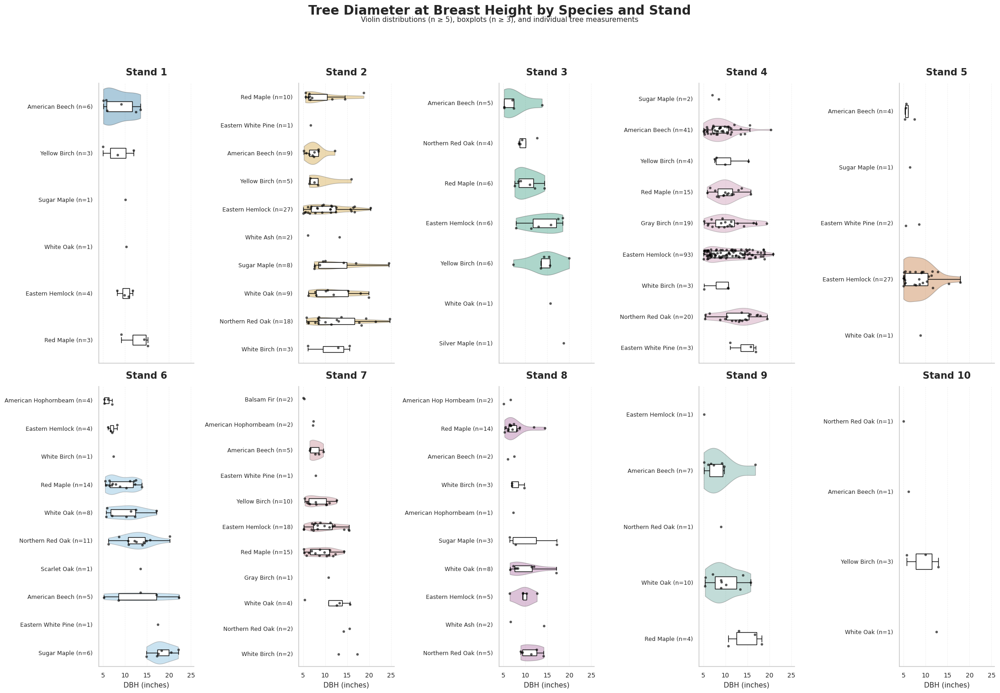

In [177]:
# ============================================================
# STEP 122
# ============================================================

# Import the plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create a figure with ten panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 5,
    figsize=(22, 15),
    sharex=True
)

# Flatten the axes array so each stand can be plotted in sequence.
axes = axes.flatten()

# Loop through the ten stands.
for stand, ax in zip(range(1, 11), axes):

    # Select DBH observations from the current stand.
    stand_data = dbh_visualization_df[
        dbh_visualization_df['Stand ID'] == stand
    ].copy()

    # Determine the species order using median DBH.
    species_order = (
        stand_data.groupby('Species Label')['DBH (in)']
        .median()
        .sort_values()
        .index.tolist()
    )

    # Identify species with at least five observations.
    # These sample sizes are more suitable for displaying violin distributions.
    violin_species = (
        stand_data.groupby('Species Label').size()
    )
    violin_species = violin_species[
        violin_species >= 5
    ].index.tolist()

    # Draw violin distributions for species with sufficient observations.
    if violin_species:

        # Filter the data to include only species with at least five observations.
        violin_data = stand_data[
            stand_data['Species Label'].isin(violin_species)
        ]

        # Draw horizontal violins to show the distribution of DBH values.
        sns.violinplot(
            data=violin_data,
            x='DBH (in)',
            y='Species Label',
            order=species_order,
            orient='h',
            color=stand_colors[stand],
            inner=None,
            cut=0,
            linewidth=1,
            alpha=0.35,
            ax=ax
        )

    # Draw boxplots for species with at least three observations.
    box_species = (
        stand_data.groupby('Species Label').size()
    )
    box_species = box_species[
        box_species >= 3
    ].index.tolist()

    # Filter the data for the boxplots.
    box_data = stand_data[
        stand_data['Species Label'].isin(box_species)
    ]

    # Overlay boxplots to show medians and interquartile ranges.
    if not box_data.empty:
        sns.boxplot(
            data=box_data,
            x='DBH (in)',
            y='Species Label',
            order=species_order,
            orient='h',
            width=0.22,
            showfliers=False,
            color='white',
            boxprops={'edgecolor': 'black', 'zorder': 3},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            medianprops={'color': 'black', 'linewidth': 1.5},
            ax=ax
        )

    # Plot every individual tree as a point.
    # This ensures species with small sample sizes remain visible.
    sns.stripplot(
        data=stand_data,
        x='DBH (in)',
        y='Species Label',
        order=species_order,
        orient='h',
        color='black',
        size=4,
        alpha=0.65,
        jitter=0.16,
        ax=ax,
        zorder=4
    )

    # Add the stand title.
    ax.set_title(
        f'Stand {stand}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the horizontal axis.
    ax.set_xlabel('DBH (inches)', fontsize=11)

    # Label the vertical axis.
    ax.set_ylabel('')

    # Improve the appearance of the axis labels and tick marks.
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=10)

    # Add subtle vertical gridlines for easier comparison.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.6,
        alpha=0.35
    )

    # Keep the grid behind the plotted data.
    ax.set_axisbelow(True)

    # Remove the top and right borders for a cleaner appearance.
    sns.despine(ax=ax)

# Add an overall figure title.
fig.suptitle(
    'Tree Diameter at Breast Height by Species and Stand',
    fontsize=20,
    fontweight='bold',
    y=1.01
)

# Add a brief explanatory subtitle.
fig.text(
    0.5,
    0.985,
    'Violin distributions (n ≥ 5), boxplots (n ≥ 3), and individual tree measurements',
    ha='center',
    fontsize=11
)

# Adjust spacing to prevent overlap between panels.
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save the figure as a high-resolution PNG.
plt.savefig(
    export_dir / 'DBH_Distributions_by_Species_and_Stand.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the finished figure.
plt.show()

In [178]:
# ============================================================
# STEP 123
# ============================================================

# Print all column names so we can identify the correct height field.
print(height_df.columns.tolist())

# Display the first five rows to verify the data structure.
display(height_df.head())

['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Tree ID', 'Species Code', 'Tree Status', 'DBH (in)', 'Estimated Tree Height (m)', 'Estimated Tree Height (ft)', 'Crown Class Code', 'Damage Type Code', 'Snag Decay Class (If Applicable)', 'Notes', 'Species Name', 'Tree Status Label']


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes,Species Name,Tree Status Label
0,1,1,1,2026-10-23,"EJ, TQ",1.0,YB,AL,8.30,25.0,82.020998,Dominant,NaN,NaN,NaN,Yellow Birch,Alive
1,1,1,1,2026-10-23,"EJ, TQ",2.0,EH,AL,8.25,10.0,32.808399,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive
2,1,1,1,2026-10-23,"LW, AB, HB",3.0,AB,DA,13.52,13.5,44.291339,Dominant,20,NaN,Base of trunk split,American Beech,Damaged
3,1,1,1,2026-10-23,"EC, HP, AB, LW",4.0,AB,DA,5.98,10.0,32.808399,Codominant,20,NaN,Bark split,American Beech,Damaged
4,1,1,1,2026-10-23,"JW, JR, HP",5.0,EH,AL,11.80,5.5,18.044619,Suppressed,NaN,NaN,NaN,Eastern Hemlock,Alive


In [179]:
# ============================================================
# STEP 124
# ============================================================

# Create a separate copy of the existing height analysis dataset.
height_visualization_df = height_df.copy()

# Remove records missing species, stand, or height information.
height_visualization_df = height_visualization_df.dropna(
    subset=[
        'Stand ID',
        'Species Name',
        'Estimated Tree Height (ft)'
    ]
)

# Ensure species names are consistently formatted.
height_visualization_df['Species Name'] = (
    height_visualization_df['Species Name']
    .astype(str)
    .str.strip()
)

# Group observations by stand and species.
# Calculate sample size and descriptive statistics for tree height.
height_species_summary = (
    height_visualization_df
    .groupby(['Stand ID', 'Species Name'])
    .agg(
        Sample_Size=('Estimated Tree Height (ft)', 'count'),
        Mean_Height=('Estimated Tree Height (ft)', 'mean'),
        Median_Height=('Estimated Tree Height (ft)', 'median'),
        SD_Height=('Estimated Tree Height (ft)', 'std'),
        Minimum_Height=('Estimated Tree Height (ft)', 'min'),
        Maximum_Height=('Estimated Tree Height (ft)', 'max')
    )
    .reset_index()
)

# Round the descriptive statistics to two decimal places.
numeric_columns = [
    'Mean_Height',
    'Median_Height',
    'SD_Height',
    'Minimum_Height',
    'Maximum_Height'
]

height_species_summary[numeric_columns] = (
    height_species_summary[numeric_columns].round(2)
)

# Sort species within each stand by sample size, largest first.
height_species_summary = (
    height_species_summary
    .sort_values(
        ['Stand ID', 'Sample_Size'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Display the species-level height summary.
display(height_species_summary)

,Stand ID,Species Name,Sample_Size,Mean_Height,Median_Height,SD_Height,Minimum_Height,Maximum_Height
0,1,American Beech,6,46.64,38.55,21.40,27.23,83.66
1,1,Eastern Hemlock,4,34.04,36.09,11.93,18.04,45.93
2,1,Yellow Birch,3,51.62,38.39,26.40,34.45,82.02
3,1,Red Maple,2,52.49,52.49,4.64,49.21,55.77
4,1,White Oak,1,60.04,60.04,NaN,60.04,60.04
...,...,...,...,...,...,...,...,...
71,9,Northern Red Oak,1,24.77,24.77,NaN,24.77,24.77
72,10,Yellow Birch,3,39.60,40.42,15.12,24.08,54.30
73,10,American Beech,1,25.59,25.59,NaN,25.59,25.59
74,10,Northern Red Oak,1,27.62,27.62,NaN,27.62,27.62


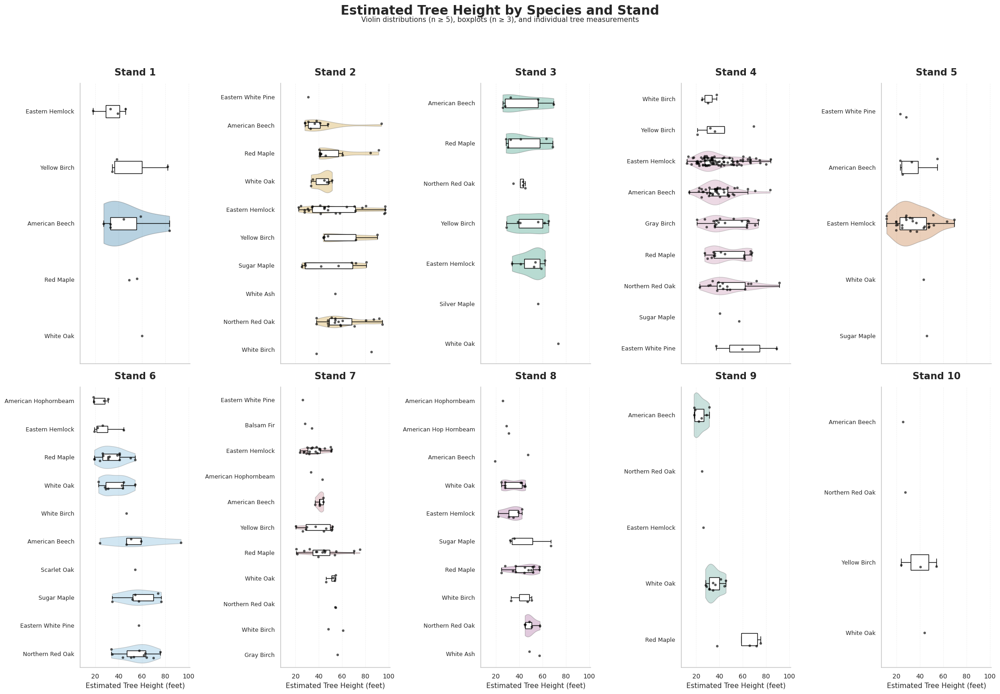

In [180]:
# ============================================================
# STEP 125
# ============================================================
# Import plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the height column once so the code consistently uses the correct field.
height_column = 'Estimated Tree Height (ft)'

# Create a figure with ten panels arranged in two rows and three columns.
fig, axes = plt.subplots(
    2, 5,
    figsize=(22, 15),
    sharex=True
)

# Flatten the axes array so each stand can be plotted in sequence.
axes = axes.flatten()

# Loop through the ten stands.
for stand, ax in zip(range(1, 11), axes):

    # Select height observations from the current stand.
    stand_data = height_visualization_df[
        height_visualization_df['Stand ID'] == stand
    ].copy()

    # Determine the species order using median tree height.
    species_order = (
        stand_data.groupby('Species Name')[height_column]
        .median()
        .sort_values()
        .index.tolist()
    )

    # Identify species with at least five observations.
    # These sample sizes are more suitable for displaying violin distributions.
    violin_species = (
        stand_data.groupby('Species Name').size()
    )
    violin_species = violin_species[
        violin_species >= 5
    ].index.tolist()

    # Draw violin distributions for species with sufficient observations.
    if violin_species:

        # Filter the data to include only species with at least five observations.
        violin_data = stand_data[
            stand_data['Species Name'].isin(violin_species)
        ]

        # Record the number of existing plot collections.
        # This allows us to apply transparency only to the violin shapes.
        collections_before = len(ax.collections)

        # Draw horizontal violins to show the distribution of tree heights.
        sns.violinplot(
            data=violin_data,
            x=height_column,
            y='Species Name',
            order=species_order,
            orient='h',
            color=stand_colors[stand],
            inner=None,
            cut=0,
            linewidth=1,
            ax=ax
        )

        # Apply 30% opacity to the violin distributions.
        for violin in ax.collections[collections_before:]:
            violin.set_alpha(0.30)

    # Identify species with at least three observations for boxplots.
    box_species = (
        stand_data.groupby('Species Name').size()
    )
    box_species = box_species[
        box_species >= 3
    ].index.tolist()

    # Filter the data for the boxplots.
    box_data = stand_data[
        stand_data['Species Name'].isin(box_species)
    ]

    # Overlay boxplots to show medians and interquartile ranges.
    if not box_data.empty:
        sns.boxplot(
            data=box_data,
            x=height_column,
            y='Species Name',
            order=species_order,
            orient='h',
            width=0.22,
            showfliers=False,
            color='white',
            boxprops={'edgecolor': 'black', 'zorder': 3},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            medianprops={'color': 'black', 'linewidth': 1.5},
            ax=ax
        )

    # Plot every individual tree as a point.
    # This keeps species with small sample sizes visible.
    sns.stripplot(
        data=stand_data,
        x=height_column,
        y='Species Name',
        order=species_order,
        orient='h',
        color='black',
        size=4,
        alpha=0.65,
        jitter=0.16,
        ax=ax,
        zorder=4
    )

    # Add the stand title.
    ax.set_title(
        f'Stand {stand}',
        fontsize=15,
        fontweight='bold',
        pad=12
    )

    # Label the horizontal axis.
    ax.set_xlabel('Estimated Tree Height (feet)', fontsize=11)

    # Remove the vertical axis title.
    ax.set_ylabel('')

    # Improve the appearance of axis labels and tick marks.
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=10)

    # Add subtle vertical gridlines for easier comparison.
    ax.grid(
        axis='x',
        linestyle='--',
        linewidth=0.6,
        alpha=0.35
    )

    # Keep gridlines behind the plotted data.
    ax.set_axisbelow(True)

    # Remove the top and right borders for a cleaner appearance.
    sns.despine(ax=ax)

# Add an overall figure title.
fig.suptitle(
    'Estimated Tree Height by Species and Stand',
    fontsize=20,
    fontweight='bold',
    y=1.01
)

# Add an explanatory subtitle.
fig.text(
    0.5,
    0.985,
    'Violin distributions (n ≥ 5), boxplots (n ≥ 3), and individual tree measurements',
    ha='center',
    fontsize=11
)

# Adjust spacing to prevent overlap between panels.
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save the figure as a high-resolution PNG.
plt.savefig(
    export_dir / 'Height_Distributions_by_Species_and_Stand.png',
    dpi=400,
    bbox_inches='tight'
)

# Display the finished figure.
plt.show()


In [181]:
# ============================================================
# STEP 126
# ============================================================

# Define the measurement columns for height and DBH.
height_column = 'Estimated Tree Height (ft)'
dbh_column = 'DBH (in)'

# Create a reusable function to identify the largest and smallest trees.
def get_tree_extremes(data, measurement, direction):

    # Create a separate copy of the input data.
    df = data.copy()

    # Remove records missing the measurement, species, stand, or Tree ID.
    df = df.dropna(
        subset=[
            'Stand ID',
            'Tree ID',
            'Species Name',
            measurement
        ]
    )

    # Sort trees within each stand by the selected measurement.
    # Largest trees are ranked in descending order.
    # Smallest trees are ranked in ascending order.
    ascending_order = direction == 'smallest'

    df = df.sort_values(
        ['Stand ID', measurement],
        ascending=[True, ascending_order]
    )

    # Select the five highest or lowest measurements in each stand.
    extremes = (
        df.groupby('Stand ID', group_keys=False)
        .head(5)
        .copy()
    )

    # Add a ranking number from 1 to 5 within each stand.
    extremes['Rank'] = (
        extremes.groupby('Stand ID').cumcount() + 1
    )

    # Return the ranked dataset.
    return extremes


# Identify the five tallest trees in each stand.
tallest_trees = get_tree_extremes(
    height_visualization_df,
    height_column,
    'largest'
)

# Identify the five shortest trees in each stand.
shortest_trees = get_tree_extremes(
    height_visualization_df,
    height_column,
    'smallest'
)

# Identify the five largest-DBH trees in each stand.
largest_dbh_trees = get_tree_extremes(
    dbh_visualization_df,
    dbh_column,
    'largest'
)

# Identify the five smallest-DBH trees in each stand.
smallest_dbh_trees = get_tree_extremes(
    dbh_visualization_df,
    dbh_column,
    'smallest'
)

# Display the tallest trees.
print('FIVE TALLEST TREES PER STAND')
display(
    tallest_trees[
        ['Stand ID', 'Rank', 'Tree ID', 'Species Name', height_column]
    ]
)

# Display the shortest trees.
print('FIVE SHORTEST TREES PER STAND')
display(
    shortest_trees[
        ['Stand ID', 'Rank', 'Tree ID', 'Species Name', height_column]
    ]
)

# Display the largest-DBH trees.
print('FIVE LARGEST DBH TREES PER STAND')
display(
    largest_dbh_trees[
        ['Stand ID', 'Rank', 'Tree ID', 'Species Name', dbh_column]
    ]
)

# Display the smallest-DBH trees.
print('FIVE SMALLEST DBH TREES PER STAND')
display(
    smallest_dbh_trees[
        ['Stand ID', 'Rank', 'Tree ID', 'Species Name', dbh_column]
    ]
)

FIVE TALLEST TREES PER STAND


,Stand ID,Rank,Tree ID,Species Name,Estimated Tree Height (ft)
5,1,1,6.0,American Beech,83.661417
0,1,2,1.0,Yellow Birch,82.020998
10,1,3,11.0,White Oak,60.039370
19,1,4,20.0,American Beech,59.055118
15,1,5,16.0,Red Maple,55.774278
83,2,1,7.0,Eastern Hemlock,96.948819
90,2,2,4.0,Eastern Hemlock,96.784777
96,2,3,10.0,Eastern Hemlock,96.784777
89,2,4,3.0,Eastern Hemlock,95.964567
93,2,5,7.0,Northern Red Oak,94.324147


FIVE SHORTEST TREES PER STAND


,Stand ID,Rank,Tree ID,Species Name,Estimated Tree Height (ft)
4,1,1,5.0,Eastern Hemlock,18.044619
8,1,2,9.0,American Beech,27.230971
1,1,3,2.0,Eastern Hemlock,32.808399
3,1,4,4.0,American Beech,32.808399
14,1,5,15.0,American Beech,32.808399
42,2,1,5.0,Eastern Hemlock,22.473753
43,2,2,6.0,Eastern Hemlock,24.606299
58,2,3,5.0,Sugar Maple,25.426509
92,2,4,6.0,Eastern Hemlock,27.559055
106,2,5,9.0,Eastern Hemlock,27.559055


FIVE LARGEST DBH TREES PER STAND


,Stand ID,Rank,Tree ID,Species Name,DBH (in)
9,1,1,10.0,Red Maple,15.14
14,1,2,16.0,Red Maple,14.38
2,1,3,3.0,American Beech,13.52
17,1,4,20.0,American Beech,12.46
7,1,5,8.0,Yellow Birch,11.99
97,2,1,2.0,Northern Red Oak,24.70
28,2,2,2.0,Sugar Maple,24.49
44,2,3,1.0,Northern Red Oak,21.52
87,2,4,2.0,Eastern Hemlock,20.38
30,2,5,4.0,White Oak,19.89


FIVE SMALLEST DBH TREES PER STAND


,Stand ID,Rank,Tree ID,Species Name,DBH (in)
11,1,1,12.0,Yellow Birch,5.00
13,1,2,15.0,American Beech,5.10
5,1,3,6.0,American Beech,5.73
3,1,4,4.0,American Beech,5.98
1,1,5,2.0,Eastern Hemlock,8.25
89,2,1,4.0,Eastern Hemlock,5.00
107,2,2,1.0,American Beech,5.20
43,2,3,10.0,Eastern Hemlock,5.40
24,2,4,29.0,Red Maple,5.52
40,2,5,7.0,Red Maple,5.53


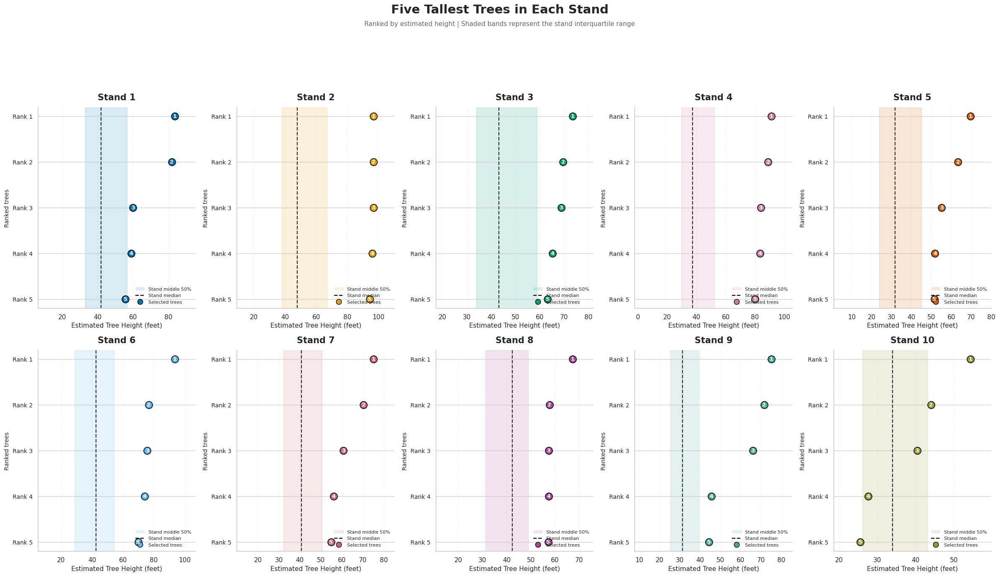

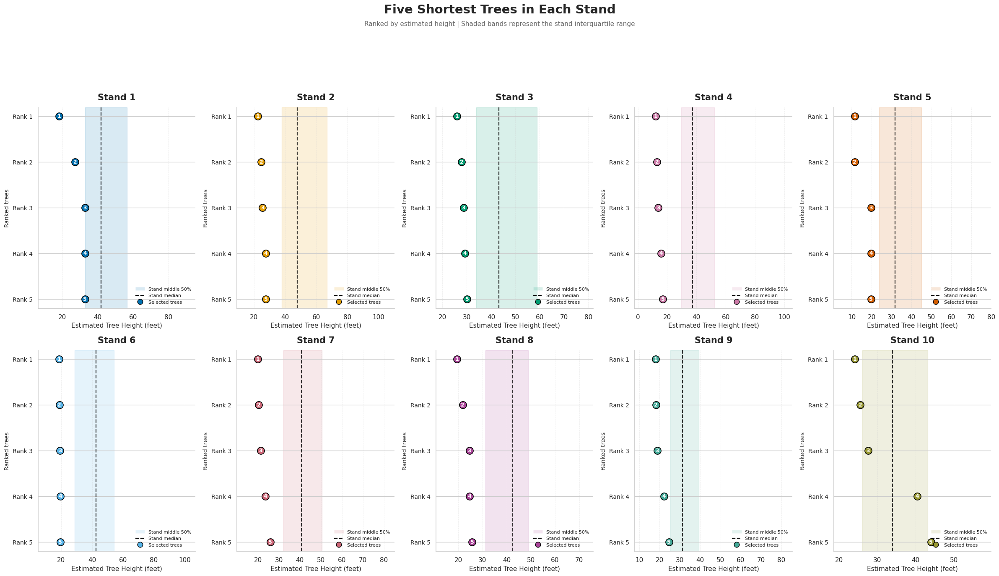

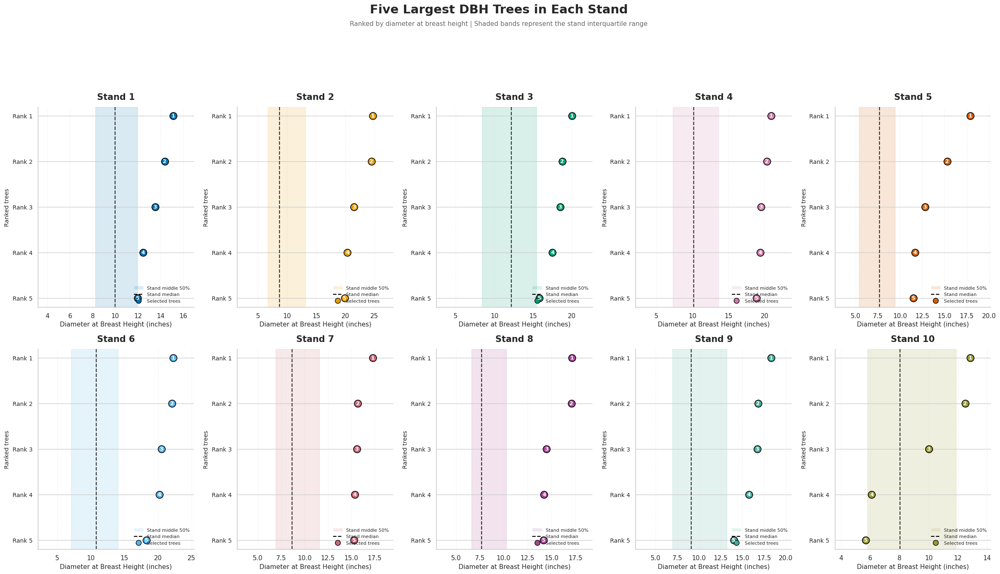

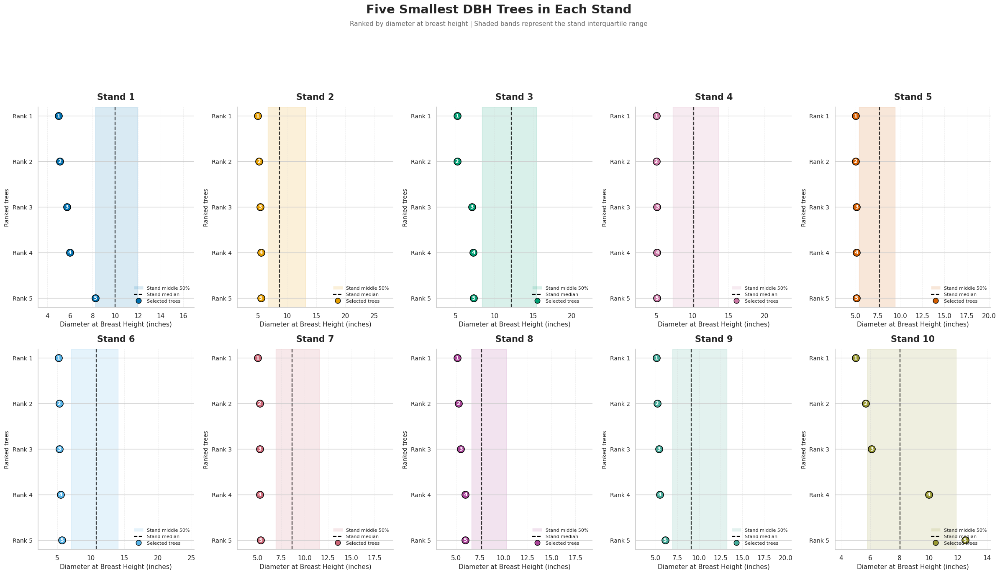

In [182]:
# ============================================================
# STEP 127
# ============================================================

# Import plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the measurement columns.
height_column = 'Estimated Tree Height (ft)'
dbh_column = 'DBH (in)'


# ------------------------------------------------------------
# PART 1: DEFINE THE RANKED DOT-PLOT FUNCTION
# ------------------------------------------------------------

# Define a function to create one independent ten-panel figure.
def plot_ranked_extremes(
    full_data,
    extreme_data,
    measurement,
    title,
    subtitle,
    filename,
    xlabel
):

    # Create ten panels arranged in two rows and five columns.
    fig, axes = plt.subplots(
        2, 5,
        figsize=(24, 13),
        sharex=False
    )

    # Flatten the axes array for easier iteration.
    axes = axes.flatten()

    # Loop through the ten stands.
    for stand, ax in zip(range(1, 11), axes):

        # Select all measurements from the current stand.
        stand_full = full_data[
            full_data['Stand ID'] == stand
        ].copy()

        # Select the five ranked extreme trees from the current stand.
        stand_extremes = extreme_data[
            extreme_data['Stand ID'] == stand
        ].copy()

        # Calculate the stand median.
        stand_median = stand_full[measurement].median()

        # Calculate the first and third quartiles.
        stand_q1 = stand_full[measurement].quantile(0.25)
        stand_q3 = stand_full[measurement].quantile(0.75)

        # Calculate the observed measurement range for this stand.
        stand_min = stand_full[measurement].min()
        stand_max = stand_full[measurement].max()

        # Calculate padding so the extreme points are not against the axis edges.
        axis_padding = (stand_max - stand_min) * 0.18

        # Use a small minimum padding if measurements have very little variation.
        if axis_padding == 0:
            axis_padding = 1

        # Add a shaded band representing the middle 50% of stand measurements.
        ax.axvspan(
            stand_q1,
            stand_q3,
            color=stand_colors[stand],
            alpha=0.15,
            zorder=0
        )

        # Add a dashed vertical line representing the stand median.
        ax.axvline(
            stand_median,
            color='black',
            linestyle='--',
            linewidth=1.6,
            alpha=0.8,
            zorder=1
        )

        # Assign vertical positions to the five ranked trees.
        # Rank 1 appears at the top of the panel.
        y_positions = np.arange(
            len(stand_extremes),
            0,
            -1
        )

        # Plot the five selected trees as large colored points.
        ax.scatter(
            stand_extremes[measurement],
            y_positions,
            s=150,
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=1.2,
            zorder=5
        )

        # Add the rank number inside each highlighted point.
        for x_value, y_value, rank in zip(
            stand_extremes[measurement],
            y_positions,
            stand_extremes['Rank']
        ):

            # Place the rank number in the center of the point.
            ax.text(
                x_value,
                y_value,
                str(rank),
                ha='center',
                va='center',
                fontsize=9,
                fontweight='bold',
                color='white',
                zorder=6
            )

        # Label the vertical positions using rank only.
        ax.set_yticks(y_positions)
        ax.set_yticklabels(
            [f'Rank {rank}' for rank in stand_extremes['Rank']],
            fontsize=10
        )

        # Add the stand title.
        ax.set_title(
            f'Stand {stand}',
            fontsize=15,
            fontweight='bold',
            pad=12
        )

        # Set a stand-specific horizontal axis range.
        ax.set_xlim(
            stand_min - axis_padding,
            stand_max + axis_padding
        )

        # Label the horizontal axis.
        ax.set_xlabel(
            xlabel,
            fontsize=11
        )

        # Label the vertical axis.
        ax.set_ylabel(
            'Ranked trees',
            fontsize=10
        )

        # Add subtle vertical gridlines.
        ax.grid(
            axis='x',
            linestyle='--',
            linewidth=0.6,
            alpha=0.35
        )

        # Keep gridlines behind the plotted data.
        ax.set_axisbelow(True)

        # Remove unnecessary plot borders.
        sns.despine(ax=ax)

        # Import components used to construct the legend.
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch

        # Define the legend elements.
        legend_elements = [
            Patch(
                facecolor=stand_colors[stand],
                alpha=0.15,
                label='Stand middle 50%'
            ),
            Line2D(
                [0], [0],
                color='black',
                linestyle='--',
                linewidth=1.6,
                label='Stand median'
            ),
            Line2D(
                [0], [0],
                marker='o',
                color=stand_colors[stand],
                markeredgecolor='black',
                linestyle='None',
                markersize=9,
                label='Selected trees'
            )
        ]

        # Display the legend in the lower-right corner.
        ax.legend(
            handles=legend_elements,
            loc='lower right',
            fontsize=8,
            frameon=False
        )

    # Add the main figure title.
    fig.suptitle(
        title,
        fontsize=21,
        fontweight='bold',
        y=1.055
    )

    # Add the subtitle as a separate line with additional spacing.
    fig.text(
        0.5,
        1.015,
        subtitle,
        ha='center',
        fontsize=11,
        color='dimgray'
    )

    # Adjust spacing to keep the title, subtitle, and panels separate.
    plt.tight_layout(
        rect=[0, 0, 1, 0.94]
    )

    # Save the figure at high resolution.
    plt.savefig(
        export_dir / filename,
        dpi=400,
        bbox_inches='tight'
    )

    # Display the finished figure.
    plt.show()

    # Close the figure after saving and displaying it.
    plt.close(fig)


# ------------------------------------------------------------
# PART 2: CREATE FOUR INDEPENDENT FIGURES
# ------------------------------------------------------------

# Figure 1: Five tallest trees in each stand.
plot_ranked_extremes(
    full_data=height_visualization_df,
    extreme_data=tallest_trees,
    measurement=height_column,
    title='Five Tallest Trees in Each Stand',
    subtitle='Ranked by estimated height | Shaded bands represent the stand interquartile range',
    filename='Five_Tallest_Trees_Ranked.png',
    xlabel='Estimated Tree Height (feet)'
)

# Figure 2: Five shortest trees in each stand.
plot_ranked_extremes(
    full_data=height_visualization_df,
    extreme_data=shortest_trees,
    measurement=height_column,
    title='Five Shortest Trees in Each Stand',
    subtitle='Ranked by estimated height | Shaded bands represent the stand interquartile range',
    filename='Five_Shortest_Trees_Ranked.png',
    xlabel='Estimated Tree Height (feet)'
)

# Figure 3: Five largest-DBH trees in each stand.
plot_ranked_extremes(
    full_data=dbh_visualization_df,
    extreme_data=largest_dbh_trees,
    measurement=dbh_column,
    title='Five Largest DBH Trees in Each Stand',
    subtitle='Ranked by diameter at breast height | Shaded bands represent the stand interquartile range',
    filename='Five_Largest_DBH_Trees_Ranked.png',
    xlabel='Diameter at Breast Height (inches)'
)

# Figure 4: Five smallest-DBH trees in each stand.
plot_ranked_extremes(
    full_data=dbh_visualization_df,
    extreme_data=smallest_dbh_trees,
    measurement=dbh_column,
    title='Five Smallest DBH Trees in Each Stand',
    subtitle='Ranked by diameter at breast height | Shaded bands represent the stand interquartile range',
    filename='Five_Smallest_DBH_Trees_Ranked.png',
    xlabel='Diameter at Breast Height (inches)'
)


In [183]:
# ============================================================
# STEP 128
# ============================================================

# Print the dimensions of the dataset.
print("FWD dataset dimensions:", fwd.shape)

# Display all available column names.
print("\nFWD columns:")
print(fwd.columns.tolist())

# Display the first five observations.
print("\nFirst five observations:")
display(fwd.head())

# Display the number of missing values in each column.
print("\nMissing values:")
display(fwd.isna().sum())

# Display the number of observations recorded in each stand.
print("\nObservations by stand:")
display(fwd['Stand ID'].value_counts().sort_index())

FWD dataset dimensions: (226, 8)

FWD columns:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Size Class', 'Count', 'Notes']

First five observations:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Size Class,Count,Notes
0,1,1,1,2026-10-23,"EC, HP, LW, AB, LA, JW, JR,JM",1,33,NaN
1,1,1,1,2026-10-23,"EC, HP, LW, AB, LA, JW, JR,JM",2,20,NaN
2,1,1,1,2026-10-23,"EC, HP, LW, AB, LA, JW, JR,JM",3,6,NaN
3,2,1,1,2026-10-23,"AB, EC, JR, HP",1,23,NaN
4,2,1,1,2026-10-23,"AB, EC, JR, HP",2,13,NaN



Missing values:


,0
Stand ID,0
Plot ID,0
Subplot ID,0
Date,0
Team Member(s),0
Size Class,0
Count,0
Notes,226



Observations by stand:


,count
Stand ID,
1,3
2,43
3,18
4,66
5,12
6,21
7,27
8,18
9,15


In [184]:
# ============================================================
# STEP 129
# ============================================================

# Create a working copy containing only stands 1–6.
fwd_analysis = fwd[fwd['Stand ID'].isin([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])].copy()

# Display the unique size classes recorded in the dataset.
print("FWD size classes:")
print(sorted(fwd_analysis['Size Class'].unique()))

# Count the number of records within each stand and size class.
print("\nRecords by stand and size class:")
display(
    fwd_analysis.groupby(['Stand ID', 'Size Class'])
    .size()
    .unstack(fill_value=0)
)

# Calculate the total FWD count within each stand and size class.
print("\nFWD counts by stand and size class:")
display(
    fwd_analysis.groupby(['Stand ID', 'Size Class'])['Count']
    .sum()
    .unstack(fill_value=0)
)

# Count the unique plots and subplots sampled within each stand.
print("\nSampling coverage by stand:")
display(
    fwd_analysis.groupby('Stand ID')
    .agg(
        Unique_Plots=('Plot ID', 'nunique'),
        Unique_Subplots=('Subplot ID', 'nunique'),
        Total_Records=('Count', 'size')
    )
)

FWD size classes:
[np.int64(1), np.int64(2), np.int64(3)]

Records by stand and size class:


Size Class,1,2,3
Stand ID,,,
1,1,1,1
2,15,14,14
3,6,6,6
4,22,22,22
5,4,4,4
6,7,7,7
7,9,9,9
8,6,6,6
9,5,5,5



FWD counts by stand and size class:


Size Class,1,2,3
Stand ID,,,
1,33,20,6
2,423,219,123
3,176,52,43
4,633,264,129
5,128,44,13
6,197,114,138
7,272,126,55
8,101,64,23
9,93,38,13



Sampling coverage by stand:


,Unique_Plots,Unique_Subplots,Total_Records
Stand ID,,,
1,1,1,3
2,4,5,43
3,2,4,18
4,2,13,66
5,2,2,12
6,1,7,21
7,1,9,27
8,1,6,18
9,2,4,15


In [185]:
# ============================================================
# STEP 130
# ============================================================

# Group records by stand, plot, and subplot.
# Each combination represents one distinct sampling unit.
fwd_subplot_check = (
    fwd_analysis
    .groupby(['Stand ID', 'Plot ID', 'Subplot ID'])
    .agg(
        Number_of_Size_Classes=('Size Class', 'nunique'),
        Size_Classes_Recorded=('Size Class', lambda x: sorted(x.unique())),
        Total_FWD_Count=('Count', 'sum')
    )
    .reset_index()
)

# Display the number of distinct sampled subplots in each stand.
print("Distinct sampled subplots by stand:")
display(
    fwd_subplot_check.groupby('Stand ID')
    .size()
    .rename('Number of Subplots')
    .to_frame()
)

# Identify any subplots that do not contain all three size classes.
print("\nSubplots with incomplete size-class records:")
display(
    fwd_subplot_check[
        fwd_subplot_check['Number_of_Size_Classes'] != 3
    ]
)

# Summarize total FWD counts across sampled subplots within each stand.
print("\nTotal FWD counts by stand:")
display(
    fwd_subplot_check.groupby('Stand ID')
    .agg(
        Sampled_Subplots=('Total_FWD_Count', 'size'),
        Total_FWD_Count=('Total_FWD_Count', 'sum'),
        Mean_Count_Per_Subplot=('Total_FWD_Count', 'mean'),
        Median_Count_Per_Subplot=('Total_FWD_Count', 'median'),
        SD_Count_Per_Subplot=('Total_FWD_Count', 'std')
    ).round(2)
)

Distinct sampled subplots by stand:


,Number of Subplots
Stand ID,
1,1
2,15
3,6
4,22
5,3
6,7
7,9
8,6
9,5



Subplots with incomplete size-class records:


,Stand ID,Plot ID,Subplot ID,Number_of_Size_Classes,Size_Classes_Recorded,Total_FWD_Count
11,2,3,4,1,[1],35



Total FWD counts by stand:


,Sampled_Subplots,Total_FWD_Count,Mean_Count_Per_Subplot,Median_Count_Per_Subplot,SD_Count_Per_Subplot
Stand ID,,,,,
1,1,59,59.00,59.0,NaN
2,15,765,51.00,48.0,13.38
3,6,271,45.17,41.0,16.12
4,22,1026,46.64,48.5,14.22
5,3,185,61.67,54.0,29.26
6,7,449,64.14,58.0,23.65
7,9,453,50.33,42.0,22.34
8,6,188,31.33,27.5,11.45
9,5,144,28.80,28.0,5.17


In [186]:
# ============================================================
# STEP 131
# ============================================================

# Reshape the data so each row represents one subplot and each
# size-class column contains the corresponding FWD piece count.
fwd_size_pivot = fwd_analysis.pivot_table(
    index=['Stand ID', 'Plot ID', 'Subplot ID'],
    columns='Size Class',
    values='Count',
    aggfunc='sum'
)

# Retain only subplots with observations for all three size classes.
# Missing size-class records remain missing rather than being treated as zero.
fwd_complete_subplots = fwd_size_pivot.dropna(
    subset=[1, 2, 3]
).copy()

# Calculate the total number of FWD pieces across all three size classes
# within each complete subplot.
fwd_complete_subplots['Total FWD'] = (
    fwd_complete_subplots[1] +
    fwd_complete_subplots[2] +
    fwd_complete_subplots[3]
)

# Calculate mean, median, standard deviation, and sample size
# for each size class within each stand.
print("FWD counts per subplot by size class:")
display(
    fwd_complete_subplots.groupby(level='Stand ID')[[1, 2, 3]]
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

# Calculate total FWD abundance per complete subplot by stand.
print("\nTotal FWD counts per complete subplot:")
display(
    fwd_complete_subplots.groupby(level='Stand ID')['Total FWD']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

# Calculate total counts for each size class within each stand.
fwd_class_totals = (
    fwd_complete_subplots.groupby(level='Stand ID')[[1, 2, 3]]
    .sum()
)

# Calculate each size class as a percentage of the stand's total FWD count.
fwd_class_percentages = (
    fwd_class_totals.div(fwd_class_totals.sum(axis=1), axis=0) * 100
)

# Display the relative contribution of each size class within each stand.
print("\nFWD size-class composition by stand (%):")
display(fwd_class_percentages.round(2))

FWD counts per subplot by size class:


Size Class     1                          2                         3         \
           count   mean median    std count   mean median   std count   mean   
Stand ID                                                                       
1              1  33.00   33.0    NaN     1  20.00   20.0   NaN     1   6.00   
2             14  27.71   26.0   8.05    14  15.64   14.0  4.94    14   8.79   
3              6  29.33   29.5  10.80     6   8.67    7.0  7.45     6   7.17   
4             22  28.77   31.0  11.34    22  12.00   11.5  4.68    22   5.86   
5              3  42.67   32.0  20.23     3  14.67   16.0  8.08     3   4.33   
6              7  28.14   28.0   9.55     7  16.29   17.0  5.59     7  19.71   
7              9  30.22   26.0  14.38     9  14.00   12.0  7.76     9   6.11   
8              6  16.83   17.5   2.32     6  10.67    8.0  7.37     6   3.83   
9              5  18.60   20.0   4.51     5   7.60    7.0  2.07     5   2.60   
10             1  16.00   16.0    NaN     1   4.00    4.0   NaN     1   4.00   

Size Class                
           median    std  
Stand ID                  
1             6.0    NaN  
2             8.5   3.49  
3             6.0   4.54  
4             4.5   4.13  
5             6.0   2.89  
6            11.0  22.73  
7             6.0   3.59  
8             1.0   5.31  
9             1.0   2.70  
10            4.0    NaN


Total FWD counts per complete subplot:


,count,mean,median,std,min,max
Stand ID,,,,,,
1,1,59.00,59.0,NaN,59.0,59.0
2,14,52.14,48.0,13.10,35.0,79.0
3,6,45.17,41.0,16.12,28.0,69.0
4,22,46.64,48.5,14.22,19.0,80.0
5,3,61.67,54.0,29.26,37.0,94.0
6,7,64.14,58.0,23.65,43.0,112.0
7,9,50.33,42.0,22.34,24.0,90.0
8,6,31.33,27.5,11.45,20.0,50.0
9,5,28.80,28.0,5.17,22.0,36.0



FWD size-class composition by stand (%):


Size Class,1,2,3
Stand ID,,,
1,55.93,33.90,10.17
2,53.15,30.00,16.85
3,64.94,19.19,15.87
4,61.70,25.73,12.57
5,69.19,23.78,7.03
6,43.88,25.39,30.73
7,60.04,27.81,12.14
8,53.72,34.04,12.23
9,64.58,26.39,9.03


In [187]:
# ============================================================
# STEP 132
# ============================================================

# ------------------------------------------------------------
# 1. Calculate total counts for each size class within each stand
# ------------------------------------------------------------

# Sum FWD counts across complete subplots for each stand.
fwd_class_totals = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .sum()
    .reindex([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
)

# ------------------------------------------------------------
# 2. Calculate total FWD abundance within each stand
# ------------------------------------------------------------

# Sum all three size classes to obtain total FWD pieces per stand.
fwd_stand_totals = fwd_class_totals.sum(axis=1)

# ------------------------------------------------------------
# 3. Calculate relative abundance
# ------------------------------------------------------------

# Divide each size-class count by the total FWD count within its stand.
# Multiply by 100 to express relative abundance as a percentage.
fwd_relative_abundance = (
    fwd_class_totals
    .div(fwd_stand_totals, axis=0)
    * 100
)

# ------------------------------------------------------------
# 4. Add descriptive labels
# ------------------------------------------------------------

# Rename columns to identify the diameter classes in inches.
fwd_relative_abundance.columns = [
    'Small (0–0.25 in)',
    'Medium (0.25–1.0 in)',
    'Large (1.0–3.0 in)'
]

# ------------------------------------------------------------
# 5. Display the results
# ------------------------------------------------------------

print("Relative FWD abundance by stand (%):")
display(fwd_relative_abundance.round(2))

print("\nTotal FWD counts by stand (complete subplots):")
display(fwd_stand_totals.rename('Total FWD Pieces').to_frame())

print("\nMean FWD pieces per complete subplot:")
display(
    fwd_complete_subplots
    .groupby(level='Stand ID')['Total FWD']
    .mean()
    .rename('Mean FWD Pieces per Subplot')
    .to_frame()
    .round(2)
)

Relative FWD abundance by stand (%):


,Small (0–0.25 in),Medium (0.25–1.0 in),Large (1.0–3.0 in)
Stand ID,,,
1,55.93,33.90,10.17
2,53.15,30.00,16.85
3,64.94,19.19,15.87
4,61.70,25.73,12.57
5,69.19,23.78,7.03
6,43.88,25.39,30.73
7,60.04,27.81,12.14
8,53.72,34.04,12.23
9,64.58,26.39,9.03



Total FWD counts by stand (complete subplots):


,Total FWD Pieces
Stand ID,
1,59.0
2,730.0
3,271.0
4,1026.0
5,185.0
6,449.0
7,453.0
8,188.0
9,144.0



Mean FWD pieces per complete subplot:


,Mean FWD Pieces per Subplot
Stand ID,
1,59.00
2,52.14
3,45.17
4,46.64
5,61.67
6,64.14
7,50.33
8,31.33
9,28.80


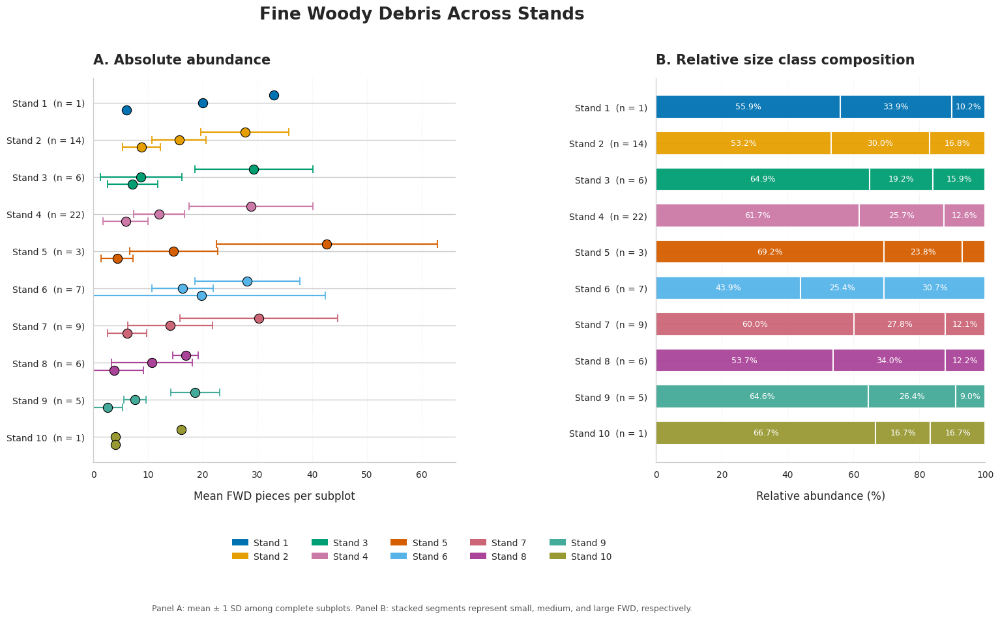

In [192]:

# ============================================================
# STEP 133
# ============================================================
#
# Panel A: Mean FWD pieces per complete subplot, separated by size class.
# Panel B: Relative abundance of FWD size classes.
#
# Both panels use the original ten-stand color palette.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Define the original ten-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

stand_order = list(range(1, 11))
size_class_order = [1, 2, 3]

size_class_labels = {
    1: 'Small (0–0.25 in)',
    2: 'Medium (0.25–1.0 in)',
    3: 'Large (1.0–3.0 in)'
}

# ------------------------------------------------------------
# 2. Calculate absolute abundance statistics
# ------------------------------------------------------------

fwd_absolute_summary = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .agg(['mean', 'std', 'count'])
    .reindex(stand_order)
)

fwd_total_summary = (
    fwd_complete_subplots['Total FWD']
    .groupby(level='Stand ID')
    .agg(['mean', 'std', 'count'])
    .reindex(stand_order)
)

# ------------------------------------------------------------
# 3. Calculate relative abundance
# ------------------------------------------------------------

fwd_class_totals = (
    fwd_complete_subplots[[1, 2, 3]]
    .groupby(level='Stand ID')
    .sum()
    .reindex(stand_order)
)

fwd_relative_plot = (
    fwd_class_totals
    .div(fwd_class_totals.sum(axis=1).replace(0, np.nan), axis=0)
    * 100
)

# ------------------------------------------------------------
# 4. Publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9,
    'savefig.dpi': 600
})

# Create the two-panel figure.
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 10),
    gridspec_kw={'width_ratios': [1.1, 1]}
)

y_positions = np.arange(len(stand_order))

# ------------------------------------------------------------
# 5. PANEL A: Absolute FWD abundance
# ------------------------------------------------------------

vertical_offsets = {
    1: -0.20,
    2: 0.00,
    3: 0.20
}

for size_class in size_class_order:

    means = fwd_absolute_summary[(size_class, 'mean')]
    sds = fwd_absolute_summary[(size_class, 'std')]

    for i, stand in enumerate(stand_order):

        y = y_positions[i] + vertical_offsets[size_class]

        if pd.notna(means.loc[stand]):

            ax1.scatter(
                means.loc[stand],
                y,
                s=105,
                color=stand_colors[stand],
                edgecolor='black',
                linewidth=0.8,
                zorder=3
            )

            if pd.notna(sds.loc[stand]):

                ax1.errorbar(
                    means.loc[stand],
                    y,
                    xerr=sds.loc[stand],
                    fmt='none',
                    ecolor=stand_colors[stand],
                    elinewidth=1.6,
                    capsize=4,
                    capthick=1.3,
                    zorder=2
                )

ax1.set_yticks(y_positions)

ax1.set_yticklabels([
    f'Stand {s}  (n = {int(fwd_total_summary.loc[s, "count"])})'
    for s in stand_order
])

ax1.invert_yaxis()

ax1.set_xlabel(
    'Mean FWD pieces per subplot',
    labelpad=12
)

ax1.set_title(
    'A. Absolute abundance',
    loc='left',
    fontweight='bold',
    pad=15
)

ax1.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax1.set_axisbelow(True)
ax1.set_xlim(left=0)

# ------------------------------------------------------------
# 6. PANEL B: Relative FWD abundance
# ------------------------------------------------------------

for i, stand in enumerate(stand_order):

    percentages = fwd_relative_plot.loc[stand].to_numpy()

    left_position = 0

    for size_class, percentage in zip(
        size_class_order,
        percentages
    ):

        if not np.isfinite(percentage):
            percentage = 0

        ax2.barh(
            y=i,
            width=percentage,
            left=left_position,
            height=0.64,
            color=stand_colors[stand],
            edgecolor='white',
            linewidth=1.5,
            alpha=0.95
        )

        if percentage >= 8:

            ax2.text(
                left_position + percentage / 2,
                i,
                f'{percentage:.1f}%',
                ha='center',
                va='center',
                fontsize=9,
                fontweight='medium',
                color='white'
            )

        left_position += percentage

ax2.set_xlim(0, 100)
ax2.set_xticks([0, 20, 40, 60, 80, 100])

ax2.set_xlabel(
    'Relative abundance (%)',
    labelpad=12
)

ax2.set_yticks(y_positions)

ax2.set_yticklabels([
    f'Stand {s}  (n = {int(fwd_total_summary.loc[s, "count"])})'
    for s in stand_order
])

ax2.invert_yaxis()

ax2.set_title(
    'B. Relative size class composition',
    loc='left',
    fontweight='bold',
    pad=15
)

ax2.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax2.set_axisbelow(True)

# ------------------------------------------------------------
# 7. CREATE SHARED TEN-STAND LEGEND
# ------------------------------------------------------------

stand_legend_handles = [
    Patch(
        facecolor=stand_colors[stand],
        edgecolor='none',
        label=f'Stand {stand}'
    )
    for stand in stand_order
]

# Place the legend in its own dedicated area below the axes.
fig.legend(
    handles=stand_legend_handles,
    loc='lower center',
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 0.105),
    fontsize=10,
    columnspacing=2.5,
    handlelength=1.8,
    handletextpad=0.6
)

# ------------------------------------------------------------
# 8. FIGURE TITLE AND EXPLANATORY NOTE
# ------------------------------------------------------------

fig.suptitle(
    'Fine Woody Debris Across Stands',
    fontsize=19,
    fontweight='bold',
    y=0.97
)


# Explanatory note below the legend.
fig.text(
    0.5,
    0.045,
    'Panel A: mean ± 1 SD among complete subplots. '
    'Panel B: stacked segments represent small, medium, and large FWD, respectively.',
    ha='center',
    va='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 9. FINAL LAYOUT AND SPACING
# ------------------------------------------------------------

# The bottom margin creates a separate band for the legend and note.
fig.subplots_adjust(
    left=0.22,
    right=0.98,
    top=0.86,
    bottom=0.27,
    wspace=0.58
)

# ------------------------------------------------------------
# 10. EXPORT PUBLICATION-QUALITY FILES
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'FWD_Absolute_and_Relative_Abundance.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white',
    pad_inches=0.2
)

fig.savefig(
    export_dir / 'FWD_Absolute_and_Relative_Abundance.pdf',
    bbox_inches='tight',
    facecolor='white',
    pad_inches=0.2
)

plt.show()


In [193]:
# ============================================================
# STEP 134
# ============================================================
#
# This step checks the dataset's dimensions, column names, data types,
# missing values, and the number of observations recorded for each stand.
# We will use these results to determine the appropriate CWD analyses.

# ------------------------------------------------------------
# 1. Display the dataset dimensions
# ------------------------------------------------------------

# Show the number of rows and columns in the CWD dataset.
print("CWD dataset dimensions:")
print(cwd.shape)

# ------------------------------------------------------------
# 2. Display the column names
# ------------------------------------------------------------

# Identify all variables available for the CWD analysis.
print("\nCWD column names:")
print(cwd.columns.tolist())

# ------------------------------------------------------------
# 3. Inspect data types and non-missing observations
# ------------------------------------------------------------

# Show each column's data type and number of non-missing values.
print("\nCWD dataset information:")
cwd.info()

# ------------------------------------------------------------
# 4. Check missing values
# ------------------------------------------------------------

# Count missing observations in each column.
print("\nMissing values by column:")
print(cwd.isnull().sum())

# ------------------------------------------------------------
# 5. Examine the number of observations by stand
# ------------------------------------------------------------

# Display the number of CWD records associated with each stand.
if 'Stand ID' in cwd.columns:

    print("\nCWD observations by stand:")
    print(
        cwd['Stand ID']
        .value_counts(dropna=False)
        .sort_index()
    )

# ------------------------------------------------------------
# 6. Display the first several observations
# ------------------------------------------------------------

# Inspect the actual records to understand how CWD was documented.
print("\nFirst 10 CWD observations:")
display(cwd.head(10))

# ------------------------------------------------------------
# 7. Display numerical summary statistics
# ------------------------------------------------------------

# Summarize numerical columns to identify ranges and potential outliers.
print("\nNumerical summary:")
display(cwd.describe())

CWD dataset dimensions:
(169, 9)

CWD column names:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Log ID', 'CWD Decay Status Code', 'Transect Diameter (in)', 'Notes']

CWD dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Stand ID                169 non-null    int64         
 1   Plot ID                 169 non-null    int64         
 2   Subplot ID              169 non-null    int64         
 3   Date                    169 non-null    datetime64[ns]
 4   Team Member(s)          169 non-null    object        
 5   Log ID                  169 non-null    int64         
 6   CWD Decay Status Code   169 non-null    int64         
 7   Transect Diameter (in)  168 non-null    float64       
 8   Notes                   17 non-null     object        
dtypes: datetime64[ns](1

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Log ID,CWD Decay Status Code,Transect Diameter (in),Notes
0,1,1,1,2026-10-23,"LW, JR, JW, JM, LA, EC, AB, HP",1,4,5.70,NaN
1,2,1,1,2026-10-23,"AB, JR, EC, HP",1,4,4.00,NaN
2,2,1,1,2026-10-23,"AB, JR, EC, HP",2,4,3.50,NaN
3,2,1,1,2026-10-23,"AB, JR, EC, HP",3,2,4.25,NaN
4,2,1,1,2026-10-23,"AB, JR, EC, HP",4,2,3.75,NaN
5,2,1,2,2026-10-23,"EC, AB, HP, JR",1,2,4.50,NaN
6,2,1,2,2026-10-23,"EC, AB, HP, JR",2,2,5.40,NaN
7,2,1,3,2026-10-23,"EC, AB, HP, JR",1,4,3.00,NaN
8,2,1,3,2026-10-23,"EC, AB, HP, JR",2,4,3.65,NaN
9,2,1,3,2026-10-23,"EC, AB, HP, JR",3,3,20.80,Not in transect



Numerical summary:


,Stand ID,Plot ID,Subplot ID,Date,Log ID,CWD Decay Status Code,Transect Diameter (in)
count,169.000000,169.000000,169.000000,169,169.000000,169.000000,168.000000
mean,4.396450,1.449704,4.331361,2026-11-03 22:43:18.816568064,3.112426,2.662722,6.139048
min,1.000000,1.000000,1.000000,2026-10-23 00:00:00,1.000000,1.000000,3.000000
25%,3.000000,1.000000,2.000000,2026-10-30 00:00:00,1.000000,2.000000,3.647500
50%,4.000000,1.000000,3.000000,2026-11-04 00:00:00,2.000000,3.000000,5.415000
75%,6.000000,2.000000,6.000000,2026-11-11 00:00:00,3.000000,3.000000,7.625000
max,9.000000,4.000000,13.000000,2026-11-13 00:00:00,18.000000,5.000000,25.000000
std,1.934089,0.858510,3.228817,NaN,3.202365,1.040190,3.243111


In [194]:
# ============================================================
# STEP 135
# ============================================================
#
# This step:
# 1. Restricts the analysis to Stands 1–10.
# 2. Removes empty spreadsheet columns.
# 3. Identifies records marked as outside the transect.
# 4. Identifies missing diameter measurements.
# 5. Examines the distribution of CWD decay-status codes.
#
# We are not permanently deleting any observations from the original
# cwd dataframe. All work is performed on a separate analysis copy.

# ------------------------------------------------------------
# 1. Create an analysis copy for Stands 1–10
# ------------------------------------------------------------

# Keep only observations belonging to the six study stands.
cwd_analysis = cwd[
    cwd['Stand ID'].isin([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
].copy()

# Remove columns that contain no observations.
# This removes the entirely empty Unnamed: 9 column.
cwd_analysis = cwd_analysis.dropna(axis=1, how='all')

# Display the dimensions after restricting the dataset.
print("CWD analysis dataset dimensions:")
print(cwd_analysis.shape)

# ------------------------------------------------------------
# 2. Identify records marked as outside the transect
# ------------------------------------------------------------

# Search the Notes column for records containing the phrase
# "not in transect", without regard to capitalization.
outside_transect = cwd_analysis[
    cwd_analysis['Notes']
    .fillna('')
    .str.contains('not in transect', case=False)
]

# Display any records identified by this search.
print("\nRecords marked as outside the transect:")
display(outside_transect)

# ------------------------------------------------------------
# 3. Identify missing diameter measurements
# ------------------------------------------------------------

# Find records where Transect Diameter (in) is missing.
missing_cwd_diameter = cwd_analysis[
    cwd_analysis['Transect Diameter (in)'].isna()
]

# Display the records with missing diameter measurements.
print("\nRecords with missing diameter measurements:")
display(missing_cwd_diameter)

# ------------------------------------------------------------
# 4. Examine decay-status code frequencies
# ------------------------------------------------------------

# Count the number of observations assigned to each decay code.
print("\nCWD decay-status code frequencies:")
print(
    cwd_analysis['CWD Decay Status Code']
    .value_counts()
    .sort_index()
)

# Calculate the percentage of observations represented by each code.
print("\nCWD decay-status code percentages:")
print(
    cwd_analysis['CWD Decay Status Code']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

# ------------------------------------------------------------
# 5. Examine diameter distributions
# ------------------------------------------------------------

# Summarize diameter measurements by stand.
# Missing diameter values are automatically excluded from these statistics.
print("\nCWD diameter summary by stand:")
display(
    cwd_analysis
    .groupby('Stand ID')['Transect Diameter (in)']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

# ------------------------------------------------------------
# 6. Inspect all recorded notes
# ------------------------------------------------------------

# Display unique non-missing notes to identify any additional
# observations that may require special treatment.
print("\nUnique CWD notes:")
print(
    cwd_analysis['Notes']
    .dropna()
    .value_counts()
)

CWD analysis dataset dimensions:
(169, 9)

Records marked as outside the transect:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Log ID,CWD Decay Status Code,Transect Diameter (in),Notes
9,2,1,3,2026-10-23,"EC, AB, HP, JR",3,3,20.8,Not in transect



Records with missing diameter measurements:


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Log ID,CWD Decay Status Code,Transect Diameter (in),Notes
120,5,1,1,2026-10-30,"JW, LW, KC, JR",1,2,NaN,NaN



CWD decay-status code frequencies:
CWD Decay Status Code
1    19
2    64
3    49
4    29
5     8
Name: count, dtype: int64

CWD decay-status code percentages:
CWD Decay Status Code
1    11.24
2    37.87
3    28.99
4    17.16
5     4.73
Name: proportion, dtype: float64

CWD diameter summary by stand:


,count,mean,median,std,min,max
Stand ID,,,,,,
1,1,5.70,5.70,NaN,5.70,5.70
2,35,5.53,4.00,3.71,3.00,20.80
3,7,11.57,8.50,6.82,5.00,25.00
4,77,5.89,5.50,2.18,3.00,14.00
5,2,7.40,7.40,5.94,3.20,11.60
6,14,4.97,3.82,2.18,3.11,9.99
7,18,6.94,6.42,3.00,3.12,13.71
8,8,6.47,6.22,3.36,3.08,11.11
9,6,6.02,4.72,3.46,3.09,11.91



Unique CWD notes:
Notes
White birch                                                 4
Not in transect                                             1
Estimate, extremly decomposed                               1
Gray birch                                                  1
Fungi                                                       1
Downed hemlock                                              1
Turkey tail mushroom, honey cap                             1
Covered in moss                                             1
Moss covered & water logged                                 1
Estimated, deacying into ground, cannot wrap tape around    1
Too soft to measure                                         1
Measured half DBH then doubled                              1
Wind blowdown (downed tree DBH = 7.8)                       1
1.70 half diameter x2 = 3.4                                 1
Name: count, dtype: int64


In [195]:
# ============================================================
# STEP 136
# ============================================================
#
# We will exclude:
# 1. Records explicitly marked as outside the transect.
# 2. Records with missing transect diameter measurements.
#
# The original cwd dataframe remains unchanged.

# ------------------------------------------------------------
# 1. Start with the ten-stand analysis dataset
# ------------------------------------------------------------

# Make a copy so that the original dataset is preserved.
cwd_clean = cwd_analysis.copy()

# ------------------------------------------------------------
# 2. Remove records marked as outside the transect
# ------------------------------------------------------------

# Identify notes containing "not in transect".
outside_transect_mask = (
    cwd_clean['Notes']
    .fillna('')
    .str.contains('not in transect', case=False)
)

# Keep only observations that were recorded within the transect.
cwd_clean = cwd_clean.loc[~outside_transect_mask].copy()

# ------------------------------------------------------------
# 3. Remove records with missing diameter measurements
# ------------------------------------------------------------

# Exclude observations without a recorded transect diameter.
cwd_clean = cwd_clean.dropna(
    subset=['Transect Diameter (in)']
).copy()

# ------------------------------------------------------------
# 4. Verify the cleaned dataset
# ------------------------------------------------------------

# Display the number of remaining observations.
print("Cleaned CWD dataset dimensions:")
print(cwd_clean.shape)

# Display the number of observations in each stand.
print("\nCWD observations by stand:")
print(
    cwd_clean['Stand ID']
    .value_counts()
    .sort_index()
)

# Confirm that no diameter measurements are missing.
print("\nMissing diameter measurements:")
print(cwd_clean['Transect Diameter (in)'].isna().sum())

# Confirm that no records marked outside the transect remain.
print("\nRecords marked outside the transect:")
print(
    cwd_clean['Notes']
    .fillna('')
    .str.contains('not in transect', case=False)
    .sum()
)

# Display the cleaned dataset.
display(cwd_clean.head())

Cleaned CWD dataset dimensions:
(167, 9)

CWD observations by stand:
Stand ID
1     1
2    34
3     7
4    77
5     2
6    14
7    18
8     8
9     6
Name: count, dtype: int64

Missing diameter measurements:
0

Records marked outside the transect:
0


,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Log ID,CWD Decay Status Code,Transect Diameter (in),Notes
0,1,1,1,2026-10-23,"LW, JR, JW, JM, LA, EC, AB, HP",1,4,5.70,NaN
1,2,1,1,2026-10-23,"AB, JR, EC, HP",1,4,4.00,NaN
2,2,1,1,2026-10-23,"AB, JR, EC, HP",2,4,3.50,NaN
3,2,1,1,2026-10-23,"AB, JR, EC, HP",3,2,4.25,NaN
4,2,1,1,2026-10-23,"AB, JR, EC, HP",4,2,3.75,NaN


In [196]:
# ============================================================
# STEP 137
# ============================================================
# and transect diameter across the six study stands.
#
# This step examines:
# 1. The number of logs in each decay-status class.
# 2. The relative frequency of each decay-status class.
# 3. Diameter distributions within each stand.
# 4. Overall diameter statistics.

# ------------------------------------------------------------
# 1. Count CWD observations by decay-status class and stand
# ------------------------------------------------------------

# Create a contingency table showing the number of logs
# in each decay-status class for every stand.
cwd_decay_counts = pd.crosstab(
    cwd_clean['Stand ID'],
    cwd_clean['CWD Decay Status Code']
).reindex(index=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], fill_value=0)

# Display the count table.
print("CWD decay-status counts by stand:")
display(cwd_decay_counts)

# ------------------------------------------------------------
# 2. Calculate relative decay-class abundance
# ------------------------------------------------------------

# Calculate the percentage of each decay class within each stand.
# Each stand's percentages will sum to 100%.
cwd_decay_relative = (
    cwd_decay_counts
    .div(cwd_decay_counts.sum(axis=1), axis=0)
    * 100
)

# Round percentages to two decimal places.
cwd_decay_relative = cwd_decay_relative.round(2)

# Display the relative abundance table.
print("\nCWD decay-status relative abundance (%):")
display(cwd_decay_relative)

# ------------------------------------------------------------
# 3. Summarize diameter measurements by stand
# ------------------------------------------------------------

# Calculate sample size, mean, median, standard deviation,
# minimum, quartiles, and maximum diameter for each stand.
cwd_diameter_summary = (
    cwd_clean
    .groupby('Stand ID')['Transect Diameter (in)']
    .describe()
    .reindex([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
    .round(2)
)

# Display the stand-level diameter summary.
print("\nCWD diameter descriptive statistics (inches):")
display(cwd_diameter_summary)

# ------------------------------------------------------------
# 4. Summarize overall diameter measurements
# ------------------------------------------------------------

# Calculate descriptive statistics across all ten stands.
cwd_overall_diameter = (
    cwd_clean['Transect Diameter (in)']
    .describe()
    .round(2)
)

# Display the overall diameter summary.
print("\nOverall CWD diameter statistics (inches):")
display(cwd_overall_diameter)

# ------------------------------------------------------------
# 5. Calculate total logs and mean diameter by stand
# ------------------------------------------------------------

# Create a compact summary table combining log counts
# and average diameter for each stand.
cwd_stand_summary = (
    cwd_clean
    .groupby('Stand ID')
    .agg(
        Log_Count=('Log ID', 'count'),
        Mean_Diameter=('Transect Diameter (in)', 'mean'),
        Median_Diameter=('Transect Diameter (in)', 'median'),
        SD_Diameter=('Transect Diameter (in)', 'std')
    )
    .reindex([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
    .round(2)
)

# Display the combined summary.
print("\nCWD stand-level summary:")
display(cwd_stand_summary)

CWD decay-status counts by stand:


CWD Decay Status Code,1,2,3,4,5
Stand ID,,,,,
1,0,0,0,1,0
2,1,20,8,4,1
3,1,5,1,0,0
4,8,23,20,20,6
5,0,1,0,0,1
6,2,8,3,1,0
7,6,1,9,2,0
8,0,3,5,0,0
9,1,2,2,1,0



CWD decay-status relative abundance (%):


CWD Decay Status Code,1,2,3,4,5
Stand ID,,,,,
1,0.00,0.00,0.00,100.00,0.00
2,2.94,58.82,23.53,11.76,2.94
3,14.29,71.43,14.29,0.00,0.00
4,10.39,29.87,25.97,25.97,7.79
5,0.00,50.00,0.00,0.00,50.00
6,14.29,57.14,21.43,7.14,0.00
7,33.33,5.56,50.00,11.11,0.00
8,0.00,37.50,62.50,0.00,0.00
9,16.67,33.33,33.33,16.67,0.00



CWD diameter descriptive statistics (inches):


,count,mean,std,min,25%,50%,75%,max
Stand ID,,,,,,,,
1,1.0,5.70,NaN,5.70,5.70,5.70,5.70,5.70
2,34.0,5.08,2.62,3.00,3.42,3.96,5.56,14.12
3,7.0,11.57,6.82,5.00,7.50,8.50,13.75,25.00
4,77.0,5.89,2.18,3.00,4.00,5.50,7.50,14.00
5,2.0,7.40,5.94,3.20,5.30,7.40,9.50,11.60
6,14.0,4.97,2.18,3.11,3.31,3.82,6.55,9.99
7,18.0,6.94,3.00,3.12,4.11,6.42,9.52,13.71
8,8.0,6.47,3.36,3.08,3.26,6.22,8.92,11.11
9,6.0,6.03,3.46,3.09,3.55,4.72,7.60,11.91



Overall CWD diameter statistics (inches):


,Transect Diameter (in)
count,167.00
mean,6.05
std,3.05
min,3.00
25%,3.64
50%,5.40
75%,7.60
max,25.00



CWD stand-level summary:


,Log_Count,Mean_Diameter,Median_Diameter,SD_Diameter
Stand ID,,,,
1,1.0,5.70,5.70,NaN
2,34.0,5.08,3.96,2.62
3,7.0,11.57,8.50,6.82
4,77.0,5.89,5.50,2.18
5,2.0,7.40,7.40,5.94
6,14.0,4.97,3.82,2.18
7,18.0,6.94,6.42,3.00
8,8.0,6.47,6.22,3.36
9,6.0,6.02,4.72,3.46


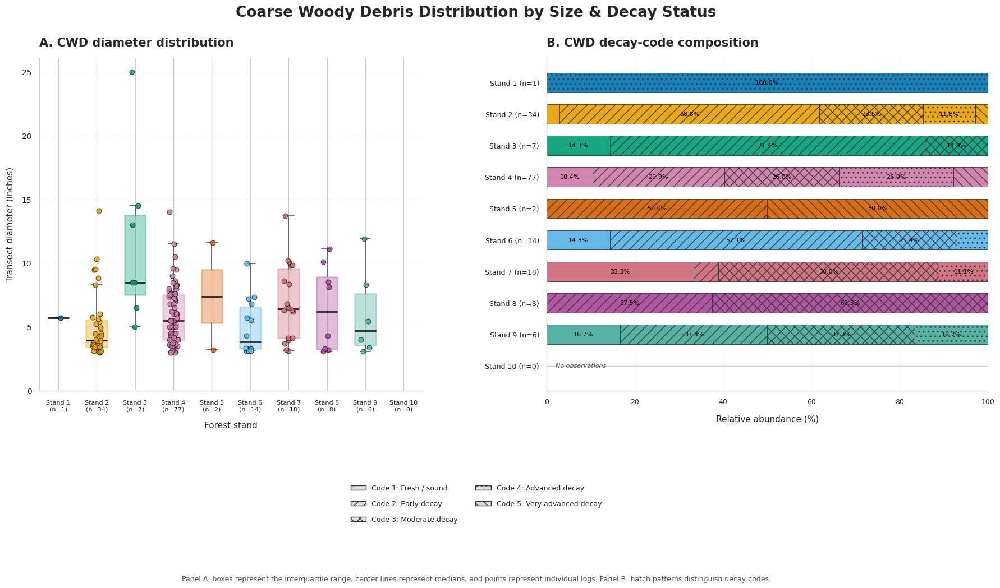

In [199]:

# ============================================================
# STEP 138
# ============================================================
#
# Panel A: CWD diameter distributions by stand.
# Panel B: Relative abundance of decay-status codes within each stand.
#
# Original ten-stand color palette retained.
# Hatch patterns distinguish decay codes.
# Decay-code definitions included in the figure legend.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. DEFINE ORIGINAL TEN-STAND COLOR PALETTE
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

stand_order = list(range(1, 11))
decay_code_order = [1, 2, 3, 4, 5]

# Hatch patterns distinguish decay codes.
decay_hatches = {
    1: '',
    2: '//',
    3: 'xx',
    4: '..',
    5: '\\\\'
}

# ------------------------------------------------------------
# 2. FIGURE FORMATTING
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 15,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9,
    'savefig.dpi': 600
})

# Create two-panel figure.
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(19, 11),
    gridspec_kw={'width_ratios': [1, 1.15]}
)

# ------------------------------------------------------------
# 3. PANEL A: CWD DIAMETER DISTRIBUTIONS
# ------------------------------------------------------------

# Extract diameter measurements for all ten stands.
diameter_data = [
    cwd_clean.loc[
        cwd_clean['Stand ID'] == stand,
        'Transect Diameter (in)'
    ].dropna().values
    for stand in stand_order
]

# Create boxplots.
boxplot = ax1.boxplot(
    diameter_data,
    positions=np.arange(1, 11),
    widths=0.55,
    patch_artist=True,
    showfliers=False,
    medianprops={
        'color': 'black',
        'linewidth': 1.8
    },
    whiskerprops={
        'color': '#555555',
        'linewidth': 1.2
    },
    capprops={
        'color': '#555555',
        'linewidth': 1.2
    }
)

# Apply original stand colors.
for box, stand in zip(boxplot['boxes'], stand_order):
    box.set_facecolor(stand_colors[stand])
    box.set_alpha(0.35)
    box.set_edgecolor(stand_colors[stand])
    box.set_linewidth(1.8)

# Overlay individual log measurements.
rng = np.random.default_rng(42)

for position, stand, values in zip(
    range(1, 11),
    stand_order,
    diameter_data
):

    if len(values) > 0:

        jitter = rng.uniform(
            -0.12,
            0.12,
            size=len(values)
        )

        ax1.scatter(
            position + jitter,
            values,
            s=42,
            color=stand_colors[stand],
            edgecolor='black',
            linewidth=0.55,
            alpha=0.85,
            zorder=3
        )

# Calculate sample sizes.
stand_sample_sizes = [
    len(values) for values in diameter_data
]

# Format stand labels.
ax1.set_xticks(range(1, 11))

ax1.set_xticklabels(
    [
        f'Stand {stand}\n(n={n})'
        for stand, n in zip(
            stand_order,
            stand_sample_sizes
        )
    ],
    fontsize=8
)

ax1.tick_params(
    axis='x',
    pad=9,
    length=3
)

# Axis labels.
ax1.set_xlabel(
    'Forest stand',
    labelpad=12
)

ax1.set_ylabel(
    'Transect diameter (inches)',
    labelpad=10
)

# Panel title.
ax1.set_title(
    'A. CWD diameter distribution',
    loc='left',
    fontweight='bold',
    pad=15
)

# Horizontal gridlines.
ax1.grid(
    axis='y',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax1.set_axisbelow(True)
ax1.set_ylim(bottom=0)
ax1.set_xlim(0.5, 10.5)

# ------------------------------------------------------------
# 4. PANEL B: RELATIVE DECAY-CODE COMPOSITION
# ------------------------------------------------------------

# Count observations by stand and decay code.
cwd_decay_counts_plot = (
    cwd_clean
    .groupby(['Stand ID', 'CWD Decay Status Code'])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=stand_order,
        columns=decay_code_order,
        fill_value=0
    )
)

# Calculate the total number of logs in each stand.
stand_decay_totals = cwd_decay_counts_plot.sum(axis=1)

# Calculate relative abundance within each stand.
cwd_decay_relative_plot = (
    cwd_decay_counts_plot
    .div(
        stand_decay_totals.replace(0, np.nan),
        axis=0
    )
    * 100
).fillna(0)

# Draw stacked horizontal bars.
for y_position, stand in enumerate(stand_order):

    left_position = 0

    for decay_code in decay_code_order:

        percentage = cwd_decay_relative_plot.loc[
            stand,
            decay_code
        ]

        if not np.isfinite(percentage):
            percentage = 0

        ax2.barh(
            y=y_position,
            width=percentage,
            left=left_position,
            height=0.62,
            color=stand_colors[stand],
            edgecolor='#333333',
            linewidth=0.65,
            hatch=decay_hatches[decay_code],
            alpha=0.9
        )

        # Add percentage labels to sufficiently large segments.
        if percentage >= 10:

            ax2.text(
                left_position + percentage / 2,
                y_position,
                f'{percentage:.1f}%',
                ha='center',
                va='center',
                fontsize=8,
                color='black',
                fontweight='medium'
            )

        left_position += percentage

    # Identify stands without observations.
    if stand_decay_totals.loc[stand] == 0:

        ax2.text(
            2,
            y_position,
            'No observations',
            ha='left',
            va='center',
            fontsize=8,
            color='#555555',
            style='italic'
        )

# Format Panel B axes.
ax2.set_xlim(0, 100)
ax2.set_xticks([0, 20, 40, 60, 80, 100])

ax2.set_xlabel(
    'Relative abundance (%)',
    labelpad=12
)

ax2.set_yticks(range(10))

ax2.set_yticklabels(
    [
        f'Stand {stand} (n={int(stand_decay_totals.loc[stand])})'
        for stand in stand_order
    ],
    fontsize=9
)

ax2.invert_yaxis()

ax2.set_title(
    'B. CWD decay-code composition',
    loc='left',
    fontweight='bold',
    pad=15
)

ax2.grid(
    axis='x',
    linestyle=':',
    linewidth=0.8,
    alpha=0.4
)

ax2.set_axisbelow(True)

# ------------------------------------------------------------
# 5. DECAY-CODE DEFINITIONS AND LEGEND
# ------------------------------------------------------------

# Concise descriptions of the five decay stages.
decay_code_definitions = {
    1: 'Code 1: Fresh / sound',
    2: 'Code 2: Early decay',
    3: 'Code 3: Moderate decay',
    4: 'Code 4: Advanced decay',
    5: 'Code 5: Very advanced decay'
}

# Create legend patches.
decay_legend_handles = [
    Patch(
        facecolor='#DDDDDD',
        edgecolor='#333333',
        hatch=decay_hatches[code],
        label=decay_code_definitions[code]
    )
    for code in decay_code_order
]

# Place the decay-code key in its own area below both panels.
fig.legend(
    handles=decay_legend_handles,
    loc='lower center',
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.115),
    fontsize=9,
    labelspacing=1.2,
    columnspacing=2.5,
    handlelength=2.2,
    handletextpad=0.8
)

# ------------------------------------------------------------
# 6. FIGURE TITLE
# ------------------------------------------------------------

fig.suptitle(
    'Coarse Woody Debris Distribution by Size & Decay Status',
    fontsize=19,
    fontweight='bold',
    y=0.965
)

# ------------------------------------------------------------
# 7. EXPLANATORY NOTE
# ------------------------------------------------------------

fig.text(
    0.5,
    0.035,
    'Panel A: boxes represent the interquartile range, center lines represent medians, '
    'and points represent individual logs. Panel B: hatch patterns distinguish decay codes.',
    ha='center',
    va='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 8. FINAL LAYOUT AND SPACING
# ------------------------------------------------------------

# Reserve separate space for:
# - Figure title
# - Both plotting panels
# - Decay-code definitions
# - Explanatory note

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.88,
    bottom=0.34,
    wspace=0.30
)

# ------------------------------------------------------------
# 9. EXPORT PUBLICATION-QUALITY FILES
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'CWD_Diameter_and_Decay_Composition.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white',
    pad_inches=0.2
)

fig.savefig(
    export_dir / 'CWD_Diameter_and_Decay_Composition.pdf',
    bbox_inches='tight',
    facecolor='white',
    pad_inches=0.2
)

# Display completed figure.
plt.show()


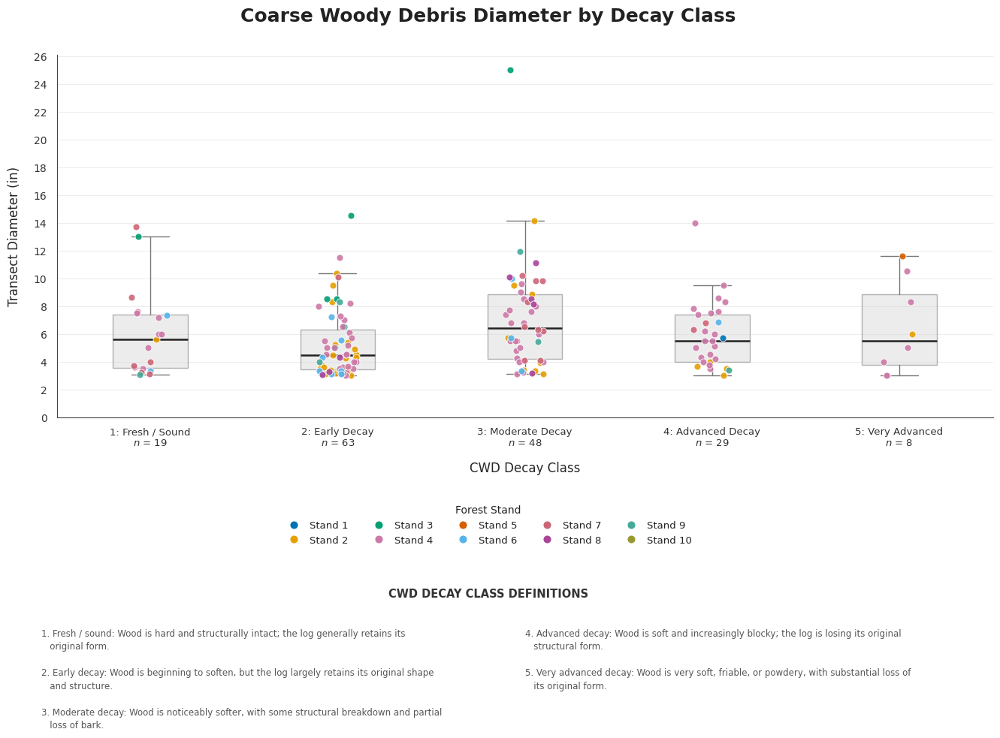

In [204]:

# ============================================================
# STEP 139
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import textwrap

# ------------------------------------------------------------
# 1. Define the original ten-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

stand_order = list(range(1, 11))
decay_code_order = [1, 2, 3, 4, 5]

# ------------------------------------------------------------
# 2. Define decay-class names and descriptions
# ------------------------------------------------------------

decay_abbreviations = {
    1: 'Fresh / Sound',
    2: 'Early Decay',
    3: 'Moderate Decay',
    4: 'Advanced Decay',
    5: 'Very Advanced'
}

decay_code_definitions = {
    1: (
        'Fresh / sound: Wood is hard and structurally intact; '
        'the log generally retains its original form.'
    ),
    2: (
        'Early decay: Wood is beginning to soften, but the log '
        'largely retains its original shape and structure.'
    ),
    3: (
        'Moderate decay: Wood is noticeably softer, with some '
        'structural breakdown and partial loss of bark.'
    ),
    4: (
        'Advanced decay: Wood is soft and increasingly blocky; '
        'the log is losing its original structural form.'
    ),
    5: (
        'Very advanced decay: Wood is very soft, friable, or '
        'powdery, with substantial loss of its original form.'
    )
}

# ------------------------------------------------------------
# 3. Prepare the plotting dataframe
# ------------------------------------------------------------

cwd_publication = cwd_clean.copy()

cwd_publication = cwd_publication[
    cwd_publication['CWD Decay Status Code'].isin(decay_code_order)
    & cwd_publication['Transect Diameter (in)'].notna()
].copy()

cwd_publication['CWD Decay Status Code'] = (
    cwd_publication['CWD Decay Status Code'].astype(int)
)

cwd_publication['Transect Diameter (in)'] = (
    cwd_publication['Transect Diameter (in)'].astype(float)
)

cwd_publication = cwd_publication[
    np.isfinite(cwd_publication['Transect Diameter (in)'])
].copy()

cwd_publication['Decay Position'] = (
    cwd_publication['CWD Decay Status Code']
)

# ------------------------------------------------------------
# 4. Calculate sample sizes and diameter distributions
# ------------------------------------------------------------

diameter_by_decay = [
    cwd_publication.loc[
        cwd_publication['CWD Decay Status Code'] == code,
        'Transect Diameter (in)'
    ].values
    for code in decay_code_order
]

decay_sample_sizes = [
    len(values) for values in diameter_by_decay
]

# ------------------------------------------------------------
# 5. Establish publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 15,
    'axes.labelsize': 12,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 10,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#444444',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'text.color': '#222222',
    'savefig.dpi': 600
})

# Increased figure height creates room for the legend and definitions.
fig, ax = plt.subplots(figsize=(14, 11.5))

# ------------------------------------------------------------
# 6. Create the boxplots
# ------------------------------------------------------------

boxplot = ax.boxplot(
    diameter_by_decay,
    positions=decay_code_order,
    widths=0.40,
    patch_artist=True,
    showfliers=False,
    medianprops={
        'color': '#222222',
        'linewidth': 1.8
    },
    whiskerprops={
        'color': '#777777',
        'linewidth': 1.0
    },
    capprops={
        'color': '#777777',
        'linewidth': 1.0
    },
    boxprops={
        'edgecolor': '#666666',
        'linewidth': 1.0
    }
)

for box in boxplot['boxes']:
    box.set_facecolor('#D9D9D9')
    box.set_alpha(0.48)
    box.set_edgecolor('#666666')

# ------------------------------------------------------------
# 7. Add horizontal jitter to individual observations
# ------------------------------------------------------------

rng = np.random.default_rng(42)

cwd_publication['Horizontal Jitter'] = rng.uniform(
    -0.105,
    0.105,
    size=len(cwd_publication)
)

cwd_publication['Plot X'] = (
    cwd_publication['Decay Position']
    + cwd_publication['Horizontal Jitter']
)

# ------------------------------------------------------------
# 8. Plot individual observations using stand colors
# ------------------------------------------------------------

for stand in stand_order:

    stand_data = cwd_publication[
        cwd_publication['Stand ID'] == stand
    ]

    ax.scatter(
        stand_data['Plot X'],
        stand_data['Transect Diameter (in)'],
        s=42,
        color=stand_colors[stand],
        edgecolor='white',
        linewidth=0.65,
        alpha=0.90,
        zorder=3
    )

# ------------------------------------------------------------
# 9. Format the decay-class x-axis
# ------------------------------------------------------------

ax.set_xticks(decay_code_order)

ax.set_xticklabels([
    f'{code}: {decay_abbreviations[code]}\n'
    f'$n$ = {sample_size}'
    for code, sample_size in zip(
        decay_code_order,
        decay_sample_sizes
    )
])

ax.set_xlabel(
    'CWD Decay Class',
    labelpad=13,
    fontweight='medium'
)

# ------------------------------------------------------------
# 10. Format the diameter y-axis
# ------------------------------------------------------------

ax.set_ylabel(
    'Transect Diameter (in)',
    labelpad=12,
    fontweight='medium'
)

ax.set_ylim(bottom=0)
ax.set_yticks(np.arange(0, 27, 2))

# ------------------------------------------------------------
# 11. Refine gridlines and plot boundaries
# ------------------------------------------------------------

ax.grid(
    axis='y',
    color='#E5E5E5',
    linestyle='-',
    linewidth=0.65,
    alpha=0.8
)

ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ------------------------------------------------------------
# 12. Add the figure title
# ------------------------------------------------------------

fig.suptitle(
    'Coarse Woody Debris Diameter by Decay Class',
    fontsize=18,
    fontweight='bold',
    y=0.965
)

# ------------------------------------------------------------
# 13. Create the ten-stand color legend
# ------------------------------------------------------------

stand_legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        linestyle='none',
        markerfacecolor=stand_colors[stand],
        markeredgecolor='white',
        markeredgewidth=0.7,
        markersize=8,
        label=f'Stand {stand}'
    )
    for stand in stand_order
]

# Place legend in its own dedicated section.
fig.legend(
    handles=stand_legend_handles,
    title='Forest Stand',
    loc='center',
    bbox_to_anchor=(0.5, 0.365),
    ncol=5,
    frameon=False,
    fontsize=9.5,
    title_fontsize=10,
    columnspacing=2.0,
    handletextpad=0.6
)

# ------------------------------------------------------------
# 14. Add the decay-class definitions
# ------------------------------------------------------------

# Dedicated heading, separated from the stand legend.
fig.text(
    0.5,
    0.285,
    'CWD DECAY CLASS DEFINITIONS',
    ha='center',
    va='center',
    fontsize=10.5,
    fontweight='bold',
    color='#333333'
)

# Split definitions into two balanced columns.
left_codes = [1, 2, 3]
right_codes = [4, 5]

# Wrap descriptions to prevent text from extending into
# the opposite column or beyond the figure boundaries.
def format_decay_definition(code, width=92):
    description = decay_code_definitions[code]
    wrapped = textwrap.fill(
        description,
        width=width,
        subsequent_indent='   '
    )
    return f'{code}. {wrapped}'

left_definitions = '\n\n'.join(
    format_decay_definition(code, width=88)
    for code in left_codes
)

right_definitions = '\n\n'.join(
    format_decay_definition(code, width=88)
    for code in right_codes
)

# Left column: decay classes 1–3.
fig.text(
    0.075,
    0.245,
    left_definitions,
    ha='left',
    va='top',
    fontsize=8.5,
    color='#555555',
    linespacing=1.45
)

# Right column: decay classes 4–5.
fig.text(
    0.535,
    0.245,
    right_definitions,
    ha='left',
    va='top',
    fontsize=8.5,
    color='#555555',
    linespacing=1.45
)

# ------------------------------------------------------------
# 15. Adjust the figure layout
# ------------------------------------------------------------

# Keep the graph separate from the legend and definitions.
fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.91,
    bottom=0.49
)

# ------------------------------------------------------------
# 16. Export publication-quality figure
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'CWD_Diameter_by_Decay_Class_Publication.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    export_dir / 'CWD_Diameter_by_Decay_Class_Publication.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()


In [205]:
# ============================================================
# STEP 140
# ============================================================
#
# This step identifies the available O horizon measurements,
# checks missing values, and examines observations by stand.
# We will not modify the original dataset.

# ------------------------------------------------------------
# 1. Inspect dataset dimensions and columns
# ------------------------------------------------------------

print("Hydrology and surface dataset dimensions:")
print(hydrology_surface.shape)

print("\nColumn names:")
print(hydrology_surface.columns.tolist())

# ------------------------------------------------------------
# 2. Inspect data types and missing values
# ------------------------------------------------------------

print("\nDataset information:")
hydrology_surface.info()

print("\nMissing values by column:")
print(hydrology_surface.isnull().sum())

# ------------------------------------------------------------
# 3. Identify O horizon-related columns
# ------------------------------------------------------------

# Find columns whose names contain "horizon" or "organic".
o_horizon_columns = [
    column for column in hydrology_surface.columns
    if 'horizon' in column.lower()
    or 'organic' in column.lower()
]

print("\nPotential O horizon columns:")
print(o_horizon_columns)

# ------------------------------------------------------------
# 4. Display observations and numerical summaries
# ------------------------------------------------------------

print("\nFirst 10 observations:")
display(hydrology_surface.head(10))

print("\nNumerical summary:")
display(hydrology_surface.describe())

# ------------------------------------------------------------
# 5. Examine observations by stand
# ------------------------------------------------------------

if 'Stand ID' in hydrology_surface.columns:

    print("\nObservations by stand:")
    print(
        hydrology_surface['Stand ID']
        .value_counts()
        .sort_index()
    )

Hydrology and surface dataset dimensions:
(75, 11)

Column names:
['Stand ID', 'Plot ID', 'Subplot ID', 'Date', 'Team Member(s)', 'Water (Present/Absent)', 'Water Type (If Applicable)', 'O Horizon Depth (Litter, Duff, Humus) (in)', 'Surface Organic Cover (%) Code', 'Surface Inorganic Cover (%) Code', 'Notes']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 11 columns):
 #   Column                                      Non-Null Count  Dtype         
---  ------                                      --------------  -----         
 0   Stand ID                                    75 non-null     int64         
 1   Plot ID                                     75 non-null     int64         
 2   Subplot ID                                  75 non-null     int64         
 3   Date                                        75 non-null     datetime64[ns]
 4   Team Member(s)                              75 non-null     object        
 5  

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Water (Present/Absent),Water Type (If Applicable),"O Horizon Depth (Litter, Duff, Humus) (in)",Surface Organic Cover (%) Code,Surface Inorganic Cover (%) Code,Notes
0,1,1,1,2026-10-23,"TQ, EJ, EC, JM, JW, LA, HP, LW, AB",Absent,NaN,14.0,4,2,NaN
1,2,1,1,2026-10-23,"JW, JM, LA, LW",Absent,NaN,3.0,4,1,NaN
2,2,1,2,2026-10-23,"JW, JM, LA, LW",Present,Permanent Stream,14.0,2,2,NaN
3,2,1,3,2026-10-23,"JW, JM, LA, LW",Absent,NaN,8.5,4,1,NaN
4,2,2,1,2026-10-28,LA,Absent,NaN,8.0,4,2,NaN
5,2,2,2,2026-10-28,"LA, AB",Absent,NaN,11.5,4,3,NaN
6,2,2,3,2026-10-28,"LA, AB",Absent,NaN,5.0,4,3,NaN
7,2,2,4,2026-10-30,LA,Present,Ephemeral Stream,3.5,4,1,NaN
8,2,3,1,2026-10-30,LA,Absent,NaN,2.3,4,2,NaN
9,2,3,2,2026-10-30,"LA, AB",Present,Permanent Stream,5.4,4,2,NaN



Numerical summary:


,Stand ID,Plot ID,Subplot ID,Date,"O Horizon Depth (Litter, Duff, Humus) (in)",Surface Organic Cover (%) Code,Surface Inorganic Cover (%) Code
count,75.000000,75.000000,75.00000,75,75.000000,75.000000,75.000000
mean,4.800000,1.493333,3.96000,2026-11-05 10:52:48,7.212400,3.960000,1.493333
min,1.000000,1.000000,1.00000,2026-10-23 00:00:00,1.000000,2.000000,1.000000
25%,3.000000,1.000000,2.00000,2026-10-30 00:00:00,3.425000,4.000000,1.000000
50%,4.000000,1.000000,3.00000,2026-11-05 00:00:00,6.100000,4.000000,1.000000
75%,7.000000,2.000000,5.50000,2026-11-11 00:00:00,9.750000,4.000000,2.000000
max,10.000000,4.000000,13.00000,2026-11-13 00:00:00,22.000000,4.000000,3.000000
std,2.313299,0.794803,2.91983,NaN,4.388413,0.256799,0.623272



Observations by stand:
Stand ID
1      1
2     15
3      6
4     22
5      3
6      7
7      9
8      6
9      5
10     1
Name: count, dtype: int64


In [206]:
# ============================================================
# STEP 141
# ============================================================
#
# This step:
# 1. Restricts the analysis to Stands 1–10.
# 2. Creates a separate O horizon analysis dataframe.
# 3. Calculates descriptive statistics by stand.
# 4. Examines the distribution of O horizon depth across all stands.
#
# O horizon depth is measured in inches.

# ------------------------------------------------------------
# 1. Create the ten-stand O horizon analysis dataset
# ------------------------------------------------------------

# Keep observations belonging to the six primary study stands.
o_horizon = hydrology_surface[
    hydrology_surface['Stand ID'].isin([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
].copy()

# Display the dimensions of the analysis dataset.
print("O horizon analysis dataset dimensions:")
print(o_horizon.shape)

# ------------------------------------------------------------
# 2. Calculate descriptive statistics by stand
# ------------------------------------------------------------

# Summarize O horizon depth for each stand.
# Statistics include sample size, mean, standard deviation,
# median, quartiles, minimum, and maximum.
o_horizon_summary = (
    o_horizon
    .groupby('Stand ID')['O Horizon Depth (Litter, Duff, Humus) (in)']
    .describe()
    .reindex([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
    .round(2)
)

# Display the stand-level summary.
print("\nO horizon depth by stand (inches):")
display(o_horizon_summary)

# ------------------------------------------------------------
# 3. Calculate overall O horizon statistics
# ------------------------------------------------------------

# Summarize depth measurements across all ten stands.
o_horizon_overall = (
    o_horizon['O Horizon Depth (Litter, Duff, Humus) (in)']
    .describe()
    .round(2)
)

# Display the overall summary.
print("\nOverall O horizon depth statistics (inches):")
display(o_horizon_overall)

# ------------------------------------------------------------
# 4. Calculate stand-level sample sizes and means
# ------------------------------------------------------------

# Create a compact comparison table.
o_horizon_stand_summary = (
    o_horizon
    .groupby('Stand ID')
    .agg(
        Subplot_Count=('Subplot ID', 'count'),
        Mean_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'mean'),
        Median_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'median'),
        SD_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'std'),
        Minimum_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'min'),
        Maximum_Depth=('O Horizon Depth (Litter, Duff, Humus) (in)', 'max')
    )
    .reindex([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
    .round(2)
)

# Display the compact stand-level comparison.
print("\nO horizon stand-level comparison:")
display(o_horizon_stand_summary)

O horizon analysis dataset dimensions:
(75, 11)

O horizon depth by stand (inches):


,count,mean,std,min,25%,50%,75%,max
Stand ID,,,,,,,,
1,1.0,14.00,NaN,14.0,14.00,14.0,14.00,14.0
2,15.0,5.78,3.87,1.0,2.75,5.0,8.25,14.0
3,6.0,5.17,2.40,3.0,3.25,4.5,6.50,9.0
4,22.0,8.36,5.53,1.0,4.25,7.0,12.75,22.0
5,3.0,6.47,3.20,2.8,5.35,7.9,8.30,8.7
6,7.0,9.00,3.18,4.5,7.00,9.5,10.50,14.0
7,9.0,7.06,3.92,2.5,3.00,6.0,11.00,13.0
8,6.0,5.94,4.95,3.0,3.27,3.8,5.56,15.8
9,5.0,6.14,1.82,4.2,5.00,6.1,6.40,9.0



Overall O horizon depth statistics (inches):


,"O Horizon Depth (Litter, Duff, Humus) (in)"
count,75.00
mean,7.21
std,4.39
min,1.00
25%,3.42
50%,6.10
75%,9.75
max,22.00



O horizon stand-level comparison:


,Subplot_Count,Mean_Depth,Median_Depth,SD_Depth,Minimum_Depth,Maximum_Depth
Stand ID,,,,,,
1,1,14.00,14.0,NaN,14.0,14.0
2,15,5.78,5.0,3.87,1.0,14.0
3,6,5.17,4.5,2.40,3.0,9.0
4,22,8.36,7.0,5.53,1.0,22.0
5,3,6.47,7.9,3.20,2.8,8.7
6,7,9.00,9.5,3.18,4.5,14.0
7,9,7.06,6.0,3.92,2.5,13.0
8,6,5.94,3.8,4.95,3.0,15.8
9,5,6.14,6.1,1.82,4.2,9.0


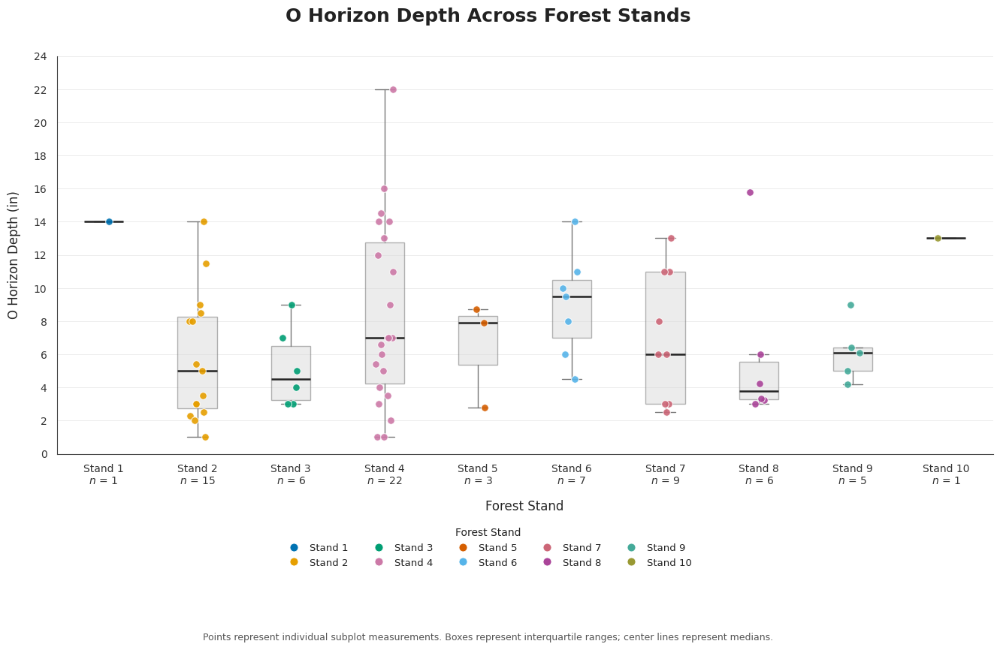

In [208]:

# ============================================================
# STEP 142
# ============================================================
#
# Each point represents one subplot measurement.
# Boxplots summarize the median and interquartile range.
# Point colors represent forest stand using the original palette.
#
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Define the original ten-stand color palette
# ------------------------------------------------------------

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

stand_order = list(range(1, 11))

# ------------------------------------------------------------
# 2. Prepare the O horizon plotting data
# ------------------------------------------------------------

o_horizon_plot = o_horizon.copy()

depth_column = 'O Horizon Depth (Litter, Duff, Humus) (in)'

# Ensure measurements are numeric.
o_horizon_plot[depth_column] = (
    o_horizon_plot[depth_column]
    .replace('', np.nan)
)

o_horizon_plot[depth_column] = (
    __import__('pandas').to_numeric(
        o_horizon_plot[depth_column],
        errors='coerce'
    )
)

# Retain valid stand identifiers and measurements.
o_horizon_plot = o_horizon_plot[
    o_horizon_plot['Stand ID'].isin(stand_order)
    & o_horizon_plot[depth_column].notna()
    & np.isfinite(o_horizon_plot[depth_column])
].copy()

# Extract measurements separately for each stand.
depth_by_stand = [
    o_horizon_plot.loc[
        o_horizon_plot['Stand ID'] == stand,
        depth_column
    ].values
    for stand in stand_order
]

# Calculate sample sizes.
sample_sizes = [
    len(values) for values in depth_by_stand
]

# ------------------------------------------------------------
# 3. Establish publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 15,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#444444',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'text.color': '#222222',
    'savefig.dpi': 600
})

# Increased figure height provides dedicated space
# for the legend and explanatory note.
fig, ax = plt.subplots(figsize=(14, 10))

# ------------------------------------------------------------
# 4. Create boxplots
# ------------------------------------------------------------

boxplot = ax.boxplot(
    depth_by_stand,
    positions=np.arange(1, 11),
    widths=0.42,
    patch_artist=True,
    showfliers=False,
    medianprops={
        'color': '#222222',
        'linewidth': 1.8
    },
    whiskerprops={
        'color': '#777777',
        'linewidth': 1.0
    },
    capprops={
        'color': '#777777',
        'linewidth': 1.0
    },
    boxprops={
        'edgecolor': '#666666',
        'linewidth': 1.0
    }
)

# Apply neutral, partially transparent box fill.
for box in boxplot['boxes']:
    box.set_facecolor('#D9D9D9')
    box.set_alpha(0.48)
    box.set_edgecolor('#666666')

# ------------------------------------------------------------
# 5. Plot individual subplot observations
# ------------------------------------------------------------

# Fixed random seed ensures reproducible jitter.
rng = np.random.default_rng(42)

o_horizon_plot['Jitter'] = rng.uniform(
    -0.10,
    0.10,
    size=len(o_horizon_plot)
)

# Plot each stand using its original color.
for stand in stand_order:

    stand_data = o_horizon_plot[
        o_horizon_plot['Stand ID'] == stand
    ]

    ax.scatter(
        stand + stand_data['Jitter'],
        stand_data[depth_column],
        s=48,
        color=stand_colors[stand],
        edgecolor='white',
        linewidth=0.7,
        alpha=0.90,
        zorder=3
    )

# ------------------------------------------------------------
# 6. Format the x-axis
# ------------------------------------------------------------

ax.set_xticks(np.arange(1, 11))

ax.set_xticklabels([
    f'Stand {stand}\n$n$ = {n}'
    for stand, n in zip(stand_order, sample_sizes)
])

ax.set_xlabel(
    'Forest Stand',
    labelpad=13,
    fontweight='medium'
)

ax.set_xlim(0.5, 10.5)

# ------------------------------------------------------------
# 7. Format the y-axis
# ------------------------------------------------------------

ax.set_ylabel(
    'O Horizon Depth (in)',
    labelpad=12,
    fontweight='medium'
)

ax.set_yticks(np.arange(0, 25, 2))
ax.set_ylim(0, 24)

# ------------------------------------------------------------
# 8. Refine gridlines and plot boundaries
# ------------------------------------------------------------

ax.grid(
    axis='y',
    color='#E5E5E5',
    linestyle='-',
    linewidth=0.65,
    alpha=0.8
)

ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ------------------------------------------------------------
# 9. Add the figure title
# ------------------------------------------------------------

fig.suptitle(
    'O Horizon Depth Across Forest Stands',
    fontsize=18,
    fontweight='bold',
    y=0.965
)

# ------------------------------------------------------------
# 10. Create the ten-stand color legend
# ------------------------------------------------------------

stand_legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        linestyle='none',
        markerfacecolor=stand_colors[stand],
        markeredgecolor='white',
        markeredgewidth=0.7,
        markersize=8,
        label=f'Stand {stand}'
    )
    for stand in stand_order
]

# Place the legend in its own dedicated section.
fig.legend(
    handles=stand_legend_handles,
    title='Forest Stand',
    loc='center',
    bbox_to_anchor=(0.5, 0.245),
    ncol=5,
    frameon=False,
    fontsize=9.5,
    title_fontsize=10,
    columnspacing=2.0,
    handletextpad=0.6
)

# ------------------------------------------------------------
# 11. Add the explanatory note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.125,
    'Points represent individual subplot measurements. '
    'Boxes represent interquartile ranges; '
    'center lines represent medians.',
    ha='center',
    va='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 12. Adjust figure layout
# ------------------------------------------------------------

# Reserve distinct vertical areas for:
# - Main graph
# - Stand legend
# - Explanatory note

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.90,
    bottom=0.37
)

# ------------------------------------------------------------
# 13. Export the figure
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'O_Horizon_Depth_by_Stand.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    export_dir / 'O_Horizon_Depth_by_Stand.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()


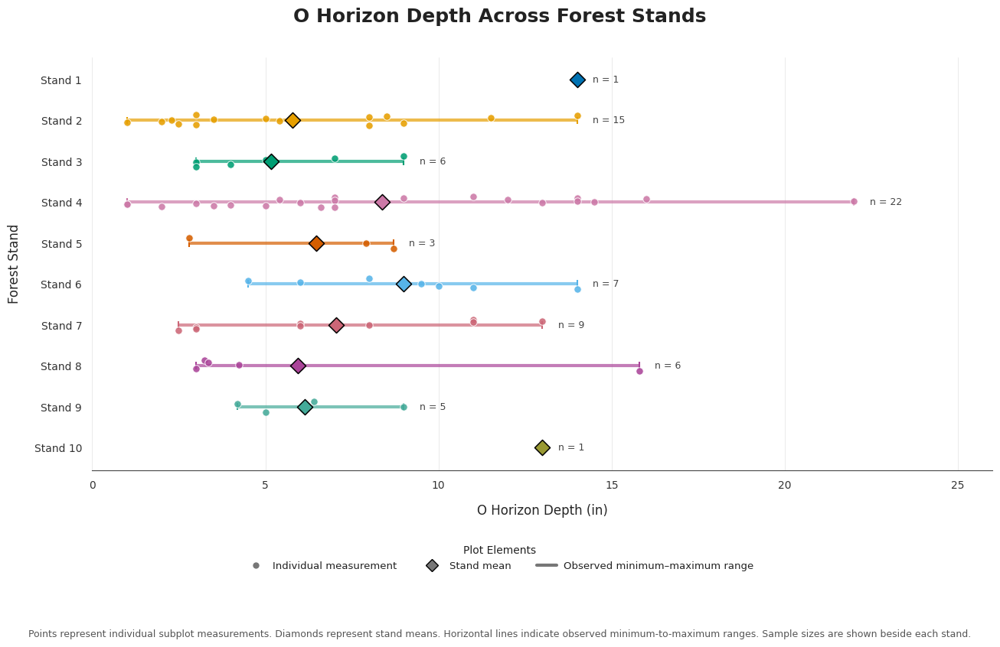

In [209]:

# ============================================================
# STEP 143
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Define the measurement column and stand palette
# ------------------------------------------------------------

depth_col = 'O Horizon Depth (Litter, Duff, Humus) (in)'

stand_colors = {
    1: '#0072B2',
    2: '#E69F00',
    3: '#009E73',
    4: '#CC79A7',
    5: '#D55E00',
    6: '#56B4E9',
    7: '#CC6677',
    8: '#AA4499',
    9: '#44AA99',
    10: '#999933'
}

stand_order = list(range(1, 11))

# ------------------------------------------------------------
# 2. Prepare the O horizon data
# ------------------------------------------------------------

o_horizon_plot = o_horizon.copy()

# Convert depth measurements to numeric.
o_horizon_plot[depth_col] = pd.to_numeric(
    o_horizon_plot[depth_col],
    errors='coerce'
)

# Retain valid stand IDs and finite depth measurements.
o_horizon_plot = o_horizon_plot[
    o_horizon_plot['Stand ID'].isin(stand_order)
    & o_horizon_plot[depth_col].notna()
    & np.isfinite(o_horizon_plot[depth_col])
].copy()

# ------------------------------------------------------------
# 3. Calculate summary statistics for each stand
# ------------------------------------------------------------

depth_summary = (
    o_horizon_plot
    .groupby('Stand ID')[depth_col]
    .agg(['mean', 'min', 'max', 'count'])
    .reindex(stand_order)
)

# ------------------------------------------------------------
# 4. Establish publication-style formatting
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 16,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#444444',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'text.color': '#222222',
    'savefig.dpi': 600
})

# Larger figure with dedicated legend and note sections.
fig, ax = plt.subplots(figsize=(14, 10))

# ------------------------------------------------------------
# 5. Establish vertical positions for the ten stands
# ------------------------------------------------------------

stand_positions = {
    stand: position
    for position, stand in enumerate(stand_order)
}

# ------------------------------------------------------------
# 6. Plot observed ranges, individual measurements, and means
# ------------------------------------------------------------

for stand in stand_order:

    # Retrieve valid measurements for the current stand.
    stand_data = o_horizon_plot.loc[
        o_horizon_plot['Stand ID'] == stand,
        depth_col
    ].values

    # Skip stands with no valid measurements.
    if len(stand_data) == 0:
        continue

    # Retrieve summary statistics.
    summary = depth_summary.loc[stand]

    mean_depth = summary['mean']
    min_depth = summary['min']
    max_depth = summary['max']
    sample_size = int(summary['count'])

    # Assign plotting position and stand color.
    y_position = stand_positions[stand]
    color = stand_colors[stand]

    # --------------------------------------------------------
    # Observed minimum-to-maximum range
    # --------------------------------------------------------

    ax.hlines(
        y=y_position,
        xmin=min_depth,
        xmax=max_depth,
        color=color,
        linewidth=3,
        alpha=0.70,
        zorder=1
    )

    # Minimum and maximum caps.
    ax.vlines(
        x=[min_depth, max_depth],
        ymin=y_position - 0.09,
        ymax=y_position + 0.09,
        color=color,
        linewidth=1.5,
        zorder=2
    )

    # --------------------------------------------------------
    # Individual measurements
    # --------------------------------------------------------

    # Generate offsets based on the actual number of valid records.
    if sample_size > 1:
        offsets = np.linspace(
            -0.13,
            0.13,
            sample_size
        )
    else:
        offsets = np.array([0])

    ax.scatter(
        stand_data,
        y_position + offsets,
        color=color,
        edgecolor='white',
        linewidth=0.7,
        s=46,
        alpha=0.88,
        zorder=3
    )

    # --------------------------------------------------------
    # Stand mean
    # --------------------------------------------------------

    ax.scatter(
        mean_depth,
        y_position,
        marker='D',
        s=105,
        color=color,
        edgecolor='black',
        linewidth=1.1,
        zorder=4
    )

    # --------------------------------------------------------
    # Sample-size label
    # --------------------------------------------------------

    ax.text(
        max_depth + 0.45,
        y_position,
        f'n = {sample_size}',
        va='center',
        ha='left',
        fontsize=9,
        color='#444444'
    )

# ------------------------------------------------------------
# 7. Format the vertical axis
# ------------------------------------------------------------

ax.set_yticks(range(len(stand_order)))

ax.set_yticklabels([
    f'Stand {stand}'
    for stand in stand_order
])

ax.set_ylabel(
    'Forest Stand',
    labelpad=12,
    fontweight='medium'
)

# Place Stand 1 at the top.
ax.invert_yaxis()

# ------------------------------------------------------------
# 8. Format the horizontal axis
# ------------------------------------------------------------

ax.set_xlabel(
    'O Horizon Depth (in)',
    labelpad=12,
    fontweight='medium'
)

# Calculate axis limit with room for sample-size labels.
valid_max = depth_summary['max'].max()

if pd.notna(valid_max):
    ax.set_xlim(
        left=0,
        right=valid_max + max(4, valid_max * 0.18)
    )
else:
    ax.set_xlim(left=0)

# ------------------------------------------------------------
# 9. Refine gridlines and plot boundaries
# ------------------------------------------------------------

ax.xaxis.grid(
    True,
    linestyle='-',
    linewidth=0.65,
    color='#E5E5E5',
    alpha=0.85
)

ax.yaxis.grid(False)
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# ------------------------------------------------------------
# 10. Add figure title
# ------------------------------------------------------------

fig.suptitle(
    'O Horizon Depth Across Forest Stands',
    fontsize=18,
    fontweight='bold',
    y=0.965
)

# ------------------------------------------------------------
# 11. Create the measurement legend
# ------------------------------------------------------------

legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='#777777',
        markeredgecolor='white',
        markersize=7,
        label='Individual measurement'
    ),
    Line2D(
        [0], [0],
        marker='D',
        color='none',
        markerfacecolor='#777777',
        markeredgecolor='black',
        markersize=8,
        label='Stand mean'
    ),
    Line2D(
        [0], [0],
        color='#777777',
        linewidth=3,
        label='Observed minimum–maximum range'
    )
]

# Place the legend in its own section below the graph.
fig.legend(
    handles=legend_elements,
    title='Plot Elements',
    loc='center',
    bbox_to_anchor=(0.5, 0.245),
    ncol=3,
    frameon=False,
    fontsize=9.5,
    title_fontsize=10,
    columnspacing=2.5,
    handletextpad=0.7
)

# ------------------------------------------------------------
# 12. Add explanatory note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.145,
    'Points represent individual subplot measurements. '
    'Diamonds represent stand means. '
    'Horizontal lines indicate observed minimum-to-maximum ranges. '
    'Sample sizes are shown beside each stand.',
    ha='center',
    va='center',
    fontsize=9,
    color='#555555'
)

# ------------------------------------------------------------
# 13. Adjust figure layout
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.12,
    right=0.96,
    top=0.90,
    bottom=0.36
)

# ------------------------------------------------------------
# 14. Export publication-quality figure
# ------------------------------------------------------------

fig.savefig(
    export_dir / 'O_Horizon_Depth_Mean_Range.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    export_dir / 'O_Horizon_Depth_Mean_Range.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Display completed figure.
plt.show()
